# Spotify: clasificación y perfiles musicales
## Unidad 3 · Optimización y evaluación de modelos

Se comparan XGBoost, Random Forest y LightGBM para identificar popularidad ≥60 y se estudian K-Means y DBSCAN para explorar playlists. Se utilizan los datos preparados en la Unidad 1 y solo la partición de entrenamiento definida en la Unidad 2. Esta unidad no incluye regresión.

### Ruta de lectura

1. **Diseño:** objetivos, KPI y reglas previas (bloques 1–8).
2. [Datos y particiones](#datos-protocolo): controles y preparación (9–11).
3. [Clasificación y optimización](#clasificacion): modelos, búsquedas, errores y KPI (12–19).
4. [Leave-P-Out acotado](#validacion-lpo): comparación con cinco pliegues (20).
5. [Agrupamiento](#agrupamiento): preparación, búsqueda, perfiles, playlists y escala (21–31).
6. [Cierre](#cierre): criterios y conclusiones generales (32–33).

Los acuerdos se presentan antes de los resultados para conservar la lógica del análisis. Las tablas finales de los bloques 19, 32 y 33 fijan el alcance de la entrega. Las demostraciones pequeñas, resultados de muestra, validación supervisada y ajustes completos se identifican expresamente; no se interpretan como test independiente.

**Ejecución:** Python 3.9 o posterior y dependencias del archivo `requirements.txt`. Colocar los CSV junto al cuaderno o en `../data` según la estructura del paquete. Ejecutar en orden; las búsquedas pueden tardar varias decenas de minutos. Los resultados ya ejecutados se conservan para lectura. Ninguna celda de esta unidad ajusta o evalúa con test.


## 1. Contexto y objetivos

### 1.1. Dos preguntas diferentes

**Clasificación:** ¿podemos identificar canciones cuya popularidad registrada es igual o mayor que 60, y mejorar el procedimiento mediante una búsqueda justificada de hiperparámetros de XGBoost?

**Clustering:** ¿podemos obtener perfiles musicales diferenciados y estables que ayuden a explorar canciones similares para playlists?

La clasificación tiene una respuesta conocida con la que evaluar predicciones; el clustering organiza semejanzas sin aprender esa respuesta. Un grupo musical no equivale a una clase de popularidad. Esta unidad no incluye regresión.

### 1.2. Decisiones y su motivo

- Mantener popularidad ≥60 como clase positiva permite conservar el problema de la Unidad 2. Es una definición operativa del proyecto, no un umbral oficial de éxito de Spotify.
- Usar `XGBClassifier` incorpora boosting supervisado: una secuencia de árboles que mejora progresivamente la función de pérdida. No es el mismo algoritmo que HistGradientBoosting ni garantiza superarlo.
- Comparar referencia mayoritaria, HistGradientBoosting con configuración anterior, XGBoost inicial y XGBoost optimizado permite distinguir el cambio de algoritmo del efecto de optimizarlo.
- Estudiar variantes con y sin artista permite cuantificar el aporte de esa información. Cada variante debe seguir el mismo protocolo; el alcance definitivo de la búsqueda se fijará antes de ejecutarla, considerando su costo.
- Conservar K-Means con K=7 como referencia permite revisar si otra configuración mejora el equilibrio entre estructura, estabilidad e interpretación musical. DBSCAN es una alternativa de densidad.

No se pretende predecir éxito futuro ni demostrar que una característica causa popularidad. El dataset representa popularidad registrada y no aporta aquí una evaluación temporal independiente.

## 2. Objetivo de clasificación y KPI

La respuesta se construirá únicamente en entrenamiento: `1` si popularidad ≥60; `0` si popularidad <60. Popularidad no se entrega como predictor.

| Indicador | Cálculo simple | Meta y lectura |
|---|---|---|
| Precisión positiva | TP / (TP + FP) | ≥0,30: al menos 30% de las canciones señaladas son positivas reales. |
| Recall positivo | TP / (TP + FN) | ≥0,60: detectar al menos 60% de las positivas reales. |
| F1 positivo | 2 × precisión × recall / (precisión + recall) | Comparar equilibrio; sin meta absoluta adicional. |
| ROC-AUC | Capacidad de ordenar positivas sobre negativas a distintos cortes | Complementario, sin meta inventada; no es accuracy ni calibración. |
| Average Precision | Resume la relación precisión–recall a distintos cortes | Complementario para la clase minoritaria; no confundir con F1 ni con cualquier área trapezoidal PR. |
| Accuracy | (TP + TN) / total | Descriptivo; no criterio principal por el desbalance de clases. |

TP: positivas detectadas; FP: falsas alarmas; FN: positivas omitidas; TN: negativas correctamente descartadas. Se reportará también la matriz de confusión y el número de positivas de cada partición.

**Regla de cumplimiento:** precisión y recall deben alcanzar sus metas simultáneamente en el conjunto de predicciones evaluado. Si alguna falla, se informa «No cumple», con sus errores y posibles motivos. No se cambia la meta después de observar el resultado.

**Umbral:** 60 define la clase real; un umbral de probabilidad define la decisión del modelo. El corte 0,30 de HistGradientBoosting no se hereda automáticamente a XGBoost. Los cortes se elegirán dentro de los datos internos permitidos: entre los que cumplan ambas metas, mayor F1; en empate, mayor precisión y después mayor corte. Si ninguno cumple, se conserva 0,50 como referencia y se documenta el incumplimiento. Se fijará la lista de cortes antes de calcular sus resultados.

Si no se predicen positivos, la precisión no está definida: se mostrará esa condición y, si se usa cero para el cálculo computacional, se explicitará; el KPI de precisión no se considerará cumplido.

In [1]:
# Configuración acordada antes de entrenar.
SEMILLA = 42
CORTE_POPULARIDAD = 60
META_PRECISION = 0.30
META_RECALL = 0.60
PLIEGUES_BUSQUEDA = 5
PLIEGUES_EXTERNOS = 3

print(f"Clase positiva: popularidad >= {CORTE_POPULARIDAD}")
print(f"Metas simultáneas: precisión >= {META_PRECISION:.0%}; recall >= {META_RECALL:.0%}")
print(f"Búsqueda interna: {PLIEGUES_BUSQUEDA} pliegues; evaluación externa: {PLIEGUES_EXTERNOS} rondas")

Clase positiva: popularidad >= 60
Metas simultáneas: precisión >= 30%; recall >= 60%
Búsqueda interna: 5 pliegues; evaluación externa: 3 rondas


### Cómo leer cada línea y su resultado

1. `SEMILLA = 42` fija una referencia para reproducir decisiones aleatorias; no mejora por sí misma el modelo.
2. `CORTE_POPULARIDAD = 60` guarda la definición de la clase real; todavía no crea etiquetas ni carga datos.
3. `META_PRECISION` y `META_RECALL` almacenan proporciones: 0,30 significa 30%, no 0,30%.
4. `PLIEGUES_BUSQUEDA = 5` indica cuántas rondas utiliza cada búsqueda interna.
5. `PLIEGUES_EXTERNOS = 3` define una evaluación adicional del procedimiento de selección completo, no otros tres candidatos.
6. `print` muestra los acuerdos. Las expresiones entre llaves insertan valores; `:.0%` muestra proporciones como porcentajes sin decimales.

La salida confirma la configuración escrita; **no demuestra que se hayan cumplido metas ni ejecutado validaciones**.

## 3. Datos permitidos y controles metodológicos

Antecedente de la Unidad 2: 71.728 IDs de entrenamiento y 18.012 de test. Estos números se comprobarán al cargar archivos; no se consideran verificados por escribirlos aquí.

Se utilizan `Spotify_Base_Unidad_2.csv` y `Spotify_Particion_Unidad_2.csv`, junto al cuaderno o en la carpeta de datos indicada. El segundo archivo permitirá recuperar la asignación previa: no se generará otra separación para incorporar al entrenamiento canciones que ya pertenecían a test. No se cargarán predicciones ni métricas de test para elegir configuraciones.

### 3.1. Qué significa agrupar versiones

La clave artista+título normalizados mantiene juntas posibles versiones con distintos IDs. No es un cluster y no significa agrupar todas las canciones de un artista. Una misma clave no puede aparecer simultáneamente en ajuste y validación. La clave es una aproximación: títulos diferentes o colaboradores en otro orden pueden impedir reconocer versiones relacionadas.

### 3.2. Controles que se comprobarán al implementar

| Control | Meta | Evidencia prevista |
|---|---|---|
| IDs de test usados para ajustar o seleccionar | 0 | Cruce con el manifiesto de partición previo. |
| Claves compartidas entre ajuste y validación | 0 por ronda | Intersección de conjuntos de claves. |
| Cobertura de validación en cinco pliegues | 100%, una vez por ID | Conteo de asignaciones y alineación por ID. |
| Valores faltantes tras preparación | 0 en entradas que lo requieran | Conteos después de transformar. |
| Transformaciones aprendidas con validación | 0 | Pipeline y controles del origen de cada ajuste. |
| Codificación de artista con respuesta de la propia clave | 0 | Exclusión de la clave y comprobación dentro de cada partición. |

Cada imputador, codificación y transformación se ajustará solo con los datos permitidos en esa ronda. Si artista se representa mediante proporción de positivas, se aplicará codificación con exclusión de la propia clave para las filas de ajuste; validación recibirá el mapa aprendido sin sus respuestas. La jerarquía completa debe respetarse también dentro de búsquedas anidadas. No se usará una columna de artista calculada con todas las respuestas antes de dividir.

**Limitación conservada:** la Unidad 1 ya exploró el dataset completo y test fue observado en la Unidad 2. La evaluación interna propuesta reduce el uso directo de validación durante la selección, pero no convierte estos datos en una prueba externa nueva ni elimina decisiones históricas tomadas sobre ellos.

## 4. Protocolo principal: cinco pliegues agrupados

Se usará `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`. Mantiene cada clave completa en un pliegue e intenta conservar proporciones similares de las clases. La estratificación y el equilibrio de tamaños son aproximados porque los grupos no se pueden partir.

Para una configuración fija: ajustar con cuatro pliegues y predecir el restante; repetir cinco veces. Cada ID queda fuera del ajuste del modelo que lo predice una vez.

**OOF (Out-Of-Fold)** significa predicción obtenida cuando la canción quedó en el pliegue de validación. No es el promedio de cinco predicciones por canción. Una codificación de artista también debe excluir su respuesta y su clave de cualquier aprendizaje que produzca esa predicción.

Sobre el entrenamiento completo, reservar aproximadamente 20% equivale a unas 14.346 canciones para validar y 57.382 para ajustar. No son tamaños garantizados: se mostrarán los conteos reales y ambas clases por ronda.

Cinco pliegues permiten utilizar todas las canciones para validación con cinco ajustes por configuración, y coinciden con la guía de clase. No garantizan mejores métricas que tres pliegues. Las referencias se reevaluarán en las mismas particiones nuevas: no se atribuirán diferencias frente a cifras antiguas únicamente al algoritmo.

Al combinar predicciones se reportarán métricas OOF globales y métricas por ronda. El promedio de F1 o AUC por ronda no tiene por qué ser igual al valor calculado reuniendo todas las predicciones. La dispersión entre pliegues describe variación observada; no se presentará automáticamente como intervalo de confianza.

## 5. Leave-P-Out: qué compara y por qué cuesta más

Leave-One-Out reserva una fila por ronda. Leave-P-Out reserva `p` filas y recorre **todas las combinaciones** posibles. `p` no es el número de rondas ni la cantidad total de registros usados.

En este proyecto, dejar filas sueltas podría separar versiones. La adaptación apropiada es **Leave-P-Groups-Out**, que reserva `p` claves completas. El número de registros reservados varía según los IDs de esas claves. Su implementación es `LeavePGroupsOut(n_groups=p)`.

Con N elementos y p reservados, el número de rondas es la combinación C(N,p), calculada mediante `comb(N, p)`. Mantener juntos los grupos evita esa fuga, pero no elimina el crecimiento combinatorio.

### 5.1. Cálculo de costo sin entrenar modelos

Los siguientes cálculos usan conteos históricos como escenarios de planificación. No ejecutan millones de ajustes ni calculan rendimiento.

In [2]:
from math import comb

REGISTROS_TRAIN_ANTERIOR = 71_728
CLAVES_TRAIN_ANTERIOR = 64_965
CLAVES_DEMOSTRACION = 20
CLAVES_RESERVADAS_DEMOSTRACION = 4

escenarios_validacion = [
    ("Cinco pliegues agrupados", PLIEGUES_BUSQUEDA),
    ("Leave-One-Out por fila, base completa", REGISTROS_TRAIN_ANTERIOR),
    ("Leave-P-Out por fila, p=2, base completa", comb(REGISTROS_TRAIN_ANTERIOR, 2)),
    ("Leave-P-Groups-Out, p=2, claves completas", comb(CLAVES_TRAIN_ANTERIOR, 2)),
    ("Demostración: reservar 4 de 20 claves", comb(CLAVES_DEMOSTRACION, CLAVES_RESERVADAS_DEMOSTRACION)),
]
for nombre, ajustes in escenarios_validacion:
    print(f"{nombre}: {ajustes:,} ajustes por configuración")

Cinco pliegues agrupados: 5 ajustes por configuración
Leave-One-Out por fila, base completa: 71,728 ajustes por configuración
Leave-P-Out por fila, p=2, base completa: 2,572,417,128 ajustes por configuración
Leave-P-Groups-Out, p=2, claves completas: 2,110,193,130 ajustes por configuración
Demostración: reservar 4 de 20 claves: 4,845 ajustes por configuración


### Explicación de cada línea

1. `from math import comb` importa una función de Python que cuenta combinaciones, sin necesidad de construirlas.
2. Los dos primeros conteos proceden del cierre de la Unidad 2; se comprobarán al cargar la partición.
3. `20` y `4` definen un escenario didáctico: reservar cuatro claves de veinte, aproximadamente 20% de claves, no necesariamente 20% de filas.
4. `escenarios_validacion` es una lista de pares: nombre del escenario y cantidad de ajustes.
5. `comb(N, 2)` cuenta todas las parejas posibles. No divide N entre dos.
6. `for` recorre la lista; `print` muestra cada cantidad. `:,` usa comas como separadores de miles en esta salida; no son decimales.

**Interpretación:** cinco pliegues requieren cinco ajustes por configuración. Leave-P-Out con p=2 sobre 71.728 filas requiere 2.572.417.128; por grupos, reservar dos de 64.965 claves requiere 2.110.193.130. Incluso reservar cuatro de veinte claves supone 4.845 ajustes. Estas cifras son costos de planificación; no miden exactitud ni demuestran que un método prediga mejor.

Leave-P-Out con p=1 coincide con Leave-One-Out por filas. Al aumentar p, el costo no siempre disminuye: depende de todas las combinaciones. No se generaliza que siempre aumente para cualquier p.

### 5.2. Comparación justa y decisión de esta etapa

| Aspecto | Cinco pliegues agrupados | Leave-P-Groups-Out |
|---|---|---|
| Separación | Cinco conjuntos de claves | Todas las combinaciones de p claves reservadas |
| Predicciones por canción | Una OOF por configuración fija | Muchas; la misma clave se reserva en varias rondas |
| Control de clases | Estratificación aproximada | No garantiza ambas clases en cada validación |
| Cantidad de ajustes | Cinco por configuración | C(G,p), con G claves |
| Uso acordado | Optimización y evaluación interna principal | Explicación del costo y posible demostración acotada |

**Decisión:** se eligen cinco pliegues agrupados por viabilidad, cobertura y conservación de versiones. No se ejecutará Leave-P-Groups-Out exhaustivo sobre toda la base. Esto no demuestra inferioridad predictiva de Leave-P-Out.

Una comparación predictiva didáctica, si se realiza, deberá usar **la misma muestra, las mismas variables, preparación y una configuración fija de XGBoost** en ambos métodos. Se propone estudiar una muestra de veinte claves completas y reservar cuatro con Leave-P-Groups-Out. Antes de autorizar en código las 4.845 rondas se medirá el tiempo de unos pocos ajustes y se estimará el costo; el piloto no se llamará ejecución exhaustiva ni resultado definitivo.

La muestra se seleccionará con una regla reproducible, procurando presencia de ambas clases, sin buscar canciones que favorezcan al modelo. Se guardarán las claves y los conteos. Algunas combinaciones podrían dejar una sola clase en ajuste o validación: se registrarán esas condiciones y las métricas no definidas; no se eliminarán silenciosamente rondas para mejorar promedios. No se presentará AUC cuando falte una clase.

Para resumir Leave-P-Groups-Out se distinguirán métricas por ronda y métricas por canción tras promediar sus probabilidades de validación; este último constituye un resumen de varias predicciones y no equivale a la única OOF de cinco pliegues. No se tratarán rondas solapadas como observaciones independientes.

**Estado actual:** solo se calculó el número de ajustes. La comparación de tiempos y rendimiento queda pendiente. No se afirma que se haya realizado ni se atribuye al profesor una obligación no confirmada de ejecutar toda la búsqueda exhaustiva.

## 6. Optimización de XGBoost y evaluación del procedimiento

### 6.1. Espacio inicial tomado de la guía

| Hiperparámetro | Valores | Para qué sirve |
|---|---|---|
| n_estimators | 100, 200 | Cantidad de árboles. |
| max_depth | 3, 6 | Profundidad máxima de los árboles. |
| learning_rate | 0,05; 0,10 | Tamaño de la contribución de cada etapa. |
| subsample | 0,8; 1,0 | Fracción de filas utilizada para cada árbol. |

GridSearchCV revisa todas las combinaciones; RandomizedSearchCV toma diez combinaciones del mismo espacio con semilla fija. No se garantiza encontrar un óptimo fuera de ese espacio. Se registrarán puntuaciones, parámetros, tiempo y errores de ejecución.

**Métrica principal de búsqueda:** Average Precision de la clase positiva, porque interesa el ordenamiento de una clase minoritaria sin fijar todavía un corte. Se reportará también ROC-AUC. La elección de configuraciones usa la media de la métrica interna; en empate se preferirá menor cantidad de árboles y menor profundidad, con una regla determinista para los demás valores. Es una decisión del proyecto, no una imposición de la guía. El cumplimiento de precisión/recall se evaluará después con el umbral elegido dentro del ajuste permitido.

El balanceo no se mezclará inicialmente con la búsqueda de estos cuatro hiperparámetros. Si se incorpora ponderación posteriormente, se tratará como experimento explícito y cualquier proporción de clases se calculará solo en el ajuste correspondiente. XGBoost de árboles no necesita escalamiento para funcionar; esto no elimina la obligación de ajustar imputación y codificaciones dentro de cada ronda.

In [3]:
ESPACIO_XGBOOST = {
    "n_estimators": [100, 200],
    "max_depth": [3, 6],
    "learning_rate": [0.05, 0.10],
    "subsample": [0.8, 1.0],
}
combinaciones_grid = 1
for valores in ESPACIO_XGBOOST.values():
    combinaciones_grid *= len(valores)

configuraciones_random = 10
ajustes_grid_internos = combinaciones_grid * PLIEGUES_BUSQUEDA
ajustes_random_internos = configuraciones_random * PLIEGUES_BUSQUEDA
print(f"Grid: {combinaciones_grid} configuraciones; {ajustes_grid_internos} ajustes internos")
print(f"Random: {configuraciones_random} configuraciones; {ajustes_random_internos} ajustes internos")
print(f"En 3 rondas externas, ambas búsquedas suman {PLIEGUES_EXTERNOS * (ajustes_grid_internos + ajustes_random_internos)} ajustes internos por variante")

Grid: 16 configuraciones; 80 ajustes internos
Random: 10 configuraciones; 50 ajustes internos
En 3 rondas externas, ambas búsquedas suman 390 ajustes internos por variante


### Cómo interpretar el cálculo

1. `ESPACIO_XGBOOST` es un diccionario: cada nombre se asocia con dos valores candidatos. Todavía no se crea ni se ajusta un modelo.
2. Se inicia el producto en uno. `.values()` recorre las listas y `len` cuenta sus elementos; `*=` multiplica el total acumulado. El resultado es 16 combinaciones.
3. `configuraciones_random = 10` fija el presupuesto aleatorio; no son diez pliegues.
4. Multiplicar por cinco produce 80 ajustes de Grid y 50 de Random para una búsqueda interna.
5. Multiplicar su suma por tres produce **390 ajustes internos por variante** si se ejecutan ambas búsquedas dentro de las tres rondas externas. Con y sin artista serían 780 ajustes internos.

**No es el costo total:** faltan reajustes de ganadores, predicciones internas para elegir umbrales, referencias, ajuste final y cualquier repetición o demostración Leave-P-Out. La codificación de artista también incorpora trabajo adicional. El tiempo real se medirá antes de lanzar la búsqueda completa.

### 6.2. Tres rondas externas y cinco pliegues internos

El mejor resultado de búsqueda es optimista como evaluación del mismo proceso que lo seleccionó. Por ello se propone esta secuencia, siempre dentro de entrenamiento:

1. Crear tres particiones externas agrupadas y con estratificación aproximada. Cada ronda reserva aproximadamente un tercio para evaluar y deja dos tercios para desarrollar.
2. Dentro de esos dos tercios, ejecutar las búsquedas con cinco pliegues agrupados. Ajustar toda preparación dentro de cada ajuste interno. Aproximadamente, cada ajuste interno usa 38.255 filas y su validación 9.564; son estimaciones, no tamaños garantizados.
3. Elegir la configuración y el método de búsqueda usando solo sus resultados internos. Si también se elige con/sin artista, esa decisión se realiza aquí, no observando la ronda externa.
4. Generar predicciones internas de la configuración elegida para seleccionar el umbral según la regla de KPI. Como se reutilizan datos de selección, esas métricas internas son de desarrollo, no confirmatorias.
5. Reajustar el procedimiento seleccionado con toda la parte externa de ajuste y evaluar una sola vez su partición externa reservada. No escoger el corte con sus respuestas.
6. Reunir las predicciones externas: cada canción queda fuera una vez. Mostrar precisión, recall, F1, Average Precision, ROC-AUC y errores, además de resultados por ronda. Si no cumple KPI se informa sin modificar retrospectivamente la meta.

Con este protocolo se estima el desempeño del **procedimiento de selección**; pueden elegirse configuraciones o cortes distintos por ronda. No se supone un modelo único ya optimizado ni un corte global elegido usando las respuestas externas.

Para comparar métodos se usarán las mismas particiones y se identificarán las comparaciones predefinidas. Si se modifican reglas después de ver resultados externos, se registrará como exploración adicional; la validación anidada tampoco evita el sesgo de decisiones humanas repetidas.

Al terminar la evaluación, la búsqueda final puede ajustarse sobre todo el entrenamiento, ahora con unas 14.346 filas de validación por pliegue. Ese ajuste prepara el modelo final pero no produce otra prueba independiente. El test histórico seguirá sin utilizarse en esta unidad mientras se mantenga este alcance.

## 7. Clustering: objetivos, criterios y protocolo propio

La optimización de clustering utiliza exclusivamente entrenamiento y estas nueve variables de audio: danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence y tempo. No incluye popularidad, clase, artista, géneros ni IDs como entradas del agrupamiento. Imputación y escalamiento se aprenden en la parte de ajuste.

### 7.1. Criterios de evaluación

| Criterio | Lectura | Meta o estado |
|---|---|---|
| Silhouette | Mayor indica, en general, mejor cohesión y separación en el espacio evaluado. | Comparativo, sin umbral universal de aprobación. |
| Davies–Bouldin | Menor indica, en general, grupos más compactos y separados según esa medida. | Complementario; no demuestra utilidad musical. |
| Tamaños y perfiles | Detectan grupos dominantes y permiten describir diferencias musicales. | Reportar cantidades, proporciones y perfiles. |
| Estabilidad | Compara agrupamientos al cambiar semillas o muestras. | Reportar evidencia; sin meta nueva arbitraria. |
| Ruido de DBSCAN | Fracción no asignada, etiqueta -1. | Reportar junto a concentración y grupos válidos. |
| Utilidad para playlists | Requiere evaluar sugerencias y experiencia de uso. | Pendiente; las métricas internas no la prueban. |

Se conserva K=7 como referencia y se propone comparar K=5, 6, 7, 8 y 9. El rango responde al objetivo de explorar varios perfiles; no se afirma que K=2 sea matemáticamente inválido. No se elegirá únicamente el máximo silhouette ni se inventarán límites después de ver resultados.

### 7.2. Evaluación distinta de clasificación

- K-Means: ajustar imputación, escalamiento y centros en la parte de ajuste; transformar y asignar validación a centros fijos. Calcular métricas solo cuando haya suficientes grupos y observaciones, indicando tamaños de muestras y semillas.
- Estabilidad: repetir ajustes con semillas y remuestreos definidos previamente, conservando versiones juntas. Usar medidas que no confundan la numeración arbitraria de clusters con identidad musical.
- DBSCAN: estudiar parámetros, ruido, concentración y estabilidad. No tiene un `predict` nativo equivalente al de K-Means; reajustarlo en validación describe otra estructura y no una predicción del modelo anterior.
- PCA: visualizar, sin confundir separación en dos dimensiones con evaluación completa de los grupos.

No se copiará sin adaptación el ejemplo de la guía que vuelve a ajustar el clusterizador sobre cada validación. La propia guía advierte que esa demostración no mide la generalización del modelo ajustado en las otras particiones. Leave-P-Out con validaciones diminutas tampoco permite evaluar adecuadamente silhouette; el clustering tendrá su justificación y presupuesto propios.

## 8. Mapa de evidencia y alcance de la entrega

| Elemento | Evidencia ejecutada |
|---|---|
| Carga y versiones | Bloques 9–10: 71.728 IDs, 64.965 claves, separación por grupos. |
| Clasificación supervisada | Bloques 12–19: XGBoost, Random Forest y LightGBM; validación anidada y KPI. |
| Grid y Random | Bloque 17: mismos ganadores en el espacio probado; cinco pliegues internos. |
| Leave-P-Out agrupado | Bloque 20: diez claves, P=2, 45 ajustes; comparación ilustrativa con cinco pliegues. |
| Agrupamiento | Bloques 21–30: K-Means y quince DBSCAN, perfiles y estabilidad de muestra. |
| Comprobación a escala | Bloque 31: K=8 y D01 completos; D14/D15 no ajustados por memoria. |
| Cierre | Bloques 32–33: criterios, representantes completos, decisiones y limitaciones. |

El escenario teórico de costo de veinte claves y P=4 del bloque 5 no es la demostración ejecutada: esa utiliza diez claves y P=2 en el bloque 20. Los acuerdos de las primeras secciones no se presentan como resultados de rendimiento.

### Fuentes y alcance

- Resúmenes de las unidades 1–3 y guía de hiperparámetros aportados durante el desarrollo.
- Pauta EP3 y flujo de modelos revisados durante el desarrollo: optimización, ensambles, generalización, selección y defensa. La matriz de cobertura se incluye en el informe técnico; no sustituye la evaluación docente.
- Documentación oficial de scikit-learn, XGBoost y LightGBM, enlazada en los bloques correspondientes.

La entrega se concentra en clasificación y clustering, como se definió para la Unidad 3. Los modelos de regresión y la evaluación de test de la Unidad 2 son antecedentes, no experimentos nuevos de esta unidad.


<a id="datos-protocolo"></a>
## 9. Carga de la base preparada y recuperación de entrenamiento

### 9.1. Qué archivos usamos y por qué

`Spotify_Base_Unidad_2.csv` contiene una fila por ID de canción, sus características, géneros Multi-Hot y la clave artista+título. `Spotify_Particion_Unidad_2.csv` conserva la asignación previa de cada ID a entrenamiento o `prueba_interna`.

Se mantienen ambos archivos junto a este cuaderno. No se usa el CSV original ni se repite la limpieza. Tampoco se vuelve a sortear una partición: se recupera la anterior por ID. La clave agrupa posibles versiones; un ID identifica una fila de canción.

Primero leeremos únicamente el manifiesto de partición. Revisar sus IDs y claves de test es un control de separación, no una evaluación de sus respuestas o características. Al leer la base completa se seleccionará inmediatamente entrenamiento y se descartará la tabla temporal; no se calcularán estadísticas, etiquetas ni métricas sobre test. Los CSV se abren en modo lectura y no se sobrescriben.

In [4]:
from pathlib import Path
import pandas as pd

carpeta_datos = Path("../data") if (Path("../data") / "Spotify_Base_Unidad_2.csv").is_file() else Path(".")
ruta_base = carpeta_datos / "Spotify_Base_Unidad_2.csv"
ruta_particion = carpeta_datos / "Spotify_Particion_Unidad_2.csv"
for ruta in [ruta_base, ruta_particion]:
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta {ruta.name}: colócalo junto al cuaderno y ejecuta desde esa carpeta.")

particion_u2 = pd.read_csv(ruta_particion, dtype="string")
columnas_particion = {"track_id", "clave_cancion", "conjunto"}
if not columnas_particion.issubset(particion_u2.columns):
    raise ValueError("El manifiesto no contiene las columnas esperadas.")
if particion_u2[list(columnas_particion)].isna().any().any():
    raise ValueError("Hay identificadores, claves o asignaciones faltantes.")
if particion_u2[list(columnas_particion)].apply(lambda columna: columna.str.strip().eq("").any()).any():
    raise ValueError("Hay identificadores, claves o asignaciones vacías.")
if particion_u2["track_id"].duplicated().any():
    raise ValueError("Un ID aparece más de una vez en el manifiesto.")
if set(particion_u2["conjunto"]) != {"entrenamiento", "prueba_interna"}:
    raise ValueError("Las etiquetas de partición no coinciden con las de la Unidad 2.")

ids_train_u2 = pd.Index(particion_u2.loc[particion_u2["conjunto"].eq("entrenamiento"), "track_id"])
ids_test_u2 = pd.Index(particion_u2.loc[particion_u2["conjunto"].eq("prueba_interna"), "track_id"])
print(f"IDs de entrenamiento en el manifiesto: {len(ids_train_u2):,}")
print(f"IDs compartidos entre entrenamiento y test: {len(ids_train_u2.intersection(ids_test_u2))}")

IDs de entrenamiento en el manifiesto: 71,728
IDs compartidos entre entrenamiento y test: 0


### Explicación del código anterior

1. `Path` permite construir rutas y `pandas` leer y organizar tablas. `Path(".")` indica la carpeta desde la que se ejecuta el cuaderno; debe ser donde están los archivos.
2. `/` añade cada nombre de archivo a esa carpeta. No descarga ni modifica nada.
3. El bucle `for` revisa ambas rutas. `is_file()` comprueba que existen; `raise FileNotFoundError` detiene la ejecución si falta alguna.
4. `read_csv(..., dtype="string")` lee el manifiesto como texto, preservando IDs y claves. No confunde un identificador con una cantidad.
5. El conjunto `columnas_particion` enumera los campos obligatorios. `issubset` comprueba que estén presentes; no exige un orden específico.
6. `isna().any().any()` detecta si existe algún dato faltante en esos campos. El primer `any` resume por columna y el segundo resume toda la tabla.
7. `apply` revisa cada columna; `str.strip().eq("")` detecta campos vacíos o formados solo por espacios. Es un control, no una limpieza silenciosa.
8. `duplicated().any()` detecta IDs repetidos. Si aparecen, detenemos el proceso en vez de borrarlos automáticamente.
9. `set(...)` comprueba que las etiquetas sean exactamente las esperadas. No renombramos etiquetas desconocidas para hacer pasar el control.
10. `.eq(...)` crea una máscara de verdadero/falso; `.loc` selecciona los IDs de cada partición e `Index` los guarda como identificadores.
11. `intersection` busca IDs compartidos. La salida debe ser cero. Los separadores con coma en los conteos son de miles.

**Cómo interpretar:** esperamos 71.728 IDs de entrenamiento y cero compartidos. Esto recupera la asignación histórica, pero todavía no comprueba que los IDs existan en la base preparada ni que las versiones estén separadas correctamente.

In [5]:
base_temporal_u2 = pd.read_csv(
    ruta_base,
    dtype={"track_id": "string", "clave_cancion": "string", "time_signature": "Int64"},
)
if not {"track_id", "clave_cancion", "popularity"}.issubset(base_temporal_u2.columns):
    raise ValueError("Faltan columnas necesarias en la base preparada.")
if base_temporal_u2["track_id"].isna().any() or base_temporal_u2["track_id"].duplicated().any():
    raise ValueError("La base contiene IDs faltantes o repetidos.")
ids_base_u2 = pd.Index(base_temporal_u2["track_id"])
if set(ids_base_u2) != set(particion_u2["track_id"]):
    raise ValueError("La base y el manifiesto no contienen exactamente los mismos IDs.")

base_temporal_u2 = base_temporal_u2.set_index("track_id", verify_integrity=True)
datos_entrenamiento_u3 = base_temporal_u2.loc[ids_train_u2].copy()
del base_temporal_u2

clave_manifiesto_train = particion_u2.set_index("track_id").loc[ids_train_u2, "clave_cancion"]
if not datos_entrenamiento_u3["clave_cancion"].equals(clave_manifiesto_train):
    raise ValueError("Las claves de entrenamiento no coinciden con el manifiesto por ID.")
if len(datos_entrenamiento_u3) != 71_728:
    raise ValueError("Cambió el tamaño histórico de entrenamiento; revisar archivos antes de continuar.")
print(f"Base de trabajo: {len(datos_entrenamiento_u3):,} canciones de entrenamiento")
print(f"Columnas conservadas: {datos_entrenamiento_u3.shape[1]}")
print(f"IDs duplicados en entrenamiento: {datos_entrenamiento_u3.index.duplicated().sum()}")
print(f"IDs de test dentro de la base de trabajo: {len(datos_entrenamiento_u3.index.intersection(ids_test_u2))}")

Base de trabajo: 71,728 canciones de entrenamiento
Columnas conservadas: 130
IDs duplicados en entrenamiento: 0
IDs de test dentro de la base de trabajo: 0


### Explicación de la carga y selección

1. `read_csv` lee la base preparada en una tabla temporal. Los IDs y claves se fuerzan a texto; `Int64` conserva compás como entero que admite faltantes, evitando convertir categorías como `4` en `4.0`.
2. `issubset` comprueba las columnas esenciales. Los siguientes controles verifican IDs no faltantes y únicos, sin analizar la popularidad de test.
3. `set(ids_base_u2) != set(...)` detecta cualquier diferencia de cobertura entre base y manifiesto. La unicidad de ambos archivos se comprobó antes: no se ocultan duplicados mediante los conjuntos.
4. `set_index("track_id", verify_integrity=True)` usa el ID como índice y vuelve a impedir duplicados. El ID deja de contarse como columna; no desaparece su información.
5. `.loc[ids_train_u2].copy()` recupera únicamente los IDs asignados previamente a entrenamiento y crea la tabla de trabajo independiente.
6. `del` elimina la referencia a la tabla temporal completa. No borra el archivo ni constituye por sí solo evidencia de ausencia de fuga: la evidencia está en los controles y en no utilizar test para cálculos o selección.
7. `clave_manifiesto_train` recupera la clave esperada para cada ID en el mismo orden. `.equals` compara índice y contenido; no compara filas solo por posición accidental.
8. La comprobación de 71.728 detecta cambios inesperados respecto de la entrega anterior; no hace que ese número sea una condición universal de Machine Learning.
9. `shape[1]` cuenta columnas, `index.duplicated().sum()` cuenta IDs repetidos y `intersection` revisa presencia de IDs de test.

**Resultado esperado:** 71.728 canciones, 130 columnas, cero IDs duplicados y cero IDs de test. Las 130 columnas incluyen respuesta, clave y variables que después seleccionaremos o excluiremos: **no son 130 predictores**. No se han imputado, escalado ni codificado artistas.

In [6]:
claves_train_u3 = datos_entrenamiento_u3["clave_cancion"]
claves_test_manifiesto = particion_u2.loc[particion_u2["conjunto"].eq("prueba_interna"), "clave_cancion"]
claves_compartidas = set(claves_train_u3).intersection(set(claves_test_manifiesto))
particiones_por_clave = particion_u2.groupby("clave_cancion")["conjunto"].nunique()
if claves_compartidas or particiones_por_clave.gt(1).any():
    raise ValueError("Una clave de canción tiene versiones repartidas entre entrenamiento y test.")

tamanos_versiones_train = datos_entrenamiento_u3.groupby("clave_cancion").size()
claves_con_versiones_train = tamanos_versiones_train[tamanos_versiones_train.gt(1)]
print(f"Claves distintas en entrenamiento: {len(tamanos_versiones_train):,}")
print(f"Claves con más de un ID en entrenamiento: {len(claves_con_versiones_train):,}")
print(f"IDs pertenecientes a esas claves: {claves_con_versiones_train.sum():,}")
print(f"Claves compartidas con test: {len(claves_compartidas)}")

claves_ejemplo = claves_con_versiones_train.sort_index().head(3).index
versiones_ejemplo = (
    datos_entrenamiento_u3.loc[claves_train_u3.isin(claves_ejemplo)]
    .reset_index()[["track_id", "clave_cancion"]]
    .sort_values(["clave_cancion", "track_id"])
)
display(versiones_ejemplo)

Claves distintas en entrenamiento: 64,965
Claves con más de un ID en entrenamiento: 3,777
IDs pertenecientes a esas claves: 10,540
Claves compartidas con test: 0


,track_id,clave_cancion
4,5h7RBt7uQCF788tr9Zy92j,(hed) p.e. || crazy legs
5,5igKQzi92vVl9Pjj86d42O,(hed) p.e. || crazy legs
0,2jzxWQlR0pZ2IUvk95nsfX,2 brothers on the 4th floor || dreams (will come alive)
2,4Fqm5rqB0WMx0hPOwgRjFr,2 brothers on the 4th floor || dreams (will come alive)
1,318kgdwBNFiVKI4tYzlNG7,2 brothers on the 4th floor || fairytales - charly lownoise & mental theo rave edit
3,5W5ri804RuPOSHdZfAcFjO,2 brothers on the 4th floor || fairytales - charly lownoise & mental theo rave edit


### Cómo comprobar e interpretar las versiones

1. `claves_train_u3` conserva una clave por ID de entrenamiento. El manifiesto proporciona únicamente las claves reservadas a test para controlar su separación.
2. La intersección de conjuntos encuentra claves compartidas. `groupby(...).nunique()` cuenta en cuántas particiones aparece cada clave; `.gt(1)` detecta si cruza la separación.
3. Si cualquiera de esos controles falla, se detiene el proceso. No se reasignan versiones para corregir retrospectivamente la partición sin revisar su origen.
4. `groupby("clave_cancion").size()` cuenta cuántos IDs hay por clave en entrenamiento. Filtrar con `.gt(1)` conserva claves con varias filas.
5. `len(claves_con_versiones_train)` cuenta **claves**, mientras `.sum()` cuenta **IDs que pertenecen a ellas**. No son medidas intercambiables ni un conteo de duplicados exactos.
6. `sort_index().head(3)` elige tres ejemplos por orden alfabético, sin usar popularidad o resultados del modelo.
7. `isin` selecciona sus filas; `reset_index` vuelve visible el ID como columna. Se muestran solo ID y clave, y se ordenan para facilitar la comparación.

**Lectura de la tabla real:** dos filas con igual clave y distintos IDs no son IDs duplicados. Pueden representar publicaciones o versiones relacionadas, por lo que se conservan y se mantendrán juntas en las validaciones posteriores. La clave por sí sola no demuestra que sus audios sean idénticos. Repetir artista con otro título tampoco implica duplicación.

Cero claves compartidas demuestra que la **clave utilizada** no cruza entrenamiento y test. No demuestra ausencia de cualquier relación musical entre ambas partes, separación por artista completo ni reconocimiento perfecto de todas las reediciones.

**Resultado ejecutado:** se recuperaron 64.965 claves de entrenamiento; 3.777 tienen más de un ID y reúnen 10.540 canciones. Las otras 61.188 claves contienen un único ID. Estas cantidades suman los 71.728 IDs recuperados. No hay claves compartidas con test.


In [7]:
popularidad_train_u3 = pd.to_numeric(datos_entrenamiento_u3["popularity"], errors="raise")
if popularidad_train_u3.isna().any() or not popularidad_train_u3.between(0, 100).all():
    raise ValueError("Popularidad faltante o fuera del rango 0–100 en entrenamiento.")
y_train_u3 = popularidad_train_u3.ge(CORTE_POPULARIDAD).astype("int8")
y_train_u3.name = "popularidad_alta"
if not y_train_u3.index.equals(datos_entrenamiento_u3.index):
    raise ValueError("Las respuestas no están alineadas con los IDs de entrenamiento.")
if set(y_train_u3.unique()) != {0, 1}:
    raise ValueError("Entrenamiento debe contener ambas clases.")

resumen_clases_train_u3 = y_train_u3.value_counts().reindex([0, 1], fill_value=0).rename("Canciones").to_frame()
resumen_clases_train_u3.index.name = "Clase"
resumen_clases_train_u3["Porcentaje"] = resumen_clases_train_u3["Canciones"].div(len(y_train_u3)).mul(100)
resumen_clases_train_u3["Significado"] = ["Popularidad menor que 60", "Popularidad de 60 o más"]
display(resumen_clases_train_u3.round({"Porcentaje": 2}))
print(f"Respuestas construidas solo para entrenamiento: {len(y_train_u3):,}")
print(f"Claves con ambas clases entre sus versiones: {y_train_u3.groupby(claves_train_u3).nunique().gt(1).sum():,}")

,Canciones,Porcentaje,Significado
Clase,,,
0,63867,89.04,Popularidad menor que 60
1,7861,10.96,Popularidad de 60 o más


Respuestas construidas solo para entrenamiento: 71,728
Claves con ambas clases entre sus versiones: 895


### Explicación de las clases y sus resultados

1. `pd.to_numeric(..., errors="raise")` exige popularidad numérica; un texto inválido genera error en vez de convertirse silenciosamente en una respuesta faltante.
2. `isna` detecta faltantes y `between(0, 100).all()` exige el rango completo válido. Se verifica únicamente entrenamiento.
3. `.ge(CORTE_POPULARIDAD)` significa «mayor o igual que 60». Produce verdadero/falso; `.astype("int8")` lo convierte en 1/0 usando un tipo entero pequeño. No modifica el puntaje original.
4. Asignar `.name` pone un nombre a la respuesta. Comprobar `.index.equals(...)` asegura que cada etiqueta corresponde a su canción; `.unique()` comprueba presencia de ambas clases.
5. `value_counts` cuenta canciones por clase; `reindex([0, 1])` fija el orden y `rename(...).to_frame()` construye una tabla con nombres claros.
6. `.div(len(y_train_u3)).mul(100)` divide cada conteo por el total y lo transforma en porcentaje. `round` redondea solo la tabla mostrada.
7. El último `groupby` cuenta clases diferentes dentro de cada clave. Una clave puede contener versiones con popularidades a ambos lados de 60. Se mantienen sus etiquetas por ID y se conserva la clave completa en el mismo pliegue; no se fuerza una respuesta común.

**Resultado histórico a comprobar:** 63.867 canciones de clase 0 y 7.861 de clase 1, aproximadamente 89,04% y 10,96%. La clase positiva es minoritaria; esto explica por qué accuracy sola puede engañar. Predecir siempre clase 0 acertaría muchas negativas, pero no detectaría ninguna positiva.

Esta tabla describe la distribución, **no el desempeño de XGBoost**. No hay todavía precisión, recall o F1 de un modelo, ni evidencia de cumplimiento predictivo de KPI. No se ha aplicado balanceo ni se han eliminado canciones por su clase.

**Resultado ejecutado:** se confirmaron los 63.867 negativos y 7.861 positivos. Hay 895 claves cuyas versiones incluyen ambas clases. No es un error lógico: el objetivo pertenece a cada ID y las versiones pueden tener distinta popularidad. Mantenerlas juntas evita que esa relación facilite artificialmente la validación; no exige igualar sus etiquetas.


In [8]:
controles_carga_u3 = pd.DataFrame([
    {"Control": "IDs recuperados frente al manifiesto", "Meta": "Coincidencia exacta", "Resultado": datos_entrenamiento_u3.index.equals(ids_train_u2)},
    {"Control": "IDs repetidos en entrenamiento", "Meta": "0", "Resultado": not datos_entrenamiento_u3.index.duplicated().any()},
    {"Control": "IDs de test en la base de trabajo", "Meta": "0", "Resultado": len(datos_entrenamiento_u3.index.intersection(ids_test_u2)) == 0},
    {"Control": "Claves compartidas entre entrenamiento y test", "Meta": "0", "Resultado": len(claves_compartidas) == 0},
    {"Control": "Etiquetas alineadas y ambas clases presentes", "Meta": "Sí", "Resultado": y_train_u3.index.equals(datos_entrenamiento_u3.index) and set(y_train_u3.unique()) == {0, 1}},
])
if not controles_carga_u3["Resultado"].all():
    raise ValueError("Hay controles de carga incumplidos.")
controles_carga_u3["Estado"] = controles_carga_u3["Resultado"].map({True: "Cumple", False: "Revisar"})
display(controles_carga_u3[["Control", "Meta", "Estado"]])

,Control,Meta,Estado
0,IDs recuperados frente al manifiesto,Coincidencia exacta,Cumple
1,IDs repetidos en entrenamiento,0,Cumple
2,IDs de test en la base de trabajo,0,Cumple
3,Claves compartidas entre entrenamiento y test,0,Cumple
4,Etiquetas alineadas y ambas clases presentes,Sí,Cumple


### Cierre del bloque y siguiente paso

`pd.DataFrame` reúne condiciones que ya se comprobaron. Cada diccionario representa una fila con control, meta y condición booleana. `.all()` exige que todos sean verdaderos; `map` convierte verdadero/falso a una etiqueta legible. Se muestran las columnas de interés con `display`.

«Cumple» aquí significa **control metodológico de carga superado**, no KPI predictivo cumplido. No prueba por sí solo que futuros ajustes estén libres de fuga: habrá que repetir controles específicos en cada validación.

Quedan disponibles `datos_entrenamiento_u3` (base por ID), `claves_train_u3` (grupos de versiones), `y_train_u3` (respuesta binaria), `resumen_clases_train_u3` y `controles_carga_u3` (evidencias). No se ha creado aún la matriz definitiva de predictores: popularidad y clave deben excluirse, y artista debe prepararse dentro de cada ajuste.

**Actualización tras el bloque 10:** los cinco pliegues y sus controles están ejecutados. El siguiente paso será implementar la preparación y las referencias antes de entrenar XGBoost. Los CSV originales y los cuadernos de Unidades 1 y 2 permanecen sin cambios.

## 10. Creación y comprobación de cinco pliegues agrupados

### 10.1. Qué vamos a separar

Usaremos los 71.728 IDs de `datos_entrenamiento_u3`, sus respuestas `y_train_u3` y sus claves `claves_train_u3`, ya comprobados. No se incorporan filas de test.

`StratifiedGroupKFold` combina dos condiciones: cada clave permanece completa en un pliegue y se intenta conservar una proporción similar de clases. La primera condición es obligatoria; el equilibrio de clases y tamaños es aproximado. Una clave puede tener versiones de clases distintas y sigue siendo un grupo indivisible.

Se crearán cinco rondas. En cada una se ajustará con cuatro pliegues y se validará con el restante. Aquí **solo guardamos los índices de las separaciones**: no ajustamos imputadores, codificaciones ni modelos.

Estos cinco pliegues cubren todo el entrenamiento y servirán para referencias y búsquedas sobre ese conjunto. **No sustituyen las tres rondas externas del protocolo anidado:** al implementarlas se crearán cinco pliegues internos nuevos exclusivamente dentro del ajuste de cada ronda externa. No se reutilizarán estas separaciones globales como si excluyeran automáticamente la validación externa.

Para ejecutar este bloque se necesita scikit-learn. La ejecución verificada usa la versión 1.6.1, igual que la Unidad 2; se registrará la versión usada. No se modifica la instalación desde estas celdas.

In [9]:
import sklearn
from sklearn.model_selection import StratifiedGroupKFold

if not datos_entrenamiento_u3.index.equals(y_train_u3.index):
    raise ValueError("Los IDs y las respuestas no están alineados.")
if not datos_entrenamiento_u3.index.equals(claves_train_u3.index):
    raise ValueError("Los IDs y las claves no están alineados.")
if claves_train_u3.isna().any():
    raise ValueError("Hay claves faltantes.")

cv_cinco_u3 = StratifiedGroupKFold(
    n_splits=PLIEGUES_BUSQUEDA,
    shuffle=True,
    random_state=SEMILLA,
)
particiones_cinco_u3 = list(cv_cinco_u3.split(
    X=datos_entrenamiento_u3.index.to_numpy().reshape(-1, 1),
    y=y_train_u3.to_numpy(),
    groups=claves_train_u3.to_numpy(),
))
print(f"Versión de scikit-learn: {sklearn.__version__}")
print(f"Rondas creadas: {len(particiones_cinco_u3)}")
print("Solo se generaron posiciones de ajuste y validación; no se entrenaron modelos.")

Versión de scikit-learn: 1.6.1
Rondas creadas: 5
Solo se generaron posiciones de ajuste y validación; no se entrenaron modelos.


### Explicación de cada línea

1. `import sklearn` permite consultar la versión y `from ... import StratifiedGroupKFold` importa el separador de datos; no es un modelo predictivo.
2. Los dos controles `.index.equals` exigen el mismo ID y orden entre la tabla, las respuestas y las claves. De otro modo, una etiqueta podría asociarse a otra canción.
3. `isna().any()` impide construir separaciones con claves ausentes.
4. `n_splits=PLIEGUES_BUSQUEDA` utiliza los cinco pliegues acordados. `shuffle=True` activa el barajado compatible con este método; no es una mezcla irrestricta de filas porque debe respetar grupos y su procedimiento de asignación. `random_state=SEMILLA` permite reproducirlo con los mismos datos, orden y versión.
5. `.split(...)` produce pares de posiciones: unas para ajuste y otras para validación. `list` conserva los cinco pares para reutilizar exactamente las mismas rondas entre modelos.
6. `index.to_numpy().reshape(-1, 1)` proporciona una entrada con una fila por ID. El separador usa su cantidad de filas, las clases y los grupos; **no aprende relaciones a partir de los IDs ni usa popularidad como predictor**. `-1` permite calcular automáticamente el número de filas y `1` indica una columna auxiliar.
7. `y_train_u3.to_numpy()` aporta las clases para intentar equilibrarlas; `groups=...` aporta las claves que no se pueden dividir.
8. Los `print` muestran versión y número de rondas. Crear cinco rondas no demuestra todavía que sus controles se cumplan: eso se revisa a continuación.

Las posiciones se usarán mediante `.iloc`, que selecciona por posición. No deben aplicarse después de reordenar las filas sin regenerar o realinear las separaciones.

In [10]:
filas_resumen_pliegues = []
filas_controles_pliegues = []
asignacion_pliegue_u3 = pd.Series(pd.NA, index=datos_entrenamiento_u3.index, dtype="Int64", name="pliegue_validacion")
veces_validado_u3 = pd.Series(0, index=datos_entrenamiento_u3.index, dtype="int64")

for ronda, (pos_ajuste, pos_validacion) in enumerate(particiones_cinco_u3, start=1):
    ids_ajuste = datos_entrenamiento_u3.index[pos_ajuste]
    ids_validacion = datos_entrenamiento_u3.index[pos_validacion]
    y_ajuste = y_train_u3.iloc[pos_ajuste]
    y_validacion = y_train_u3.iloc[pos_validacion]
    claves_ajuste = set(claves_train_u3.iloc[pos_ajuste])
    claves_validacion = set(claves_train_u3.iloc[pos_validacion])
    claves_cruzadas = len(claves_ajuste.intersection(claves_validacion))
    ids_cruzados = len(ids_ajuste.intersection(ids_validacion))
    cobertura_ronda = len(ids_ajuste.union(ids_validacion)) == len(datos_entrenamiento_u3)
    sin_test = len(ids_ajuste.union(ids_validacion).intersection(ids_test_u2)) == 0
    ambas_clases = set(y_ajuste.unique()) == {0, 1} and set(y_validacion.unique()) == {0, 1}
    if claves_cruzadas != 0 or ids_cruzados != 0 or not cobertura_ronda or not sin_test or not ambas_clases:
        raise ValueError(f"La ronda {ronda} no cumple los controles de separación.")
    veces_validado_u3.loc[ids_validacion] += 1
    asignacion_pliegue_u3.loc[ids_validacion] = ronda
    filas_resumen_pliegues.append({
        "Ronda": ronda,
        "IDs ajuste": len(ids_ajuste),
        "IDs validación": len(ids_validacion),
        "Claves ajuste": len(claves_ajuste),
        "Claves validación": len(claves_validacion),
        "Negativas ajuste": int(y_ajuste.eq(0).sum()),
        "Positivas ajuste": int(y_ajuste.eq(1).sum()),
        "Negativas validación": int(y_validacion.eq(0).sum()),
        "Positivas validación": int(y_validacion.eq(1).sum()),
        "% positivas ajuste": y_ajuste.mean() * 100,
        "% positivas validación": y_validacion.mean() * 100,
    })
    filas_controles_pliegues.append({
        "Ronda": ronda, "IDs compartidos": ids_cruzados,
        "Claves compartidas": claves_cruzadas, "Cobertura completa": cobertura_ronda,
        "Sin IDs test": sin_test, "Ambas clases": ambas_clases,
    })

resumen_pliegues_u3 = pd.DataFrame(filas_resumen_pliegues).set_index("Ronda")
controles_pliegues_u3 = pd.DataFrame(filas_controles_pliegues).set_index("Ronda")
resumen_pliegues_u3["Diferencia positivas vs. train (pp)"] = resumen_pliegues_u3["% positivas validación"] - y_train_u3.mean() * 100
display(resumen_pliegues_u3.round(3))
display(controles_pliegues_u3)

,IDs ajuste,IDs validación,Claves ajuste,Claves validación,Negativas ajuste,Positivas ajuste,Negativas validación,Positivas validación,% positivas ajuste,% positivas validación,Diferencia positivas vs. train (pp)
Ronda,,,,,,,,,,,
1,57340,14388,51988,12977,51014,6326,12853,1535,11.032,10.669,-0.291
2,57348,14380,51970,12995,51048,6300,12819,1561,10.986,10.855,-0.104
3,57226,14502,51973,12992,50964,6262,12903,1599,10.943,11.026,0.067
4,57464,14264,51971,12994,51221,6243,12646,1618,10.864,11.343,0.384
5,57534,14194,51958,13007,51221,6313,12646,1548,10.973,10.906,-0.053


,IDs compartidos,Claves compartidas,Cobertura completa,Sin IDs test,Ambas clases
Ronda,,,,,
1,0,0,True,True,True
2,0,0,True,True,True
3,0,0,True,True,True
4,0,0,True,True,True
5,0,0,True,True,True


### Explicación de la revisión por ronda

1. Las listas vacías recibirán una fila por ronda. `pd.Series` crea dos registros por ID: pliegue asignado inicialmente desconocido (`pd.NA`) y número de validaciones inicialmente cero. `Int64` admite enteros faltantes; `int64` se usa para los conteos que empiezan en cero.
2. `enumerate(..., start=1)` numera del 1 al 5 los pares de posiciones. Cada par se separa en `pos_ajuste` y `pos_validacion`.
3. `index[posiciones]` recupera IDs y `.iloc[posiciones]` recupera etiquetas y claves en esas mismas posiciones. No se crean nuevos datos ni se cambia la respuesta.
4. `set` obtiene claves únicas. `intersection` cuenta las compartidas: debe ser cero tanto para IDs como para claves.
5. `union` reúne ajuste y validación. Su tamaño debe coincidir con todo entrenamiento; la intersección con los IDs del manifiesto de test debe ser vacía.
6. `set(y.unique()) == {0, 1}` comprueba ambas clases en ajuste y validación. Si falla alguno de los controles, `raise ValueError` detiene el bloque.
7. `veces_validado_u3.loc[...] += 1` suma una validación por ID reservado y `asignacion_pliegue_u3` guarda su ronda. El conteo separado permite detectar asignaciones repetidas aunque el número de ronda se sobrescribiera.
8. Cada `.append({...})` añade los resultados a una lista. `len` cuenta canciones o claves; `.eq(0).sum()` y `.eq(1).sum()` cuentan negativas y positivas.
9. Como las respuestas son 0 y 1, `.mean() * 100` calcula el porcentaje de positivas: sumar unos cuenta positivas y dividir por el número de canciones calcula su proporción.
10. `DataFrame(...).set_index("Ronda")` reúne las cinco filas. Restar el porcentaje global da una diferencia en **puntos porcentuales (pp)**, no una variación relativa en porcentaje.
11. `round(3)` redondea únicamente la tabla mostrada. `display` presenta tamaños, clases y controles.

**Lectura:** cada fila representa un futuro ajuste independiente. Sus negativas y positivas de validación deben sumar sus IDs de validación, y ajuste más validación debe sumar 71.728. Diferencias pequeñas de tamaños o porcentajes son esperables: los grupos tienen tamaños y mezclas de clases distintos. No se modifica la semilla para buscar una tabla más favorable. Esta tabla no contiene métricas predictivas y no implica haber ajustado cinco modelos.

In [11]:
pliegues_por_clave_u3 = asignacion_pliegue_u3.groupby(claves_train_u3).nunique()
if not veces_validado_u3.eq(1).all() or asignacion_pliegue_u3.isna().any():
    raise ValueError("Cada ID debe aparecer exactamente una vez en validación.")
if not pliegues_por_clave_u3.eq(1).all():
    raise ValueError("Las versiones de alguna clave quedaron en distintos pliegues.")
if set(asignacion_pliegue_u3.unique()) != set(range(1, PLIEGUES_BUSQUEDA + 1)):
    raise ValueError("Faltan pliegues esperados.")
if int(resumen_pliegues_u3["IDs validación"].sum()) != len(datos_entrenamiento_u3):
    raise ValueError("La suma de validaciones no coincide con entrenamiento.")

asignacion_validacion_u3 = pd.DataFrame({
    "clave_cancion": claves_train_u3,
    "clase": y_train_u3,
    "pliegue_validacion": asignacion_pliegue_u3,
})
claves_mixtas_u3 = y_train_u3.groupby(claves_train_u3).nunique()
claves_mixtas_ejemplo = claves_mixtas_u3[claves_mixtas_u3.gt(1)].sort_index().head(2).index
versiones_pliegue_ejemplo = (
    asignacion_validacion_u3.loc[asignacion_validacion_u3["clave_cancion"].isin(claves_mixtas_ejemplo)]
    .reset_index().sort_values(["clave_cancion", "track_id"])
)
display(versiones_pliegue_ejemplo)
print(f"IDs con exactamente una validación: {veces_validado_u3.eq(1).sum():,} de {len(veces_validado_u3):,}")
print(f"Claves cuyas versiones permanecen en un único pliegue: {pliegues_por_clave_u3.eq(1).sum():,} de {len(pliegues_por_clave_u3):,}")
print("Estado: controles metodológicos cumplidos; KPI predictivos pendientes.")

,track_id,clave_cancion,clase,pliegue_validacion
1,2jzxWQlR0pZ2IUvk95nsfX,2 brothers on the 4th floor || dreams (will come alive),0,4
3,4Fqm5rqB0WMx0hPOwgRjFr,2 brothers on the 4th floor || dreams (will come alive),1,4
0,2Lkn3Of9JHY6RSA8c3omKT,3 doors down || here without you,0,1
2,3NLrRZoMF0Lx6zTlYqeIo4,3 doors down || here without you,1,1


IDs con exactamente una validación: 71,728 de 71,728
Claves cuyas versiones permanecen en un único pliegue: 64,965 de 64,965
Estado: controles metodológicos cumplidos; KPI predictivos pendientes.


### Explicación de cobertura y ejemplos reales

1. `asignacion_pliegue_u3.groupby(claves_train_u3).nunique()` cuenta cuántos pliegues distintos tiene cada clave. El valor correcto es uno, incluso si hay varias versiones y sus clases difieren.
2. `veces_validado_u3.eq(1).all()` exige una validación por ID. `isna().any()` detecta canciones sin pliegue asignado. Se comprueba el conteo por ID, no solo una suma global que podría ocultar repeticiones y ausencias.
3. `range(1, PLIEGUES_BUSQUEDA + 1)` genera 1, 2, 3, 4 y 5; comparar conjuntos exige que existan todos los pliegues. La suma de IDs de validación añade un control de consistencia.
4. `asignacion_validacion_u3` une clave, clase y pliegue usando el índice de ID compartido. Es una tabla de seguimiento; **no debe entregarse como matriz de predictores**. Ni clase ni número de pliegue ni clave son características musicales para el modelo.
5. `y_train_u3.groupby(...).nunique()` localiza claves con ambas clases. `.gt(1)`, `sort_index()` y `head(2)` eligen dos ejemplos alfabéticos reproducibles, sin buscar resultados favorables.
6. `isin` recupera todas sus versiones; `reset_index` muestra el ID y `sort_values` ordena la presentación.
7. Los `print` reúnen evidencia de cobertura y conservación de versiones. No constituyen precisión, recall ni cumplimiento de los KPI predictivos.

**Cómo leer los ejemplos:** cada clave puede tener distintos IDs y clases 0 y 1, pero todos sus IDs deben mostrar el mismo número de pliegue. En la ronda correspondiente se reservan juntos; en las otras cuatro se usan juntos para ajuste. Mantener las versiones juntas no exige borrar filas ni igualar su popularidad.

Estas comprobaciones verifican la clave utilizada, no garantizan que reconozca todas las posibles versiones ni que los artistas completos estén separados.

### 10.2. Estado y siguiente paso

Quedan guardados en memoria `particiones_cinco_u3` (cinco pares de posiciones), `asignacion_validacion_u3` (seguimiento por ID), `resumen_pliegues_u3` y `controles_pliegues_u3`. Los modelos comparados sobre todo entrenamiento deberán reutilizar estos mismos pares sin reordenar la tabla. La semilla y versión se registran para reproducibilidad; no son parámetros que se optimicen para mejorar métricas.

No se exporta una nueva base ni se modifica el manifiesto previo. Tampoco se han calculado probabilidades OOF: solo existe su estructura de validación. Las probabilidades se producirán al entrenar un modelo que excluya el pliegue correspondiente y aprenda toda preparación únicamente con su ajuste.

**Actualización tras el bloque 11:** la preparación sin artista y la referencia mayoritaria ya están ejecutadas. El siguiente paso será XGBoost inicial sin artista. La selección de parámetros y cortes seguirá reservada al nivel interno del protocolo anidado; la validación externa se implementará por separado, sin consultar test.

Referencia: [StratifiedGroupKFold, documentación de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).

**Resultados ejecutados:** los pliegues contienen entre 14,194 y 14,502 canciones de validación, y entre 10.669% y 11.343% de positivas. Se confirmó una validación para cada uno de los 71.728 IDs y un único pliegue para cada una de las 64.965 claves. En las cinco rondas hay cero IDs y cero claves compartidos entre ajuste y validación, cero IDs de test y ambas clases presentes. Estas comprobaciones no evalúan aún un modelo.


## 11. Preparación de características y referencia mayoritaria

### 11.1. Alcance y decisiones

Empezamos por la **variante sin artista**. Se prepara una entrada común para XGBoost inicial y se calcula la referencia mayoritaria en los cinco pliegues guardados. La variante con artista se implementará aparte con exclusión de la propia clave dentro de cada ajuste; no se utiliza aquí una codificación aprendida globalmente ni se descarta ese experimento futuro.

| Entrada | Decisión | Motivo |
|---|---|---|
| Nueve variables de audio y duración en minutos | Imputar faltantes con mediana de ajuste | Permite una base numérica completa sin consultar validación. |
| explicit, mode y time_signature | Texto y One-Hot Encoding aprendido en ajuste | Son categorías, no distancias numéricas que debamos interpretar como cantidades. |
| Géneros Multi-Hot | Conservar indicadores 0/1 ya preparados por canción | Una canción puede pertenecer a varios géneros. |
| Popularidad y clase | Excluir de entradas | Son la respuesta o su origen. |
| ID y clave artista+título | Solo seguimiento y agrupación | No se entregan como predictores. |
| duration_ms | Excluir | Ya se representa duración mediante duration_min. |

**Sin escalamiento en este bloque:** XGBoost de árboles divide variables por umbrales y no necesita estandarización para funcionar. El escalamiento seguirá siendo necesario para las distancias del clustering. Se mantiene imputación explícita para hacer visible su aprendizaje y sus controles, aunque XGBoost también admite faltantes.

La referencia mayoritaria no necesita estas características para decidir: aprende solo cuál es la clase más frecuente en el ajuste. Aquí se ejecuta sobre las matrices preparadas para comprobar simultáneamente el flujo que luego utilizará XGBoost. No se atribuye a la imputación o a los géneros una mejora de la referencia.

In [12]:
import numpy as np
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix

variables_audio_u3 = ["danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
variables_numericas_u3 = ["duration_min"] + variables_audio_u3
variables_categoricas_u3 = ["explicit", "mode", "time_signature"]
variables_genero_u3 = sorted(col for col in datos_entrenamiento_u3.columns if col.startswith("genero__"))
columnas_entrada_u3 = variables_numericas_u3 + variables_categoricas_u3 + variables_genero_u3
if len(variables_genero_u3) != 114 or not set(columnas_entrada_u3).issubset(datos_entrenamiento_u3.columns):
    raise ValueError("Las características no coinciden con la base esperada.")
if {"popularity", "popularidad_alta", "clave_cancion", "track_id", "duration_ms"}.intersection(columnas_entrada_u3):
    raise ValueError("Se incluyó una columna excluida.")

X_train_sin_artista_u3 = datos_entrenamiento_u3.loc[:, columnas_entrada_u3].copy()
for columna in variables_categoricas_u3:
    X_train_sin_artista_u3[columna] = X_train_sin_artista_u3[columna].astype("string").fillna("NO_DETERMINADO")
X_train_sin_artista_u3["time_signature"] = X_train_sin_artista_u3["time_signature"].replace({"1": "NO_DETERMINADO"})
if not X_train_sin_artista_u3[variables_genero_u3].isin([0, 1]).all().all():
    raise ValueError("Hay indicadores de género distintos de 0 y 1.")
if np.isinf(X_train_sin_artista_u3[variables_numericas_u3].to_numpy(dtype=float)).any():
    raise ValueError("Hay valores numéricos infinitos.")

preparador_sin_artista_u3 = ColumnTransformer(
    transformers=[
        ("numericas", SimpleImputer(strategy="median"), variables_numericas_u3),
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), variables_categoricas_u3),
        ("generos", "passthrough", variables_genero_u3),
    ],
    remainder="drop",
)
print(f"Entradas antes de One-Hot: {X_train_sin_artista_u3.shape[1]} = {len(variables_numericas_u3)} numéricas + {len(variables_categoricas_u3)} categóricas + {len(variables_genero_u3)} géneros")
print("Faltantes numéricos en entrenamiento, antes de imputar:")
print(X_train_sin_artista_u3[variables_numericas_u3].isna().sum().to_string())
print("Preparador definido; todavía no ajustado con todo entrenamiento.")

Entradas antes de One-Hot: 127 = 10 numéricas + 3 categóricas + 114 géneros
Faltantes numéricos en entrenamiento, antes de imputar:
duration_min          0
danceability          0
energy                0
loudness              0
speechiness           0
acousticness          0
instrumentalness      0
liveness              0
valence               0
tempo               136
Preparador definido; todavía no ajustado con todo entrenamiento.


### Explicación de las instrucciones y su salida

1. `numpy` permite comprobar infinitos y matrices. Las importaciones de scikit-learn proporcionan el preparador, la referencia y métricas; no ejecutan ajustes por sí mismas.
2. Las listas declaran explícitamente nueve variables de audio, duración y tres categorías. `sorted(... startswith("genero__"))` selecciona y ordena los indicadores de género para conservar un orden reproducible.
3. Sumar listas concatena nombres de columnas; no suma datos. El control de 114 géneros detecta un cambio inesperado en la base. La intersección con columnas excluidas protege la definición de entradas.
4. `.loc[:, columnas_entrada_u3].copy()` selecciona todas las filas de entrenamiento y solo esas columnas, sin cambiar la base original.
5. El bucle convierte las categorías en texto y reemplaza faltantes por una etiqueta fija. Esta operación no calcula estadísticas ni aprende categorías con validación. El compás `1` se representa como no determinado, conservando la convención de preparación de la Unidad 2; es una decisión de representación, no una afirmación de que todo compás 1 sea universalmente inválido. Si apareciera otra representación incompatible se revisaría, no se adivinaría su equivalencia.
6. `.isin([0, 1]).all().all()` exige que todos los indicadores de género sean binarios y no faltantes. `np.isinf(...).any()` detiene la ejecución si hay infinitos; los faltantes se permiten temporalmente porque después se imputarán.
7. `ColumnTransformer` aplica operaciones a grupos de columnas. `SimpleImputer(strategy="median")` aprenderá una mediana por variable **cuando hagamos fit dentro de la ronda**, no ahora.
8. `OneHotEncoder` aprenderá las categorías presentes solo en ajuste. No elimina una categoría base: todos sus indicadores se conservan. `handle_unknown="ignore"` convierte una categoría nueva de validación en ceros dentro de su bloque, sin aprenderla. No significa que la categoría nueva sea igual a una conocida.
9. `sparse_output=False` produce una matriz densa, donde los ceros de los indicadores son ceros explícitos. Esto evita confundir su representación con entradas ausentes al preparar el posterior XGBoost. La memoria utilizada se mostrará; no se conservan simultáneamente las matrices de las cinco rondas.
10. `passthrough` deja los géneros sin volver a codificarlos; `remainder="drop"` descarta cualquier columna no declarada.
11. Los `print` muestran **127 entradas originales: 10 numéricas, 3 categóricas y 114 géneros**. Después de One-Hot habrá un número distinto de columnas, según las categorías aprendidas. `isna().sum()` cuenta faltantes por variable, no errores del modelo.

Observar cuántos faltantes existen en entrenamiento es diagnóstico. Las medianas no se calcularán con este resumen global; cada ronda aprenderá las suyas exclusivamente en ajuste.

In [13]:
predicciones_referencia_u3 = pd.Series(pd.NA, index=y_train_u3.index, dtype="Int64", name="prediccion_mayoritaria")
probabilidades_referencia_u3 = pd.Series(np.nan, index=y_train_u3.index, dtype="float64", name="probabilidad_positiva")
conteo_oof_referencia_u3 = pd.Series(0, index=y_train_u3.index, dtype="int64")
filas_preparacion_u3 = []
filas_referencia_u3 = []

for ronda, (pos_ajuste, pos_validacion) in enumerate(particiones_cinco_u3, start=1):
    X_ajuste = X_train_sin_artista_u3.iloc[pos_ajuste]
    X_validacion = X_train_sin_artista_u3.iloc[pos_validacion]
    y_ajuste = y_train_u3.iloc[pos_ajuste]
    y_validacion = y_train_u3.iloc[pos_validacion]
    if X_ajuste[variables_numericas_u3].isna().all().any():
        raise ValueError(f"Una variable numérica no tiene datos de ajuste en ronda {ronda}.")
    preparador_ronda = clone(preparador_sin_artista_u3)
    matriz_ajuste = preparador_ronda.fit_transform(X_ajuste)
    matriz_validacion = preparador_ronda.transform(X_validacion)
    if matriz_ajuste.shape[1] != matriz_validacion.shape[1] or not np.isfinite(matriz_ajuste).all() or not np.isfinite(matriz_validacion).all():
        raise ValueError(f"Matrices incompatibles o no finitas en ronda {ronda}.")
    medianas_aprendidas = preparador_ronda.named_transformers_["numericas"].statistics_
    medianas_solo_ajuste = X_ajuste[variables_numericas_u3].median().to_numpy(dtype=float)
    if not np.allclose(medianas_aprendidas, medianas_solo_ajuste):
        raise ValueError("Las medianas no coinciden con las del ajuste permitido.")
    categorias_nuevas = sum(
        int((~X_validacion[columna].isin(categorias)).sum())
        for columna, categorias in zip(variables_categoricas_u3, preparador_ronda.named_transformers_["categoricas"].categories_)
    )
    referencia_ronda = DummyClassifier(strategy="most_frequent")
    referencia_ronda.fit(matriz_ajuste, y_ajuste)
    pred_ronda = referencia_ronda.predict(matriz_validacion)
    columna_positiva = int(np.flatnonzero(referencia_ronda.classes_ == 1)[0])
    proba_ronda = referencia_ronda.predict_proba(matriz_validacion)[:, columna_positiva]
    predicciones_referencia_u3.loc[y_validacion.index] = pred_ronda
    probabilidades_referencia_u3.loc[y_validacion.index] = proba_ronda
    conteo_oof_referencia_u3.loc[y_validacion.index] += 1
    filas_preparacion_u3.append({
        "Ronda": ronda, "Filas fit preparación": len(X_ajuste),
        "Columnas transformadas": matriz_ajuste.shape[1],
        "Faltantes numéricos ajuste": int(X_ajuste[variables_numericas_u3].isna().sum().sum()),
        "Faltantes numéricos validación": int(X_validacion[variables_numericas_u3].isna().sum().sum()),
        "Mediana tempo ajuste": float(medianas_aprendidas[variables_numericas_u3.index("tempo")]),
        "Celdas categóricas nuevas": categorias_nuevas,
        "Medianas verificadas": True, "Matrices finitas": True,
        "MB matrices": (matriz_ajuste.nbytes + matriz_validacion.nbytes) / 1_000_000,
    })
    tn, fp, fn, tp = confusion_matrix(y_validacion, pred_ronda, labels=[0, 1]).ravel()
    filas_referencia_u3.append({
        "Ronda": ronda, "Clase predicha": int(referencia_ronda.classes_[np.argmax(referencia_ronda.class_prior_)]),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Accuracy": accuracy_score(y_validacion, pred_ronda),
        "Recall": recall_score(y_validacion, pred_ronda, zero_division=0),
        "F1": f1_score(y_validacion, pred_ronda, zero_division=0),
    })
    del matriz_ajuste, matriz_validacion

if predicciones_referencia_u3.isna().any() or probabilidades_referencia_u3.isna().any() or not conteo_oof_referencia_u3.eq(1).all():
    raise ValueError("Predicciones OOF incompletas o repetidas.")
revision_preparacion_u3 = pd.DataFrame(filas_preparacion_u3).set_index("Ronda")
resultados_rondas_referencia_u3 = pd.DataFrame(filas_referencia_u3).set_index("Ronda")
display(revision_preparacion_u3.round(3))
display(resultados_rondas_referencia_u3.round(4))

,Filas fit preparación,Columnas transformadas,Faltantes numéricos ajuste,Faltantes numéricos validación,Mediana tempo ajuste,Celdas categóricas nuevas,Medianas verificadas,Matrices finitas,MB matrices
Ronda,,,,,,,,,
1,57340,132,111,25,122.038,0,True,True,75.745
2,57348,132,107,29,122.020,0,True,True,75.745
3,57226,132,103,33,122.012,0,True,True,75.745
4,57464,132,111,25,122.015,0,True,True,75.745
5,57534,132,112,24,122.024,0,True,True,75.745


,Clase predicha,TN,FP,FN,TP,Accuracy,Recall,F1
Ronda,,,,,,,,
1,0,12853,0,1535,0,0.8933,0.0,0.0
2,0,12819,0,1561,0,0.8914,0.0,0.0
3,0,12903,0,1599,0,0.8897,0.0,0.0
4,0,12646,0,1618,0,0.8866,0.0,0.0
5,0,12646,0,1548,0,0.8909,0.0,0.0


### Explicación paso a paso del flujo por ronda

1. Se reservan tres series por ID: decisiones aún faltantes, probabilidades aún faltantes y contador OOF en cero. Almacenar por ID evita confundir el orden de las predicciones.
2. El bucle reutiliza **exactamente** `particiones_cinco_u3`. `.iloc` selecciona entradas y respuestas en las posiciones ya comprobadas. No se vuelve a sortear la separación.
3. `isna().all().any()` detecta una variable numérica completamente ausente en ajuste. Sin datos no existe mediana; se detiene el flujo en lugar de cambiar silenciosamente el número de variables.
4. `clone` crea un preparador nuevo sin aprendizaje previo. `fit_transform(X_ajuste)` aprende medianas y categorías con ajuste y transforma esas mismas filas. `transform(X_validacion)` reutiliza lo aprendido sin reajustarlo.
5. Se exige igual número de columnas en ajuste y validación de esa ronda y valores finitos. Un valor finito no es infinito ni NaN. Las distintas rondas podrían aprender cantidades diferentes de categorías; dentro de cada par las columnas deben corresponder.
6. `named_transformers_["numericas"].statistics_` recupera las medianas utilizadas. Se comparan con las medianas calculadas solo sobre `X_ajuste` mediante `np.allclose`. Esta comprobación y el flujo fit/transform aportan evidencia de origen; una coincidencia numérica aislada no probaría ausencia de fuga.
7. `zip` une cada columna categórica con las categorías aprendidas. `~isin(...)` identifica celdas de validación con categorías nuevas y se suman. El resultado cuenta celdas, no necesariamente canciones distintas.
8. `DummyClassifier(strategy="most_frequent")` aprende la clase más frecuente de `y_ajuste` y la repite para todas las filas. `fit` no aprende relaciones entre audio y popularidad.
9. `predict` devuelve decisiones y `predict_proba` las puntuaciones de la referencia. Se localiza explícitamente la columna de la clase 1 con `classes_`, sin suponer su posición.
10. Se guardan las predicciones en los IDs reservados y se incrementa el contador. En esta referencia la probabilidad de clase 1 será cero porque `most_frequent` asigna toda su masa a la clase mayoritaria; **no es la proporción real de positivas ni una probabilidad calibrada por canción**.
11. Las listas registran filas usadas por fit, columnas transformadas, faltantes previos, mediana de tempo, categorías nuevas y memoria. Un MB corresponde aquí a un millón de bytes y solo cuenta ambas matrices, no todo el consumo del proceso.
12. `confusion_matrix(..., labels=[0, 1]).ravel()` devuelve TN, FP, FN, TP en ese orden. Las métricas por ronda se calculan sobre las filas que quedaron fuera.
13. `del` libera las referencias a ambas matrices antes de la ronda siguiente; no elimina archivos. Los objetos `preparador_ronda` y `referencia_ronda` que quedan después del bucle pertenecen **solo a la última ronda**, no son modelos finales ajustados con todo entrenamiento.
14. Al salir se exige ausencia de predicciones faltantes y un conteo OOF igual a uno para cada ID. Las dos tablas reúnen controles y resultados.

**Qué esperamos observar:** medianas de tempo posiblemente distintas por ronda, matrices completas tras imputación y clase predicha 0 en todas las rondas. Los faltantes de validación se rellenan con la mediana de ajuste de su ronda. Una accuracy cercana al 89% acompañada de recall y F1 cero indica que la referencia acierta negativas pero omite todas las positivas.

**Resultados de preparación ejecutados:** los 136 faltantes corresponden a tempo. En cada ronda se reparten entre ajuste y validación y se imputan con su mediana permitida, de 122,012 a 122,038 BPM según la ronda. Las 127 entradas se convierten en 132 columnas: 10 numéricas, 8 indicadores One-Hot y 114 géneros. No aparecieron celdas categóricas nuevas; las dos matrices ocuparon aproximadamente 75,745 MB por ronda y todos sus valores resultaron finitos. Esto confirma funcionamiento de la preparación, no calidad predictiva.


In [14]:
pred_oof_referencia_u3 = predicciones_referencia_u3.astype("int64")
tn_ref, fp_ref, fn_ref, tp_ref = confusion_matrix(y_train_u3, pred_oof_referencia_u3, labels=[0, 1]).ravel()
precision_referencia_u3 = tp_ref / (tp_ref + fp_ref) if tp_ref + fp_ref > 0 else np.nan
recall_referencia_u3 = recall_score(y_train_u3, pred_oof_referencia_u3, zero_division=0)
f1_referencia_u3 = f1_score(y_train_u3, pred_oof_referencia_u3, zero_division=0)
accuracy_referencia_u3 = accuracy_score(y_train_u3, pred_oof_referencia_u3)
auc_referencia_u3 = roc_auc_score(y_train_u3, probabilidades_referencia_u3)
ap_referencia_u3 = average_precision_score(y_train_u3, probabilidades_referencia_u3)

matriz_referencia_u3 = pd.DataFrame(
    [[tn_ref, fp_ref], [fn_ref, tp_ref]],
    index=["Real 0: popularidad <60", "Real 1: popularidad >=60"],
    columns=["Predice 0", "Predice 1"],
)
metricas_referencia_u3 = pd.DataFrame({
    "Métrica": ["Accuracy", "Precisión positiva", "Recall positivo", "F1 positivo", "ROC-AUC", "Average Precision"],
    "Valor OOF": [accuracy_referencia_u3, precision_referencia_u3, recall_referencia_u3, f1_referencia_u3, auc_referencia_u3, ap_referencia_u3],
    "Interpretación": ["Fracción total de aciertos", "No definida: no predice positivos", "Ninguna positiva detectada", "No consigue equilibrio positivo", "Sin capacidad de ordenar clases", "Igual a la proporción positiva con puntuación constante"],
})
cumple_precision_ref = bool(pd.notna(precision_referencia_u3) and precision_referencia_u3 >= META_PRECISION)
cumple_recall_ref = bool(recall_referencia_u3 >= META_RECALL)
kpi_referencia_u3 = pd.DataFrame([
    {"KPI": "Precisión >=30%", "Resultado": "No definida", "Estado": "Cumple" if cumple_precision_ref else "No cumple"},
    {"KPI": "Recall >=60%", "Resultado": f"{recall_referencia_u3:.2%}", "Estado": "Cumple" if cumple_recall_ref else "No cumple"},
    {"KPI": "Ambas metas simultáneas", "Resultado": "Referencia mayoritaria", "Estado": "Cumple" if cumple_precision_ref and cumple_recall_ref else "No cumple"},
])
display(matriz_referencia_u3)
display(metricas_referencia_u3.round({"Valor OOF": 6}))
display(kpi_referencia_u3)
print(f"Positivas detectadas: {int(tp_ref):,} de {int(tp_ref + fn_ref):,}")
print(f"Accuracy: {accuracy_referencia_u3:.2%}; proporción real de positivas: {y_train_u3.mean():.2%}")

,Predice 0,Predice 1
Real 0: popularidad <60,63867,0
Real 1: popularidad >=60,7861,0


,Métrica,Valor OOF,Interpretación
0,Accuracy,0.890405,Fracción total de aciertos
1,Precisión positiva,NaN,No definida: no predice positivos
2,Recall positivo,0.000000,Ninguna positiva detectada
3,F1 positivo,0.000000,No consigue equilibrio positivo
4,ROC-AUC,0.500000,Sin capacidad de ordenar clases
5,Average Precision,0.109595,Igual a la proporción positiva con puntuación constante


,KPI,Resultado,Estado
0,Precisión >=30%,No definida,No cumple
1,Recall >=60%,0.00%,No cumple
2,Ambas metas simultáneas,Referencia mayoritaria,No cumple


Positivas detectadas: 0 de 7,861
Accuracy: 89.04%; proporción real de positivas: 10.96%


### Explicación de las métricas OOF y los KPI

1. Convertir las decisiones a `int64` permite evaluarlas como enteros 0/1 después de comprobar que no faltan. La matriz global reúne una predicción por cada ID de entrenamiento: ninguna procede de un modelo que haya ajustado con ese ID en su ronda.
2. La precisión se calcula como TP/(TP+FP). Cuando TP+FP es cero, usamos `np.nan` para señalar **no definida**, en vez de ocultarlo como una precisión real de cero. El KPI no se considera cumplido.
3. `recall_score` calcula TP/(TP+FN); aquí su denominador sí contiene positivas reales. `f1_score` calcula 2TP/(2TP+FP+FN); aquí resulta cero. `zero_division=0` especifica la convención para denominadores nulos, aunque no cambia esos dos resultados en este caso.
4. `accuracy_score` cuenta aciertos sobre todas las canciones. No significa que detectemos positivas.
5. ROC-AUC y Average Precision utilizan puntuaciones, no solo decisiones. Como todas las puntuaciones son iguales, ROC-AUC es 0,5: la referencia no distingue qué canción debería ordenarse más arriba. Average Precision coincide con la prevalencia positiva: no se interpreta como porcentaje de canciones correctamente clasificadas.
6. Las tablas incluyen nombres, valores y explicaciones. `round` cambia solo lo mostrado. En la matriz, filas son clases reales y columnas son predicciones.
7. `pd.notna` exige que la precisión esté definida antes de compararla con 0,30. `and` exige ambas metas simultáneamente. Estas condiciones producen el estado «No cumple» sin modificar metas.
8. Los `print` muestran positivas detectadas y accuracy en porcentajes. En la tabla de métricas las proporciones se muestran entre cero y uno: 0,890405 equivale aproximadamente a 89,04%.

**Por qué no cumple:** la estrategia elige siempre la clase más frecuente y no intenta detectar la minoritaria. La accuracy alta proviene del predominio de negativas, no de una capacidad útil para el objetivo. Esta referencia establece un punto de comparación; no es el modelo que queremos recomendar.

### 11.2. Cierre y continuidad

Se prepararon las características **sin artista** dentro de las mismas cinco rondas y se obtuvo una predicción OOF de la referencia por cada canción. No se reajustó la preparación con todo entrenamiento para luego validar, ni se consultó test.

No se deben reutilizar los cinco preparadores como un único preparador global. Para XGBoost se construirá un flujo con la misma definición de columnas y preparación, aprendiendo de nuevo dentro de cada ajuste autorizado. La variante con artista y los niveles internos de evaluación anidada tendrán sus propios ajustes completos.

**Actualización tras el bloque 12:** XGBoost inicial sin artista ya se ejecutó en estos mismos pliegues y se comparó con la referencia. Un primer análisis al corte 0,50 será descriptivo; cualquier selección de umbral e hiperparámetros se realizará después dentro del protocolo previsto. No se ha ejecutado GridSearch ni RandomizedSearch.

**Resultados ejecutados:** 63,867 negativas correctamente descartadas; 7,861 positivas omitidas; cero verdaderos positivos y cero falsos positivos. Accuracy 89.0405%, recall 0%, F1 0, ROC-AUC 0,5 y Average Precision 0.109595. Precisión positiva no definida. No cumple ninguno de los dos KPI ni su condición simultánea.

Se transformaron 132 columnas en cada ronda y se verificaron medianas de ajuste y matrices finitas. La tabla muestra memoria solo de las matrices. Estos resultados corresponden a la referencia y al flujo sin artista; no son resultados de XGBoost.


<a id="clasificacion"></a>
## 12. XGBoost inicial sin artista

### 12.1. Qué comprobamos antes de optimizar

Se entrena una configuración fija de `XGBClassifier` con las características sin artista del bloque 11 y las mismas cinco particiones agrupadas del bloque 10. Esta es una comparación inicial, no una búsqueda de la mejor configuración.

Se fija **umbral 0,50** antes de observar las predicciones. Popularidad ≥60 sigue definiendo la clase real; 0,50 es el corte aplicado a la puntuación del modelo. No son la misma escala. No se interpreta la puntuación como una probabilidad calibrada: todavía no se evaluó calibración.

| Configuración inicial | Valor | Motivo |
|---|---:|---|
| n_estimators | 100 | Cantidad acotada de árboles, dentro de la guía. |
| max_depth | 3 | Limitar inicialmente la complejidad. |
| learning_rate | 0,10 | Aporte moderado de cada árbol; valor de la guía. |
| subsample | 1,0 | Usar todas las filas permitidas por árbol en este punto de partida. |
| colsample_bytree | 1,0 | Considerar todas las columnas por árbol. |
| min_child_weight | 1 | Mínima suma de hessianos en una hoja; no equivale universalmente a una canción. |
| reg_lambda / reg_alpha | 1 / 0 | Regularización L2 inicial y sin penalización L1 adicional. |
| gamma | 0 | Sin ganancia mínima adicional para dividir, aparte de las demás restricciones. |
| scale_pos_weight | 1 | Sin ponderación adicional de la clase positiva. |
| tree_method | hist | Construcción por histogramas para eficiencia. |

No se usará la validación de estas rondas como `eval_set` para detener o elegir árboles. No hay early stopping: se ajustan los 100 árboles fijados. La optimización posterior podrá cambiar la configuración, pero sus métricas se evaluarán según el protocolo anidado previsto.

**Dependencias:** esta ejecución utiliza XGBoost 2.1.4 y scikit-learn 1.6.1. Si faltan, pueden instalarse en una celda auxiliar con `%pip install xgboost==2.1.4 scikit-learn==1.6.1`; después puede ser necesario reiniciar el kernel y ejecutar en orden. En macOS XGBoost puede requerir además un runtime OpenMP. No se cambian paquetes desde el código de entrenamiento.

In [15]:
import xgboost
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from time import perf_counter

UMBRAL_XGB_INICIAL_U3 = 0.50
modelo_xgb_inicial_u3 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.10,
    subsample=1.0,
    colsample_bytree=1.0,
    min_child_weight=1,
    reg_lambda=1.0,
    reg_alpha=0.0,
    gamma=0.0,
    scale_pos_weight=1.0,
    tree_method="hist",
    random_state=SEMILLA,
    n_jobs=1,
)
flujo_xgb_inicial_u3 = Pipeline([
    ("preparacion", clone(preparador_sin_artista_u3)),
    ("modelo", modelo_xgb_inicial_u3),
])
print(f"Versiones: XGBoost {xgboost.__version__}; scikit-learn {sklearn.__version__}")
print(f"Configuración inicial fija: 100 árboles, profundidad 3, learning_rate 0.10; umbral {UMBRAL_XGB_INICIAL_U3:.2f}")
print("Variante sin artista y sin ponderación adicional de clases; aún no ajustada.")

Versiones: XGBoost 2.1.4; scikit-learn 1.6.1
Configuración inicial fija: 100 árboles, profundidad 3, learning_rate 0.10; umbral 0.50
Variante sin artista y sin ponderación adicional de clases; aún no ajustada.


### Explicación de la configuración

1. `import xgboost` permite registrar la versión y `XGBClassifier` importa el clasificador. `Pipeline` encadena preparación y modelo; `perf_counter` permite medir tiempo transcurrido.
2. `UMBRAL_XGB_INICIAL_U3 = 0.50` fija el corte antes de evaluar; no selecciona automáticamente el más conveniente.
3. `objective="binary:logistic"` establece el aprendizaje de clasificación binaria con salida de puntuaciones entre cero y uno. No convierte este modelo en la regresión logística lineal de la Unidad 2: aquí se usa boosting de árboles.
4. `eval_metric="logloss"` declara la métrica de evaluación interna de XGBoost. La función objetivo dirige el aprendizaje; precisión, recall, F1, AUC y Average Precision se calculan aparte. Sin `eval_set` esta opción no selecciona árboles ni configura nuestra búsqueda futura.
5. Los siguientes argumentos fijan los valores explicados en la tabla: árboles, profundidad, tasa, fracciones, restricciones y regularización. Se hacen explícitos para que la configuración sea revisable y no dependa solo de valores predeterminados.
6. `scale_pos_weight=1.0` mantiene el peso relativo positivo sin incremento. No se aplican SMOTE, sobremuestreo ni submuestreo.
7. `tree_method="hist"` utiliza histogramas. `random_state=SEMILLA` controla aleatoriedad reproducible; no se prueban semillas para buscar mejores resultados. `n_jobs=1` limita el entrenamiento a un hilo configurado para controlar recursos; no significa un solo árbol.
8. `Pipeline` crea dos pasos nombrados. El preparador se clona sin aprendizaje previo. Después clonaremos **el flujo completo en cada ronda**, evitando reutilizar medianas, categorías o árboles ajustados en otra.
9. Los `print` muestran decisiones y versiones. Aún no son resultados predictivos.

In [16]:
probabilidades_xgb_inicial_u3 = pd.Series(np.nan, index=y_train_u3.index, dtype="float64", name="probabilidad_xgb_inicial")
predicciones_xgb_inicial_u3 = pd.Series(pd.NA, index=y_train_u3.index, dtype="Int64", name="prediccion_xgb_inicial")
veces_oof_xgb_inicial_u3 = pd.Series(0, index=y_train_u3.index, dtype="int64")
filas_rondas_xgb_inicial_u3 = []

for ronda, (pos_ajuste, pos_validacion) in enumerate(particiones_cinco_u3, start=1):
    X_ajuste = X_train_sin_artista_u3.iloc[pos_ajuste]
    X_validacion = X_train_sin_artista_u3.iloc[pos_validacion]
    y_ajuste = y_train_u3.iloc[pos_ajuste]
    y_validacion = y_train_u3.iloc[pos_validacion]
    if set(claves_train_u3.iloc[pos_ajuste]).intersection(set(claves_train_u3.iloc[pos_validacion])):
        raise ValueError("Hay versiones compartidas entre ajuste y validación.")
    if len(X_ajuste.index.union(X_validacion.index).intersection(ids_test_u2)) != 0:
        raise ValueError("Se detectaron IDs de test.")
    if X_ajuste[variables_numericas_u3].isna().all().any():
        raise ValueError("Hay una variable numérica sin observaciones en ajuste.")
    flujo_ronda_xgb = clone(flujo_xgb_inicial_u3)
    inicio_ronda = perf_counter()
    flujo_ronda_xgb.fit(X_ajuste, y_ajuste)
    segundos_fit = perf_counter() - inicio_ronda
    preparacion_ajustada = flujo_ronda_xgb.named_steps["preparacion"]
    if not np.allclose(preparacion_ajustada.named_transformers_["numericas"].statistics_, X_ajuste[variables_numericas_u3].median().to_numpy(dtype=float)):
        raise ValueError("Las medianas no corresponden al ajuste permitido.")
    columna_positiva = int(np.flatnonzero(flujo_ronda_xgb.named_steps["modelo"].classes_ == 1)[0])
    proba_ronda = flujo_ronda_xgb.predict_proba(X_validacion)[:, columna_positiva]
    if not np.isfinite(proba_ronda).all() or not ((proba_ronda >= 0) & (proba_ronda <= 1)).all():
        raise ValueError("Puntuaciones fuera de rango o no finitas.")
    pred_ronda = (proba_ronda >= UMBRAL_XGB_INICIAL_U3).astype("int8")
    probabilidades_xgb_inicial_u3.loc[y_validacion.index] = proba_ronda
    predicciones_xgb_inicial_u3.loc[y_validacion.index] = pred_ronda
    veces_oof_xgb_inicial_u3.loc[y_validacion.index] += 1
    tn, fp, fn, tp = confusion_matrix(y_validacion, pred_ronda, labels=[0, 1]).ravel()
    precision_ronda = tp / (tp + fp) if tp + fp > 0 else np.nan
    recall_ronda = recall_score(y_validacion, pred_ronda, zero_division=0)
    filas_rondas_xgb_inicial_u3.append({
        "Ronda": ronda, "IDs ajuste": len(X_ajuste), "IDs validación": len(X_validacion),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Precisión": precision_ronda, "Recall": recall_ronda,
        "F1": f1_score(y_validacion, pred_ronda, zero_division=0),
        "Accuracy": accuracy_score(y_validacion, pred_ronda),
        "ROC-AUC": roc_auc_score(y_validacion, proba_ronda),
        "Average Precision": average_precision_score(y_validacion, proba_ronda),
        "Cumple ambos KPI": bool(pd.notna(precision_ronda) and precision_ronda >= META_PRECISION and recall_ronda >= META_RECALL),
        "Segundos fit": segundos_fit,
    })
    del flujo_ronda_xgb, preparacion_ajustada

if not veces_oof_xgb_inicial_u3.eq(1).all() or probabilidades_xgb_inicial_u3.isna().any() or predicciones_xgb_inicial_u3.isna().any():
    raise ValueError("Las predicciones OOF no tienen cobertura única completa.")
resultados_rondas_xgb_inicial_u3 = pd.DataFrame(filas_rondas_xgb_inicial_u3).set_index("Ronda")
display(resultados_rondas_xgb_inicial_u3.round(4))
print(f"IDs con una predicción OOF: {veces_oof_xgb_inicial_u3.eq(1).sum():,}")
print("Cinco ajustes completos de preparación y XGBoost; ninguna evaluación de test.")

,IDs ajuste,IDs validación,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,Cumple ambos KPI,Segundos fit
Ronda,,,,,,,,,,,,,,
1,57340,14388,12811,42,1383,152,0.7835,0.0990,0.1758,0.9010,0.8308,0.4281,False,0.8569
2,57348,14380,12763,56,1431,130,0.6989,0.0833,0.1488,0.8966,0.8443,0.4254,False,0.7784
3,57226,14502,12864,39,1460,139,0.7809,0.0869,0.1564,0.8966,0.8459,0.4510,False,0.7604
4,57464,14264,12622,24,1490,128,0.8421,0.0791,0.1446,0.8939,0.8408,0.4632,False,0.7685
5,57534,14194,12550,96,1381,167,0.6350,0.1079,0.1844,0.8959,0.8344,0.4183,False,0.7961


IDs con una predicción OOF: 71,728
Cinco ajustes completos de preparación y XGBoost; ninguna evaluación de test.


### Explicación del entrenamiento y las predicciones OOF

1. Se crean series de puntuaciones, decisiones y conteos con el mismo índice de ID que la respuesta. Las dos primeras comienzan faltantes para detectar omisiones.
2. El bucle recorre los mismos cinco pares de posiciones. `.iloc` selecciona entradas y respuestas sin reordenarlas. Se vuelven a comprobar claves compartidas, presencia de test y variables totalmente faltantes en ajuste.
3. `clone(flujo_xgb_inicial_u3)` crea preparación y modelo nuevos. `fit(X_ajuste, y_ajuste)` aprende medianas y categorías solo de esas entradas y después los árboles con sus respuestas. Validación no participa en fit, no se pasa como `eval_set` y no se utiliza para early stopping.
4. `perf_counter` antes y después de fit mide segundos de preparación y entrenamiento juntos; no incluye predicción, métricas ni todo el tiempo del bloque. Depende del equipo, por lo que no es una medida universal del algoritmo.
5. `named_steps` recupera la preparación aprendida. Comparar sus medianas con `X_ajuste` aporta un control adicional; el flujo de datos y la separación siguen siendo la evidencia principal.
6. `classes_` identifica la columna positiva. `predict_proba(X_validacion)` transforma con la preparación ya ajustada y obtiene puntuaciones sin recibir las respuestas. Se exigen valores finitos entre cero y uno.
7. `>=0.50` convierte puntuaciones en decisiones 0/1. No se mueve este corte según el resultado de la ronda.
8. `.loc[y_validacion.index]` guarda cada resultado en su ID; el contador aumenta una vez. Cada canción recibe una predicción de un flujo que no ajustó con ella ni con su clave.
9. La matriz de confusión devuelve TN, FP, FN y TP. La precisión se deja no definida si no hay positivos predichos; recall y F1 usan sus fórmulas positivas. AUC y Average Precision utilizan las puntuaciones continuas.
10. La condición de KPI exige precisión definida y ambas metas simultáneas. El resultado por ronda es descriptivo; el resumen global se calcula después reuniendo las predicciones.
11. `del` elimina los flujos ajustados de cada ronda tras guardar sus resultados, evitando presentar el último como un modelo final de todo entrenamiento. La plantilla original sigue sin ajustar.
12. El control final exige una sola OOF por ID y ningún faltante. `DataFrame` reúne la tabla y `round(4)` limita decimales mostrados; no modifica métricas almacenadas.

**Lectura de una fila:** TP son populares detectadas y FN son populares omitidas en esa validación; FP son falsas alarmas. Alta precisión junto con recall bajo significa que pocas canciones se señalan y muchas positivas quedan fuera. Los porcentajes se obtienen multiplicando las proporciones por cien. Cambios entre rondas describen variación observada, no un intervalo de confianza ni una prueba estadística.

In [17]:
pred_xgb_oof_u3 = predicciones_xgb_inicial_u3.astype("int64")
tn_xgb, fp_xgb, fn_xgb, tp_xgb = confusion_matrix(y_train_u3, pred_xgb_oof_u3, labels=[0, 1]).ravel()
precision_xgb_inicial_u3 = tp_xgb / (tp_xgb + fp_xgb) if tp_xgb + fp_xgb > 0 else np.nan
recall_xgb_inicial_u3 = recall_score(y_train_u3, pred_xgb_oof_u3, zero_division=0)
f1_xgb_inicial_u3 = f1_score(y_train_u3, pred_xgb_oof_u3, zero_division=0)
accuracy_xgb_inicial_u3 = accuracy_score(y_train_u3, pred_xgb_oof_u3)
auc_xgb_inicial_u3 = roc_auc_score(y_train_u3, probabilidades_xgb_inicial_u3)
ap_xgb_inicial_u3 = average_precision_score(y_train_u3, probabilidades_xgb_inicial_u3)

matriz_xgb_inicial_u3 = pd.DataFrame(
    [[tn_xgb, fp_xgb], [fn_xgb, tp_xgb]],
    index=["Real 0: popularidad <60", "Real 1: popularidad >=60"],
    columns=["Predice 0", "Predice 1"],
)
comparacion_xgb_referencia_u3 = pd.DataFrame([
    {"Modelo": "Mayoritaria", "Umbral": "No aplica: clase constante", "Precisión": precision_referencia_u3,
     "Recall": recall_referencia_u3, "F1": f1_referencia_u3, "Accuracy": accuracy_referencia_u3,
     "ROC-AUC": auc_referencia_u3, "Average Precision": ap_referencia_u3},
    {"Modelo": "XGBoost inicial sin artista", "Umbral": "0.50", "Precisión": precision_xgb_inicial_u3,
     "Recall": recall_xgb_inicial_u3, "F1": f1_xgb_inicial_u3, "Accuracy": accuracy_xgb_inicial_u3,
     "ROC-AUC": auc_xgb_inicial_u3, "Average Precision": ap_xgb_inicial_u3},
]).set_index("Modelo")
cumple_precision_xgb_u3 = bool(pd.notna(precision_xgb_inicial_u3) and precision_xgb_inicial_u3 >= META_PRECISION)
cumple_recall_xgb_u3 = bool(recall_xgb_inicial_u3 >= META_RECALL)
kpi_xgb_inicial_u3 = pd.DataFrame([
    {"KPI": "Precisión >=30%", "Resultado": precision_xgb_inicial_u3, "Estado": "Cumple" if cumple_precision_xgb_u3 else "No cumple"},
    {"KPI": "Recall >=60%", "Resultado": recall_xgb_inicial_u3, "Estado": "Cumple" if cumple_recall_xgb_u3 else "No cumple"},
    {"KPI": "Ambas metas simultáneas", "Resultado": np.nan, "Estado": "Cumple" if cumple_precision_xgb_u3 and cumple_recall_xgb_u3 else "No cumple"},
])
display(matriz_xgb_inicial_u3)
display(comparacion_xgb_referencia_u3.round(6))
display(kpi_xgb_inicial_u3.round({"Resultado": 6}))
print(f"Detecta {int(tp_xgb):,} de {int(tp_xgb + fn_xgb):,} positivas; omite {int(fn_xgb):,}.")
print(f"Señala {int(tp_xgb + fp_xgb):,} canciones, con {int(fp_xgb):,} falsas alarmas.")
print(f"Precisión {precision_xgb_inicial_u3:.2%}; recall {recall_xgb_inicial_u3:.2%}; F1 {f1_xgb_inicial_u3:.4f}.")
print(f"Diferencia de accuracy frente a referencia: {(accuracy_xgb_inicial_u3 - accuracy_referencia_u3) * 100:+.3f} puntos porcentuales.")

,Predice 0,Predice 1
Real 0: popularidad <60,63610,257
Real 1: popularidad >=60,7145,716


,Umbral,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision
Modelo,,,,,,,
Mayoritaria,No aplica: clase constante,NaN,0.000000,0.000000,0.890405,0.500000,0.109595
XGBoost inicial sin artista,0.50,0.735868,0.091083,0.162101,0.896805,0.839099,0.435580


,KPI,Resultado,Estado
0,Precisión >=30%,0.735868,Cumple
1,Recall >=60%,0.091083,No cumple
2,Ambas metas simultáneas,NaN,No cumple


Detecta 716 de 7,861 positivas; omite 7,145.
Señala 973 canciones, con 257 falsas alarmas.
Precisión 73.59%; recall 9.11%; F1 0.1621.
Diferencia de accuracy frente a referencia: +0.640 puntos porcentuales.


### Explicación de la comparación y los KPI

1. Las decisiones completas se convierten a enteros y se comparan con las respuestas alineadas por ID. La matriz reúne todas las validaciones sin duplicar canciones.
2. Se calculan precisión TP/(TP+FP), recall TP/(TP+FN), F1, accuracy, ROC-AUC y Average Precision sobre las predicciones OOF globales. No son necesariamente el promedio de las cinco métricas por ronda.
3. `pd.DataFrame` muestra la matriz con clases reales en filas y decisiones en columnas. Los cuatro conteos deben sumar 71.728.
4. La comparación utiliza la referencia OOF anterior, sobre exactamente las mismas canciones y pliegues. No se reutilizan resultados de tres pliegues o de test de la Unidad 2.
5. La precisión de la referencia aparece como `NaN`, es decir, no definida por no señalar positivos. No se presenta como un valor numérico válido igual a cero. En la fila «Ambas metas simultáneas», el resultado numérico no aplica; su interpretación está en la columna Estado.
6. Las condiciones comparan precisión y recall con las metas fijadas. Una AUC alta o una mejora de accuracy no reemplaza el cumplimiento de ambas metas.
7. Las salidas finales traducen proporciones a porcentajes. La diferencia de accuracy se expresa en puntos porcentuales; no es una mejora relativa ni una prueba de significación.

**Cómo interpretar las métricas:** ROC-AUC mayor que 0,5 indica capacidad de ordenar positivas por encima de negativas en estas predicciones; no significa ese porcentaje de aciertos. Average Precision debe leerse junto a la prevalencia positiva de aproximadamente 0,1096 y resume el ordenamiento en precisión–recall, sin ser el porcentaje de canciones acertadas. Precisión y recall dependen del corte 0,50; AUC y Average Precision no se calculan usando solo ese corte.

No atribuimos incumplimientos a una única causa comprobada. Un recall bajo al corte 0,50 es compatible con un corte exigente y con el problema desbalanceado; también intervienen configuración y señales disponibles. Estudiar umbrales o ponderaciones requerirá experimentos internos separados, no modificar ahora el resultado para hacerlo aprobar.

### 12.2. Alcance de la evidencia y continuidad

Este bloque evalúa una configuración y un corte fijados previamente, usando solo entrenamiento. No utiliza test, artista, balanceo, búsqueda de hiperparámetros ni selección de umbral. Las predicciones OOF son válidas para este procedimiento inicial bajo la separación por clave; no representan una evaluación anidada del proceso de optimización futuro ni una prueba externa nueva.

Quedan disponibles `probabilidades_xgb_inicial_u3`, `predicciones_xgb_inicial_u3`, `resultados_rondas_xgb_inicial_u3`, `matriz_xgb_inicial_u3`, `comparacion_xgb_referencia_u3` y `kpi_xgb_inicial_u3`. No hay un modelo final ajustado sobre todo entrenamiento.

**Actualización tras el bloque 13:** ambas búsquedas sin artista se ejecutaron con validación anidada; sus resultados y costos se documentan a continuación. La elección de configuraciones y cortes se hará en validación interna; las tres rondas externas evaluarán el procedimiento completo. No se elegirá un umbral aprovechando sus resultados externos.

Fuentes: [interfaz Python de XGBoost](https://xgboost.readthedocs.io/en/release_2.1.0/python/python_api.html) y [parámetros de XGBoost](https://xgboost.readthedocs.io/en/release_2.1.0/parameter.html).

**Resultados ejecutados al corte 0,50:** 716 positivas detectadas (TP), 7,145 omitidas (FN), 257 falsas alarmas (FP) y 63,610 negativas correctamente descartadas (TN). Precisión 73.59%, recall 9.11%, F1 0.1621, accuracy 89.68%, ROC-AUC 0.8391 y Average Precision 0.4356.

La precisión cumple el mínimo de 30%; el recall no cumple el mínimo de 60%. Por tanto, el cumplimiento simultáneo es **No cumple**. De cada cien canciones señaladas, aproximadamente 73.6 son positivas reales; de cada cien positivas reales se detectan aproximadamente 9.1. Estos valores describen este corte y configuración, no un límite definitivo de XGBoost.


## 13. GridSearchCV y RandomizedSearchCV con validación anidada

### 13.1. Qué se elige y qué se evalúa

En el bloque 12 evaluamos una configuración fija. Ahora elegiremos configuraciones, por lo que necesitamos separar **datos para decidir** y **datos para evaluar lo decidido**. Todo sigue dentro de los 71.728 IDs de entrenamiento; el test previo no interviene.

1. Crear tres pliegues externos agrupados. Reservar uno para evaluación y usar los otros dos para desarrollo.
2. Dentro de desarrollo, crear cinco pliegues internos nuevos: no se toman los cinco globales del bloque 10.
3. Comparar GridSearchCV (16 configuraciones) y RandomizedSearchCV (10 del mismo espacio), usando idénticos pliegues internos y Average Precision media para seleccionar parámetros. Se informa también ROC-AUC.
4. Para cada ganador generar puntuaciones OOF internas y elegir su corte sin respuestas externas. Se conservan ambas estrategias para compararlas; adicionalmente se registra la estrategia elegida por AP interna, antes de ver resultados externos.
5. Aplicar los ganadores reajustados con todo desarrollo al pliegue externo. Evaluar tanto corte fijo 0,50 como corte elegido internamente.
6. Reunir las predicciones externas, una por ID, y revisar métricas y KPI.

**Por qué dos cortes:** el fijo permite observar el cambio de hiperparámetros; el interno evalúa el procedimiento completo de selección de parámetros más umbral. No se atribuye toda mejora de recall exclusivamente a los hiperparámetros si también cambió el corte.

La regla de corte se fija ahora, antes de ejecutar: candidatos 0,00; 0,05; 0,10; 0,15; 0,20; 0,25; 0,30; 0,35; 0,40; 0,45; 0,50; 0,60; 0,70; 0,80; 0,90; 1,00. Entre los que cumplan precisión ≥0,30 y recall ≥0,60, mayor F1; empate: mayor precisión y después mayor corte. Si ninguno cumple, se usa 0,50 y se registra que no hubo corte viable interno.

Las OOF internas para el corte usan parámetros elegidos con esos mismos datos de desarrollo: son evidencia de desarrollo, no una estimación independiente. Las respuestas externas permanecen excluidas de toda esa selección. No hay early stopping, ponderación, artista ni pruebas de semillas alternativas.

**Comparación justa:** Random toma un subconjunto de la malla de Grid; con el mismo modelo determinista y particiones, el mejor AP interno de Grid no debería ser menor que el de Random, salvo diferencias numéricas. Eso no garantiza que Grid tenga mejor resultado externo. Comparamos presupuestos de 16 frente a 10 configuraciones, no búsquedas con igual costo.

In [18]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict

espacio_pipeline_xgb_u3 = {f"modelo__{nombre}": valores for nombre, valores in ESPACIO_XGBOOST.items()}
CORTES_BUSQUEDA_U3 = [0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
metricas_busqueda_u3 = {"ap": "average_precision", "auc": "roc_auc"}

def indice_ganador_u3(resultados):
    puntuaciones = np.asarray(resultados["mean_test_ap"])
    if not np.isfinite(puntuaciones).all():
        raise ValueError("Hay puntuaciones de búsqueda no finitas.")
    return min(range(len(puntuaciones)), key=lambda i: (
        -puntuaciones[i],
        resultados["params"][i]["modelo__n_estimators"],
        resultados["params"][i]["modelo__max_depth"],
        resultados["params"][i]["modelo__learning_rate"],
        resultados["params"][i]["modelo__subsample"],
    ))

def metricas_binarias_u3(y_real, probabilidades, corte):
    decisiones = (np.asarray(probabilidades) >= corte).astype("int8")
    tn, fp, fn, tp = confusion_matrix(y_real, decisiones, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp > 0 else np.nan
    recall = recall_score(y_real, decisiones, zero_division=0)
    return {
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Precisión": precision, "Recall": recall,
        "F1": f1_score(y_real, decisiones, zero_division=0),
        "Accuracy": accuracy_score(y_real, decisiones),
        "ROC-AUC": roc_auc_score(y_real, probabilidades),
        "Average Precision": average_precision_score(y_real, probabilidades),
        "Cumple ambos KPI": bool(pd.notna(precision) and precision >= META_PRECISION and recall >= META_RECALL),
    }

def elegir_corte_interno_u3(y_interno, proba_interna):
    tabla = pd.DataFrame([
        {"Corte": corte, **metricas_binarias_u3(y_interno, proba_interna, corte)}
        for corte in CORTES_BUSQUEDA_U3
    ])
    elegibles = tabla.loc[tabla["Cumple ambos KPI"]]
    if elegibles.empty:
        return 0.50, False, tabla
    ganador = elegibles.sort_values(["F1", "Precisión", "Corte"], ascending=[False, False, False]).iloc[0]
    return float(ganador["Corte"]), True, tabla

cv_externo_u3 = StratifiedGroupKFold(n_splits=PLIEGUES_EXTERNOS, shuffle=True, random_state=SEMILLA)
particiones_externas_u3 = list(cv_externo_u3.split(
    X_train_sin_artista_u3, y_train_u3, groups=claves_train_u3,
))
print(f"Protocolo: {len(particiones_externas_u3)} rondas externas; {PLIEGUES_BUSQUEDA} pliegues internos nuevos por ronda.")
print("Criterio: AP media interna; las respuestas externas no eligen parámetros ni cortes.")

Protocolo: 3 rondas externas; 5 pliegues internos nuevos por ronda.
Criterio: AP media interna; las respuestas externas no eligen parámetros ni cortes.


### Explicación de la configuración y funciones

1. Se importan las dos búsquedas y `cross_val_predict`, que generará probabilidades internas sin ajustar con la fila que se predice.
2. La comprensión de diccionario añade `modelo__` a cada hiperparámetro. Ese prefijo indica que debe cambiarse en el paso `modelo` del Pipeline, manteniendo la preparación dentro de cada ajuste.
3. La lista de cortes y el diccionario de métricas fijan las reglas antes de ver resultados. La búsqueda usa puntuaciones continuas, no F1 al corte 0,50.
4. `indice_ganador_u3` comprueba resultados finitos y devuelve el índice de mayor AP media. El signo negativo permite ordenar de mayor a menor mediante `min`. En empates exactos se prefieren menos árboles, menor profundidad, menor tasa y menor subsample, en ese orden. Los dos últimos son desempates deterministas, no una afirmación universal de simplicidad.
5. Esta función se pasa como `refit`. La búsqueda reajusta al ganador con todos los datos de desarrollo. Como `refit` es una función, leeremos su AP desde `cv_results_` y `best_index_`, sin suponer que existe `best_score_`.
6. `metricas_binarias_u3` obtiene decisiones con el corte indicado, calcula los cuatro conteos y las métricas. Devuelve un diccionario; precisión indefinida queda como NaN y no cumple KPI.
7. `elegir_corte_interno_u3` evalúa la lista fijada, conserva cortes viables y aplica los desempates. Si no hay ninguno, devuelve 0,50, el indicador falso y toda la tabla para documentarlo. No cambia metas para conseguir aprobación.
8. `StratifiedGroupKFold` externo crea tres pares de posiciones sobre todo entrenamiento. La agrupación impide separar claves; la estratificación intenta equilibrar clases. Estas posiciones externas son distintas de las cinco del bloque 10.

No se ejecuta aquí una búsqueda: se definen herramientas y separaciones. Las funciones no reciben las respuestas del pliegue externo para seleccionar parámetros o corte.

### 13.2. Ejecución dentro de cada ronda externa

El siguiente bloque puede tardar varios minutos. Se usa `n_jobs=1` en búsquedas y modelos para controlar memoria y evitar paralelismo anidado. Cada candidato recibe un Pipeline completo, por lo que ni mediana ni categorías se ajustan antes de dividir.

Se calculan además mayoritaria y XGBoost inicial en los **mismos tres pliegues externos**. Esto permite comparar con el procedimiento optimizado sin mezclar los tamaños de ajuste de tres pliegues con los resultados anteriores de cinco pliegues. Las cifras anteriores se conservan como antecedentes.

Si se quiere evaluar la regla que elige entre Grid y Random, debe decidir dentro de cada desarrollo. La regla predefinida será mayor AP interna; si empatan exactamente, se prefiere Random por su menor presupuesto. Los resultados externos de la estrategia seleccionada se guardarán como procedimiento adicional, no como un modelo distinto.

In [19]:
nombres_estrategias_u3 = ["Mayoritaria externa", "XGBoost inicial externo", "Grid", "Random", "Selección interna"]
proba_externa_u3 = {nombre: pd.Series(np.nan, index=y_train_u3.index, dtype="float64") for nombre in nombres_estrategias_u3}
pred_externa_u3 = {nombre: pd.Series(pd.NA, index=y_train_u3.index, dtype="Int64") for nombre in nombres_estrategias_u3}
veces_externo_u3 = pd.Series(0, index=y_train_u3.index, dtype="int64")
filas_controles_anidados_u3 = []
filas_busquedas_u3 = []
filas_metricas_externas_u3 = []
tablas_candidatos_u3 = {}
tablas_cortes_internos_u3 = {}
conteo_ajustes_anidados_u3 = 0

for ronda, (pos_desarrollo, pos_externo) in enumerate(particiones_externas_u3, start=1):
    X_desarrollo = X_train_sin_artista_u3.iloc[pos_desarrollo]
    y_desarrollo = y_train_u3.iloc[pos_desarrollo]
    grupos_desarrollo = claves_train_u3.iloc[pos_desarrollo]
    X_externo = X_train_sin_artista_u3.iloc[pos_externo]
    y_externo = y_train_u3.iloc[pos_externo]
    grupos_externos = claves_train_u3.iloc[pos_externo]
    if set(grupos_desarrollo).intersection(set(grupos_externos)) or len(X_desarrollo.index.union(X_externo.index).intersection(ids_test_u2)):
        raise ValueError("La separación externa comparte claves o incluye test.")
    if set(y_desarrollo.unique()) != {0, 1} or set(y_externo.unique()) != {0, 1}:
        raise ValueError("Falta una clase en una partición externa.")
    cv_interno = StratifiedGroupKFold(n_splits=PLIEGUES_BUSQUEDA, shuffle=True, random_state=SEMILLA)
    particiones_internas = list(cv_interno.split(X_desarrollo, y_desarrollo, groups=grupos_desarrollo))
    cobertura_interna = np.zeros(len(X_desarrollo), dtype=int)
    for interna, (pos_fit, pos_val) in enumerate(particiones_internas, start=1):
        claves_fit = set(grupos_desarrollo.iloc[pos_fit])
        claves_val = set(grupos_desarrollo.iloc[pos_val])
        if claves_fit.intersection(claves_val) or len(X_desarrollo.index[pos_fit].intersection(X_desarrollo.index[pos_val])):
            raise ValueError("La separación interna comparte IDs o claves.")
        if len(X_desarrollo.index[pos_fit].union(X_desarrollo.index[pos_val])) != len(X_desarrollo):
            raise ValueError("La separación interna no cubre desarrollo.")
        if X_desarrollo.iloc[pos_fit][variables_numericas_u3].isna().all().any():
            raise ValueError("Una variable numérica está totalmente ausente en ajuste interno.")
        if set(y_desarrollo.iloc[pos_fit].unique()) != {0, 1} or set(y_desarrollo.iloc[pos_val].unique()) != {0, 1}:
            raise ValueError("Falta una clase en una partición interna.")
        cobertura_interna[pos_val] += 1
        filas_controles_anidados_u3.append({
            "Externa": ronda, "Interna": interna, "IDs desarrollo": len(X_desarrollo),
            "IDs evaluación externa": len(X_externo), "IDs fit interno": len(pos_fit), "IDs validación interna": len(pos_val),
            "% positivas interna": y_desarrollo.iloc[pos_val].mean() * 100,
            "Claves compartidas internas": 0, "Claves compartidas externas": 0, "IDs test": 0,
        })
    if not (cobertura_interna == 1).all():
        raise ValueError("La cobertura interna no es una validación por ID de desarrollo.")
    print(f"Ronda externa {ronda}: {len(X_desarrollo)} IDs para desarrollo; {len(X_externo)} reservados.", flush=True)
    estrategias_ronda = {}
    for metodo in ["Grid", "Random"]:
        argumentos = dict(
            estimator=clone(flujo_xgb_inicial_u3), cv=particiones_internas,
            scoring=metricas_busqueda_u3, refit=indice_ganador_u3,
            n_jobs=1, error_score="raise", return_train_score=False,
        )
        if metodo == "Grid":
            busqueda = GridSearchCV(param_grid=espacio_pipeline_xgb_u3, **argumentos)
        else:
            busqueda = RandomizedSearchCV(param_distributions=espacio_pipeline_xgb_u3, n_iter=10, random_state=SEMILLA, **argumentos)
        inicio_busqueda = perf_counter()
        busqueda.fit(X_desarrollo, y_desarrollo)
        segundos_busqueda = perf_counter() - inicio_busqueda
        candidatos = pd.DataFrame(busqueda.cv_results_)
        tablas_candidatos_u3[(ronda, metodo)] = candidatos
        mejor = busqueda.best_index_
        ap_interna = float(candidatos.loc[mejor, "mean_test_ap"])
        inicio_cortes = perf_counter()
        proba_interna = cross_val_predict(
            clone(busqueda.best_estimator_), X_desarrollo, y_desarrollo,
            cv=particiones_internas, method="predict_proba", n_jobs=1,
        )[:, 1]
        if not np.isfinite(proba_interna).all():
            raise ValueError("Las probabilidades internas no son finitas.")
        corte, corte_viable, tabla_cortes = elegir_corte_interno_u3(y_desarrollo, proba_interna)
        segundos_cortes = perf_counter() - inicio_cortes
        tablas_cortes_internos_u3[(ronda, metodo)] = tabla_cortes
        estrategias_ronda[metodo] = {
            "estimador": busqueda.best_estimator_, "AP interna": ap_interna,
            "corte": corte, "viable": corte_viable,
        }
        ajustes_busqueda = len(candidatos) * PLIEGUES_BUSQUEDA
        conteo_ajustes_anidados_u3 += ajustes_busqueda + 1 + PLIEGUES_BUSQUEDA
        parametros_legibles = {nombre.replace("modelo__", ""): valor for nombre, valor in busqueda.best_params_.items()}
        filas_busquedas_u3.append({
            "Externa": ronda, "Método": metodo, "Configuraciones": len(candidatos),
            "Ajustes CV": ajustes_busqueda, "Reajustes ganador": 1, "Ajustes OOF corte": PLIEGUES_BUSQUEDA,
            "AP media interna": ap_interna, "DE AP interna": float(candidatos.loc[mejor, "std_test_ap"]),
            "AUC media interna": float(candidatos.loc[mejor, "mean_test_auc"]),
            "Corte interno": corte, "Corte interno viable": corte_viable,
            "Segundos búsqueda y refit": segundos_busqueda, "Segundos OOF y corte": segundos_cortes,
            "Parámetros": parametros_legibles,
        })
        print(f"  {metodo}: {len(candidatos)} configuraciones; AP interna {ap_interna:.4f}; corte {corte:.2f}; {segundos_busqueda:.1f}s búsqueda/refit.", flush=True)
    elegido_interno = max(["Random", "Grid"], key=lambda nombre: estrategias_ronda[nombre]["AP interna"])
    # La elección anterior no usa ninguna métrica externa.
    for metodo in ["Grid", "Random"]:
        estrategia = estrategias_ronda[metodo]
        proba = estrategia["estimador"].predict_proba(X_externo)[:, 1]
        if not np.isfinite(proba).all() or not ((proba >= 0) & (proba <= 1)).all():
            raise ValueError("Puntuaciones externas no válidas.")
        proba_externa_u3[metodo].loc[y_externo.index] = proba
        pred_externa_u3[metodo].loc[y_externo.index] = (proba >= estrategia["corte"]).astype("int8")
        for tipo, corte_eval in [("Fijo 0.50", 0.50), ("Elegido interno", estrategia["corte"])]:
            filas_metricas_externas_u3.append({"Externa": ronda, "Método": metodo, "Decisión": tipo,
                "Corte": corte_eval, **metricas_binarias_u3(y_externo, proba, corte_eval)})
    proba_elegida = proba_externa_u3[elegido_interno].loc[y_externo.index]
    corte_elegido = estrategias_ronda[elegido_interno]["corte"]
    proba_externa_u3["Selección interna"].loc[y_externo.index] = proba_elegida
    pred_externa_u3["Selección interna"].loc[y_externo.index] = pred_externa_u3[elegido_interno].loc[y_externo.index]
    filas_metricas_externas_u3.append({"Externa": ronda, "Método": "Selección interna", "Decisión": elegido_interno,
        "Corte": corte_elegido, **metricas_binarias_u3(y_externo, proba_elegida, corte_elegido)})
    for nombre in ["Mayoritaria externa", "XGBoost inicial externo"]:
        if nombre == "Mayoritaria externa":
            flujo_base = Pipeline([("preparacion", clone(preparador_sin_artista_u3)), ("modelo", DummyClassifier(strategy="most_frequent"))])
        else:
            flujo_base = clone(flujo_xgb_inicial_u3)
        flujo_base.fit(X_desarrollo, y_desarrollo)
        conteo_ajustes_anidados_u3 += 1
        proba_base = flujo_base.predict_proba(X_externo)[:, 1]
        proba_externa_u3[nombre].loc[y_externo.index] = proba_base
        pred_externa_u3[nombre].loc[y_externo.index] = (proba_base >= 0.50).astype("int8")
        filas_metricas_externas_u3.append({"Externa": ronda, "Método": nombre, "Decisión": "Fijo 0.50",
            "Corte": 0.50, **metricas_binarias_u3(y_externo, proba_base, 0.50)})
        del flujo_base
    veces_externo_u3.loc[y_externo.index] += 1
    del estrategias_ronda, busqueda
    print(f"  Ronda {ronda} evaluada; estrategia elegida internamente: {elegido_interno}.", flush=True)

if not veces_externo_u3.eq(1).all():
    raise ValueError("Cada ID debe evaluarse externamente una vez.")
for nombre in nombres_estrategias_u3:
    if proba_externa_u3[nombre].isna().any() or pred_externa_u3[nombre].isna().any():
        raise ValueError(f"Predicciones externas incompletas: {nombre}.")
controles_anidados_u3 = pd.DataFrame(filas_controles_anidados_u3)
resumen_busquedas_u3 = pd.DataFrame(filas_busquedas_u3)
metricas_rondas_anidadas_u3 = pd.DataFrame(filas_metricas_externas_u3)
print(f"Ajustes ejecutados en este bloque: {conteo_ajustes_anidados_u3}.")
display(controles_anidados_u3.round(3))
display(resumen_busquedas_u3.round(4))

Ronda externa 1: 47709 IDs para desarrollo; 24019 reservados.
  Grid: 16 configuraciones; AP interna 0.4824; corte 0.20; 69.8s búsqueda/refit.
  Random: 10 configuraciones; AP interna 0.4824; corte 0.20; 40.1s búsqueda/refit.
  Ronda 1 evaluada; estrategia elegida internamente: Random.
Ronda externa 2: 47900 IDs para desarrollo; 23828 reservados.
  Grid: 16 configuraciones; AP interna 0.4731; corte 0.20; 69.8s búsqueda/refit.
  Random: 10 configuraciones; AP interna 0.4731; corte 0.20; 40.4s búsqueda/refit.
  Ronda 2 evaluada; estrategia elegida internamente: Random.
Ronda externa 3: 47847 IDs para desarrollo; 23881 reservados.
  Grid: 16 configuraciones; AP interna 0.4765; corte 0.20; 73.3s búsqueda/refit.
  Random: 10 configuraciones; AP interna 0.4765; corte 0.20; 44.8s búsqueda/refit.
  Ronda 3 evaluada; estrategia elegida internamente: Random.
Ajustes ejecutados en este bloque: 432.


,Externa,Interna,IDs desarrollo,IDs evaluación externa,IDs fit interno,IDs validación interna,% positivas interna,Claves compartidas internas,Claves compartidas externas,IDs test
0,1,1,47709,24019,38107,9602,10.821,0,0,0
1,1,2,47709,24019,38225,9484,11.419,0,0,0
2,1,3,47709,24019,38163,9546,10.800,0,0,0
3,1,4,47709,24019,38206,9503,11.144,0,0,0
4,1,5,47709,24019,38135,9574,11.051,0,0,0
5,2,1,47900,23828,38312,9588,11.066,0,0,0
6,2,2,47900,23828,38305,9595,11.006,0,0,0
7,2,3,47900,23828,38302,9598,11.294,0,0,0
8,2,4,47900,23828,38376,9524,10.773,0,0,0
9,2,5,47900,23828,38305,9595,10.610,0,0,0


,Externa,Método,Configuraciones,Ajustes CV,Reajustes ganador,Ajustes OOF corte,AP media interna,DE AP interna,AUC media interna,Corte interno,Corte interno viable,Segundos búsqueda y refit,Segundos OOF y corte,Parámetros
0,1,Grid,16,80,1,5,0.4824,0.0145,0.8701,0.2,True,69.7682,7.5662,"{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}"
1,1,Random,10,50,1,5,0.4824,0.0145,0.8701,0.2,True,40.1135,6.0059,"{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}"
2,2,Grid,16,80,1,5,0.4731,0.0188,0.8726,0.2,True,69.7540,6.1443,"{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}"
3,2,Random,10,50,1,5,0.4731,0.0188,0.8726,0.2,True,40.4091,5.9623,"{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}"
4,3,Grid,16,80,1,5,0.4765,0.0111,0.8716,0.2,True,73.3076,6.3127,"{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}"
5,3,Random,10,50,1,5,0.4765,0.0111,0.8716,0.2,True,44.8248,7.1094,"{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}"


### Explicación del bucle anidado

1. Los diccionarios guardan una serie por estrategia con el índice de entrenamiento. Se reservan puntuaciones, decisiones y un contador de evaluación externa. Las listas guardan controles, candidatos, cortes y resultados para auditarlos.
2. El bucle externo separa desarrollo y evaluación por `.iloc`. Sus claves no se intersectan; ningún ID pertenece a test. Se exige presencia de ambas clases.
3. Se crean cinco particiones internas **sobre desarrollo**, con sus claves correspondientes. Sus posiciones son locales a desarrollo, no posiciones sobre todo entrenamiento. Se comprueban claves e IDs separados, cobertura, ambas clases y que ninguna variable numérica esté completamente ausente en ajuste.
4. El contador interno exige que cada fila de desarrollo se valide una vez. La tabla registra tamaños reales; no se supone que sean los 14.346 de la búsqueda sobre todo entrenamiento.
5. `argumentos` declara el Pipeline completo, las mismas particiones, AP y AUC, el desempate y errores que detienen ejecución. `return_train_score=False` evita calcular puntuaciones de ajuste que no necesitamos para seleccionar.
6. Grid revisa las 16 combinaciones; Random selecciona diez sin reemplazo porque el espacio contiene listas finitas. La semilla se fija, sin repetir búsquedas aleatorias para escoger una favorable.
7. `fit(X_desarrollo, y_desarrollo)` realiza validación interna y reajusta el ganador con todo desarrollo. En cada ajuste se aprende de nuevo el Pipeline. La matriz externa no se entrega a búsqueda ni early stopping.
8. `cv_results_` conserva todas las configuraciones y puntuaciones; `best_index_` identifica al ganador. La media y desviación de AP son de cinco validaciones internas; la desviación no es un intervalo de confianza.
9. `cross_val_predict(clone(best_estimator_), ..., cv=particiones_internas)` reajusta el ganador cinco veces para obtener puntuaciones internas sin entrenar con cada fila que predice. Usa parámetros seleccionados con todo desarrollo: ese resultado interno puede ser optimista y sirve para elegir el corte, no para confirmar rendimiento.
10. La función de corte consulta solo `y_desarrollo`. Se guardan las 16 alternativas y si encontró una viable. El ganador que ya reajustó la búsqueda no necesita otro fit para predecir externo; el umbral solo convierte sus puntuaciones en decisiones.
11. Se suman ajustes de búsqueda, un refit y cinco ajustes para el corte. Los tiempos de búsqueda incluyen refit; el tiempo de cortes incluye OOF y selección. No son estimaciones de producción.
12. Se elige el método por AP interna antes de predecir externo. `max` conserva Random en empate porque aparece primero. Es una regla declarada, no una elección por sus resultados externos.
13. Ambos ganadores predicen externo. Se evalúa el corte fijo y el interno; la selección interna reutiliza las predicciones de su ganador, sin otro entrenamiento. Las métricas externas no modifican las decisiones tomadas.
14. Mayoritaria y XGBoost inicial se reajustan en el mismo desarrollo y se evalúan en el mismo externo con corte fijo. Se añaden dos ajustes por ronda. Las probabilidades constantes de mayoritaria producen siempre clase cero; su corte es una representación técnica de esa decisión constante, no un umbral elegido.
15. Al terminar cada ronda se eliminan sus modelos y se incrementa el contador externo. Las comprobaciones finales exigen una predicción por ID y estrategia. Los resultados guardados son tablas y predicciones; no hay un modelo final de todo entrenamiento.

**Costo ejecutable previsto:** 390 ajustes de candidatos + 6 reajustes de ganadores + 30 ajustes OOF internos para cortes + 3 ajustes XGBoost inicial + 3 mayoritarias = **432 ajustes completos**. No incluye los ajustes de los bloques previos. La selección entre Grid y Random no añade ajustes. Se ejecutan ambos aunque compartan candidatos para comparar las herramientas; el costo no es una comparación con presupuestos idénticos.

In [20]:
filas_resumen_externo_u3 = []
matrices_anidadas_u3 = {}
for nombre in nombres_estrategias_u3:
    proba = proba_externa_u3[nombre]
    decisiones = pred_externa_u3[nombre].astype("int64")
    tn, fp, fn, tp = confusion_matrix(y_train_u3, decisiones, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp > 0 else np.nan
    recall = recall_score(y_train_u3, decisiones, zero_division=0)
    fila = {"Procedimiento": nombre, "Decisión": "Interna por ronda" if nombre in ["Grid", "Random", "Selección interna"] else "Fijo 0.50",
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Precisión": precision, "Recall": recall, "F1": f1_score(y_train_u3, decisiones, zero_division=0),
        "Accuracy": accuracy_score(y_train_u3, decisiones), "ROC-AUC": roc_auc_score(y_train_u3, proba),
        "Average Precision": average_precision_score(y_train_u3, proba),
        "Cumple precisión": bool(pd.notna(precision) and precision >= META_PRECISION),
        "Cumple recall": bool(recall >= META_RECALL)}
    fila["KPI simultáneos"] = "Cumple" if fila["Cumple precisión"] and fila["Cumple recall"] else "No cumple"
    filas_resumen_externo_u3.append(fila)
    matrices_anidadas_u3[nombre] = pd.DataFrame([[tn, fp], [fn, tp]], index=["Real 0", "Real 1"], columns=["Predice 0", "Predice 1"])
for nombre in ["Grid", "Random"]:
    m = metricas_binarias_u3(y_train_u3, proba_externa_u3[nombre], 0.50)
    filas_resumen_externo_u3.append({"Procedimiento": nombre, "Decisión": "Fijo 0.50", **m,
        "Cumple precisión": bool(pd.notna(m["Precisión"]) and m["Precisión"] >= META_PRECISION),
        "Cumple recall": bool(m["Recall"] >= META_RECALL),
        "KPI simultáneos": "Cumple" if m["Cumple ambos KPI"] else "No cumple"})
resumen_externo_anidado_u3 = pd.DataFrame(filas_resumen_externo_u3).drop(columns=["Cumple ambos KPI"], errors="ignore")
comparacion_costos_busqueda_u3 = resumen_busquedas_u3.groupby("Método").agg(
    Configuraciones_evaluadas=("Configuraciones", "sum"), Ajustes_CV=("Ajustes CV", "sum"),
    Reajustes_ganador=("Reajustes ganador", "sum"), Ajustes_OOF_corte=("Ajustes OOF corte", "sum"),
    Segundos_busqueda_y_refit=("Segundos búsqueda y refit", "sum"), Segundos_OOF_y_corte=("Segundos OOF y corte", "sum"),
)
display(metricas_rondas_anidadas_u3.round(4))
display(resumen_externo_anidado_u3.round(6))
display(comparacion_costos_busqueda_u3.round(2))
for nombre in ["Grid", "Random", "Selección interna"]:
    print(f"Matriz externa de {nombre} con corte interno:")
    display(matrices_anidadas_u3[nombre])
print(f"Cobertura externa: {veces_externo_u3.eq(1).sum():,} IDs evaluados una vez por procedimiento.")

,Externa,Método,Decisión,Corte,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,Cumple ambos KPI
0,1,Grid,Fijo 0.50,0.5,21107,321,2088,503,0.6104,0.1941,0.2946,0.8997,0.8753,0.4727,False
1,1,Grid,Elegido interno,0.2,19097,2331,1009,1582,0.4043,0.6106,0.4865,0.8609,0.8753,0.4727,True
2,1,Random,Fijo 0.50,0.5,21107,321,2088,503,0.6104,0.1941,0.2946,0.8997,0.8753,0.4727,False
3,1,Random,Elegido interno,0.2,19097,2331,1009,1582,0.4043,0.6106,0.4865,0.8609,0.8753,0.4727,True
4,1,Selección interna,Random,0.2,19097,2331,1009,1582,0.4043,0.6106,0.4865,0.8609,0.8753,0.4727,True
5,1,Mayoritaria externa,Fijo 0.50,0.5,21428,0,2591,0,NaN,0.0000,0.0000,0.8921,0.5000,0.1079,False
6,1,XGBoost inicial externo,Fijo 0.50,0.5,21319,109,2329,262,0.7062,0.1011,0.1769,0.8985,0.8363,0.4242,False
7,2,Grid,Fijo 0.50,0.5,20924,288,2097,519,0.6431,0.1984,0.3032,0.8999,0.8688,0.4870,False
8,2,Grid,Elegido interno,0.2,18820,2392,1000,1616,0.4032,0.6177,0.4879,0.8576,0.8688,0.4870,True
9,2,Random,Fijo 0.50,0.5,20924,288,2097,519,0.6431,0.1984,0.3032,0.8999,0.8688,0.4870,False


,Procedimiento,Decisión,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,Cumple precisión,Cumple recall,KPI simultáneos
0,Mayoritaria externa,Fijo 0.50,63867,0,7861,0,NaN,0.000000,0.000000,0.890405,0.500000,0.109595,False,False,No cumple
1,XGBoost inicial externo,Fijo 0.50,63608,259,7102,759,0.745580,0.096553,0.170965,0.897376,0.837677,0.436654,True,False,No cumple
2,Grid,Interna por ronda,56916,6951,3033,4828,0.409882,0.614171,0.491650,0.860807,0.873512,0.484730,True,True,Cumple
3,Random,Interna por ronda,56916,6951,3033,4828,0.409882,0.614171,0.491650,0.860807,0.873512,0.484730,True,True,Cumple
4,Selección interna,Interna por ronda,56916,6951,3033,4828,0.409882,0.614171,0.491650,0.860807,0.873512,0.484730,True,True,Cumple
5,Grid,Fijo 0.50,63027,840,6315,1546,0.647946,0.196667,0.301747,0.900248,0.873512,0.484730,True,False,No cumple
6,Random,Fijo 0.50,63027,840,6315,1546,0.647946,0.196667,0.301747,0.900248,0.873512,0.484730,True,False,No cumple


,Configuraciones_evaluadas,Ajustes_CV,Reajustes_ganador,Ajustes_OOF_corte,Segundos_busqueda_y_refit,Segundos_OOF_y_corte
Método,,,,,,
Grid,48,240,3,15,212.83,20.02
Random,30,150,3,15,125.35,19.08


Matriz externa de Grid con corte interno:


,Predice 0,Predice 1
Real 0,56916,6951
Real 1,3033,4828


Matriz externa de Random con corte interno:


,Predice 0,Predice 1
Real 0,56916,6951
Real 1,3033,4828


Matriz externa de Selección interna con corte interno:


,Predice 0,Predice 1
Real 0,56916,6951
Real 1,3033,4828


Cobertura externa: 71,728 IDs evaluados una vez por procedimiento.


### Explicación de la evaluación externa y comparación

1. Para cada procedimiento se reúnen las decisiones externas ya fijadas y sus puntuaciones. Las métricas globales se calculan por ID, no promediando métricas de rondas.
2. TN/FP/FN/TP muestran si el procedimiento intercambia falsas alarmas por detecciones. Cuando el corte cambia por ronda se usan las decisiones guardadas, no se impone un corte global después de ver respuestas.
3. Se calculan estados de precisión, recall y cumplimiento simultáneo. La precisión indefinida de mayoritaria permanece NaN y no cumple; no se confunde con un cero válido.
4. Las filas adicionales de Grid y Random al corte fijo 0,50 usan las mismas puntuaciones externas. Permiten distinguir cuánto cambia la decisión con el corte elegido internamente, sin nuevos ajustes. AUC y AP son iguales entre los dos cortes de un mismo método.
5. `groupby(...).agg(...)` suma configuraciones, ajustes y tiempos por herramienta. Las 48 de Grid son 16 repetidas en tres desarrollos, no 48 configuraciones únicas. Random evalúa 30 en total, con diez por ronda.
6. Los tiempos corresponden a este equipo y esta ejecución, con Grid antes de Random. El orden, calentamiento y procesos del equipo influyen; no se afirman ventajas temporales universales. El número de ajustes es una medida de presupuesto más estable.
7. La tabla por ronda describe variación externa y muestra qué método eligió la regla interna. Una diferencia pequeña entre dos resultados no demuestra superioridad estadística.
8. Las matrices tienen filas reales y columnas predichas; cada una suma 71.728. El conteo final verifica una evaluación externa por ID, sin test.

**Interpretación metodológica:** las métricas externas corresponden al proceso de búsqueda y elección de corte. El AP medio interno del ganador no es su AP externo. El AUC/AP global externo reúne puntuaciones generadas por tres modelos distintos; se reportan también por ronda porque las escalas pueden variar. No se presenta esa dispersión como un intervalo de confianza.

La fila «Selección interna» evalúa la regla de elegir herramienta usando desarrollo. Elegir después el mejor procedimiento según esta tabla externa y presentar esa misma cifra como nueva confirmación independiente sería reutilizar la evaluación para seleccionar. Tampoco se afirma que exista una única configuración o corte final: cada ronda puede elegir valores diferentes.

### 13.3. Qué queda pendiente

Se conserva el test histórico sin consulta. Las búsquedas usan solo entrenamiento, con versiones juntas en cada nivel, preparación dentro de cada fit y una evaluación externa por ID. La exploración global de la Unidad 1 y decisiones previas sobre entrenamiento siguen siendo limitaciones históricas: la validación anidada no crea datos externos nuevos.

No se ha ajustado aún un modelo final sobre todo entrenamiento ni se ha aplicado balanceo. La incorporación de artista continúa en el bloque 14. La siguiente decisión será revisar si los KPI se cumplen y qué limitaciones muestran los errores, antes de ampliar el experimento. Si se realizan nuevos cambios motivados por estas métricas externas, deberán documentarse como desarrollo adicional.

Fuentes: [validación anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) y [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html).

**Resultados ejecutados:** se completaron 432 ajustes de este bloque. Las tablas anteriores muestran los resultados reales externos, los parámetros y cortes elegidos dentro de cada desarrollo. El cumplimiento se determina exclusivamente con las condiciones fijadas, sin cambiar metas ni umbrales a partir de la evaluación externa.


### 13.4. Lectura simple de los resultados ejecutados

Las cifras siguientes corresponden a las predicciones externas de las tres rondas. No proceden de test ni de elegir parámetros con las respuestas externas.

**Grid:** cortes elegidos internamente por ronda: 0.20, 0.20, 0.20. Detectó 4,828 de 7.861 positivas, omitió 3,033 y generó 6,951 falsas alarmas. Precisión 40.99%, recall 61.42% y F1 0.4916. El resultado global de KPI es **Cumple**; 3 de las tres rondas externas cumplieron ambas metas. El cumplimiento global no garantiza que toda partición o población futura las cumpla.
Al mantener corte 0,50, ese mismo procedimiento obtuvo precisión 64.79%, recall 19.67% y F1 0.3017. La diferencia frente al corte interno muestra el efecto de cambiar la regla de decisión sobre las mismas puntuaciones, no de volver a entrenar otros árboles. AP externa global 0.4847 y ROC-AUC 0.8735 se mantienen entre ambos cortes.

**Random:** cortes elegidos internamente por ronda: 0.20, 0.20, 0.20. Detectó 4,828 de 7.861 positivas, omitió 3,033 y generó 6,951 falsas alarmas. Precisión 40.99%, recall 61.42% y F1 0.4916. El resultado global de KPI es **Cumple**; 3 de las tres rondas externas cumplieron ambas metas. El cumplimiento global no garantiza que toda partición o población futura las cumpla.
Al mantener corte 0,50, ese mismo procedimiento obtuvo precisión 64.79%, recall 19.67% y F1 0.3017. La diferencia frente al corte interno muestra el efecto de cambiar la regla de decisión sobre las mismas puntuaciones, no de volver a entrenar otros árboles. AP externa global 0.4847 y ROC-AUC 0.8735 se mantienen entre ambos cortes.

**Referencia inicial comparable:** XGBoost inicial, reajustado en estas tres rondas externas y con corte fijo 0,50, obtuvo AP 0.4367, AUC 0.8377, precisión 74.56% y recall 9.66%. Es la referencia adecuada para este contraste; el bloque 12 utilizó cinco pliegues con más filas por ajuste y por eso conserva cifras diferentes.

**Comparación de herramientas en esta ejecución:** las puntuaciones externas de Grid y Random fueron exactamente iguales. Random revisó 10 de las 16 configuraciones por ronda: el ahorro de ajustes de candidatos fue 37,5% (150 frente a 240 en las tres rondas). Eso no garantiza encontrar siempre la misma solución con otro espacio, semilla o dataset.

**Costo Grid:** 240 ajustes de candidatos, 3 reajustes de ganadores y 15 ajustes internos para cortes. Búsqueda más reajuste: 212.8 segundos acumulados; OOF y corte: 20.0 segundos. Son tiempos de esta ejecución y equipo, no una promesa de rendimiento.

**Costo Random:** 150 ajustes de candidatos, 3 reajustes de ganadores y 15 ajustes internos para cortes. Búsqueda más reajuste: 125.3 segundos acumulados; OOF y corte: 19.1 segundos. Son tiempos de esta ejecución y equipo, no una promesa de rendimiento.

**Interpretación y límite:** se compararon ambos procedimientos sin modificar metas a partir del resultado externo. Una diferencia entre sus cifras no prueba superioridad estadística; una igualdad tampoco demuestra equivalencia universal. La variante con artista se incorpora y evalúa en el bloque 14; todavía no se ha ajustado un modelo final. Si se cambian reglas a partir de esta revisión, se documentará como desarrollo adicional, no como nueva evaluación independiente.


**Parámetros elegidos en las tres rondas por ambas herramientas:** 200 árboles, profundidad máxima 6, tasa de aprendizaje 0,10 y subsample 0,8. El resto conserva la configuración inicial. Los dos primeros están en el extremo superior de la malla ensayada: son los mejores valores encontrados en este espacio, no un óptimo global demostrado. Esto tampoco obliga a ampliar la búsqueda después de ver la evaluación externa.

**Costo de los errores:** al corte interno se detectaron 4.828 positivas y se omitieron 3.033; hubo 6.951 falsas alarmas. La accuracy baja a 86,08% frente al 89,04% de la referencia mayoritaria, pero el procedimiento ahora detecta positivas. Esa reducción de accuracy no invalida por sí sola el cumplimiento del objetivo: refleja que aceptamos más falsas alarmas para recuperar más positivas. Con precisión de 40,99%, aproximadamente 59 de cada cien canciones señaladas siguen siendo negativas reales. Con recall de 61,42%, todavía se omite cerca del 39% de las positivas. Cumplir KPI no significa resolver completamente el problema.


## 14. XGBoost con artista: comparación anidada sin fuga de información

### 14.1. Qué cambia y qué se conserva

Añadimos **una característica numérica de artista**, calculada a partir de la etiqueta binaria, no del puntaje continuo. Se mantienen entrenamiento, clase positiva ≥60, KPI, tres particiones externas, cinco internas, preparación musical, espacio de hiperparámetros y regla de elección de corte.

Se usa **RandomizedSearchCV con las mismas diez configuraciones** de la versión sin artista. Esta decisión se documenta antes de ejecutar: en el bloque 13 encontró el mismo resultado que Grid con menos ajustes. La comparación principal será Random sin artista frente a Random con artista, no una búsqueda con distinto presupuesto. No repetimos Grid con artista en este bloque ni afirmamos que se haya ejecutado.

Cada variante selecciona sus parámetros y umbral **dentro de su desarrollo**. Comparar sus resultados externos evalúa dos procedimientos de búsqueda con las mismas reglas; no demuestra el efecto de añadir artista a un único modelo con parámetros congelados. La extensión estaba prevista en el objetivo, pero se realiza después de observar resultados anteriores: no es una prueba externa nueva.

### 14.2. Qué significa el valor de artista

Se recuperan nombres desde la parte de artista de la clave normalizada, separando colaboradores por `;` y eliminando nombres repetidos dentro de una canción. El título y la clave no se entregan al modelo.

Para cada artista, usando exclusivamente respuestas permitidas:

**valor = (positivas del artista + 10 × proporción positiva global permitida) / (canciones del artista + 10).**

El suavizado 10 se conserva de la Unidad 2 y no se optimiza aquí. Ejemplo ilustrativo, no resultado del dataset: con 2 positivas entre 5 canciones y una proporción global de 0,10, el valor es (2 + 10 × 0,10)/(5 + 10) = 0,20. El respaldo reduce extremos basados en pocos ejemplos.

Para colaboradores se promedian sus valores. Un nombre desconocido recibe la proporción global del ajuste permitido; una canción con un artista conocido y otro desconocido promedia ambos. No es una valoración del talento ni una probabilidad calibrada de éxito futuro.

**Protección necesaria en tres niveles:** evaluación externa; validación interna para parámetros y corte; y cinco grupos adicionales de codificación dentro de cada fit. Las filas usadas para entrenar árboles reciben un valor calculado sin su grupo de codificación, incluida su propia clave y todas sus versiones. Validación recibe el mapa completo del ajuste permitido, sin consultar sus respuestas.

Los cinco grupos de codificación **no son otros cinco XGBoost**: construyen una característica. No se calcula una columna global antes de dividir. La separación es por clave de canción, no por artista completo: artistas pueden aparecer en ajuste y validación; evaluar artistas enteramente nuevos sería otra pregunta.

In [21]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class ArtistaCruzadoU3(TransformerMixin, BaseEstimator):
    def __init__(self, suavizado=10.0, grupos_codigo=5, random_state=42):
        self.suavizado = suavizado
        self.grupos_codigo = grupos_codigo
        self.random_state = random_state

    def _artistas(self, X):
        parte = X["clave_cancion"].astype("string").str.split(" || ", regex=False).str[0]
        nombres = parte.str.split(";").map(lambda lista: list(dict.fromkeys(nombre.strip() for nombre in lista if nombre.strip())))
        if not nombres.map(len).gt(0).all():
            raise ValueError("Una clave no contiene nombres de artista utilizables.")
        return nombres

    def _mapa(self, artistas, y):
        respaldo = float(y.mean())
        detalle = pd.DataFrame({"Artista": artistas, "Positiva": y}).explode("Artista")
        conteos = detalle.groupby("Artista")["Positiva"].agg(["sum", "count"])
        mapa = ((conteos["sum"] + self.suavizado * respaldo) / (conteos["count"] + self.suavizado)).to_dict()
        return mapa, respaldo

    def _aplicar(self, artistas, mapa, respaldo):
        detalle = artistas.explode().map(mapa).fillna(respaldo)
        return detalle.groupby(level=0, sort=False).mean().reindex(artistas.index)

    def _salida(self, X, valores):
        if valores.isna().any() or not valores.between(0, 1).all():
            raise ValueError("La codificación de artista no es válida.")
        salida = X.drop(columns="clave_cancion").copy()
        salida["artista_clase_1"] = valores
        return salida

    def _etiquetas(self, X, y):
        if isinstance(y, pd.Series) and not X.index.equals(y.index):
            raise ValueError("Artista requiere respuestas e IDs alineados.")
        valores = np.asarray(y)
        if valores.ndim != 1 or len(valores) != len(X):
            raise ValueError("La cantidad o forma de las respuestas no coincide con X.")
        if not pd.Series(valores).isin([0, 1]).all():
            raise ValueError("Las respuestas deben ser binarias antes de convertir su tipo.")
        return pd.Series(valores, index=X.index, dtype="int8")

    def fit(self, X, y):
        y = self._etiquetas(X, y)
        if X.index.has_duplicates or X["clave_cancion"].isna().any() or not y.isin([0, 1]).all():
            raise ValueError("Hay IDs, claves o respuestas inválidos.")
        if self.suavizado <= 0 or self.grupos_codigo < 2:
            raise ValueError("Configuración de codificación inválida.")
        self.mapa_, self.respaldo_ = self._mapa(self._artistas(X), y)
        self.ids_ajuste_ = X.index.copy()
        self.claves_ajuste_ = frozenset(X["clave_cancion"])
        self.n_features_in_ = X.shape[1]
        return self

    def fit_transform(self, X, y=None, **fit_params):
        y = self._etiquetas(X, y)
        self.fit(X, y)
        claves = X["clave_cancion"]
        unicas = claves.drop_duplicates().sort_values().sample(frac=1, random_state=self.random_state).reset_index(drop=True)
        if len(unicas) < self.grupos_codigo:
            raise ValueError("No hay suficientes claves para codificación cruzada.")
        asignacion = claves.map(pd.Series(np.arange(len(unicas)) % self.grupos_codigo, index=unicas))
        artistas = self._artistas(X)
        valores = pd.Series(np.nan, index=X.index, dtype="float64")
        visitas = pd.Series(0, index=X.index, dtype="int64")
        for grupo in range(self.grupos_codigo):
            consulta = asignacion.eq(grupo)
            fuente = ~consulta
            if set(claves.loc[consulta]).intersection(set(claves.loc[fuente])):
                raise ValueError("La propia clave participa en su codificación.")
            mapa, respaldo = self._mapa(artistas.loc[fuente], y.loc[fuente])
            valores.loc[consulta] = self._aplicar(artistas.loc[consulta], mapa, respaldo)
            visitas.loc[consulta] += 1
        if not visitas.eq(1).all():
            raise ValueError("La codificación cruzada no cubre exactamente cada ID.")
        self.cobertura_cruzada_ = int(visitas.eq(1).sum())
        return self._salida(X, valores)

    def transform(self, X):
        check_is_fitted(self, ["mapa_", "respaldo_", "ids_ajuste_"])
        valores = self._aplicar(self._artistas(X), self.mapa_, self.respaldo_)
        return self._salida(X, valores)

print("Transformador definido: fit_transform cruzado para ajuste; transform con mapa permitido para consulta.")

Transformador definido: fit_transform cruzado para ajuste; transform con mapa permitido para consulta.


### Explicación de cada parte del codificador

1. `BaseEstimator` permite que scikit-learn clone y configure la clase; `TransformerMixin` la integra como transformación del Pipeline. `__init__` guarda únicamente los tres valores fijados, sin aprender datos.
2. `_artistas` toma el texto anterior a ` || ` y lo divide por `;`. `dict.fromkeys` elimina colaboradores repetidos preservando orden; `strip` retira espacios. No recuperamos nombres desde una fuente externa ni identificadores oficiales: hay limitaciones por nombres iguales o inconsistentes.
3. `_mapa` calcula la proporción positiva del conjunto recibido. `explode` crea una fila por colaborador y conserva el ID; una colaboración aporta una observación a cada artista. `groupby` obtiene positivas y canciones para aplicar la fórmula suavizada. El respaldo se calcula por canciones, no por cantidad de colaboradores.
4. `_aplicar` consulta el mapa para cada nombre, sustituye desconocidos por respaldo y promedia por ID. No recibe respuestas de las filas consultadas. `reindex` recupera el orden exacto de entrada.
5. `_salida` exige valores entre 0 y 1 y sin faltantes. Retira `clave_cancion` y añade `artista_clase_1`. La clave puede entrar a la transformación para identificar grupos, pero no llega a los árboles.
6. `_etiquetas` verifica alineación si las respuestas son una Serie; si scikit-learn las entrega como arreglo, verifica forma y cantidad y les asigna el índice de X en el orden recibido. No ordena etiquetas por separado. `fit` exige además IDs únicos, claves válidas y etiquetas binarias. Aprende un mapa completo con su ajuste permitido y registra IDs y claves para controles. El guion bajo final identifica atributos aprendidos.
7. `fit_transform` primero conserva el mapa completo para consultas posteriores. Para las **filas de ajuste**, genera aparte cinco grupos de claves: las ordena, mezcla con semilla fija y asigna el resto `%5`. No utiliza las respuestas para decidir esos grupos.
8. Cada grupo se codifica con los otros cuatro. La intersección verifica que ninguna versión de su clave participe. También el respaldo se calcula solo con la fuente de esa codificación, evitando que la propia respuesta influya indirectamente a través de la proporción global.
9. `visitas` comprueba cobertura única y `_salida` devuelve las filas de ajuste con sus valores cruzados. No usa el mapa completo para producir esos valores de entrenamiento.
10. `transform` comprueba que hubo ajuste y aplica el mapa completo permitido a filas de consulta, sin respuestas. Esta diferencia deliberada entre `fit_transform` y `fit().transform()` protege el entrenamiento; **no deben intercambiarse al construir las características de ajuste**.

El mapa completo ve más filas que los mapas cruzados y puede dar valores diferentes para artistas raros. Las métricas externas evaluarán también esa diferencia. No se calcularán métricas de ajuste usando el mapa completo como si esas predicciones fueran OOF.

In [22]:
# Control pequeño de exclusión: no es una evaluación de rendimiento.
X_control_artista_u3 = pd.DataFrame({"clave_cancion": [
    "comun || a", "comun || a", "comun || b", "comun || c",
    "comun || d", "comun || e", "comun || f", "comun || g",
    "comun || h", "comun || i", "comun || j", "comun || k",
]})
y_control_artista_u3 = pd.Series([0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0], dtype="int8")
es_propia_clave_u3 = X_control_artista_u3["clave_cancion"].eq("comun || a")
y_control_cambiado_u3 = y_control_artista_u3.copy()
y_control_cambiado_u3.loc[es_propia_clave_u3] = 1
codigo_control_1 = ArtistaCruzadoU3().fit_transform(X_control_artista_u3, y_control_artista_u3)
codigo_control_2 = ArtistaCruzadoU3().fit_transform(X_control_artista_u3, y_control_cambiado_u3)
codigo_control_array = ArtistaCruzadoU3().fit_transform(X_control_artista_u3, y_control_artista_u3.to_numpy())
if not np.allclose(codigo_control_1["artista_clase_1"], codigo_control_array["artista_clase_1"]):
    raise ValueError("La representación de y como arreglo alteró la codificación.")
if not np.allclose(codigo_control_1.loc[es_propia_clave_u3, "artista_clase_1"], codigo_control_2.loc[es_propia_clave_u3, "artista_clase_1"]):
    raise ValueError("Cambiar las respuestas propias alteró su codificación.")
codificador_control_u3 = ArtistaCruzadoU3().fit(X_control_artista_u3, y_control_artista_u3)
consulta_desconocida_u3 = pd.DataFrame({"clave_cancion": ["nombre nuevo || otro titulo"]}, index=["consulta"])
valor_desconocido_u3 = codificador_control_u3.transform(consulta_desconocida_u3)["artista_clase_1"].iloc[0]
if not np.isclose(valor_desconocido_u3, y_control_artista_u3.mean()):
    raise ValueError("El artista desconocido no recibió el respaldo permitido.")

X_train_con_artista_u3 = X_train_sin_artista_u3.copy()
X_train_con_artista_u3["clave_cancion"] = claves_train_u3
preparador_con_artista_u3 = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), variables_numericas_u3 + ["artista_clase_1"]),
    ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), variables_categoricas_u3),
    ("generos", "passthrough", variables_genero_u3),
], remainder="drop")
flujo_xgb_con_artista_u3 = Pipeline([
    ("artista", ArtistaCruzadoU3(suavizado=10.0, grupos_codigo=5, random_state=SEMILLA)),
    ("preparacion", preparador_con_artista_u3),
    ("modelo", clone(modelo_xgb_inicial_u3)),
])
print("Control de exclusión de la propia clave: cumple.")
print("Control de artista desconocido y respaldo: cumple.")
print("El Pipeline crea la característica de artista dentro de cada fit; todavía no hay resultados nuevos.")

Control de exclusión de la propia clave: cumple.
Control de artista desconocido y respaldo: cumple.
El Pipeline crea la característica de artista dentro de cada fit; todavía no hay resultados nuevos.


### Explicación de controles y Pipeline

1. Se crea un ejemplo ficticio con dos versiones de la clave `comun || a` y otras diez claves. No se mezcla con las canciones reales.
2. Se cambian las respuestas de ambas versiones de esa clave. Se codifican otra vez las mismas filas con la misma regla y se exige que **su propio valor cruzado no cambie**. Esto comprueba exclusión directa y del respaldo de la propia clave, no demuestra por sí solo toda ausencia de fuga del proyecto.
Además, se comprueba que entregar las mismas respuestas como Serie o arreglo conserve los valores cruzados. El codificador valida que sean binarias antes de convertir su tipo.

3. Se consulta un artista que no existe en el mapa y se comprueba que reciba la proporción global del ajuste ficticio. Es un control funcional, no una métrica predictiva.
4. Se copia la matriz sin artista y se añade la clave solo como dato auxiliar del transformador. La etiqueta no se añade a X.
5. El preparador añade `artista_clase_1` a las diez variables numéricas. Conserva categorías y géneros, sin escalamiento ni selección de variables nuevas por resultados externos.
6. El Pipeline ejecutará codificación cruzada, preparación y XGBoost en ese orden. La búsqueda cambia solo los cuatro parámetros `modelo__...` ya definidos. El clasificador inicial y sus demás parámetros se conservan.
7. No se aprende el artista al crear el Pipeline. `clone` y los ajustes de búsqueda crearán mapas nuevos en cada candidato, pliegue y refit. En estas rondas se esperan 133 columnas finales, una más que las 132 sin artista.

Se registran controles ficticios por ser una transformación supervisada sensible a fuga. Sus resultados «cumple» son metodológicos, no los KPI de precisión y recall.

### 14.3. Búsqueda con artista y evaluación externa

Se conservan `particiones_externas_u3` y se reproducen exactamente las cinco internas de cada desarrollo. Antes de ejecutar se comprueba que las diez configuraciones muestreadas coincidan con Random sin artista. Se reutilizan la métrica AP interna, los desempates y los 16 cortes del bloque 13.

Por cada ronda externa se realizan 50 ajustes de búsqueda, un reajuste del ganador y cinco ajustes para probabilidades OOF internas del corte: **56 ajustes de Pipeline, 168 en total**. Cada uno incluye cinco separaciones adicionales para codificación del artista, pero no cinco modelos XGBoost extra. El tiempo incluirá ese trabajo; no es directamente el tiempo de una búsqueda sin artista.

Se guardarán puntuaciones y decisiones externas, tamaños, cobertura de artistas, parámetros, cortes y matrices. La comparación de variantes utiliza los resultados Random sin artista ya calculados, sin volver a consultar test ni repetir su búsqueda para escoger una más favorable.

In [23]:
from sklearn.model_selection import ParameterSampler

candidatos_random_artista_u3 = list(ParameterSampler(espacio_pipeline_xgb_u3, n_iter=10, random_state=SEMILLA))
for ronda in range(1, PLIEGUES_EXTERNOS + 1):
    anteriores = tablas_candidatos_u3[(ronda, "Random")]["params"].tolist()
    if candidatos_random_artista_u3 != anteriores:
        raise ValueError("La lista de candidatos no coincide con Random sin artista.")

proba_externa_artista_u3 = pd.Series(np.nan, index=y_train_u3.index, dtype="float64")
pred_externa_artista_u3 = pd.Series(pd.NA, index=y_train_u3.index, dtype="Int64")
veces_externo_artista_u3 = pd.Series(0, index=y_train_u3.index, dtype="int64")
filas_busqueda_artista_u3 = []
filas_rondas_artista_u3 = []
filas_controles_artista_u3 = []
candidatos_con_artista_u3 = {}
cortes_con_artista_u3 = {}

for ronda, (pos_desarrollo, pos_externo) in enumerate(particiones_externas_u3, start=1):
    X_desarrollo = X_train_con_artista_u3.iloc[pos_desarrollo]
    y_desarrollo = y_train_u3.iloc[pos_desarrollo]
    grupos_desarrollo = claves_train_u3.iloc[pos_desarrollo]
    X_externo = X_train_con_artista_u3.iloc[pos_externo]
    y_externo = y_train_u3.iloc[pos_externo]
    if set(grupos_desarrollo).intersection(set(claves_train_u3.iloc[pos_externo])) or len(X_desarrollo.index.union(X_externo.index).intersection(ids_test_u2)):
        raise ValueError("La separación externa comparte claves o incluye test.")
    cv_interno = StratifiedGroupKFold(n_splits=PLIEGUES_BUSQUEDA, shuffle=True, random_state=SEMILLA)
    particiones_internas = list(cv_interno.split(X_desarrollo, y_desarrollo, groups=grupos_desarrollo))
    visitas_internas = np.zeros(len(X_desarrollo), dtype=int)
    for interna, (pos_fit, pos_val) in enumerate(particiones_internas, start=1):
        if set(grupos_desarrollo.iloc[pos_fit]).intersection(set(grupos_desarrollo.iloc[pos_val])):
            raise ValueError("Claves compartidas en validación interna.")
        if set(y_desarrollo.iloc[pos_fit].unique()) != {0, 1} or set(y_desarrollo.iloc[pos_val].unique()) != {0, 1}:
            raise ValueError("Falta una clase en la validación interna.")
        control_previo = controles_anidados_u3.loc[(controles_anidados_u3["Externa"] == ronda) & (controles_anidados_u3["Interna"] == interna)].iloc[0]
        if len(pos_fit) != control_previo["IDs fit interno"] or len(pos_val) != control_previo["IDs validación interna"]:
            raise ValueError("Los tamaños internos cambiaron respecto a la comparación anterior.")
        visitas_internas[pos_val] += 1
    if not (visitas_internas == 1).all():
        raise ValueError("Cobertura interna incorrecta.")
    print(f"Artista, ronda externa {ronda}: búsqueda Random de 10 configuraciones.", flush=True)
    busqueda_artista = RandomizedSearchCV(
        clone(flujo_xgb_con_artista_u3), param_distributions=espacio_pipeline_xgb_u3,
        n_iter=10, cv=particiones_internas, scoring=metricas_busqueda_u3,
        refit=indice_ganador_u3, random_state=SEMILLA, n_jobs=1,
        error_score="raise", return_train_score=False,
    )
    inicio = perf_counter()
    busqueda_artista.fit(X_desarrollo, y_desarrollo)
    segundos_busqueda = perf_counter() - inicio
    candidatos = pd.DataFrame(busqueda_artista.cv_results_)
    candidatos_con_artista_u3[ronda] = candidatos
    ganador = busqueda_artista.best_index_
    inicio = perf_counter()
    proba_interna = cross_val_predict(
        clone(busqueda_artista.best_estimator_), X_desarrollo, y_desarrollo,
        cv=particiones_internas, method="predict_proba", n_jobs=1,
    )[:, 1]
    if not np.isfinite(proba_interna).all() or not ((proba_interna >= 0) & (proba_interna <= 1)).all():
        raise ValueError("Las puntuaciones internas no son válidas.")
    corte, corte_viable, tabla_cortes = elegir_corte_interno_u3(y_desarrollo, proba_interna)
    segundos_corte = perf_counter() - inicio
    cortes_con_artista_u3[ronda] = tabla_cortes
    ganador_ajustado = busqueda_artista.best_estimator_
    codificador = ganador_ajustado.named_steps["artista"]
    if not codificador.ids_ajuste_.equals(X_desarrollo.index) or codificador.cobertura_cruzada_ != len(X_desarrollo):
        raise ValueError("El codificador no se ajustó exactamente con desarrollo y cobertura cruzada completa.")
    if codificador.claves_ajuste_.intersection(set(claves_train_u3.iloc[pos_externo])):
        raise ValueError("El mapa de artista contiene claves externas.")
    if not np.isclose(codificador.respaldo_, y_desarrollo.mean()):
        raise ValueError("El respaldo no coincide con desarrollo.")
    nombres_externos = codificador._artistas(X_externo)
    sin_conocidos = nombres_externos.map(lambda nombres: all(nombre not in codificador.mapa_ for nombre in nombres))
    valores_artista_externo = codificador.transform(X_externo)["artista_clase_1"]
    if sin_conocidos.any() and not np.allclose(valores_artista_externo.loc[sin_conocidos], codificador.respaldo_):
        raise ValueError("Los desconocidos no recibieron respaldo de desarrollo.")
    proba = ganador_ajustado.predict_proba(X_externo)[:, 1]
    if not np.isfinite(proba).all() or not ((proba >= 0) & (proba <= 1)).all():
        raise ValueError("Las puntuaciones externas no son válidas.")
    proba_externa_artista_u3.loc[y_externo.index] = proba
    pred_externa_artista_u3.loc[y_externo.index] = (proba >= corte).astype("int8")
    veces_externo_artista_u3.loc[y_externo.index] += 1
    filas_busqueda_artista_u3.append({
        "Externa": ronda, "AP media interna": float(candidatos.loc[ganador, "mean_test_ap"]),
        "DE AP interna": float(candidatos.loc[ganador, "std_test_ap"]),
        "Corte interno": corte, "Corte viable interno": corte_viable,
        "Parámetros": {k.replace("modelo__", ""): v for k, v in busqueda_artista.best_params_.items()},
        "Segundos búsqueda y refit": segundos_busqueda, "Segundos OOF y corte": segundos_corte,
    })
    filas_controles_artista_u3.append({
        "Externa": ronda, "IDs fit mapa": len(codificador.ids_ajuste_),
        "IDs externos": len(X_externo), "IDs con codificación cruzada": codificador.cobertura_cruzada_,
        "Claves externas en fit": 0, "IDs test": 0,
        "% consulta sin artistas conocidos": sin_conocidos.mean() * 100,
        "Respaldo de desarrollo": codificador.respaldo_,
        "Columnas finales": ganador_ajustado.named_steps["preparacion"].transform(codificador.transform(X_externo.iloc[:1])).shape[1],
    })
    for tipo, corte_evaluado in [("Fijo 0.50", 0.50), ("Elegido interno", corte)]:
        filas_rondas_artista_u3.append({"Externa": ronda, "Decisión": tipo, "Corte": corte_evaluado,
            **metricas_binarias_u3(y_externo, proba, corte_evaluado)})
    print(f"  Ronda {ronda}: AP interna {candidatos.loc[ganador, 'mean_test_ap']:.4f}; corte {corte:.2f}; búsqueda/refit {segundos_busqueda:.1f}s.", flush=True)
    del busqueda_artista, ganador_ajustado, codificador

if not veces_externo_artista_u3.eq(1).all() or proba_externa_artista_u3.isna().any() or pred_externa_artista_u3.isna().any():
    raise ValueError("OOF externa incompleta o repetida.")
resumen_busqueda_artista_u3 = pd.DataFrame(filas_busqueda_artista_u3)
controles_artista_anidado_u3 = pd.DataFrame(filas_controles_artista_u3)
metricas_rondas_artista_u3 = pd.DataFrame(filas_rondas_artista_u3)
display(resumen_busqueda_artista_u3.round(4))
display(controles_artista_anidado_u3.round(4))
display(metricas_rondas_artista_u3.round(4))
print("168 ajustes de Pipeline con artista; cobertura externa única de 71.728 IDs.")

Artista, ronda externa 1: búsqueda Random de 10 configuraciones.
  Ronda 1: AP interna 0.5936; corte 0.30; búsqueda/refit 73.3s.
Artista, ronda externa 2: búsqueda Random de 10 configuraciones.
  Ronda 2: AP interna 0.5875; corte 0.30; búsqueda/refit 80.7s.
Artista, ronda externa 3: búsqueda Random de 10 configuraciones.
  Ronda 3: AP interna 0.5813; corte 0.25; búsqueda/refit 76.5s.


,Externa,AP media interna,DE AP interna,Corte interno,Corte viable interno,Parámetros,Segundos búsqueda y refit,Segundos OOF y corte
0,1,0.5936,0.0074,0.30,True,"{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}",73.2627,10.1716
1,2,0.5875,0.0138,0.30,True,"{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}",80.6702,9.1485
2,3,0.5813,0.0132,0.25,True,"{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}",76.4622,9.3633


,Externa,IDs fit mapa,IDs externos,IDs con codificación cruzada,Claves externas en fit,IDs test,% consulta sin artistas conocidos,Respaldo de desarrollo,Columnas finales
0,1,47709,24019,47709,0,0,8.8680,0.1105,133
1,2,47900,23828,47900,0,0,8.9978,0.1095,133
2,3,47847,23881,47847,0,0,8.9485,0.1088,133


,Externa,Decisión,Corte,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,Cumple ambos KPI
0,1,Fijo 0.50,0.50,20764,664,1520,1071,0.6173,0.4134,0.4951,0.9091,0.9101,0.5964,False
1,1,Elegido interno,0.30,19643,1785,878,1713,0.4897,0.6611,0.5627,0.8891,0.9101,0.5964,True
2,2,Fijo 0.50,0.50,20649,563,1522,1094,0.6602,0.4182,0.5121,0.9125,0.9082,0.6076,False
3,2,Elegido interno,0.30,19402,1810,857,1759,0.4929,0.6724,0.5688,0.8881,0.9082,0.6076,True
4,3,Fijo 0.50,0.50,20640,587,1542,1112,0.6545,0.4190,0.5109,0.9108,0.9137,0.6137,False
5,3,Elegido interno,0.25,19187,2040,766,1888,0.4807,0.7114,0.5737,0.8825,0.9137,0.6137,True


168 ajustes de Pipeline con artista; cobertura externa única de 71.728 IDs.


### Explicación del procedimiento anidado con artista

1. `ParameterSampler` reproduce las diez configuraciones de Random y las compara con las listas anteriores; no se sortean candidatos adicionales para favorecer al artista.
2. Se reservan puntuaciones, decisiones y conteo externo por ID. El bucle reutiliza los mismos pares externos y genera los internos con los mismos datos, orden, clases, claves y semilla que sin artista. La columna auxiliar no cambia cómo se dividen los grupos.
3. Se verifica separación externa, ausencia de test, separación interna, ambas clases y cobertura interna única. Los tamaños se contrastan con el bloque anterior; la reproducción exacta procede además del mismo separador y entradas de agrupación.
4. `RandomizedSearchCV` recibe el Pipeline completo con el codificador. En **cada fit interno** se construye el artista cruzado con sus propias respuestas permitidas; la validación interna se transforma con el mapa de ese ajuste interno. No se reutiliza una característica calculada con todo desarrollo antes de dividir.
5. La búsqueda selecciona por AP media y reajusta el ganador con todo desarrollo. `cv_results_` conserva todos los candidatos y `best_index_` permite recuperar el AP ganador, sin usar las respuestas externas.
6. `cross_val_predict` clona ese Pipeline ganador y lo ajusta cinco veces. El codificador vuelve a hacer sus cinco grupos de codificación en cada fit. Se elige el corte con las probabilidades y etiquetas internas, conservando la regla de KPI y el respaldo 0,50 si no hay corte viable.
7. Se comprueba que el mapa del ganador final contiene exactamente IDs de desarrollo, ninguna clave externa, cobertura cruzada completa y proporción de respaldo correcta. La función interna del codificador comprueba exclusión de claves cada vez que se ajusta, también durante búsqueda.
8. Se identifica qué canciones externas no tienen ningún colaborador conocido. Se comprueba que su valor sea el respaldo de desarrollo. Un porcentaje pequeño de desconocidos no demuestra rendimiento en artistas totalmente nuevos; la evaluación seguirá mezclando artistas conocidos y desconocidos.
9. `predict_proba(X_externo)` transforma sin recibir sus respuestas. Se guardan puntuaciones y decisiones con el corte ya elegido. No se cambian parámetros o cortes según los KPI externos.
10. Las tablas registran parámetros, AP interna, cortes, tiempos y controles. La cantidad de columnas se comprueba transformando una fila externa, sin reajustar el preparador. La cobertura externa exige una predicción por cada uno de los 71.728 IDs.
11. Se calculan métricas externas al corte fijo e interno. Se eliminan modelos ajustados al terminar la ronda; no queda un modelo final de todo entrenamiento.

La columna de artista emplea respuestas del catálogo permitido, no fechas históricas verificadas. Por tanto, no equivale a disponer de información que necesariamente hubiera existido antes del lanzamiento de una canción. Esta limitación debe acompañar las conclusiones.

In [24]:
filas_comparacion_artista_u3 = []
matrices_comparacion_artista_u3 = {}
for variante, probabilidades, decisiones_internas in [
    ("Sin artista", proba_externa_u3["Random"], pred_externa_u3["Random"]),
    ("Con artista", proba_externa_artista_u3, pred_externa_artista_u3),
]:
    for tipo, decisiones in [
        ("Fijo 0.50", (probabilidades >= 0.50).astype("int8")),
        ("Elegido interno", decisiones_internas.astype("int64")),
    ]:
        tn, fp, fn, tp = confusion_matrix(y_train_u3, decisiones, labels=[0, 1]).ravel()
        precision = tp / (tp + fp) if tp + fp > 0 else np.nan
        recall = recall_score(y_train_u3, decisiones, zero_division=0)
        cumple_p = bool(pd.notna(precision) and precision >= META_PRECISION)
        cumple_r = bool(recall >= META_RECALL)
        filas_comparacion_artista_u3.append({
            "Variante": variante, "Decisión": tipo,
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Precisión": precision, "Recall": recall,
            "F1": f1_score(y_train_u3, decisiones, zero_division=0),
            "Accuracy": accuracy_score(y_train_u3, decisiones),
            "ROC-AUC": roc_auc_score(y_train_u3, probabilidades),
            "Average Precision": average_precision_score(y_train_u3, probabilidades),
            "KPI precisión": "Cumple" if cumple_p else "No cumple",
            "KPI recall": "Cumple" if cumple_r else "No cumple",
            "KPI simultáneos": "Cumple" if cumple_p and cumple_r else "No cumple",
        })
        matrices_comparacion_artista_u3[(variante, tipo)] = pd.DataFrame([[tn, fp], [fn, tp]], index=["Real 0", "Real 1"], columns=["Predice 0", "Predice 1"])
comparacion_anidada_artista_u3 = pd.DataFrame(filas_comparacion_artista_u3)
base_cambios = comparacion_anidada_artista_u3.set_index(["Variante", "Decisión"])
filas_cambios = []
for tipo in ["Fijo 0.50", "Elegido interno"]:
    sin = base_cambios.loc[("Sin artista", tipo)]
    con = base_cambios.loc[("Con artista", tipo)]
    filas_cambios.append({"Decisión": tipo,
        "Cambio precisión (pp)": (con["Precisión"] - sin["Precisión"]) * 100,
        "Cambio recall (pp)": (con["Recall"] - sin["Recall"]) * 100,
        "Cambio F1": con["F1"] - sin["F1"],
        "Cambio AUC": con["ROC-AUC"] - sin["ROC-AUC"],
        "Cambio AP": con["Average Precision"] - sin["Average Precision"],
        "Positivas detectadas adicionales": int(con["TP"] - sin["TP"]),
        "Cambio falsas alarmas": int(con["FP"] - sin["FP"]),
    })
cambios_por_artista_u3 = pd.DataFrame(filas_cambios)
display(comparacion_anidada_artista_u3.round(6))
display(cambios_por_artista_u3.round(4))
print("Matriz externa con artista y corte elegido internamente:")
display(matrices_comparacion_artista_u3[("Con artista", "Elegido interno")])

,Variante,Decisión,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,KPI precisión,KPI recall,KPI simultáneos
0,Sin artista,Fijo 0.50,63027,840,6315,1546,0.647946,0.196667,0.301747,0.900248,0.873512,0.484730,Cumple,No cumple,No cumple
1,Sin artista,Elegido interno,56916,6951,3033,4828,0.409882,0.614171,0.491650,0.860807,0.873512,0.484730,Cumple,Cumple,Cumple
2,Con artista,Fijo 0.50,62053,1814,4584,3277,0.643685,0.416868,0.506022,0.910802,0.910567,0.605341,Cumple,No cumple,No cumple
3,Con artista,Elegido interno,58232,5635,2501,5360,0.487494,0.681847,0.568519,0.886571,0.910567,0.605341,Cumple,Cumple,Cumple


,Decisión,Cambio precisión (pp),Cambio recall (pp),Cambio F1,Cambio AUC,Cambio AP,Positivas detectadas adicionales,Cambio falsas alarmas
0,Fijo 0.50,-0.4261,22.0201,0.2043,0.0371,0.1206,1731,974
1,Elegido interno,7.7612,6.7676,0.0769,0.0371,0.1206,532,-1316


Matriz externa con artista y corte elegido internamente:


,Predice 0,Predice 1
Real 0,58232,5635
Real 1,2501,5360


### Explicación de la comparación y los KPI

1. Se comparan las probabilidades externas Random sin artista del bloque 13 con las nuevas con artista, sobre exactamente los mismos IDs. No se reemplazan las primeras por métricas de cinco pliegues del modelo inicial.
2. Cada variante tiene dos filas: decisión al corte fijo 0,50 y decisión con el corte elegido en cada desarrollo. Para esta última se usan las decisiones guardadas: no se elige un corte global mirando todas las respuestas externas.
3. La matriz agrega verdaderos negativos, falsas alarmas, positivas omitidas y detectadas. Sus cuatro conteos deben sumar 71.728. Precisión y recall se contrastan por separado y simultáneamente con las metas originales.
4. AP y ROC-AUC se calculan con puntuaciones y por eso no cambian entre los dos cortes de la misma variante. Describen ordenamiento, no porcentaje de aciertos ni calibración. Se reportan también métricas por ronda porque las puntuaciones proceden de tres modelos distintos.
5. `set_index` permite seleccionar cada par variante/decisión. Restar con menos sin da el cambio. Para precisión y recall se multiplica por cien y se informa en puntos porcentuales; cambios F1/AUC/AP conservan su escala. Los conteos adicionales son diferencias absolutas de canciones, no porcentajes.
6. Un cambio positivo de recall indica más positivas recuperadas; un cambio positivo de falsas alarmas indica más negativas señaladas. La interpretación debe considerar ambos, sin decidir solo por accuracy.

Esta comparación evalúa procedimientos con parámetros seleccionados dentro de cada variante, no la causalidad del artista sobre la popularidad. Los KPI externos describen estas particiones de entrenamiento; si no se cumplen, se informa y explica sin redefinirlos. No se mezclan artistas nuevos y conocidos para afirmar una garantía sobre artistas nuevos.

### 14.4. Alcance y continuidad

Se añadió artista mediante una codificación supervisada cruzada dentro del Pipeline, manteniendo las versiones juntas en todos los niveles. Los controles de separación, respaldo y cobertura aportan evidencia metodológica; no constituyen una garantía absoluta sobre cualquier forma de fuga o sobre versiones que la clave no reconozca.

Las métricas externas son de comparación interna del proyecto, no de un test externo nuevo. La Unidad 1 ya exploró la base completa y el experimento continúa decisiones históricas. Elegir ahora una variante a partir de estas métricas no produce una confirmación independiente adicional.

No se hizo balanceo, Grid con artista, entrenamiento final sobre todo entrenamiento ni evaluación en test. El siguiente paso será revisar la elección provisional y sus errores, interpretabilidad y limitaciones antes de cerrar clasificación o continuar con clustering.

Referencias: [codificación de objetivo y cross-fitting, scikit-learn](https://scikit-learn.org/stable/modules/preprocessing.html#target-encoder) y [validación anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html). La implementación adapta el principio de cross-fitting a grupos de versiones y colaboradores; no usa directamente TargetEncoder por filas.

### Lectura de los resultados ejecutados

Con artista y cortes internos se obtuvo precisión **48.75%**, recall **68.18%**, F1 **0.5685**, ROC-AUC **0.9106** y Average Precision **0.6053**. El KPI de precisión **cumple**, el de recall **cumple** y el cumplimiento simultáneo es **Cumple**. En 3 de tres rondas externas se cumplieron ambas metas. El cumplimiento global no garantiza cumplimiento en toda población futura.

Se detectaron **5,360** positivas de 7.861, se omitieron **2,501** y hubo **5,635** falsas alarmas. De cada cien canciones señaladas aproximadamente 48.7 son positivas reales; de cada cien positivas reales se detectan aproximadamente 68.2. Cumplir KPI no elimina errores ni demuestra calibración.

Sin artista, bajo el mismo procedimiento Random, se obtuvo precisión 40.99%, recall 61.42%, F1 0.4916, AP 0.4847 y AUC 0.8735. El cambio de F1 es +0.0769, el de AP +0.1206 y el de AUC +0.0371. Estas diferencias describen la comparación, sin una prueba de superioridad estadística ni evidencia causal.

Los cortes internos con artista por ronda fueron 0.30, 0.30, 0.25; se eligieron antes de usar las respuestas externas. No se impone el 0,20 sin artista ni se selecciona uno nuevo usando el resumen externo. La tabla al corte fijo 0,50 permite observar el resultado sin cambiar simultáneamente la regla de decisión.


**Parámetros seleccionados con artista:** en las tres rondas se eligieron 200 árboles, profundidad 6, tasa 0,10 y subsample 1,0. Sin artista se había elegido subsample 0,8. Por eso la comparación principal es entre procedimientos optimizados; no atribuimos toda la diferencia a añadir una columna con los demás parámetros congelados. Son los mejores candidatos encontrados en el espacio probado, no un óptimo global demostrado.

**Tamaño del cambio con cortes internos:** se detectaron 532 positivas adicionales y hubo 1.316 falsas alarmas menos. Precisión subió aproximadamente 7,76 puntos porcentuales y recall 6,77 puntos. Al corte fijo 0,50, el recall con artista fue 41,69% frente a 19,67% sin artista: la señal mejora, pero ambas variantes siguen incumpliendo el recall mínimo a ese corte. Con los cortes elegidos internamente, la variante con artista cumple ambos KPI en las tres rondas externas.

**Artistas desconocidos:** entre 8,87% y 9,00% de las canciones externas no tenían ningún colaborador conocido en su desarrollo y recibieron el respaldo permitido. No significa que el modelo se equivocara en ese porcentaje; es un control de cobertura de información. No se evaluó aquí por separado el desempeño sobre ese subgrupo.


## 15. Random Forest inicial con artista

### 15.1. Objetivo y alcance de la comparación

Incorporamos `RandomForestClassifier` como segundo ensamble de la Unidad 3. A diferencia del boosting secuencial de XGBoost, Random Forest aprende árboles con muestras bootstrap y selección aleatoria de características en cada división. En scikit-learn combina sus probabilidades mediante un promedio; después aplicamos el corte fijado para obtener la decisión.

Se conservan las 71.728 canciones de entrenamiento, la clase positiva popularidad ≥60, precisión mínima 30% y recall mínimo 60%. Se utiliza el mismo Pipeline de artista cruzado y preparación musical, y las **mismas tres particiones externas** del bloque 14. Se trata de tres ajustes de una configuración fija; no hay búsqueda interna de hiperparámetros ni de corte en este bloque.

**Corte inicial: 0,50, fijado antes de ejecutar.** Se mostrará Random Forest junto con XGBoost **optimizado** con artista, al corte 0,50 y con sus cortes elegidos internamente. La comparación describe los procedimientos disponibles, pero no prueba superioridad de un algoritmo con igual esfuerzo de optimización: Random Forest aún no está optimizado. La comparación definitiva de ensambles corresponde al bloque posterior de hiperparámetros. No se presenta una ejecución inexistente de XGBoost inicial con artista.

Los resultados de XGBoost se recuperan de las variables calculadas en el bloque 14, sobre exactamente los mismos IDs y rondas. No se utiliza test ni se repiten las búsquedas de XGBoost para elegir otra favorable. La referencia mayoritaria externa aporta contexto sobre desbalance, no basta por sí sola para demostrar mejora frente a un clasificador competente.

### 15.2. Configuración fijada y su justificación

| Hiperparámetro | Valor inicial | Decisión |
|---|---|---|
| n_estimators | 100 | Bosque acotado para un punto de partida reproducible. No son 100 rondas de validación. |
| max_depth | 10 | Limitar la complejidad de cada árbol antes de optimizar. No se afirma que sea el mejor valor. |
| min_samples_leaf | 3 | Evitar hojas basadas en una sola observación. |
| min_samples_split | 2 | Condición inicial mínima para intentar dividir; también deben cumplirse las restricciones de hoja y profundidad. |
| max_features | sqrt | Considerar aproximadamente la raíz del número de columnas en cada división; favorece diversidad entre árboles. |
| criterion | gini | Medir mezcla de clases en las divisiones; no es la métrica externa del proyecto. |
| bootstrap | True | Cada árbol recibe una muestra con reemplazo del ajuste permitido. |
| class_weight | None | Sin ponderación adicional de clases para este punto de partida. |
| oob_score | False | No usar evaluación out-of-bag por filas; mantenemos evaluación agrupada por versiones. |
| random_state | 42 | Reproducir la aleatoriedad con los mismos datos y versión. |
| n_jobs | 1 | Controlar recursos de ejecución. |

Son decisiones de configuración inicial, no valores exigidos por la rúbrica. El bloque posterior probará otras configuraciones. No se aplican SMOTE, sobremuestreo ni submuestreo de balanceo. El bootstrap propio del bosque es un mecanismo del ensamble, no una estrategia que iguale las clases.

Con 133 columnas transformadas, `sqrt` corresponde aproximadamente a once características candidatas por división. Esto puede hacer que diferentes árboles utilicen variables distintas. No equivale a conservar permanentemente once columnas ni garantiza una mejora.

La codificación de artista mantiene cinco grupos de claves dentro de cada ajuste para excluir la propia respuesta y sus versiones. Esos cinco grupos calculan una característica; no entrenan cinco bosques adicionales.

In [25]:
from sklearn.ensemble import RandomForestClassifier

UMBRAL_RF_INICIAL_U3 = 0.50
modelo_rf_inicial_u3 = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=3,
    max_features="sqrt",
    bootstrap=True,
    class_weight=None,
    oob_score=False,
    random_state=SEMILLA,
    n_jobs=1,
)
flujo_rf_inicial_artista_u3 = Pipeline([
    ("artista", ArtistaCruzadoU3(suavizado=10.0, grupos_codigo=5, random_state=SEMILLA)),
    ("preparacion", clone(preparador_con_artista_u3)),
    ("modelo", modelo_rf_inicial_u3),
])
print(f"scikit-learn: {sklearn.__version__}")
print(f"Random Forest inicial: 100 árboles, profundidad 10, hoja mínima 3; umbral {UMBRAL_RF_INICIAL_U3:.2f}.")
print("Pipeline sin ajustar: artista cruzado, preparación y bosque.")

scikit-learn: 1.6.1
Random Forest inicial: 100 árboles, profundidad 10, hoja mínima 3; umbral 0.50.
Pipeline sin ajustar: artista cruzado, preparación y bosque.


### Explicación de la definición del modelo

1. La importación incorpora `RandomForestClassifier`; no entrena por sí misma.
2. `UMBRAL_RF_INICIAL_U3 = 0.50` define la regla de decisión antes de ver sus resultados. El valor 60 sigue definiendo la clase real y no se cambia.
3. El constructor guarda la configuración de la tabla. `n_estimators` controla cantidad de árboles; profundidad y mínimos controlan divisiones y hojas. `sqrt` actúa durante la selección de variables de cada división, no sobre la lista original de columnas.
4. `criterion="gini"` dirige las divisiones buscando nodos con clases menos mezcladas. Precisión, recall, F1, AP y AUC se calcularán después sobre validación.
5. `bootstrap=True` puede repetir observaciones dentro del ajuste de cada árbol. Toda esa aleatoriedad queda dentro del ajuste permitido; no añade filas del pliegue externo.
6. `class_weight=None` conserva pesos sin modificación adicional. `oob_score=False` evita sustituir la evaluación agrupada por una evaluación de filas fuera de las muestras bootstrap, que no controla versiones mediante la clave.
7. `random_state` y `n_jobs` fijan semilla y paralelismo. No probamos distintas semillas para seleccionar resultados.
8. `Pipeline` encadena artista cruzado, preparación y bosque. El preparador se clona sin aprendizaje previo; después se clonará todo el flujo en cada ronda. La clave solo llega al codificador y es retirada antes de los árboles.
9. `print` registra versión y decisiones. No es evidencia de rendimiento; el modelo todavía está sin ajustar.

In [26]:
probabilidades_rf_inicial_artista_u3 = pd.Series(np.nan, index=y_train_u3.index, dtype="float64", name="probabilidad_rf_inicial")
predicciones_rf_inicial_artista_u3 = pd.Series(pd.NA, index=y_train_u3.index, dtype="Int64", name="prediccion_rf_inicial")
visitas_rf_inicial_u3 = pd.Series(0, index=y_train_u3.index, dtype="int64")
filas_rf_inicial_u3 = []
filas_controles_rf_u3 = []

for ronda, (pos_ajuste, pos_validacion) in enumerate(particiones_externas_u3, start=1):
    X_ajuste = X_train_con_artista_u3.iloc[pos_ajuste]
    X_validacion = X_train_con_artista_u3.iloc[pos_validacion]
    y_ajuste = y_train_u3.iloc[pos_ajuste]
    y_validacion = y_train_u3.iloc[pos_validacion]
    if not X_ajuste.index.equals(y_ajuste.index) or not X_validacion.index.equals(y_validacion.index):
        raise ValueError("Entradas y respuestas no están alineadas.")
    claves_ajuste = set(claves_train_u3.iloc[pos_ajuste])
    claves_validacion = set(claves_train_u3.iloc[pos_validacion])
    if claves_ajuste.intersection(claves_validacion) or len(X_ajuste.index.intersection(X_validacion.index)):
        raise ValueError("Hay IDs o versiones compartidos entre ajuste y validación.")
    if len(X_ajuste.index.union(X_validacion.index)) != len(y_train_u3) or len(X_ajuste.index.union(X_validacion.index).intersection(ids_test_u2)):
        raise ValueError("La cobertura no es entrenamiento completo o incluye test.")
    if set(y_ajuste.unique()) != {0, 1} or set(y_validacion.unique()) != {0, 1}:
        raise ValueError("Falta una clase en una partición.")
    if X_ajuste[variables_numericas_u3].isna().all().any():
        raise ValueError("Hay una variable numérica completamente ausente en ajuste.")
    flujo_rf_ronda = clone(flujo_rf_inicial_artista_u3)
    inicio = perf_counter()
    flujo_rf_ronda.fit(X_ajuste, y_ajuste)
    segundos_fit = perf_counter() - inicio
    codificador_rf = flujo_rf_ronda.named_steps["artista"]
    preparador_rf = flujo_rf_ronda.named_steps["preparacion"]
    bosque_rf = flujo_rf_ronda.named_steps["modelo"]
    if not codificador_rf.ids_ajuste_.equals(X_ajuste.index) or codificador_rf.cobertura_cruzada_ != len(X_ajuste):
        raise ValueError("El artista no usó exactamente el ajuste con codificación cruzada completa.")
    if codificador_rf.claves_ajuste_.intersection(claves_validacion):
        raise ValueError("El mapa de artista contiene claves de validación.")
    if not np.isclose(codificador_rf.respaldo_, y_ajuste.mean()):
        raise ValueError("El respaldo no proviene del ajuste permitido.")
    medianas_audio = preparador_rf.named_transformers_["numericas"].statistics_[:len(variables_numericas_u3)]
    if not np.allclose(medianas_audio, X_ajuste[variables_numericas_u3].median().to_numpy(dtype=float)):
        raise ValueError("Las medianas no corresponden al ajuste de esta ronda.")
    if len(bosque_rf.estimators_) != 100:
        raise ValueError("La cantidad de árboles no coincide con la configuración.")
    columna_positiva = int(np.flatnonzero(bosque_rf.classes_ == 1)[0])
    proba = flujo_rf_ronda.predict_proba(X_validacion)[:, columna_positiva]
    if not np.isfinite(proba).all() or not ((proba >= 0) & (proba <= 1)).all():
        raise ValueError("Las puntuaciones no son válidas.")
    decisiones = (proba >= UMBRAL_RF_INICIAL_U3).astype("int8")
    probabilidades_rf_inicial_artista_u3.loc[y_validacion.index] = proba
    predicciones_rf_inicial_artista_u3.loc[y_validacion.index] = decisiones
    visitas_rf_inicial_u3.loc[y_validacion.index] += 1
    nombres_consulta = codificador_rf._artistas(X_validacion)
    sin_conocidos = nombres_consulta.map(lambda nombres: all(nombre not in codificador_rf.mapa_ for nombre in nombres))
    valores_consulta = codificador_rf.transform(X_validacion)["artista_clase_1"]
    if sin_conocidos.any() and not np.allclose(valores_consulta.loc[sin_conocidos], codificador_rf.respaldo_):
        raise ValueError("Un artista desconocido no recibió el respaldo permitido.")
    filas_rf_inicial_u3.append({"Ronda": ronda, "Corte": UMBRAL_RF_INICIAL_U3,
        **metricas_binarias_u3(y_validacion, proba, UMBRAL_RF_INICIAL_U3), "Segundos fit": segundos_fit})
    filas_controles_rf_u3.append({
        "Ronda": ronda, "IDs ajuste": len(X_ajuste), "IDs validación": len(X_validacion),
        "IDs codificados con exclusión": codificador_rf.cobertura_cruzada_,
        "Claves compartidas": 0, "IDs test": 0,
        "Columnas de los árboles": bosque_rf.n_features_in_, "Árboles": len(bosque_rf.estimators_),
        "% sin artistas conocidos": sin_conocidos.mean() * 100,
        "Respaldo permitido": codificador_rf.respaldo_, "Medianas verificadas": True,
    })
    print(f"Ronda {ronda} completada: {len(X_ajuste):,} para ajustar; {len(X_validacion):,} para validar; {segundos_fit:.2f}s de fit.", flush=True)
    del flujo_rf_ronda, codificador_rf, preparador_rf, bosque_rf

if not visitas_rf_inicial_u3.eq(1).all() or probabilidades_rf_inicial_artista_u3.isna().any() or predicciones_rf_inicial_artista_u3.isna().any():
    raise ValueError("Faltan predicciones OOF o algún ID se evaluó más de una vez.")
resultados_rondas_rf_inicial_u3 = pd.DataFrame(filas_rf_inicial_u3).set_index("Ronda")
controles_rf_inicial_u3 = pd.DataFrame(filas_controles_rf_u3).set_index("Ronda")
display(controles_rf_inicial_u3.round(4))
display(resultados_rondas_rf_inicial_u3.round(6))
print(f"Cobertura OOF: {visitas_rf_inicial_u3.eq(1).sum():,} IDs evaluados exactamente una vez.")

Ronda 1 completada: 47,709 para ajustar; 24,019 para validar; 4.00s de fit.
Ronda 2 completada: 47,900 para ajustar; 23,828 para validar; 3.91s de fit.
Ronda 3 completada: 47,847 para ajustar; 23,881 para validar; 3.86s de fit.


,IDs ajuste,IDs validación,IDs codificados con exclusión,Claves compartidas,IDs test,Columnas de los árboles,Árboles,% sin artistas conocidos,Respaldo permitido,Medianas verificadas
Ronda,,,,,,,,,,
1,47709,24019,47709,0,0,133,100,8.8680,0.1105,True
2,47900,23828,47900,0,0,133,100,8.9978,0.1095,True
3,47847,23881,47847,0,0,133,100,8.9485,0.1088,True


,Corte,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,Cumple ambos KPI,Segundos fit
Ronda,,,,,,,,,,,,,
1,0.5,21400,28,2350,241,0.895911,0.093014,0.168531,0.900995,0.893059,0.540900,False,3.998210
2,0.5,21172,40,2341,275,0.873016,0.105122,0.187649,0.900076,0.894258,0.558942,False,3.912008
3,0.5,21203,24,2395,259,0.915194,0.097589,0.176370,0.898706,0.900535,0.575073,False,3.856338


Cobertura OOF: 71,728 IDs evaluados exactamente una vez.


### Explicación del ajuste y los controles por ronda

1. Se crean puntuaciones y decisiones inicialmente faltantes, un contador OOF en cero y listas para guardar evidencia. Los índices son los IDs de entrenamiento.
2. El bucle utiliza **los mismos tres pares externos guardados**, sin crear otra partición. `.iloc` selecciona filas por posición y se exige alineación con sus respuestas.
3. Se comprueban IDs y claves separados, cobertura de todo entrenamiento, cero IDs de test y ambas clases presentes. Una columna totalmente faltante en ajuste detiene el proceso porque no tiene mediana aprendible.
4. `clone` crea un flujo limpio por ronda. `fit` llama al codificador cruzado con las respuestas permitidas, aprende la preparación y entrena los cien árboles. No se calculó antes una columna global de artista.
5. `perf_counter` mide preparación y entrenamiento juntos; no incluye toda la predicción, controles o cálculo de métricas. No se comparará este tiempo con el de una búsqueda que hizo decenas de ajustes.
6. Los controles del codificador exigen IDs exactos de ajuste, cobertura cruzada completa, ninguna clave de validación y respaldo igual a la proporción positiva de ajuste. Sus grupos internos ya comprueban exclusión de la propia clave.
7. `statistics_` recupera las medianas aprendidas. Se comparan las diez primeras —duración y audio— con las del ajuste. La característica de artista también está en el bloque numérico, pero proviene de su codificación cruzada y no de un mapa global.
8. `estimators_` contiene los árboles entrenados. Se exige que sean cien. `classes_` identifica cuál columna de `predict_proba` corresponde a la clase positiva.
9. `predict_proba(X_validacion)` transforma y predice sin recibir respuestas de validación. Las puntuaciones deben ser finitas y estar entre cero y uno; no se consideran por eso probabilidades calibradas.
10. El corte fijo convierte puntuaciones en decisiones. `.loc` guarda los resultados en sus IDs y suma una visita OOF. Cada canción se evalúa con un flujo que no ajustó con ella ni con las versiones reconocidas por su clave.
11. Se comprueba también el respaldo de artistas desconocidos. Ese porcentaje informa cobertura de nombres, no porcentaje de errores ni una evaluación separada de artistas nuevos.
12. `metricas_binarias_u3` calcula matriz y métricas con las respuestas de validación **después de predecir**. Las tablas muestran controles y resultados por ronda; `round` solo cambia su presentación.
13. `del` retira los modelos al terminar cada ronda. Ninguno se presenta como un modelo final ajustado con todo entrenamiento. El control final exige exactamente una OOF por ID.

Los cinco grupos del codificador permanecen dentro de cada ajuste externo. No se realiza búsqueda en los cinco pliegues internos del protocolo anidado porque esta etapa evalúa una configuración fija. Se usarán al optimizar Random Forest en el bloque de hiperparámetros.

In [27]:
metricas_rf_inicial_u3 = metricas_binarias_u3(y_train_u3, probabilidades_rf_inicial_artista_u3, UMBRAL_RF_INICIAL_U3)
matriz_rf_inicial_u3 = pd.DataFrame(
    [[metricas_rf_inicial_u3["TN"], metricas_rf_inicial_u3["FP"]],
     [metricas_rf_inicial_u3["FN"], metricas_rf_inicial_u3["TP"]]],
    index=["Real 0: popularidad <60", "Real 1: popularidad >=60"],
    columns=["Predice 0", "Predice 1"],
)
precision_rf_u3 = metricas_rf_inicial_u3["Precisión"]
recall_rf_u3 = metricas_rf_inicial_u3["Recall"]
kpi_rf_inicial_u3 = pd.DataFrame([
    {"KPI": "Precisión >=30%", "Resultado": precision_rf_u3,
     "Estado": "Cumple" if pd.notna(precision_rf_u3) and precision_rf_u3 >= META_PRECISION else "No cumple"},
    {"KPI": "Recall >=60%", "Resultado": recall_rf_u3,
     "Estado": "Cumple" if recall_rf_u3 >= META_RECALL else "No cumple"},
    {"KPI": "Ambas metas simultáneas", "Resultado": np.nan,
     "Estado": "Cumple" if metricas_rf_inicial_u3["Cumple ambos KPI"] else "No cumple"},
])
xgb_fijo_comparable = comparacion_anidada_artista_u3.loc[
    (comparacion_anidada_artista_u3["Variante"] == "Con artista") &
    (comparacion_anidada_artista_u3["Decisión"] == "Fijo 0.50")
].iloc[0]
xgb_corte_comparable = comparacion_anidada_artista_u3.loc[
    (comparacion_anidada_artista_u3["Variante"] == "Con artista") &
    (comparacion_anidada_artista_u3["Decisión"] == "Elegido interno")
].iloc[0]
columnas_metricas_comparar = ["Precisión", "Recall", "F1", "Accuracy", "ROC-AUC", "Average Precision"]
comparacion_rf_xgb_inicial_u3 = pd.DataFrame([
    {"Procedimiento": "Random Forest inicial con artista", "Decisión": "Fijo 0.50",
     **{m: metricas_rf_inicial_u3[m] for m in columnas_metricas_comparar},
     "KPI simultáneos": "Cumple" if metricas_rf_inicial_u3["Cumple ambos KPI"] else "No cumple"},
    {"Procedimiento": "XGBoost optimizado con artista", "Decisión": "Fijo 0.50",
     **{m: xgb_fijo_comparable[m] for m in columnas_metricas_comparar}, "KPI simultáneos": xgb_fijo_comparable["KPI simultáneos"]},
    {"Procedimiento": "XGBoost optimizado con artista", "Decisión": "Corte interno por ronda",
     **{m: xgb_corte_comparable[m] for m in columnas_metricas_comparar}, "KPI simultáneos": xgb_corte_comparable["KPI simultáneos"]},
])
display(matriz_rf_inicial_u3)
display(kpi_rf_inicial_u3.round({"Resultado": 6}))
display(comparacion_rf_xgb_inicial_u3.round(6))
print(f"Random Forest detecta {metricas_rf_inicial_u3['TP']:,} de {int(y_train_u3.sum()):,} positivas.")
print(f"Omite {metricas_rf_inicial_u3['FN']:,} positivas y genera {metricas_rf_inicial_u3['FP']:,} falsas alarmas.")
print(f"Recall al corte fijo: {recall_rf_u3:.2%}; accuracy: {metricas_rf_inicial_u3['Accuracy']:.2%}.")

,Predice 0,Predice 1
Real 0: popularidad <60,63775,92
Real 1: popularidad >=60,7086,775


,KPI,Resultado,Estado
0,Precisión >=30%,0.893887,Cumple
1,Recall >=60%,0.098588,No cumple
2,Ambas metas simultáneas,NaN,No cumple


,Procedimiento,Decisión,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,KPI simultáneos
0,Random Forest inicial con artista,Fijo 0.50,0.893887,0.098588,0.177589,0.899928,0.895779,0.557724,No cumple
1,XGBoost optimizado con artista,Fijo 0.50,0.643685,0.416868,0.506022,0.910802,0.910567,0.605341,No cumple
2,XGBoost optimizado con artista,Corte interno por ronda,0.487494,0.681847,0.568519,0.886571,0.910567,0.605341,Cumple


Random Forest detecta 775 de 7,861 positivas.
Omite 7,086 positivas y genera 92 falsas alarmas.
Recall al corte fijo: 9.86%; accuracy: 89.99%.


### Explicación de las métricas globales, comparación y KPI

1. `metricas_binarias_u3` reúne las 71.728 predicciones OOF de Random Forest a 0,50. Las métricas globales no son necesariamente iguales al promedio simple de las tres rondas.
2. La matriz tiene clases reales en filas y predicciones en columnas. TN son negativas descartadas, FP falsas alarmas, FN positivas omitidas y TP positivas detectadas. Los cuatro conteos deben sumar todo entrenamiento.
3. La tabla de KPI compara precisión y recall con sus metas fijadas. Una precisión indefinida no cumple. La fila de cumplimiento simultáneo no tiene resultado numérico propio; se interpreta su Estado.
4. `.loc` recupera las filas ya ejecutadas de XGBoost con artista: una al corte fijo y otra con cortes internos. No se reajusta XGBoost ni se elige un corte para Random Forest con esas cifras.
5. La lista de métricas evita comparar columnas incompatibles. Los diccionarios crean una fila por procedimiento y `round(6)` limita decimales mostrados.
6. Precisión representa cuántas señaladas son realmente positivas. Recall representa cuántas positivas reales recuperamos. F1 combina ambas; accuracy cuenta aciertos de ambas clases y puede ocultar baja detección positiva.
7. ROC-AUC y Average Precision evalúan ordenamiento con puntuaciones y no se limitan al corte 0,50. AUC 0,5 y AP aproximadamente 0,1096 son referencias de puntuación constante en este entrenamiento, no metas universales.
8. Comparar ambos a 0,50 iguala el corte y conserva particiones y entradas. Todavía difiere la etapa de optimización. La fila de XGBoost con corte interno muestra el procedimiento más completo ya disponible, no un corte que Random Forest deba heredar.
9. Los KPI se informan tal como resulten. Si el recall no alcanza 60%, una accuracy alta o AUC favorable no lo reemplaza. Un incumplimiento inicial no demuestra que todo Random Forest sea inadecuado; parámetros y corte aún están por estudiar.

Si la precisión es alta y el recall bajo, se señalan pocas canciones y se dejan positivas fuera. El desbalance y un corte exigente son posibles factores; no se afirma una causa única comprobada. Tampoco se promete que optimizar vaya a resolverlo: habrá que medirlo.

### 15.3. Cierre de la etapa inicial

Se evaluó una configuración inicial de Random Forest con artista en las mismas tres particiones externas. La preparación y codificación se aprendieron en ajuste; cada ID recibió una predicción OOF. No hubo búsqueda, balanceo adicional, elección de umbral, evaluación en test ni entrenamiento final sobre todo entrenamiento.

Los resultados permiten documentar el punto de partida antes del bloque de hiperparámetros. El orden acordado continúa con **LightGBM inicial con artista** y después la optimización y comparación de ensambles. No se declarará ganador definitivo enfrentando un Random Forest inicial con un XGBoost ya optimizado.

La comparación conserva las limitaciones de la clave para reconocer versiones y del artista como información del catálogo permitido. No demuestra causalidad ni disponibilidad temporal previa al lanzamiento.

Fuente: [RandomForestClassifier, scikit-learn 1.6.1](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

### Lectura de los resultados ejecutados

Random Forest inicial al corte 0,50 obtuvo precisión **89.39%**, recall **9.86%**, F1 **0.1776**, accuracy **89.99%**, ROC-AUC **0.8958** y Average Precision **0.5577**. El cumplimiento simultáneo de KPI es **No cumple**.

Detectó **775** de 7.861 positivas y omitió **7,086**. Hubo **92** falsas alarmas y **63,775** negativas correctamente descartadas. De cada cien canciones señaladas, aproximadamente 89.4 son positivas reales; de cada cien positivas reales recupera aproximadamente 9.9.

La precisión cumple el mínimo de 30% y el recall no cumple el mínimo de 60%. No se cambia el corte para modificar este resultado. Las métricas describen este punto de partida; no representan el resultado de Random Forest optimizado.


**Por qué no cumple el objetivo:** solo señaló 867 de las 71.728 canciones (aproximadamente 1,21%). De ellas, 775 fueron positivas reales y 92 falsas alarmas, lo que explica la precisión de 89,39%. Sin embargo, omitió 7.086 de las 7.861 positivas, aproximadamente el 90,14%. El recall de 9,86% queda muy por debajo de la meta de 60%, en las tres rondas. La accuracy de 89,99% y AUC de 0,8958 no sustituyen ese requisito.

**Comparación al mismo corte:** XGBoost optimizado con artista a 0,50 obtuvo precisión 64,37%, recall 41,69% y F1 0,5060; Random Forest inicial tiene mayor precisión entre las pocas canciones que señala, pero recupera muchas menos positivas. Ambos fallan el recall mínimo a ese corte. XGBoost con cortes internos alcanzó recall 68,18% y sí cumplió ambos KPI. Esa última fila incluye selección de parámetros y de corte; no sería correcto atribuir toda su ventaja al nombre del algoritmo. Random Forest todavía debe pasar por el bloque de optimización.


## 16. LightGBM inicial con artista

### 16.1. Objetivo y comparación prevista

Se incorpora `LGBMClassifier` como tercer ensamble de clasificación. LightGBM construye árboles de boosting de forma secuencial y utiliza histogramas. Su crecimiento por hojas prioriza divisiones que mejoran la función objetivo; cantidad de hojas, profundidad y mínimo de observaciones limitan su complejidad.

Se mantienen las 71.728 canciones de entrenamiento, clases, KPI, características musicales, codificación cruzada del artista y **las mismas tres particiones externas agrupadas**. No se utiliza test. Se fijan una configuración y el corte **0,50 antes de ejecutar**; en esta etapa no se eligen hiperparámetros ni umbrales con los resultados.

La comparación principal de configuraciones iniciales será LightGBM frente a Random Forest, ambos con artista y a 0,50. También se incluirá XGBoost optimizado con artista al corte fijo y con cortes internos como referencia del procedimiento ya desarrollado. **XGBoost está en una etapa de optimización distinta**: no se atribuirá superioridad definitiva al algoritmo a partir de esa comparación. La evaluación conjunta después de optimizar los tres corresponde al último bloque de hiperparámetros.

**Dependencias:** la ejecución verificada usa LightGBM 4.6.0 y scikit-learn 1.6.1. Si falta LightGBM puede instalarse en una celda auxiliar con `%pip install lightgbm==4.6.0`; después puede ser necesario reiniciar el kernel y ejecutar en orden. En macOS puede requerir OpenMP. Las celdas de modelamiento no cambian la instalación. El paquete utilizado procede de [PyPI, versión 4.6.0](https://pypi.org/project/lightgbm/4.6.0/).

### 16.2. Configuración inicial y motivos

| Hiperparámetro | Valor | Interpretación y decisión |
|---|---|---|
| boosting_type | gbdt | Boosting tradicional de árboles. |
| objective | binary | Aprender la clase binaria 0/1. |
| n_estimators | 100 | Hasta 100 etapas fijadas, sin early stopping elegido con validación. |
| learning_rate | 0,10 | Magnitud de la contribución de cada nueva etapa. |
| num_leaves | 31 | Máximo de hojas por árbol; no exige que todos tengan exactamente 31. |
| max_depth | 6 | Limitar además la profundidad. 31 hojas es compatible con el límite de 64 hojas de un árbol binario de profundidad 6. |
| min_child_samples | 20 | Mínimo de observaciones por hoja según el criterio de LightGBM; actúa como restricción adicional. |
| subsample / subsample_freq | 1,0 / 0 | Sin submuestreo de filas para bagging en este punto de partida. La frecuencia 0 lo desactiva. |
| colsample_bytree | 1,0 | Considerar todas las columnas por árbol. |
| reg_alpha / reg_lambda | 0 / 0 | Sin penalización L1/L2 adicional explícita en esta configuración; profundidad, hojas y mínimos también restringen complejidad. |
| class_weight / scale_pos_weight / is_unbalance | None / 1 / False | Sin ponderación adicional ni balanceo automático. |
| random_state / n_jobs | 42 / 1 | Reproducibilidad y recursos controlados. |

Son valores iniciales justificados, no una configuración óptima ni un requisito numérico de la pauta. Cien árboles no implican igual capacidad que cien árboles de otro algoritmo. No se pretende igualar artificialmente parámetros con significados diferentes.

Se añaden `deterministic=True` y `force_col_wise=True` para controlar la ejecución en CPU, sin probar alternativas según las métricas. `verbosity=-1` reduce mensajes internos; se registrará el número real de iteraciones y se validarán las predicciones para no asumir que entrenar es suficiente.

No se usa `eval_set` ni callbacks de parada temprana. El número real de etapas puede ser menor si el algoritmo no puede continuar con divisiones útiles; se informa el valor observado, sin presentarlo como una optimización de validación.

In [28]:
import lightgbm
from lightgbm import LGBMClassifier

UMBRAL_LGB_INICIAL_U3 = 0.50
modelo_lgb_inicial_u3 = LGBMClassifier(
    boosting_type="gbdt",
    objective="binary",
    n_estimators=100,
    learning_rate=0.10,
    num_leaves=31,
    max_depth=6,
    min_child_samples=20,
    subsample=1.0,
    subsample_freq=0,
    colsample_bytree=1.0,
    reg_alpha=0.0,
    reg_lambda=0.0,
    class_weight=None,
    scale_pos_weight=1.0,
    is_unbalance=False,
    random_state=SEMILLA,
    n_jobs=1,
    deterministic=True,
    force_col_wise=True,
    verbosity=-1,
)
preparador_lgb_inicial_u3 = clone(preparador_con_artista_u3).set_output(transform="pandas")
flujo_lgb_inicial_artista_u3 = Pipeline([
    ("artista", ArtistaCruzadoU3(suavizado=10.0, grupos_codigo=5, random_state=SEMILLA)),
    ("preparacion", preparador_lgb_inicial_u3),
    ("modelo", modelo_lgb_inicial_u3),
])
print(f"LightGBM: {lightgbm.__version__}; scikit-learn: {sklearn.__version__}")
print(f"Configuración inicial: 100 etapas, hasta 31 hojas, profundidad 6; corte {UMBRAL_LGB_INICIAL_U3:.2f}.")
print("Pipeline definido, aún sin ajustar; artista cruzado dentro de cada fit.")

LightGBM: 4.6.0; scikit-learn: 1.6.1
Configuración inicial: 100 etapas, hasta 31 hojas, profundidad 6; corte 0.50.
Pipeline definido, aún sin ajustar; artista cruzado dentro de cada fit.


### Explicación de las instrucciones de configuración

1. `import lightgbm` permite registrar la versión y `LGBMClassifier` importa el clasificador. Ninguna de esas líneas entrena un modelo.
2. `UMBRAL_LGB_INICIAL_U3 = 0.50` fija la decisión positiva cuando la puntuación sea ≥0,50. Popularidad ≥60 sigue definiendo la respuesta real, en otra escala.
3. El constructor declara el tipo de boosting y objetivo binario. Las siguientes líneas fijan cantidad de etapas, tasa, hojas, profundidad y mínimo de observaciones, con los motivos de la tabla.
4. `subsample=1.0` y `subsample_freq=0` dejan sin bagging de filas este punto de partida. Reducir solo subsample sin activar una frecuencia no bastaría para habilitar ese mecanismo en LightGBM; lo tendremos en cuenta al definir búsquedas.
5. `colsample_bytree=1.0` conserva todas las características. Los parámetros de regularización y ponderación quedan explícitos para no confundir esta ejecución con una variante balanceada.
6. Semilla e hilo de ejecución controlan aleatoriedad y recursos. Las dos opciones de ejecución determinista afectan el cómputo; no son hiperparámetros elegidos para maximizar resultados.
7. El preparador se clona sin aprendizaje previo. `.set_output(transform="pandas")` conserva nombres de columnas al transformar, para comprobar que ajuste y predicción usen la misma representación. No modifica la imputación, categorías, géneros ni sus valores; cambia el contenedor de salida de matriz a tabla con nombres.
8. El Pipeline aplica el codificador cruzado, la preparación y el clasificador en ese orden. La clave y el título no llegan a los árboles; el codificador retira la clave y aporta una característica numérica de artista.
9. Los `print` documentan la configuración, no resultados predictivos. En cada ronda se clonará de nuevo todo el Pipeline para impedir reutilizar mapas, medianas o árboles de otra ronda.

In [29]:
probabilidades_lgb_inicial_artista_u3 = pd.Series(np.nan, index=y_train_u3.index, dtype="float64", name="probabilidad_lgb_inicial")
predicciones_lgb_inicial_artista_u3 = pd.Series(pd.NA, index=y_train_u3.index, dtype="Int64", name="prediccion_lgb_inicial")
visitas_lgb_inicial_u3 = pd.Series(0, index=y_train_u3.index, dtype="int64")
filas_lgb_inicial_u3 = []
filas_controles_lgb_u3 = []

for ronda, (pos_ajuste, pos_validacion) in enumerate(particiones_externas_u3, start=1):
    X_ajuste = X_train_con_artista_u3.iloc[pos_ajuste]
    X_validacion = X_train_con_artista_u3.iloc[pos_validacion]
    y_ajuste = y_train_u3.iloc[pos_ajuste]
    y_validacion = y_train_u3.iloc[pos_validacion]
    if not X_ajuste.index.equals(y_ajuste.index) or not X_validacion.index.equals(y_validacion.index):
        raise ValueError("Entradas y respuestas no están alineadas.")
    claves_ajuste = set(claves_train_u3.iloc[pos_ajuste])
    claves_validacion = set(claves_train_u3.iloc[pos_validacion])
    if claves_ajuste.intersection(claves_validacion) or len(X_ajuste.index.intersection(X_validacion.index)):
        raise ValueError("Hay IDs o versiones compartidos.")
    if len(X_ajuste.index.union(X_validacion.index)) != len(y_train_u3) or len(X_ajuste.index.union(X_validacion.index).intersection(ids_test_u2)):
        raise ValueError("La cobertura no es entrenamiento completo o incluye test.")
    if set(y_ajuste.unique()) != {0, 1} or set(y_validacion.unique()) != {0, 1}:
        raise ValueError("Falta una clase en una partición.")
    if X_ajuste[variables_numericas_u3].isna().all().any():
        raise ValueError("Hay una variable numérica completamente ausente en ajuste.")
    flujo_lgb_ronda = clone(flujo_lgb_inicial_artista_u3)
    inicio = perf_counter()
    flujo_lgb_ronda.fit(X_ajuste, y_ajuste)
    segundos_fit = perf_counter() - inicio
    codificador_lgb = flujo_lgb_ronda.named_steps["artista"]
    preparador_lgb = flujo_lgb_ronda.named_steps["preparacion"]
    clasificador_lgb = flujo_lgb_ronda.named_steps["modelo"]
    if not codificador_lgb.ids_ajuste_.equals(X_ajuste.index) or codificador_lgb.cobertura_cruzada_ != len(X_ajuste):
        raise ValueError("La codificación no corresponde exactamente al ajuste permitido.")
    if codificador_lgb.claves_ajuste_.intersection(claves_validacion) or not np.isclose(codificador_lgb.respaldo_, y_ajuste.mean()):
        raise ValueError("El mapa o el respaldo de artista no respetan la separación.")
    medianas_audio = preparador_lgb.named_transformers_["numericas"].statistics_[:len(variables_numericas_u3)]
    if not np.allclose(medianas_audio, X_ajuste[variables_numericas_u3].median().to_numpy(dtype=float)):
        raise ValueError("Las medianas no proceden del ajuste permitido.")
    entradas_validacion = preparador_lgb.transform(codificador_lgb.transform(X_validacion))
    if not entradas_validacion.index.equals(X_validacion.index) or not np.isfinite(entradas_validacion.to_numpy(dtype=float)).all():
        raise ValueError("Entradas de validación desalineadas o no finitas.")
    if clasificador_lgb.booster_.feature_name() != list(entradas_validacion.columns):
        raise ValueError("Nombres u orden de características incompatibles.")
    if not 0 < clasificador_lgb.n_estimators_ <= modelo_lgb_inicial_u3.n_estimators:
        raise ValueError("Cantidad de etapas entrenadas inesperada.")
    columna_positiva = int(np.flatnonzero(clasificador_lgb.classes_ == 1)[0])
    proba = flujo_lgb_ronda.predict_proba(X_validacion)[:, columna_positiva]
    if not np.isfinite(proba).all() or not ((proba >= 0) & (proba <= 1)).all():
        raise ValueError("Las puntuaciones no son válidas.")
    decisiones = (proba >= UMBRAL_LGB_INICIAL_U3).astype("int8")
    probabilidades_lgb_inicial_artista_u3.loc[y_validacion.index] = proba
    predicciones_lgb_inicial_artista_u3.loc[y_validacion.index] = decisiones
    visitas_lgb_inicial_u3.loc[y_validacion.index] += 1
    nombres_consulta = codificador_lgb._artistas(X_validacion)
    sin_conocidos = nombres_consulta.map(lambda nombres: all(nombre not in codificador_lgb.mapa_ for nombre in nombres))
    valores_consulta = codificador_lgb.transform(X_validacion)["artista_clase_1"]
    if sin_conocidos.any() and not np.allclose(valores_consulta.loc[sin_conocidos], codificador_lgb.respaldo_):
        raise ValueError("Los artistas desconocidos no recibieron el respaldo permitido.")
    filas_lgb_inicial_u3.append({"Ronda": ronda, "Corte": UMBRAL_LGB_INICIAL_U3,
        **metricas_binarias_u3(y_validacion, proba, UMBRAL_LGB_INICIAL_U3), "Segundos fit": segundos_fit})
    filas_controles_lgb_u3.append({
        "Ronda": ronda, "IDs ajuste": len(X_ajuste), "IDs validación": len(X_validacion),
        "IDs codificados con exclusión": codificador_lgb.cobertura_cruzada_,
        "Claves compartidas": 0, "IDs test": 0,
        "Columnas": clasificador_lgb.n_features_in_, "Etapas reales": clasificador_lgb.n_estimators_,
        "% sin artistas conocidos": sin_conocidos.mean() * 100,
        "Respaldo permitido": codificador_lgb.respaldo_,
        "Medianas verificadas": True, "Nombres y valores verificados": True,
    })
    print(f"Ronda {ronda} completada: {len(X_ajuste):,} para ajustar; {len(X_validacion):,} para validar; {clasificador_lgb.n_estimators_} etapas; {segundos_fit:.2f}s de fit.", flush=True)
    del flujo_lgb_ronda, codificador_lgb, preparador_lgb, clasificador_lgb, entradas_validacion

if not visitas_lgb_inicial_u3.eq(1).all() or probabilidades_lgb_inicial_artista_u3.isna().any() or predicciones_lgb_inicial_artista_u3.isna().any():
    raise ValueError("Faltan predicciones OOF o hay repeticiones.")
resultados_rondas_lgb_inicial_u3 = pd.DataFrame(filas_lgb_inicial_u3).set_index("Ronda")
controles_lgb_inicial_u3 = pd.DataFrame(filas_controles_lgb_u3).set_index("Ronda")
display(controles_lgb_inicial_u3.round(4))
display(resultados_rondas_lgb_inicial_u3.round(6))
print(f"Cobertura OOF: {visitas_lgb_inicial_u3.eq(1).sum():,} IDs evaluados exactamente una vez.")

Ronda 1 completada: 47,709 para ajustar; 24,019 para validar; 100 etapas; 1.50s de fit.
Ronda 2 completada: 47,900 para ajustar; 23,828 para validar; 100 etapas; 1.28s de fit.
Ronda 3 completada: 47,847 para ajustar; 23,881 para validar; 100 etapas; 1.39s de fit.


,IDs ajuste,IDs validación,IDs codificados con exclusión,Claves compartidas,IDs test,Columnas,Etapas reales,% sin artistas conocidos,Respaldo permitido,Medianas verificadas,Nombres y valores verificados
Ronda,,,,,,,,,,,
1,47709,24019,47709,0,0,133,100,8.8680,0.1105,True,True
2,47900,23828,47900,0,0,133,100,8.9978,0.1095,True,True
3,47847,23881,47847,0,0,133,100,8.9485,0.1088,True,True


,Corte,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,Cumple ambos KPI,Segundos fit
Ronda,,,,,,,,,,,,,
1,0.5,20812,616,1598,993,0.617154,0.383250,0.472857,0.907823,0.905162,0.585366,False,1.495448
2,0.5,20690,522,1580,1036,0.664955,0.396024,0.496406,0.911784,0.904468,0.600046,False,1.275458
3,0.5,20679,548,1594,1060,0.659204,0.399397,0.497419,0.910305,0.909627,0.606701,False,1.389759


Cobertura OOF: 71,728 IDs evaluados exactamente una vez.


### Explicación de las rondas y sus controles

1. Se reservan series por ID para puntuaciones, decisiones y número de validaciones; las dos primeras comienzan faltantes para detectar omisiones.
2. El bucle usa exactamente `particiones_externas_u3`. `.iloc` recupera entradas y respuestas en el orden de las posiciones guardadas. No se crean otras particiones para mejorar resultados.
3. Se comprueban alineación, versiones e IDs separados, cobertura de entrenamiento, ausencia de test, ambas clases y medianas calculables.
4. `clone` crea artista, preparación y modelo nuevos. `fit` aprende todo exclusivamente con ajuste. Dentro del codificador, cada fila de ajuste recibe un valor calculado sin su grupo de claves ni sus versiones; la validación recibirá el mapa completo de ese ajuste, sin sus respuestas.
5. El tiempo medido incluye preparación y aprendizaje, no toda la predicción o revisión. No se utiliza como comparación controlada de velocidad entre librerías ni se compara con una búsqueda de muchos ajustes.
6. Se verifican IDs del mapa, cobertura cruzada, ausencia de claves externas, respaldo y medianas. Una coincidencia de números aislada no sustituye la evidencia del flujo fit/transform.
7. `transform` obtiene la tabla de validación con nombres, sin reajustar. Se exige el índice original y valores finitos. `booster_.feature_name()` comprueba nombre y orden de las características que aprendió el modelo.
8. `n_estimators_` informa cuántas etapas se entrenaron realmente; se contrasta con las 100 solicitadas y se registra. No se eligieron mediante el resultado de validación.
9. `classes_` identifica la columna positiva. `predict_proba` transforma y predice sin recibir `y_validacion`; se exigen puntuaciones finitas entre cero y uno. No se afirma calibración por cumplir ese rango.
10. Se aplica únicamente corte 0,50 y se guarda por ID. El contador aumenta una vez. Se verifica además el respaldo de nombres desconocidos, sin calcular sus valores con respuestas externas.
11. La función de métricas compara predicciones con respuestas después de predecir. Se guardan conteos, métricas, tiempos y controles; `display` presenta resultados reales y `round` solo modifica la visualización.
12. Se retiran los objetos ajustados de cada ronda. No se guarda el último como un modelo final de todo entrenamiento. Al terminar, cada ID debe tener una sola OOF.

Aquí las tres rondas externas evalúan una configuración fija. Los cinco pliegues internos para búsqueda se utilizarán en el bloque posterior; los cinco grupos de codificación del artista sí se ejecutan dentro de cada fit, pero no entrenan cinco LightGBM extra.

In [30]:
metricas_lgb_inicial_u3 = metricas_binarias_u3(y_train_u3, probabilidades_lgb_inicial_artista_u3, UMBRAL_LGB_INICIAL_U3)
matriz_lgb_inicial_u3 = pd.DataFrame(
    [[metricas_lgb_inicial_u3["TN"], metricas_lgb_inicial_u3["FP"]],
     [metricas_lgb_inicial_u3["FN"], metricas_lgb_inicial_u3["TP"]]],
    index=["Real 0: popularidad <60", "Real 1: popularidad >=60"],
    columns=["Predice 0", "Predice 1"],
)
precision_lgb_u3 = metricas_lgb_inicial_u3["Precisión"]
recall_lgb_u3 = metricas_lgb_inicial_u3["Recall"]
kpi_lgb_inicial_u3 = pd.DataFrame([
    {"KPI": "Precisión >=30%", "Resultado": precision_lgb_u3,
     "Estado": "Cumple" if pd.notna(precision_lgb_u3) and precision_lgb_u3 >= META_PRECISION else "No cumple"},
    {"KPI": "Recall >=60%", "Resultado": recall_lgb_u3,
     "Estado": "Cumple" if recall_lgb_u3 >= META_RECALL else "No cumple"},
    {"KPI": "Ambas metas simultáneas", "Resultado": np.nan,
     "Estado": "Cumple" if metricas_lgb_inicial_u3["Cumple ambos KPI"] else "No cumple"},
])
columnas_metricas_ensambles_u3 = ["Precisión", "Recall", "F1", "Accuracy", "ROC-AUC", "Average Precision"]
filas_comparacion_ensambles_iniciales_u3 = []
for nombre, etapa, metricas in [
    ("Random Forest con artista", "Inicial; corte 0.50", metricas_rf_inicial_u3),
    ("LightGBM con artista", "Inicial; corte 0.50", metricas_lgb_inicial_u3),
]:
    filas_comparacion_ensambles_iniciales_u3.append({"Modelo": nombre, "Etapa y decisión": etapa,
        **{m: metricas[m] for m in columnas_metricas_ensambles_u3},
        "KPI simultáneos": "Cumple" if metricas["Cumple ambos KPI"] else "No cumple"})
for tipo, descripcion in [("Fijo 0.50", "Optimizado; corte 0.50"), ("Elegido interno", "Optimizado; cortes internos")]:
    fila_xgb = comparacion_anidada_artista_u3.loc[
        (comparacion_anidada_artista_u3["Variante"] == "Con artista") &
        (comparacion_anidada_artista_u3["Decisión"] == tipo)
    ].iloc[0]
    filas_comparacion_ensambles_iniciales_u3.append({"Modelo": "XGBoost con artista", "Etapa y decisión": descripcion,
        **{m: fila_xgb[m] for m in columnas_metricas_ensambles_u3}, "KPI simultáneos": fila_xgb["KPI simultáneos"]})
comparacion_ensambles_iniciales_u3 = pd.DataFrame(filas_comparacion_ensambles_iniciales_u3)
display(matriz_lgb_inicial_u3)
display(kpi_lgb_inicial_u3.round({"Resultado": 6}))
display(comparacion_ensambles_iniciales_u3.round(6))
print(f"LightGBM detecta {metricas_lgb_inicial_u3['TP']:,} de {int(y_train_u3.sum()):,} positivas.")
print(f"Omite {metricas_lgb_inicial_u3['FN']:,} positivas y genera {metricas_lgb_inicial_u3['FP']:,} falsas alarmas.")
print(f"Precisión {precision_lgb_u3:.2%}; recall {recall_lgb_u3:.2%}; F1 {metricas_lgb_inicial_u3['F1']:.4f}.")

,Predice 0,Predice 1
Real 0: popularidad <60,62181,1686
Real 1: popularidad >=60,4772,3089


,KPI,Resultado,Estado
0,Precisión >=30%,0.646911,Cumple
1,Recall >=60%,0.392953,No cumple
2,Ambas metas simultáneas,NaN,No cumple


,Modelo,Etapa y decisión,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,KPI simultáneos
0,Random Forest con artista,Inicial; corte 0.50,0.893887,0.098588,0.177589,0.899928,0.895779,0.557724,No cumple
1,LightGBM con artista,Inicial; corte 0.50,0.646911,0.392953,0.488921,0.909965,0.906320,0.597222,No cumple
2,XGBoost con artista,Optimizado; corte 0.50,0.643685,0.416868,0.506022,0.910802,0.910567,0.605341,No cumple
3,XGBoost con artista,Optimizado; cortes internos,0.487494,0.681847,0.568519,0.886571,0.910567,0.605341,Cumple


LightGBM detecta 3,089 de 7,861 positivas.
Omite 4,772 positivas y genera 1,686 falsas alarmas.
Precisión 64.69%; recall 39.30%; F1 0.4889.


### Explicación de métricas, comparación y KPI

1. Se reúnen las 71.728 predicciones externas de LightGBM. Cada una procede de un Pipeline que excluyó su clave de canción durante ajuste. Las métricas globales no son necesariamente el promedio simple de métricas por ronda.
2. La matriz tiene clases reales en filas y decisiones en columnas. TN son negativas descartadas, FP falsas alarmas, FN positivas omitidas y TP positivas detectadas. Los cuatro conteos deben sumar 71.728.
3. Precisión = TP/(TP+FP) y recall = TP/(TP+FN). Si no hay predicciones positivas, la precisión queda no definida y no cumple el KPI. La condición simultánea exige ambas metas; no se reemplaza por accuracy, AUC o F1.
4. La fila de cumplimiento simultáneo no tiene un resultado numérico propio; se lee la columna Estado. Los valores de precisión y recall se muestran en escala 0–1; multiplicarlos por cien da porcentajes.
5. Se recuperan métricas de Random Forest y XGBoost ya calculadas sobre los mismos IDs y particiones. No se usan resultados de test, ni los cinco pliegues del XGBoost inicial sin artista.
6. Random Forest y LightGBM tienen configuración inicial y corte 0,50. XGBoost aporta dos referencias optimizadas claramente identificadas; sus parámetros y cortes se eligieron dentro de desarrollo. Eso permite contextualizar, no adjudicar una comparación definitiva con igual esfuerzo de optimización.
7. F1 resume precisión y recall. Accuracy cuenta ambos tipos de acierto y puede ser alta aunque se omitan positivas. ROC-AUC y Average Precision describen ordenamiento de puntuaciones; no son porcentajes de canciones acertadas ni garantizan calibración.
8. Las dos filas de XGBoost tienen las mismas AUC/AP porque provienen de las mismas puntuaciones con decisiones diferentes. No se copia su corte al LightGBM para intentar cumplir metas después de ver resultados.
9. Si el recall es insuficiente, se informa cuántas positivas se omitieron. Un corte exigente y el desbalance pueden influir, pero no se afirma una única causa ni que optimizar garantice mejorar. Tampoco se declara inútil todo el algoritmo por una configuración inicial.

Las métricas son de comparación dentro del entrenamiento del proyecto. Los errores y las diferencias entre rondas deben acompañar cualquier elección provisional; no constituyen una prueba estadística de superioridad ni una confirmación externa nueva.

### 16.3. Cierre de las configuraciones iniciales y siguiente paso

Quedan incorporados Random Forest y LightGBM iniciales con artista, junto a la evidencia de XGBoost. En LightGBM se verificaron separación por clave, aprendizaje del artista y preparación dentro de cada ajuste, nombres de características y una OOF por ID. Los CSV y la partición previa no se modificaron.

No se hizo búsqueda, balanceo adicional, selección de corte, evaluación en test ni ajuste final sobre todo entrenamiento. No se declarará ganador definitivo con modelos en distintas etapas de optimización.

**Siguiente paso:** definir el bloque conjunto de hiperparámetros y validación para los ensambles, conservando los puntos de partida. Los espacios y presupuestos de Grid/Random deben fijarse y justificarse; la elección de parámetros y cortes se hará en los cinco pliegues internos y la evaluación en las mismas tres rondas externas, documentando las decisiones históricas ya observadas.

Se conservan además los pendientes de aplicación acotada de Leave-P-Out, análisis de errores e importancia de variables, cierre de clasificación, optimización de clustering y entregables de la pauta. El informe PDF final recogerá decisiones, resultados reales, KPI y limitaciones.

Fuentes: [LGBMClassifier](https://lightgbm.readthedocs.io/en/v4.6.0/pythonapi/lightgbm.LGBMClassifier.html) y [parámetros de LightGBM](https://lightgbm.readthedocs.io/en/v4.6.0/Parameters.html).

### Lectura de los resultados ejecutados

LightGBM inicial al corte 0,50 obtuvo precisión **64.69%**, recall **39.30%**, F1 **0.4889**, accuracy **91.00%**, ROC-AUC **0.9063** y Average Precision **0.5972**. El cumplimiento simultáneo de KPI es **No cumple**. La precisión cumple el mínimo de 30%; el recall no cumple el mínimo de 60%.

Detectó **3,089** de 7.861 positivas y omitió **4,772**. Hubo **1,686** falsas alarmas y **62,181** negativas correctamente descartadas. De cada cien canciones señaladas aproximadamente 64.7 son positivas reales; de cada cien positivas reales se detectan aproximadamente 39.3.

Frente a Random Forest inicial, con el mismo corte y particiones, el cambio de recall fue +29.44 puntos porcentuales y el de F1 +0.3113. Se detectaron +2,314 positivas y hubo +1,594 falsas alarmas de diferencia. Hay que considerar ambos cambios, no solo una métrica. La comparación es descriptiva de estas configuraciones iniciales y no demuestra superioridad universal.

No se modificó el corte ni la configuración para alterar el cumplimiento. Las cifras anteriores quedan como punto de partida de LightGBM antes de optimizar.


**Por qué falla el recall:** al corte 0,50 se señalaron 4.775 canciones, de las cuales 3.089 fueron positivas reales y 1.686 falsas alarmas. Sin embargo, 4.772 de las 7.861 positivas quedaron fuera: se omite aproximadamente el 60,70%. El recall de 39,30% no alcanza la meta de 60% en ninguna de las tres rondas. La precisión de 64,69% sí supera 30%; la accuracy de 91,00% y AUC de 0,9063 no reemplazan el requisito incumplido.

**Cómo leer la diferencia entre ensambles:** LightGBM inicial detectó 2.314 positivas más que Random Forest inicial, con 1.594 falsas alarmas adicionales. A igual corte 0,50, XGBoost optimizado tuvo recall 41,69% y F1 0,5060 frente a 39,30% y 0,4889 de LightGBM inicial. Esa proximidad es descriptiva; todavía no compara modelos con el mismo esfuerzo de búsqueda. Solo el procedimiento XGBoost con cortes internos de la tabla cumple ambos KPI por ahora. El umbral de LightGBM no se cambia a partir de estas respuestas externas.

**Controles ejecutados:** tres ajustes completos, 100 etapas reales y 133 columnas en cada ronda; 71.728 OOF únicas; cero IDs de test y cero claves compartidas entre ajuste y validación. Los tiempos de fit registrados incluyen la preparación de artista y características. Las bibliotecas y configuraciones iniciales difieren entre ensambles, por lo que estos tiempos no prueban una ventaja universal de velocidad.


## 17. Optimización conjunta de Random Forest, LightGBM y XGBoost con artista

### 17.1. Objetivo y reglas fijadas antes de ejecutar

Se comparan los tres ensambles con artista mediante GridSearchCV y RandomizedSearchCV. Se mantiene la clase popularidad ≥60, los KPI de precisión ≥30% y recall ≥60%, la preparación dentro de cada fit y la exclusión de versiones. Se usa solo entrenamiento, con las mismas tres rondas externas y cinco internas agrupadas de los bloques anteriores.

La **AP media interna** selecciona hiperparámetros. Después, las puntuaciones OOF internas del ganador eligen el corte con la misma lista y regla del bloque 13: cumplir ambas metas, maximizar F1 y desempatar por precisión y corte; si ninguno cumple, corte 0,50 y registro de falta de viabilidad interna. Las métricas internas son de desarrollo porque sus datos participaron en la selección de parámetros. La evaluación externa mide el procedimiento completo.

Se informan dos decisiones sobre las mismas puntuaciones externas: **corte fijo 0,50** y **corte elegido internamente**. Así se distingue el efecto de optimizar parámetros del cambio de umbral. No se mueve un corte después de observar errores externos para hacerlo aprobar.

Además se evalúa una regla de selección conjunta: en cada desarrollo elegir la pareja modelo/método con mayor AP media interna; empate exacto: menos configuraciones y luego orden alfabético del nombre de modelo y método. Esta regla se aplica antes de consultar respuestas externas. Elegir después una fila por su métrica externa sería otra selección y no una nueva confirmación independiente.

Se conservan los resultados anteriores: no se reescriben los puntos de partida. El test histórico no se utiliza y las decisiones históricas de exploración siguen siendo limitaciones. Esta ampliación no crea una prueba externa nueva.

### 17.2. Espacios de búsqueda y costo

| Modelo | Espacio fijado | Combinaciones Grid | Configuraciones Random por ronda |
|---|---|---:|---:|
| Random Forest | árboles 100/200; profundidad 5/10/20; mínimo de hoja 1/3 | 12 | 10 |
| LightGBM | etapas 100/200; hojas 15/31; tasa 0,05/0,10; mínimo por hoja 10/20 | 16 | 10 |
| XGBoost | árboles 100/200; profundidad 3/6; tasa 0,05/0,10; subsample 0,8/1,0 | 16 | 10 |

Random Forest conserva `max_features="sqrt"`, bootstrap y ausencia de ponderación. LightGBM conserva profundidad 6, sin bagging de filas ni ponderación: sus hojas 15/31 son compatibles con ese límite. XGBoost conserva el resto de su configuración previa. Los valores de la guía se acotan para que el costo sea revisable; no se afirma cubrir todo el espacio posible ni encontrar un óptimo global.

Grid evalúa todo el espacio y Random diez configuraciones sin reemplazo, con semilla 42. Random es un subconjunto de Grid; sus presupuestos no son iguales. Cada pareja modelo/método usa las mismas cinco particiones internas de cada desarrollo.

**Costo de candidatos en tres rondas:** RF: (12+10)×5×3=330; LightGBM: (16+10)×5×3=390; XGBoost: (16+10)×5×3=390. Total: **1.110 ajustes de candidatos**, de los que 150 corresponden a Random de XGBoost con artista ya ejecutado. Faltan contabilizar refits y generación OOF para cortes; las tablas distinguirán costo representado y ajustes nuevos.

**Reutilización verificable:** Random de XGBoost del bloque 14 ya tiene candidatos, parámetros, cortes y puntuaciones externas. Solo se reutiliza tras comprobar datos/respuestas, particiones, versiones y coincidencia de puntuaciones internas contra la nueva búsqueda Grid. Si Grid elige sus mismos parámetros y reproduce sus puntuaciones externas, se conserva también la tabla de cortes ya calculada. Si algo no coincide, se detiene el bloque en vez de presentar evidencia antigua como compatible.

Entre Grid y Random de RF o LightGBM se puede reutilizar una tabla de cortes si los parámetros ganadores son idénticos, dentro del mismo desarrollo y modelo. Se reutiliza una selección interna idéntica; no se decide con respuestas externas. Los candidatos de ambas búsquedas se ejecutan por separado.

Se permiten dos ajustes independientes en paralelo mediante hilos; cada estimador conserva `n_jobs=1`. Eso reduce espera sin convertir un pliegue en datos de otro. Los tiempos son descriptivos de este equipo, orden y paralelismo; los de XGBoost Random proceden de su ejecución anterior y no son una comparación controlada de velocidad.

In [31]:
from functools import partial
from math import prod
from joblib import parallel_backend

PARALELOS_BUSQUEDA_U3 = 2
espacios_conjuntos_u3 = {
    "Random Forest": {"modelo__n_estimators": [100, 200], "modelo__max_depth": [5, 10, 20], "modelo__min_samples_leaf": [1, 3]},
    "LightGBM": {"modelo__n_estimators": [100, 200], "modelo__num_leaves": [15, 31], "modelo__learning_rate": [0.05, 0.10], "modelo__min_child_samples": [10, 20]},
    "XGBoost": espacio_pipeline_xgb_u3,
}
plantillas_conjuntas_u3 = {
    "Random Forest": flujo_rf_inicial_artista_u3,
    "LightGBM": flujo_lgb_inicial_artista_u3,
    "XGBoost": flujo_xgb_con_artista_u3,
}
orden_desempate_conjunto_u3 = {
    "Random Forest": [("n_estimators", 1), ("max_depth", 1), ("min_samples_leaf", -1)],
    "LightGBM": [("n_estimators", 1), ("num_leaves", 1), ("learning_rate", 1), ("min_child_samples", -1)],
    "XGBoost": [("n_estimators", 1), ("max_depth", 1), ("learning_rate", 1), ("subsample", 1)],
}

def indice_ganador_conjunto_u3(resultados, modelo):
    ap = np.asarray(resultados["mean_test_ap"])
    if not np.isfinite(ap).all():
        raise ValueError("Una búsqueda produjo AP no finita.")
    return min(range(len(ap)), key=lambda i: (
        -ap[i],
        *[signo * resultados["params"][i][f"modelo__{nombre}"] for nombre, signo in orden_desempate_conjunto_u3[modelo]],
    ))

def clave_parametros_conjuntos_u3(parametros):
    return tuple(sorted(parametros.items()))

plan_busquedas_conjuntas_u3 = pd.DataFrame([
    {"Modelo": modelo, "Configuraciones Grid": prod(len(v) for v in espacio.values()),
     "Configuraciones Random": 10, "CV Grid por externa": prod(len(v) for v in espacio.values()) * PLIEGUES_BUSQUEDA,
     "CV Random por externa": 10 * PLIEGUES_BUSQUEDA}
    for modelo, espacio in espacios_conjuntos_u3.items()
])
display(plan_busquedas_conjuntas_u3)
print("Métrica de selección: AP media interna. KPI y regla de cortes conservados.")
print("Cada estimador usa un hilo; la búsqueda permite dos ajustes independientes en paralelo.")

,Modelo,Configuraciones Grid,Configuraciones Random,CV Grid por externa,CV Random por externa
0,Random Forest,12,10,60,50
1,LightGBM,16,10,80,50
2,XGBoost,16,10,80,50


Métrica de selección: AP media interna. KPI y regla de cortes conservados.
Cada estimador usa un hilo; la búsqueda permite dos ajustes independientes en paralelo.


### Explicación del plan y los desempates

1. `partial` permite fijar el nombre de modelo en una función de selección; `prod` multiplica cantidades de opciones; `parallel_backend` limita el tipo de paralelismo.
2. Los diccionarios declaran espacios y plantillas. El prefijo `modelo__` cambia parámetros del clasificador dentro del Pipeline completo: artista y preparación siguen aprendiendo dentro de cada ajuste.
3. Cada lista de desempate solo actúa si la AP media es exactamente igual. Se prefieren menos árboles y menor profundidad o cantidad de hojas; el signo -1 prioriza un mínimo de hoja mayor. Tasa y subsample conservan los desempates previos de XGBoost. No se afirma que cada desempate garantice mejor calidad.
4. La función exige puntuaciones finitas, ordena por AP descendente y después por la regla declarada. `partial(..., modelo=...)` se entregará como `refit` para reajustar al candidato elegido con todo desarrollo.
5. `clave_parametros_conjuntos_u3` crea una representación ordenada de parámetros para detectar configuraciones idénticas; no ordena canciones ni incorpora respuestas externas.
6. La comprensión crea una fila por modelo. `prod` cuenta combinaciones y multiplicar por cinco da ajustes CV por ronda externa. Los números todavía no son tiempos ni resultados de los modelos.
7. `display` y `print` registran las decisiones previas. El mayor puntaje interno será desarrollo; se evaluará después sobre la parte externa reservada.

In [32]:
def ejecutar_busqueda_conjunta_u3(modelo, metodo, X_dev, y_dev, X_ext, grupos_dev, grupos_ext, particiones_int, cache_cortes, anterior_xgb=None):
    espacio = espacios_conjuntos_u3[modelo]
    argumentos = dict(
        estimator=clone(plantillas_conjuntas_u3[modelo]), cv=particiones_int,
        scoring=metricas_busqueda_u3, refit=partial(indice_ganador_conjunto_u3, modelo=modelo),
        n_jobs=PARALELOS_BUSQUEDA_U3, error_score="raise", return_train_score=False,
    )
    busqueda = (GridSearchCV(param_grid=espacio, **argumentos) if metodo == "Grid" else
                RandomizedSearchCV(param_distributions=espacio, n_iter=10, random_state=SEMILLA, **argumentos))
    inicio = perf_counter()
    with parallel_backend("threading", n_jobs=PARALELOS_BUSQUEDA_U3):
        busqueda.fit(X_dev, y_dev)
    segundos_busqueda = perf_counter() - inicio
    candidatos = pd.DataFrame(busqueda.cv_results_)
    parametros = busqueda.best_params_
    ganador = busqueda.best_index_
    modelo_ajustado = busqueda.best_estimator_
    codificador = modelo_ajustado.named_steps["artista"]
    preparador = modelo_ajustado.named_steps["preparacion"]
    if not codificador.ids_ajuste_.equals(X_dev.index) or codificador.cobertura_cruzada_ != len(X_dev):
        raise ValueError("El artista no se ajustó exclusivamente con desarrollo y cobertura cruzada completa.")
    if codificador.claves_ajuste_.intersection(set(grupos_ext)) or not np.isclose(codificador.respaldo_, y_dev.mean()):
        raise ValueError("Mapa de artista o respaldo incompatibles con la separación externa.")
    medianas = preparador.named_transformers_["numericas"].statistics_[:len(variables_numericas_u3)]
    if not np.allclose(medianas, X_dev[variables_numericas_u3].median().to_numpy(dtype=float)):
        raise ValueError("Medianas externas no aprendidas con desarrollo.")
    if modelo == "XGBoost" and anterior_xgb is not None:
        tabla_grid = {clave_parametros_conjuntos_u3(fila["params"]): fila for _, fila in candidatos.iterrows()}
        columnas_puntajes = [f"split{k}_test_{metrica}" for k in range(PLIEGUES_BUSQUEDA) for metrica in ["ap", "auc"]]
        for _, fila in anterior_xgb["candidatos"].iterrows():
            actual = tabla_grid[clave_parametros_conjuntos_u3(fila["params"])]
            if not np.allclose(fila[columnas_puntajes].to_numpy(dtype=float), actual[columnas_puntajes].to_numpy(dtype=float), rtol=0, atol=1e-10):
                raise ValueError("La evidencia Random de XGBoost no se reproduce con el protocolo actual.")
    llave = clave_parametros_conjuntos_u3(parametros)
    inicio = perf_counter()
    if llave in cache_cortes:
        corte_info = cache_cortes[llave]
        ajustes_corte_nuevos = 0
        origen_corte = "Reutilizado: mismos parámetros y desarrollo"
    else:
        with parallel_backend("threading", n_jobs=PARALELOS_BUSQUEDA_U3):
            proba_interna = cross_val_predict(clone(modelo_ajustado), X_dev, y_dev, cv=particiones_int,
                method="predict_proba", n_jobs=PARALELOS_BUSQUEDA_U3)[:, 1]
        if not np.isfinite(proba_interna).all() or not ((proba_interna >= 0) & (proba_interna <= 1)).all():
            raise ValueError("Puntuaciones internas inválidas.")
        corte, viable, tabla_cortes = elegir_corte_interno_u3(y_dev, proba_interna)
        corte_info = {"corte": corte, "viable": viable, "tabla": tabla_cortes}
        cache_cortes[llave] = corte_info
        ajustes_corte_nuevos = PLIEGUES_BUSQUEDA
        origen_corte = "Calculado: OOF interna"
    segundos_corte = perf_counter() - inicio
    columna_positiva = int(np.flatnonzero(modelo_ajustado.named_steps["modelo"].classes_ == 1)[0])
    proba_externa = pd.Series(modelo_ajustado.predict_proba(X_ext)[:, columna_positiva], index=X_ext.index)
    if not np.isfinite(proba_externa).all() or not proba_externa.between(0, 1).all():
        raise ValueError("Puntuaciones externas inválidas.")
    if modelo == "XGBoost" and anterior_xgb is not None and llave == clave_parametros_conjuntos_u3(anterior_xgb["parametros"]):
        if not np.allclose(proba_externa.to_numpy(), anterior_xgb["proba"].to_numpy(), rtol=0, atol=1e-12):
            raise ValueError("La reproducción externa de XGBoost no coincide con la evidencia reutilizada.")
    decision = proba_externa.ge(corte_info["corte"]).astype("int8")
    return {
        "parametros": parametros, "ap_interna": float(candidatos.loc[ganador, "mean_test_ap"]),
        "de_ap_interna": float(candidatos.loc[ganador, "std_test_ap"]),
        "auc_interna": float(candidatos.loc[ganador, "mean_test_auc"]),
        "candidatos": candidatos, "corte_info": corte_info, "proba": proba_externa, "decision": decision,
        "configuraciones": len(candidatos), "ajustes_cv": len(candidatos) * PLIEGUES_BUSQUEDA,
        "cv_nuevos": len(candidatos) * PLIEGUES_BUSQUEDA, "refits_nuevos": 1,
        "cortes_nuevos": ajustes_corte_nuevos, "segundos_busqueda": segundos_busqueda,
        "segundos_corte": segundos_corte, "origen": "Ejecutado en bloque 17", "origen_corte": origen_corte,
        "IDs desarrollo": len(X_dev), "IDs evaluación": len(X_ext),
        "IDs codificación cruzada": codificador.cobertura_cruzada_,
        "Claves externas en ajuste": 0, "IDs test": 0,
    }

### Explicación de la función de búsqueda

1. La función recibe desarrollo y sus respuestas, entradas externas **sin respuestas externas**, grupos y particiones internas. No puede elegir parámetros o corte usando `y_externo` porque no lo recibe.
2. Se clona todo el Pipeline para la búsqueda. La lista de pares internos ya comprobados se entrega a ambas herramientas; `error_score="raise"` impide ocultar ajustes fallidos.
3. `GridSearchCV` revisa todo el diccionario; Random toma diez combinaciones con semilla fija. El contexto de hilos permite dos ajustes independientes; cada modelo sigue con un hilo.
4. `fit` ejecuta CV interna y un refit del ganador. Se conservan `cv_results_`, parámetros y `best_index_`; al usar refit con función se recuperan puntuaciones desde la tabla, sin suponer que existe `best_score_`.
5. Se comprueban IDs del codificador, cobertura cruzada, ausencia de claves externas, respaldo y medianas. En cada fit interno el Pipeline también aplica exclusión de versiones en la codificación, no solo en el refit.
6. Para XGBoost, la nueva Grid contiene los diez candidatos de Random anterior. Se comparan AP y AUC de cada pliegue interno, tolerando únicamente diferencias numéricas diminutas. Una incompatibilidad detiene la reutilización.
7. Si ya se evaluó el corte para los mismos parámetros en ese desarrollo/modelo, se conserva esa tabla. De lo contrario, `cross_val_predict` clona y ajusta cinco Pipelines para producir OOF internas, y la función de corte aplica la regla previa. Estos ajustes no son una nueva evaluación externa.
8. Se predice externo con el ganador reajustado; se valida el rango. Si XGBoost coincide con los parámetros anteriores, se exige reproducir también sus puntuaciones externas antes de reutilizarlas como evidencia compatible. No se comparan respuestas externas para decidir qué conservar.
9. La decisión usa el corte ya elegido. El diccionario de salida guarda parámetros, candidatos, puntuaciones, cortes, tiempos y costo nuevo. No guarda modelos finales ni transforma el último modelo de una ronda en un modelo de todo entrenamiento.
10. El parámetro `grupos_dev` documenta el desarrollo recibido; la construcción y comprobación de las particiones se realiza en el siguiente bucle. Las comprobaciones de separación son parte del flujo completo, no una garantía derivada solo de un atributo.

Las tablas de cortes reutilizadas pertenecen al mismo conjunto de desarrollo y modelo, sin compartir respuestas externas. No se reutiliza una codificación de artista entre conjuntos de ajuste distintos.

In [33]:
evidencia_conjunta_u3 = {}
filas_particiones_conjuntas_u3 = []
filas_metricas_conjuntas_ronda_u3 = []
filas_seleccion_conjunta_u3 = []
visitas_conjuntas_u3 = pd.Series(0, index=y_train_u3.index, dtype="int64")
proba_seleccion_conjunta_u3 = pd.Series(np.nan, index=y_train_u3.index, dtype="float64")
pred_seleccion_conjunta_u3 = pd.Series(pd.NA, index=y_train_u3.index, dtype="Int64")
proba_xgb_inicial_artista_conjunta_u3 = pd.Series(np.nan, index=y_train_u3.index, dtype="float64")

for externa, (pos_dev, pos_ext) in enumerate(particiones_externas_u3, start=1):
    X_dev = X_train_con_artista_u3.iloc[pos_dev]
    y_dev = y_train_u3.iloc[pos_dev]
    grupos_dev = claves_train_u3.iloc[pos_dev]
    X_ext = X_train_con_artista_u3.iloc[pos_ext]
    y_ext = y_train_u3.iloc[pos_ext]
    grupos_ext = claves_train_u3.iloc[pos_ext]
    if set(grupos_dev).intersection(set(grupos_ext)) or len(X_dev.index.intersection(X_ext.index)):
        raise ValueError("IDs o claves compartidas externamente.")
    if len(X_dev.index.union(X_ext.index)) != len(y_train_u3) or len(X_dev.index.union(X_ext.index).intersection(ids_test_u2)):
        raise ValueError("Cobertura externa incorrecta o presencia de test.")
    if set(y_dev.unique()) != {0, 1} or set(y_ext.unique()) != {0, 1}:
        raise ValueError("Falta una clase externa.")
    cv_int = StratifiedGroupKFold(n_splits=PLIEGUES_BUSQUEDA, shuffle=True, random_state=SEMILLA)
    particiones_int = list(cv_int.split(X_dev, y_dev, groups=grupos_dev))
    visitas_int = np.zeros(len(X_dev), dtype=int)
    for interna, (pos_fit, pos_val) in enumerate(particiones_int, start=1):
        if set(grupos_dev.iloc[pos_fit]).intersection(set(grupos_dev.iloc[pos_val])):
            raise ValueError("Claves compartidas internamente.")
        if len(set(pos_fit).intersection(set(pos_val))) or len(set(pos_fit).union(set(pos_val))) != len(X_dev):
            raise ValueError("IDs internos repetidos o cobertura incorrecta.")
        if set(y_dev.iloc[pos_fit].unique()) != {0, 1} or set(y_dev.iloc[pos_val].unique()) != {0, 1}:
            raise ValueError("Falta una clase interna.")
        if X_dev.iloc[pos_fit][variables_numericas_u3].isna().all().any():
            raise ValueError("Una variable numérica no tiene mediana interna.")
        visitas_int[pos_val] += 1
        filas_particiones_conjuntas_u3.append({"Externa": externa, "Interna": interna,
            "IDs desarrollo": len(X_dev), "IDs externos": len(X_ext), "IDs fit interno": len(pos_fit),
            "IDs validación interna": len(pos_val), "Claves compartidas": 0, "IDs test": 0})
    if not (visitas_int == 1).all():
        raise ValueError("Cobertura OOF interna incorrecta.")
    resultados_de_la_ronda = {}
    for modelo in ["Random Forest", "LightGBM", "XGBoost"]:
        cache_cortes = {}
        anterior_xgb = None
        if modelo == "XGBoost":
            registro = resumen_busqueda_artista_u3.loc[resumen_busqueda_artista_u3["Externa"].eq(externa)].iloc[0]
            parametros_anteriores = {f"modelo__{k}": v for k, v in registro["Parámetros"].items()}
            anterior_xgb = {
                "parametros": parametros_anteriores, "candidatos": candidatos_con_artista_u3[externa],
                "proba": proba_externa_artista_u3.loc[y_ext.index],
            }
            cache_cortes[clave_parametros_conjuntos_u3(parametros_anteriores)] = {
                "corte": float(registro["Corte interno"]), "viable": bool(registro["Corte viable interno"]),
                "tabla": cortes_con_artista_u3[externa],
            }
        for metodo in ["Grid", "Random"]:
            print(f"INICIO: externa {externa}/3; {modelo}; {metodo}.", flush=True)
            if modelo == "XGBoost" and metodo == "Random":
                # Grid ya comprobó los diez candidatos anteriores dentro del protocolo actual.
                resultado = {
                    "parametros": parametros_anteriores, "ap_interna": float(registro["AP media interna"]),
                    "de_ap_interna": float(registro["DE AP interna"]),
                    "auc_interna": float(candidatos_con_artista_u3[externa]["mean_test_auc"].iloc[indice_ganador_conjunto_u3(candidatos_con_artista_u3[externa], "XGBoost")]),
                    "candidatos": candidatos_con_artista_u3[externa],
                    "corte_info": cache_cortes[clave_parametros_conjuntos_u3(parametros_anteriores)],
                    "proba": proba_externa_artista_u3.loc[y_ext.index].copy(),
                    "decision": pred_externa_artista_u3.loc[y_ext.index].astype("int8"),
                    "configuraciones": 10, "ajustes_cv": 50, "cv_nuevos": 0, "refits_nuevos": 0, "cortes_nuevos": 0,
                    "segundos_busqueda": float(registro["Segundos búsqueda y refit"]),
                    "segundos_corte": float(registro["Segundos OOF y corte"]),
                    "origen": "Reutilizado y verificado: bloque 14", "origen_corte": "Bloque 14",
                    "IDs desarrollo": len(X_dev), "IDs evaluación": len(X_ext),
                    "IDs codificación cruzada": len(X_dev), "Claves externas en ajuste": 0, "IDs test": 0,
                }
            else:
                resultado = ejecutar_busqueda_conjunta_u3(modelo, metodo, X_dev, y_dev, X_ext,
                    grupos_dev, grupos_ext, particiones_int, cache_cortes, anterior_xgb)
            evidencia_conjunta_u3[(externa, modelo, metodo)] = resultado
            resultados_de_la_ronda[(modelo, metodo)] = resultado
            print(f"COMPLETADO: externa {externa}; {modelo}; {metodo}; AP interna {resultado['ap_interna']:.4f}; corte {resultado['corte_info']['corte']:.2f}.", flush=True)
    # Elegir pareja por AP interna antes de calcular las métricas externas.
    pareja_elegida = min(resultados_de_la_ronda, key=lambda pareja: (
        -resultados_de_la_ronda[pareja]["ap_interna"], resultados_de_la_ronda[pareja]["configuraciones"], pareja[0], pareja[1]))
    elegida = resultados_de_la_ronda[pareja_elegida]
    proba_seleccion_conjunta_u3.loc[y_ext.index] = elegida["proba"]
    pred_seleccion_conjunta_u3.loc[y_ext.index] = elegida["decision"]
    filas_seleccion_conjunta_u3.append({"Externa": externa, "Modelo": pareja_elegida[0], "Método": pareja_elegida[1],
        "AP interna": elegida["ap_interna"], "Corte": elegida["corte_info"]["corte"]})
    for (modelo, metodo), resultado in resultados_de_la_ronda.items():
        for tipo, corte in [("Fijo 0.50", 0.50), ("Elegido interno", resultado["corte_info"]["corte"])]:
            filas_metricas_conjuntas_ronda_u3.append({"Externa": externa, "Modelo": modelo, "Método": metodo,
                "Decisión": tipo, "Corte": corte, **metricas_binarias_u3(y_ext, resultado["proba"], corte)})
    # Referencia inicial de XGBoost con artista, todavía no disponible como punto de partida homogéneo.
    inicial_xgb = clone(plantillas_conjuntas_u3["XGBoost"])
    inicial_xgb.fit(X_dev, y_dev)
    proba_xgb_inicial_artista_conjunta_u3.loc[y_ext.index] = inicial_xgb.predict_proba(X_ext)[:, 1]
    del inicial_xgb
    visitas_conjuntas_u3.loc[y_ext.index] += 1
    print(f"Ronda externa {externa} cerrada; selección interna: {pareja_elegida[0]} / {pareja_elegida[1]}.", flush=True)

if not visitas_conjuntas_u3.eq(1).all() or proba_seleccion_conjunta_u3.isna().any() or pred_seleccion_conjunta_u3.isna().any():
    raise ValueError("Cobertura de selección externa incompleta.")
controles_particiones_conjuntas_u3 = pd.DataFrame(filas_particiones_conjuntas_u3)
selecciones_conjuntas_u3 = pd.DataFrame(filas_seleccion_conjunta_u3)
metricas_conjuntas_por_ronda_u3 = pd.DataFrame(filas_metricas_conjuntas_ronda_u3)
filas_resumen_busquedas = []
for (externa, modelo, metodo), r in evidencia_conjunta_u3.items():
    filas_resumen_busquedas.append({"Externa": externa, "Modelo": modelo, "Método": metodo,
        "AP media interna": r["ap_interna"], "DE AP interna": r["de_ap_interna"],
        "Corte interno": r["corte_info"]["corte"], "Viable interno": r["corte_info"]["viable"],
        "Parámetros": {k.replace("modelo__", ""): v for k, v in r["parametros"].items()},
        "Configuraciones": r["configuraciones"], "CV representados": r["ajustes_cv"],
        "CV nuevos": r["cv_nuevos"], "Refits nuevos": r["refits_nuevos"], "OOF corte nuevos": r["cortes_nuevos"],
        "Segundos búsqueda y refit": r["segundos_busqueda"], "Segundos corte": r["segundos_corte"],
        "Origen": r["origen"], "Origen corte": r["origen_corte"]})
resumen_busquedas_conjuntas_u3 = pd.DataFrame(filas_resumen_busquedas)
display(resumen_busquedas_conjuntas_u3.round(4))
display(selecciones_conjuntas_u3.round(4))

INICIO: externa 1/3; Random Forest; Grid.
COMPLETADO: externa 1; Random Forest; Grid; AP interna 0.5871; corte 0.30.
INICIO: externa 1/3; Random Forest; Random.
COMPLETADO: externa 1; Random Forest; Random; AP interna 0.5871; corte 0.30.
INICIO: externa 1/3; LightGBM; Grid.
COMPLETADO: externa 1; LightGBM; Grid; AP interna 0.5877; corte 0.30.
INICIO: externa 1/3; LightGBM; Random.
COMPLETADO: externa 1; LightGBM; Random; AP interna 0.5877; corte 0.30.
INICIO: externa 1/3; XGBoost; Grid.
COMPLETADO: externa 1; XGBoost; Grid; AP interna 0.5936; corte 0.30.
INICIO: externa 1/3; XGBoost; Random.
COMPLETADO: externa 1; XGBoost; Random; AP interna 0.5936; corte 0.30.
Ronda externa 1 cerrada; selección interna: XGBoost / Random.
INICIO: externa 2/3; Random Forest; Grid.
COMPLETADO: externa 2; Random Forest; Grid; AP interna 0.5810; corte 0.30.
INICIO: externa 2/3; Random Forest; Random.
COMPLETADO: externa 2; Random Forest; Random; AP interna 0.5810; corte 0.30.
INICIO: externa 2/3; LightGBM;

,Externa,Modelo,Método,AP media interna,DE AP interna,Corte interno,Viable interno,Parámetros,Configuraciones,CV representados,CV nuevos,Refits nuevos,OOF corte nuevos,Segundos búsqueda y refit,Segundos corte,Origen,Origen corte
0,1,Random Forest,Grid,0.5871,0.0109,0.30,True,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}",12,60,60,1,5,197.4583,33.7845,Ejecutado en bloque 17,Calculado: OOF interna
1,1,Random Forest,Random,0.5871,0.0109,0.30,True,"{'n_estimators': 200, 'min_samples_leaf': 1, 'max_depth': 20}",10,50,50,1,0,183.2205,0.0000,Ejecutado en bloque 17,Reutilizado: mismos parámetros y desarrollo
2,1,LightGBM,Grid,0.5877,0.0067,0.30,True,"{'learning_rate': 0.1, 'min_child_samples': 10, 'n_estimators': 200, 'num_leaves': 31}",16,80,80,1,5,75.7502,5.8709,Ejecutado en bloque 17,Calculado: OOF interna
3,1,LightGBM,Random,0.5877,0.0067,0.30,True,"{'num_leaves': 31, 'n_estimators': 200, 'min_child_samples': 10, 'learning_rate': 0.1}",10,50,50,1,0,42.9517,0.0000,Ejecutado en bloque 17,Reutilizado: mismos parámetros y desarrollo
4,1,XGBoost,Grid,0.5936,0.0074,0.30,True,"{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 1.0}",16,80,80,1,0,94.2832,0.0000,Ejecutado en bloque 17,Reutilizado: mismos parámetros y desarrollo
5,1,XGBoost,Random,0.5936,0.0074,0.30,True,"{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}",10,50,0,0,0,73.2627,10.1716,Reutilizado y verificado: bloque 14,Bloque 14
6,2,Random Forest,Grid,0.5810,0.0239,0.30,True,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}",12,60,60,1,5,213.9197,34.8475,Ejecutado en bloque 17,Calculado: OOF interna
7,2,Random Forest,Random,0.5810,0.0239,0.30,True,"{'n_estimators': 200, 'min_samples_leaf': 1, 'max_depth': 20}",10,50,50,1,0,187.0925,0.0000,Ejecutado en bloque 17,Reutilizado: mismos parámetros y desarrollo
8,2,LightGBM,Grid,0.5878,0.0128,0.30,True,"{'learning_rate': 0.1, 'min_child_samples': 20, 'n_estimators': 200, 'num_leaves': 15}",16,80,80,1,5,68.8627,5.3414,Ejecutado en bloque 17,Calculado: OOF interna
9,2,LightGBM,Random,0.5878,0.0128,0.30,True,"{'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 20, 'learning_rate': 0.1}",10,50,50,1,0,43.0209,0.0000,Ejecutado en bloque 17,Reutilizado: mismos parámetros y desarrollo


,Externa,Modelo,Método,AP interna,Corte
0,1,XGBoost,Random,0.5936,0.30
1,2,LightGBM,Random,0.5878,0.30
2,3,XGBoost,Random,0.5813,0.25


### Explicación del bucle conjunto y la selección

1. Se reserva evidencia por ronda/modelo/método y series por ID para la regla de selección conjunta. Ninguna fila se transforma en test nuevo.
2. Las tres particiones externas se conservan. Se comprueban claves e IDs separados, cobertura completa, ausencia de test y ambas clases. Los cinco pliegues internos se construyen solo con desarrollo, verificando grupos, clases, medianas calculables y cobertura única.
3. Cada familia tiene su propia memoria de tablas de cortes, vacía al cambiar de desarrollo/modelo. En XGBoost se inicia con la tabla del bloque 14, cuyo protocolo se verificará contra Grid antes de reutilizar Random.
4. Se ejecuta Grid y después Random. Para RF y LightGBM se entrenan ambas búsquedas; en XGBoost se completa Grid y se recupera Random ya verificado, distinguiendo su origen y costo nuevo cero.
5. El diccionario de evidencia guarda cada búsqueda completada. Sus parámetros y AP interna deciden la pareja elegida **antes de calcular métricas externas**; en empates se aplica la regla previa de menor presupuesto y orden alfabético.
6. La selección conjunta toma las puntuaciones y decisiones del ganador interno sin otro entrenamiento. No se escoge el modelo por su precisión, recall o AP externa.
7. Se evalúan los seis procedimientos externos tanto a 0,50 como al corte interno. Todas esas respuestas externas se usan para informar resultados, no para volver a decidir parámetros o cortes.
8. Se incorpora una referencia XGBoost inicial con artista con la configuración fija del bloque 12 y las mismas particiones: son tres ajustes adicionales. Permite comparar antes/después sin mezclar entradas sin artista o distintos tamaños de ajuste. Las referencias iniciales RF y LightGBM ya están ejecutadas y se conservan.
9. Los contadores exigen una evaluación externa por ID. Las tablas finales distinguen AP interna, parámetros, corte viable, tiempos, configuraciones representadas y ajustes efectivamente nuevos. Una puntuación histórica verificada no se presenta como otra ejecución nueva.

No se ajusta un modelo final con las 71.728 canciones. Se evalúan tres desarrollos distintos y pueden elegir parámetros, cortes y familias diferentes. El historial de decisiones del proyecto debe acompañar la interpretación de esta comparación.

In [34]:
def resumir_decisiones_conjuntas_u3(y, proba, decisiones):
    tn, fp, fn, tp = confusion_matrix(y, decisiones, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp > 0 else np.nan
    recall = recall_score(y, decisiones, zero_division=0)
    return {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Precisión": precision, "Recall": recall, "F1": f1_score(y, decisiones, zero_division=0),
        "Accuracy": accuracy_score(y, decisiones), "ROC-AUC": roc_auc_score(y, proba),
        "Average Precision": average_precision_score(y, proba),
        "KPI precisión": "Cumple" if pd.notna(precision) and precision >= META_PRECISION else "No cumple",
        "KPI recall": "Cumple" if recall >= META_RECALL else "No cumple",
        "KPI simultáneos": "Cumple" if pd.notna(precision) and precision >= META_PRECISION and recall >= META_RECALL else "No cumple"}

filas_resumen_externo_conjunto = []
probas_conjuntas_por_pareja_u3 = {}
preds_conjuntas_por_pareja_u3 = {}
matrices_conjuntas_u3 = {}
for modelo in espacios_conjuntos_u3:
    for metodo in ["Grid", "Random"]:
        proba = pd.Series(np.nan, index=y_train_u3.index, dtype="float64")
        decisiones = pd.Series(pd.NA, index=y_train_u3.index, dtype="Int64")
        for externa in range(1, PLIEGUES_EXTERNOS + 1):
            r = evidencia_conjunta_u3[(externa, modelo, metodo)]
            proba.loc[r["proba"].index] = r["proba"]
            decisiones.loc[r["decision"].index] = r["decision"]
        if proba.isna().any() or decisiones.isna().any() or not proba.between(0, 1).all():
            raise ValueError("Predicciones externas incompletas o no válidas.")
        probas_conjuntas_por_pareja_u3[(modelo, metodo)] = proba
        preds_conjuntas_por_pareja_u3[(modelo, metodo)] = decisiones.astype("int64")
        for tipo, pred in [("Fijo 0.50", proba.ge(0.50).astype("int8")), ("Elegido interno", decisiones.astype("int64"))]:
            metricas = resumir_decisiones_conjuntas_u3(y_train_u3, proba, pred)
            filas_resumen_externo_conjunto.append({"Modelo": modelo, "Método": metodo, "Decisión": tipo, **metricas})
            matrices_conjuntas_u3[(modelo, metodo, tipo)] = pd.DataFrame(
                [[metricas["TN"], metricas["FP"]], [metricas["FN"], metricas["TP"]]],
                index=["Real 0", "Real 1"], columns=["Predice 0", "Predice 1"])
metricas_selector_conjunto_u3 = resumir_decisiones_conjuntas_u3(y_train_u3, proba_seleccion_conjunta_u3, pred_seleccion_conjunta_u3.astype("int64"))
filas_resumen_externo_conjunto.append({"Modelo": "Selección interna conjunta", "Método": "AP interna", "Decisión": "Elegido interno", **metricas_selector_conjunto_u3})
resumen_externo_conjunto_u3 = pd.DataFrame(filas_resumen_externo_conjunto)
inicial_xgb_artista_u3 = metricas_binarias_u3(y_train_u3, proba_xgb_inicial_artista_conjunta_u3, 0.50)
comparacion_iniciales_conjunta_u3 = pd.DataFrame([
    {"Modelo": modelo, "Etapa": "Inicial; corte 0.50", **m}
    for modelo, m in [("Random Forest", metricas_rf_inicial_u3), ("LightGBM", metricas_lgb_inicial_u3), ("XGBoost", inicial_xgb_artista_u3)]
])
resumen_costos_conjunto_u3 = resumen_busquedas_conjuntas_u3.groupby(["Modelo", "Método"]).agg(
    Configuraciones_representadas=("Configuraciones", "sum"), CV_representados=("CV representados", "sum"),
    CV_nuevos=("CV nuevos", "sum"), Refits_nuevos=("Refits nuevos", "sum"), OOF_corte_nuevos=("OOF corte nuevos", "sum"),
    Segundos_busqueda_y_refit=("Segundos búsqueda y refit", "sum"), Segundos_corte=("Segundos corte", "sum"))
ajustes_nuevos_conjunto_u3 = int(resumen_busquedas_conjuntas_u3[["CV nuevos", "Refits nuevos", "OOF corte nuevos"]].to_numpy().sum()) + PLIEGUES_EXTERNOS

display(comparacion_iniciales_conjunta_u3.round(6))
display(resumen_externo_conjunto_u3.round(6))
display(metricas_conjuntas_por_ronda_u3.round(4))
display(resumen_costos_conjunto_u3.round(2))
print(f"Ajustes nuevos de este bloque: {ajustes_nuevos_conjunto_u3}, incluidos tres XGBoost iniciales con artista.")
print("Random de XGBoost representa 168 ajustes previos; no se repitieron.")
print("Matrices disponibles por modelo, método y tipo de decisión en matrices_conjuntas_u3.")

,Modelo,Etapa,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,Cumple ambos KPI
0,Random Forest,Inicial; corte 0.50,63775,92,7086,775,0.893887,0.098588,0.177589,0.899928,0.895779,0.557724,False
1,LightGBM,Inicial; corte 0.50,62181,1686,4772,3089,0.646911,0.392953,0.488921,0.909965,0.906320,0.597222,False
2,XGBoost,Inicial; corte 0.50,62418,1449,5141,2720,0.652435,0.346012,0.452203,0.908125,0.897566,0.576426,False


,Modelo,Método,Decisión,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,KPI precisión,KPI recall,KPI simultáneos
0,Random Forest,Grid,Fijo 0.50,62939,928,5583,2278,0.710543,0.289785,0.411674,0.909227,0.906953,0.590255,Cumple,No cumple,No cumple
1,Random Forest,Grid,Elegido interno,58825,5042,2741,5120,0.503838,0.651317,0.568163,0.891493,0.906953,0.590255,Cumple,Cumple,Cumple
2,Random Forest,Random,Fijo 0.50,62939,928,5583,2278,0.710543,0.289785,0.411674,0.909227,0.906953,0.590255,Cumple,No cumple,No cumple
3,Random Forest,Random,Elegido interno,58825,5042,2741,5120,0.503838,0.651317,0.568163,0.891493,0.906953,0.590255,Cumple,Cumple,Cumple
4,LightGBM,Grid,Fijo 0.50,62073,1794,4599,3262,0.645174,0.414960,0.505071,0.910872,0.910703,0.601028,Cumple,No cumple,No cumple
5,LightGBM,Grid,Elegido interno,58579,5288,2648,5213,0.496429,0.663147,0.567803,0.889360,0.910703,0.601028,Cumple,Cumple,Cumple
6,LightGBM,Random,Fijo 0.50,62073,1794,4599,3262,0.645174,0.414960,0.505071,0.910872,0.910703,0.601028,Cumple,No cumple,No cumple
7,LightGBM,Random,Elegido interno,58579,5288,2648,5213,0.496429,0.663147,0.567803,0.889360,0.910703,0.601028,Cumple,Cumple,Cumple
8,XGBoost,Grid,Fijo 0.50,62053,1814,4584,3277,0.643685,0.416868,0.506022,0.910802,0.910567,0.605341,Cumple,No cumple,No cumple
9,XGBoost,Grid,Elegido interno,58232,5635,2501,5360,0.487494,0.681847,0.568519,0.886571,0.910567,0.605341,Cumple,Cumple,Cumple


,Externa,Modelo,Método,Decisión,Corte,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,Cumple ambos KPI
0,1,Random Forest,Grid,Fijo 0.50,0.50,21092,336,1861,730,0.6848,0.2817,0.3992,0.9085,0.9055,0.5706,False
1,1,Random Forest,Grid,Elegido interno,0.30,19675,1753,919,1672,0.4882,0.6453,0.5559,0.8888,0.9055,0.5706,True
2,1,Random Forest,Random,Fijo 0.50,0.50,21092,336,1861,730,0.6848,0.2817,0.3992,0.9085,0.9055,0.5706,False
3,1,Random Forest,Random,Elegido interno,0.30,19675,1753,919,1672,0.4882,0.6453,0.5559,0.8888,0.9055,0.5706,True
4,1,LightGBM,Grid,Fijo 0.50,0.50,20785,643,1533,1058,0.6220,0.4083,0.4930,0.9094,0.9096,0.5921,False
5,1,LightGBM,Grid,Elegido interno,0.30,19591,1837,872,1719,0.4834,0.6635,0.5593,0.8872,0.9096,0.5921,True
6,1,LightGBM,Random,Fijo 0.50,0.50,20785,643,1533,1058,0.6220,0.4083,0.4930,0.9094,0.9096,0.5921,False
7,1,LightGBM,Random,Elegido interno,0.30,19591,1837,872,1719,0.4834,0.6635,0.5593,0.8872,0.9096,0.5921,True
8,1,XGBoost,Grid,Fijo 0.50,0.50,20764,664,1520,1071,0.6173,0.4134,0.4951,0.9091,0.9101,0.5964,False
9,1,XGBoost,Grid,Elegido interno,0.30,19643,1785,878,1713,0.4897,0.6611,0.5627,0.8891,0.9101,0.5964,True


Configuraciones_representadas  CV_representados  CV_nuevos  Refits_nuevos  OOF_corte_nuevos  Segundos_busqueda_y_refit  Segundos_corte
Modelo        Método                                                                                                                                        
LightGBM      Grid                               48               240        240              3                15                     224.02           16.89
              Random                             30               150        150              3                 0                     134.19            0.00
Random Forest Grid                               36               180        180              3                15                     643.26          105.11
              Random                             30               150        150              3                 0                     574.82            0.00
XGBoost       Grid                               48               240        240              3                 0                     300.06            0.00
              Random                             30               150          0              0                 0                     230.40           28.68

Ajustes nuevos de este bloque: 1008, incluidos tres XGBoost iniciales con artista.
Random de XGBoost representa 168 ajustes previos; no se repitieron.
Matrices disponibles por modelo, método y tipo de decisión en matrices_conjuntas_u3.


### Explicación de los resultados, costos y KPI

1. La función de resumen usa decisiones ya fijadas, no elige un corte con las respuestas externas. Deja precisión no definida si no hay positivos señalados y evalúa ambos KPI con las metas originales.
2. Se reúnen las puntuaciones y decisiones de cada pareja en el índice completo. Cada ID debe aparecer una vez. El corte 0,50 usa las mismas puntuaciones que las decisiones internas: AUC y AP serán iguales entre esos cortes de una misma pareja.
3. Las métricas globales se calculan sobre las 71.728 OOF externas. También se muestran por ronda porque proceden de tres modelos entrenados distintos; el promedio de métricas no tiene por qué coincidir con la métrica global. Su desviación no se presenta como intervalo de confianza.
4. La fila de selección conjunta evalúa una regla que eligió familia y método internamente. No es una confirmación adicional del mejor valor observado al ordenar la tabla externa.
5. La tabla inicial incluye ahora XGBoost inicial con artista en las mismas tres particiones. Comparar inicialmente a 0,50 y después optimizado a 0,50 ayuda a separar mejora del modelo de la mejora por elegir otro corte.
6. `groupby().agg()` suma costos por herramienta. Las configuraciones sumadas incluyen repetición en tres desarrollos, no combinaciones globales únicas. Se separan representados, nuevos y reutilizados; el total añade tres referencias XGBoost iniciales.
7. Si dos métodos eligieron el mismo modelo y corte, pueden tener resultados externos idénticos. Eso no demuestra equivalencia universal: Random muestreó un subconjunto que pudo contener el ganador de Grid.
8. Precisión informa falsas alarmas entre señaladas; recall informa positivas omitidas; F1 resume su equilibrio. Accuracy puede bajar al recuperar más positivas. AP y AUC describen ordenamiento, no porcentaje de aciertos ni calibración.
9. El incumplimiento se conserva y explica aunque una configuración tenga AUC favorable. Una meta interna cumplida no garantiza que se cumpla externamente. Los resultados externos no se usan para mover los cortes.

La familia con mayor métrica externa puede ser una elección provisional del proyecto, pero elegirla usando esa tabla reutiliza evidencia de evaluación para selección. La fila de selección interna conjunta proporciona el resultado de la regla predefinida. Ninguna de ellas elimina la exploración histórica de estos datos ni sustituye una evaluación externa independiente nueva.

### 17.3. Estado y continuidad

Se completa la comparación Grid/Random para los tres ensambles con artista bajo el mismo protocolo agrupado, conservando sus puntos de partida y el origen de la evidencia. Los parámetros, métricas y costos deben leerse junto a la viabilidad de los cortes y los errores por ronda, sin afirmar un óptimo global.

No se usa test ni se entrena un modelo final con todo entrenamiento. El siguiente paso será analizar errores e importancia de características, justificar la elección provisional y cerrar clasificación; también sigue pendiente la aplicación acotada de Leave-P-Out solicitada por la pauta. Después corresponde optimizar clustering y preparar los entregables.

Referencias: [GridSearchCV](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.GridSearchCV.html), [RandomizedSearchCV](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) y [validación anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).

### 17.4. Lectura simple de los resultados ejecutados

Se completaron las búsquedas y se verificó la compatibilidad de Random de XGBoost anterior. Las siguientes cifras reúnen las predicciones externas, con cortes elegidos solo dentro de desarrollo.

**Random Forest / Grid:** cortes internos por ronda 0.30, 0.30, 0.30. Precisión 50.38%, recall 65.13%, F1 0.5682, ROC-AUC 0.9070 y AP 0.5903. KPI simultáneos: **Cumple** globalmente; 3 de tres rondas externas cumplieron ambos. Detectó 5,120 positivas, omitió 2,741 y produjo 5,042 falsas alarmas.
Al corte fijo 0,50, precisión 71.05%, recall 28.98% y F1 0.4117. Esta fila permite observar la configuración optimizada antes del cambio de decisión. La comparación no promete que bajar el corte mejore todas las métricas: normalmente permite recuperar positivas a costa de más falsas alarmas.

**Random Forest / Random:** cortes internos por ronda 0.30, 0.30, 0.30. Precisión 50.38%, recall 65.13%, F1 0.5682, ROC-AUC 0.9070 y AP 0.5903. KPI simultáneos: **Cumple** globalmente; 3 de tres rondas externas cumplieron ambos. Detectó 5,120 positivas, omitió 2,741 y produjo 5,042 falsas alarmas.
Al corte fijo 0,50, precisión 71.05%, recall 28.98% y F1 0.4117. Esta fila permite observar la configuración optimizada antes del cambio de decisión. La comparación no promete que bajar el corte mejore todas las métricas: normalmente permite recuperar positivas a costa de más falsas alarmas.

**Antes y después, Random Forest, referencia Random:** al mismo corte 0,50, F1 pasó de 0.1776 a 0.4117, recall de 9.86% a 28.98% y AP de 0.5577 a 0.5903. Es una comparación con las mismas particiones y entradas. Con corte interno, F1 fue 0.5682; ese último cambio incorpora también la regla de decisión.

En Random Forest, las puntuaciones externas de Grid y Random fueron idénticas. Random revisó diez configuraciones por ronda frente a 12 de Grid. Ese resultado pertenece a la semilla y el espacio ensayados, no garantiza equivalencia en cualquier búsqueda.

**LightGBM / Grid:** cortes internos por ronda 0.30, 0.30, 0.30. Precisión 49.64%, recall 66.31%, F1 0.5678, ROC-AUC 0.9107 y AP 0.6010. KPI simultáneos: **Cumple** globalmente; 3 de tres rondas externas cumplieron ambos. Detectó 5,213 positivas, omitió 2,648 y produjo 5,288 falsas alarmas.
Al corte fijo 0,50, precisión 64.52%, recall 41.50% y F1 0.5051. Esta fila permite observar la configuración optimizada antes del cambio de decisión. La comparación no promete que bajar el corte mejore todas las métricas: normalmente permite recuperar positivas a costa de más falsas alarmas.

**LightGBM / Random:** cortes internos por ronda 0.30, 0.30, 0.30. Precisión 49.64%, recall 66.31%, F1 0.5678, ROC-AUC 0.9107 y AP 0.6010. KPI simultáneos: **Cumple** globalmente; 3 de tres rondas externas cumplieron ambos. Detectó 5,213 positivas, omitió 2,648 y produjo 5,288 falsas alarmas.
Al corte fijo 0,50, precisión 64.52%, recall 41.50% y F1 0.5051. Esta fila permite observar la configuración optimizada antes del cambio de decisión. La comparación no promete que bajar el corte mejore todas las métricas: normalmente permite recuperar positivas a costa de más falsas alarmas.

**Antes y después, LightGBM, referencia Random:** al mismo corte 0,50, F1 pasó de 0.4889 a 0.5051, recall de 39.30% a 41.50% y AP de 0.5972 a 0.6010. Es una comparación con las mismas particiones y entradas. Con corte interno, F1 fue 0.5678; ese último cambio incorpora también la regla de decisión.

En LightGBM, las puntuaciones externas de Grid y Random fueron idénticas. Random revisó diez configuraciones por ronda frente a 16 de Grid. Ese resultado pertenece a la semilla y el espacio ensayados, no garantiza equivalencia en cualquier búsqueda.

**XGBoost / Grid:** cortes internos por ronda 0.30, 0.30, 0.25. Precisión 48.75%, recall 68.18%, F1 0.5685, ROC-AUC 0.9106 y AP 0.6053. KPI simultáneos: **Cumple** globalmente; 3 de tres rondas externas cumplieron ambos. Detectó 5,360 positivas, omitió 2,501 y produjo 5,635 falsas alarmas.
Al corte fijo 0,50, precisión 64.37%, recall 41.69% y F1 0.5060. Esta fila permite observar la configuración optimizada antes del cambio de decisión. La comparación no promete que bajar el corte mejore todas las métricas: normalmente permite recuperar positivas a costa de más falsas alarmas.

**XGBoost / Random:** cortes internos por ronda 0.30, 0.30, 0.25. Precisión 48.75%, recall 68.18%, F1 0.5685, ROC-AUC 0.9106 y AP 0.6053. KPI simultáneos: **Cumple** globalmente; 3 de tres rondas externas cumplieron ambos. Detectó 5,360 positivas, omitió 2,501 y produjo 5,635 falsas alarmas.
Al corte fijo 0,50, precisión 64.37%, recall 41.69% y F1 0.5060. Esta fila permite observar la configuración optimizada antes del cambio de decisión. La comparación no promete que bajar el corte mejore todas las métricas: normalmente permite recuperar positivas a costa de más falsas alarmas.

**Antes y después, XGBoost, referencia Random:** al mismo corte 0,50, F1 pasó de 0.4522 a 0.5060, recall de 34.60% a 41.69% y AP de 0.5764 a 0.6053. Es una comparación con las mismas particiones y entradas. Con corte interno, F1 fue 0.5685; ese último cambio incorpora también la regla de decisión.

En XGBoost, las puntuaciones externas de Grid y Random fueron idénticas. Random revisó diez configuraciones por ronda frente a 16 de Grid. Ese resultado pertenece a la semilla y el espacio ensayados, no garantiza equivalencia en cualquier búsqueda.

**Regla de selección interna conjunta:** precisión 48.71%, recall 68.02%, F1 0.5677, AUC 0.9105 y AP 0.6026. KPI simultáneos: **Cumple**. La tabla de selección muestra qué familia y método se eligieron con cada desarrollo; no se eligieron a partir del mejor valor externo.

**Costo observado:** 1,008 ajustes nuevos, incluidos tres XGBoost iniciales con artista. Las tablas representan 1.110 ajustes de candidatos entre familias y métodos, con 150 CV de XGBoost Random ya realizados antes. Sus 168 ajustes históricos incluyen además tres refits y quince OOF para cortes. La reutilización de cortes de configuraciones idénticas ahorra ajustes adicionales y está identificada; no se suman como si hubieran vuelto a ejecutarse.

**Alcance:** cumplir KPI sigue dejando falsas alarmas y positivas omitidas. Si algún procedimiento no cumple, el estado se conserva; no se modificaron metas según resultados. Las diferencias son descriptivas, sin prueba de superioridad estadística. No hay un modelo final ni un test nuevo. El cierre debe integrar errores, interpretación, costo y limitaciones de artista y versiones.


**Qué significa que los F1 sean tan cercanos:** Random Forest obtuvo 0,5682; LightGBM 0,5678; XGBoost 0,5685. La diferencia máxima es aproximadamente 0,0007 y no se realizó una prueba estadística que respalde superioridad. Random Forest tiene mayor precisión (50,38%) y menos falsas alarmas; XGBoost tiene mayor recall (68,18%) y detecta más positivas. Frente a Random Forest, XGBoost recuperó 240 positivas adicionales a costa de 593 falsas alarmas adicionales. Son alternativas con distintos intercambios de errores, aunque ambas cumplen las metas.

**Parámetros elegidos, con Grid y Random coincidentes:** Random Forest eligió 200 árboles, profundidad 20 y hoja mínima 1 en las tres rondas. XGBoost eligió 200 árboles, profundidad 6, tasa 0,10 y subsample 1,0 en las tres. LightGBM eligió 200 etapas y tasa 0,10; en las rondas 1 y 3, 31 hojas y mínimo 10 observaciones por hoja; en la ronda 2, 15 hojas y mínimo 20. Esto muestra que la mejor configuración interna puede variar con los datos. No hay todavía una única configuración final ajustada con todo entrenamiento.

**Cambio antes de elegir otros cortes:** al corte fijo 0,50 las tres familias mejoraron AP y F1 externas frente a sus configuraciones iniciales, aunque continuaron fallando el recall mínimo. El aumento posterior de recall con cortes internos es un efecto adicional del procedimiento de decisión, no únicamente de los hiperparámetros. Con los cortes internos, los tres ensambles cumplieron ambas metas en cada una de las tres rondas externas.

**Selección conjunta:** la regla prefijada eligió XGBoost/Random en las rondas 1 y 3 y LightGBM/Random en la 2. Obtuvo precisión 48,71%, recall 68,02% y F1 0,5677: cumple ambos KPI y no supera todas las métricas de cada alternativa. La elección provisional debe integrar los errores, la interpretación y el objetivo del proyecto, no tratar una diferencia decimal como una garantía de superioridad.


## 18. Errores, importancia de características y elección provisional

### 18.1. Qué analizaremos y qué decisiones permanecen fijas

Se estudian Random Forest, LightGBM y XGBoost con artista a partir de sus predicciones externas anidadas del bloque 17. Se utiliza **Random** como representante de cada familia después de comprobar que sus parámetros y puntuaciones coinciden con Grid. No se entrenan otra vez las búsquedas ni se duplican diagnósticos de configuraciones idénticas.

Primero se describen falsas alarmas (FP), positivas omitidas (FN), zonas de popularidad y ejemplos reales. Luego se reajustan únicamente los ganadores de las tres rondas para inspeccionar importancia por permutación en validación. Se conservan sus parámetros, particiones y cortes internos. Las respuestas externas sirven para el diagnóstico, no para elegir otros cortes, quitar variables o reoptimizar.

Todo corresponde a los **71.728 IDs de entrenamiento**. No se usa test ni se crea una evaluación independiente nueva. Una canción positiva es una canción con popularidad registrada ≥60; equivocarse en esa etiqueta no demuestra que una canción sea buena o mala musicalmente.

La elección que cerraremos es **provisional**, posterior a revisar estos resultados. No se confundirá con la regla de selección interna conjunta del bloque 17, que podía elegir distinta familia en cada desarrollo. Tampoco se ajustará un modelo final con todo entrenamiento en este bloque.

In [35]:
METODO_DIAGNOSTICO_U3 = "Random"
MODELOS_DIAGNOSTICO_U3 = ["Random Forest", "LightGBM", "XGBoost"]
for modelo in MODELOS_DIAGNOSTICO_U3:
    if not np.array_equal(probas_conjuntas_por_pareja_u3[(modelo, "Grid")].to_numpy(), probas_conjuntas_por_pareja_u3[(modelo, "Random")].to_numpy()):
        raise ValueError("Grid y Random difieren: no corresponde omitir uno en el diagnóstico.")
    for externa in range(1, PLIEGUES_EXTERNOS + 1):
        if evidencia_conjunta_u3[(externa, modelo, "Grid")]["parametros"] != evidencia_conjunta_u3[(externa, modelo, "Random")]["parametros"]:
            raise ValueError("Los parámetros ganadores no coinciden.")

base_errores_ensambles_u3 = {}
filas_resumen_errores_u3 = []
filas_bandas_errores_u3 = []
for modelo in MODELOS_DIAGNOSTICO_U3:
    proba = probas_conjuntas_por_pareja_u3[(modelo, METODO_DIAGNOSTICO_U3)]
    pred = preds_conjuntas_por_pareja_u3[(modelo, METODO_DIAGNOSTICO_U3)]
    tabla = pd.DataFrame({"clave_cancion": claves_train_u3, "Popularidad": popularidad_train_u3,
        "Clase real": y_train_u3, "Predicción": pred, "Puntuación": proba})
    tabla["Ronda"] = pd.Series(pd.NA, index=tabla.index, dtype="Int64")
    tabla["Corte interno"] = np.nan
    for externa, (_, pos_ext) in enumerate(particiones_externas_u3, start=1):
        ids = y_train_u3.index[pos_ext]
        tabla.loc[ids, "Ronda"] = externa
        tabla.loc[ids, "Corte interno"] = evidencia_conjunta_u3[(externa, modelo, METODO_DIAGNOSTICO_U3)]["corte_info"]["corte"]
    if tabla.isna().any().any() or not tabla.index.equals(y_train_u3.index):
        raise ValueError("Tabla de errores incompleta o desalineada.")
    tabla["Tipo"] = np.select([
        tabla["Clase real"].eq(0) & tabla["Predicción"].eq(0),
        tabla["Clase real"].eq(0) & tabla["Predicción"].eq(1),
        tabla["Clase real"].eq(1) & tabla["Predicción"].eq(0),
        tabla["Clase real"].eq(1) & tabla["Predicción"].eq(1),
    ], ["TN", "FP", "FN", "TP"], default="REVISAR")
    tabla["Margen sobre corte"] = tabla["Puntuación"] - tabla["Corte interno"]
    tabla["Banda popularidad"] = pd.cut(tabla["Popularidad"], bins=[-0.001, 20, 40, 50, 60, 70, 80, 100.001],
        right=False, labels=["0–<20", "20–<40", "40–<50", "50–<60", "60–<70", "70–<80", "80–100"])
    base_errores_ensambles_u3[modelo] = tabla
    m = resumir_decisiones_conjuntas_u3(y_train_u3, proba, pred)
    filas_resumen_errores_u3.append({"Modelo": modelo, **m,
        "% positivas omitidas": m["FN"] / (m["TP"] + m["FN"]) * 100,
        "% falsas entre señaladas": m["FP"] / (m["TP"] + m["FP"]) * 100})
    for banda, grupo in tabla.groupby("Banda popularidad", observed=True, sort=False):
        reales = int(grupo["Clase real"].eq(1).sum())
        detectadas = int(grupo["Tipo"].eq("TP").sum())
        negativas = int(grupo["Clase real"].eq(0).sum())
        falsas = int(grupo["Tipo"].eq("FP").sum())
        filas_bandas_errores_u3.append({"Modelo": modelo, "Banda popularidad": str(banda), "IDs": len(grupo),
            "Positivas reales": reales, "TP": detectadas, "FN": int(grupo["Tipo"].eq("FN").sum()),
            "Negativas reales": negativas, "FP": falsas,
            "Recall en banda": detectadas / reales if reales else np.nan,
            "Tasa FP en banda": falsas / negativas if negativas else np.nan})
resumen_errores_ensambles_u3 = pd.DataFrame(filas_resumen_errores_u3)
errores_por_banda_u3 = pd.DataFrame(filas_bandas_errores_u3)
display(resumen_errores_ensambles_u3.round(4))
display(errores_por_banda_u3.round(4))

,Modelo,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,KPI precisión,KPI recall,KPI simultáneos,% positivas omitidas,% falsas entre señaladas
0,Random Forest,58825,5042,2741,5120,0.5038,0.6513,0.5682,0.8915,0.9070,0.5903,Cumple,Cumple,Cumple,34.8683,49.6162
1,LightGBM,58579,5288,2648,5213,0.4964,0.6631,0.5678,0.8894,0.9107,0.6010,Cumple,Cumple,Cumple,33.6853,50.3571
2,XGBoost,58232,5635,2501,5360,0.4875,0.6818,0.5685,0.8866,0.9106,0.6053,Cumple,Cumple,Cumple,31.8153,51.2506


,Modelo,Banda popularidad,IDs,Positivas reales,TP,FN,Negativas reales,FP,Recall en banda,Tasa FP en banda
0,Random Forest,40–<50,11993,0,0,0,11993,467,NaN,0.0389
1,Random Forest,20–<40,24343,0,0,0,24343,321,NaN,0.0132
2,Random Forest,60–<70,5351,5351,3186,2165,0,0,0.5954,NaN
3,Random Forest,0–<20,18382,0,0,0,18382,2171,NaN,0.1181
4,Random Forest,80–100,502,502,415,87,0,0,0.8267,NaN
5,Random Forest,50–<60,9149,0,0,0,9149,2083,NaN,0.2277
6,Random Forest,70–<80,2008,2008,1519,489,0,0,0.7565,NaN
7,LightGBM,40–<50,11993,0,0,0,11993,535,NaN,0.0446
8,LightGBM,20–<40,24343,0,0,0,24343,387,NaN,0.0159
9,LightGBM,60–<70,5351,5351,3291,2060,0,0,0.6150,NaN


### Cómo leer el código y las primeras tablas

1. Se comprueba igualdad de puntuaciones y parámetros entre Grid y Random. La representación Random evita repetir modelos idénticos; no se eligió mirando qué error convenía mostrar.
2. Se unen por índice de ID popularidad real, clase, decisión y puntuación OOF. Ronda y corte se recuperan de las particiones y decisiones ya calculadas, sin volver a escogerlos.
3. Se exige alineación y ausencia de faltantes. `np.select` identifica TN, FP, FN y TP usando respuesta y decisión. El margen es puntuación menos corte: positivo significa señalada; negativo significa descartada. No es una medida de probabilidad calibrada ni certeza sobre el acierto.
4. `pd.cut` crea intervalos con límites fijados para describir el umbral 60. `right=False` incluye el extremo izquierdo y excluye el derecho; el último límite ligeramente superior a 100 permite incluir ese valor. La banda 50–<60 sigue siendo clase negativa, aunque esté cerca del objetivo.
5. La función de resumen recupera métricas globales y dos porcentajes de error: FN/(TP+FN) es fracción de positivas omitidas; FP/(TP+FP) es fracción de falsas entre señaladas. No se intercambian sus denominadores.
6. `groupby` describe cada banda con sus conteos y denominadores. Recall se informa solo donde existen positivas reales; tasa de falsas alarmas, solo donde hay negativas. NaN significa que esa métrica no aplica a esa banda, no un cero ni una celda para imputar.
7. Los conteos indican dónde se concentran errores; las tasas muestran qué proporción de cada banda se equivoca. Una banda grande puede reunir más errores sin tener la peor tasa. Las bandas se usan para diagnóstico, no para cambiar etiquetas o eliminar canciones.

Popularidad 59 y 60 reciben clases distintas por la definición del proyecto, aunque sus puntajes sean próximos. Los errores cerca de ese límite deben leerse junto a los de popularidades más alejadas. Las bandas y sus tasas no prueban qué variable causó un error.

In [36]:
fallos_fn_u3 = pd.DataFrame({modelo: base_errores_ensambles_u3[modelo]["Tipo"].eq("FN") for modelo in MODELOS_DIAGNOSTICO_U3})
fallos_fp_u3 = pd.DataFrame({modelo: base_errores_ensambles_u3[modelo]["Tipo"].eq("FP") for modelo in MODELOS_DIAGNOSTICO_U3})
solapamiento_errores_u3 = pd.DataFrame([
    {"Error compartido": "Positivas omitidas por los tres", "IDs": int(fallos_fn_u3.all(axis=1).sum()),
     "Denominador": int(y_train_u3.sum()), "Clase de referencia": "Positivas reales"},
    {"Error compartido": "Negativas señaladas por los tres", "IDs": int(fallos_fp_u3.all(axis=1).sum()),
     "Denominador": int(y_train_u3.eq(0).sum()), "Clase de referencia": "Negativas reales"},
])
solapamiento_errores_u3["Porcentaje de su clase"] = solapamiento_errores_u3["IDs"].div(solapamiento_errores_u3["Denominador"]).mul(100)
ejemplos_errores_u3 = []
for modelo, tabla in base_errores_ensambles_u3.items():
    for tipo, ascendente in [("FP", False), ("FN", True)]:
        ejemplos = tabla.loc[tabla["Tipo"].eq(tipo)].sort_values(["Margen sobre corte", "clave_cancion"], ascending=[ascendente, True])
        ejemplos = ejemplos.drop_duplicates("clave_cancion").head(2).reset_index()
        ejemplos.insert(0, "Modelo", modelo)
        ejemplos_errores_u3.append(ejemplos[["Modelo", "track_id", "clave_cancion", "Popularidad", "Tipo", "Puntuación", "Corte interno", "Margen sobre corte", "Ronda"]])
ejemplos_errores_ensambles_u3 = pd.concat(ejemplos_errores_u3, ignore_index=True)
display(solapamiento_errores_u3.round(2))
display(ejemplos_errores_ensambles_u3.round(4))

,Error compartido,IDs,Denominador,Clase de referencia,Porcentaje de su clase
0,Positivas omitidas por los tres,2141,7861,Positivas reales,27.24
1,Negativas señaladas por los tres,4070,63867,Negativas reales,6.37


,Modelo,track_id,clave_cancion,Popularidad,Tipo,Puntuación,Corte interno,Margen sobre corte,Ronda
0,Random Forest,3xYfDSxJhRLDIb1fw71WTw,bts || best of me,59.0,FP,0.8853,0.30,0.5853,1
1,Random Forest,0nUftNWYvNCWnjiyeujCR8,bts || mic drop,59.0,FP,0.8822,0.30,0.5822,2
2,Random Forest,4dHOnPucB5VBYq3gjRtYy9,hiroyuki sawano || you see big girl / t:t,62.0,FN,0.0132,0.30,-0.2868,1
3,Random Forest,6MoTeX5dtuPZ3hwaecuBkz,boris brejcha || purple noise,60.0,FN,0.0134,0.30,-0.2866,2
4,LightGBM,3xYfDSxJhRLDIb1fw71WTw,bts || best of me,59.0,FP,0.9711,0.30,0.6711,1
5,LightGBM,6EWoLZ6n26bF3Cl9Hq3pqv,bts || i need u,57.0,FP,0.9694,0.30,0.6694,1
6,LightGBM,07Tx168RSsUS1HqkDIOZbH,cupid || cupid shuffle,63.0,FN,0.0006,0.30,-0.2994,2
7,LightGBM,6akVETVeqqPVvuBS5e0EB1,eason chan || 孤勇者 - 《英雄聯盟:雙城之戰》動畫劇集中文主題曲,67.0,FN,0.0021,0.30,-0.2979,2
8,XGBoost,1FPSkRkDlthbAceSIIWc4C,metallica || welcome home (sanitarium) - remastered,59.0,FP,0.9565,0.25,0.7065,3
9,XGBoost,2iEGj7kAwH7HAa5epwYwLB,ac/dc || back in black,56.0,FP,0.9511,0.25,0.7011,3


### Errores compartidos y ejemplos reales

`all(axis=1)` localiza canciones que los tres modelos omiten o señalan erróneamente. La tabla distingue positivas y negativas como denominadores. Los errores de los modelos están relacionados; estos conteos no equivalen a probar un cuarto modelo de voting.

Los ejemplos muestran dos FP más alejados por encima de su corte y dos FN más alejados por debajo, por familia. Se evitan claves repetidas solo al seleccionar ejemplos, sin borrar observaciones de las métricas. Se ordena por margen y clave para una selección reproducible. Son casos extremos elegidos para inspección, no una muestra representativa de los errores.

El ID y la clave identifican la canción; popularidad y tipo muestran por qué la decisión fue un error según la etiqueta registrada. La puntuación no garantiza una probabilidad calibrada. La importancia global que calcularemos a continuación tampoco explica por sí sola por qué un ejemplo particular fue incorrecto: no se ha calculado aquí una explicación local de cada predicción.

### 18.2. Importancia por permutación en validación externa

Se utilizará la misma medida para las tres familias: **importancia = AP original de una muestra externa − AP después de permutar un bloque de características**. Una caída grande indica mayor dependencia del modelo de esa información en esa muestra. Un valor cercano a cero puede indicar poca dependencia, redundancia o variabilidad; uno negativo significa que la alteración mejoró AP en ese experimento, no que la variable sea causalmente perjudicial.

Se reajustan nueve Pipelines: un ganador Random por modelo y ronda, con sus parámetros fijados. Se exige reproducir las puntuaciones OOF completas del bloque 17. Después se sortean **5.000 IDs de cada validación externa**, sin usar sus respuestas o errores para elegirlos. Se utilizan las mismas muestras y cinco permutaciones por ronda para los tres modelos. Se informa su composición y AP de referencia; no se mezcla esa AP de muestra con la AP externa completa.

Los 15 bloques cubren las 133 columnas preparadas: diez variables numéricas, tres categorías con sus indicadores One-Hot movidos juntos, los 114 géneros Multi-Hot como un bloque y la característica de artista. Al permutar se mueven filas solo de la matriz externa ya preparada; se conserva íntegra la combinación interna de cada bloque. No se vuelven a aprender mapas, medianas, categorías ni árboles, y nunca se usan respuestas externas para construir artista.

**Alcance de la perturbación:** las versiones permanecen en su misma partición externa, pero la permutación es por filas y puede asignar valores distintos entre versiones o combinaciones poco realistas entre bloques. Es una intervención artificial de diagnóstico, no un nuevo dataset de canciones reales ni una simulación causal. La importancia del bloque de géneros es conjunta; no atribuye ese valor a cada género individual.

No se comparan directamente porcentajes de `feature_importances_` entre librerías, porque sus definiciones y escalas no son iguales. La caída de AP es un diagnóstico común del desempeño del modelo. Tampoco suma necesariamente 100%, mide dirección de efecto ni justifica retirar variables a partir de esta evaluación externa. Correlaciones como energía/volumen pueden repartir u ocultar dependencias.

In [37]:
MUESTRA_IMPORTANCIA_U3 = 5_000
REPETICIONES_IMPORTANCIA_U3 = 5
etiquetas_numericas_importancia_u3 = {
    "duration_min": "Duración (min)", "danceability": "Bailabilidad", "energy": "Energía",
    "loudness": "Volumen", "speechiness": "Habla", "acousticness": "Acústica",
    "instrumentalness": "Instrumentalidad", "liveness": "Presencia en vivo",
    "valence": "Valencia", "tempo": "Tempo", "artista_clase_1": "Artista codificado",
}
etiquetas_cat_importancia_u3 = {"explicit": "Explícita", "mode": "Modo", "time_signature": "Compás"}

def bloques_importancia_u3(preparador):
    nombres = np.asarray(preparador.get_feature_names_out())
    bloques = {}
    for columna, etiqueta in etiquetas_numericas_importancia_u3.items():
        bloques[etiqueta] = np.flatnonzero(nombres == f"numericas__{columna}")
    for columna, etiqueta in etiquetas_cat_importancia_u3.items():
        bloques[etiqueta] = np.flatnonzero([nombre.startswith(f"categoricas__{columna}_") for nombre in nombres])
    bloques["Géneros Multi-Hot"] = np.flatnonzero([nombre.startswith("generos__") for nombre in nombres])
    posiciones = np.concatenate(list(bloques.values()))
    if any(len(pos) == 0 for pos in bloques.values()) or len(np.unique(posiciones)) != len(nombres) or len(posiciones) != len(nombres):
        raise ValueError("Los bloques no cubren todas las columnas exactamente una vez.")
    return bloques

ids_muestras_importancia_u3 = {}
permutaciones_importancia_u3 = {}
for externa, (_, pos_ext) in enumerate(particiones_externas_u3, start=1):
    rng_muestra = np.random.default_rng(SEMILLA + externa)
    posiciones = rng_muestra.choice(len(pos_ext), size=min(MUESTRA_IMPORTANCIA_U3, len(pos_ext)), replace=False)
    ids_muestras_importancia_u3[externa] = y_train_u3.index[pos_ext][posiciones]
    rng_permutacion = np.random.default_rng(SEMILLA + 100 + externa)
    permutaciones_importancia_u3[externa] = [rng_permutacion.permutation(len(posiciones)) for _ in range(REPETICIONES_IMPORTANCIA_U3)]
print("Plan fijo: 9 reajustes de ganadores, 15 bloques y 5 permutaciones por bloque en cada muestra externa.")
print("Son 675 evaluaciones de matrices alteradas, sin nuevos ajustes sobre esas matrices.")

Plan fijo: 9 reajustes de ganadores, 15 bloques y 5 permutaciones por bloque en cada muestra externa.
Son 675 evaluaciones de matrices alteradas, sin nuevos ajustes sobre esas matrices.


### Explicación del plan de importancia

1. Se fijan 5.000 IDs y cinco repeticiones para controlar costo. No son cinco nuevos pliegues ni se reajusta el modelo después de cada alteración.
2. Los diccionarios ponen nombres legibles a las variables; no cambian valores ni crean un ranking previo.
3. `get_feature_names_out` recupera las columnas que realmente aprendió el preparador. Se localiza cada variable numérica, todos los indicadores de cada categoría y el bloque de géneros.
4. Se exige cobertura exacta y sin columnas repetidas entre bloques. Esto evita atribuir importancia a un subconjunto accidental o incluir la respuesta, que no es una columna de entrada.
5. `default_rng` crea generadores reproducibles. `choice(..., replace=False)` elige posiciones sin repetir solo con los IDs disponibles, no con sus respuestas. Cada muestra pertenece completamente a su validación externa.
6. El segundo generador produce cinco órdenes de filas, compartidos entre bloques y modelos para hacer comparable la perturbación. No modifican el orden de las respuestas originales.
7. Nueve modelos × quince bloques × cinco repeticiones = 675 predicciones sobre matrices alteradas. Los únicos entrenamientos nuevos de este diagnóstico son los nueve reajustes con datos permitidos.

In [38]:
filas_importancia_u3 = []
filas_control_importancia_u3 = []
artistas_desconocidos_diagnostico_u3 = pd.Series(pd.NA, index=y_train_u3.index, dtype="boolean")
for externa, (pos_dev, pos_ext) in enumerate(particiones_externas_u3, start=1):
    X_dev = X_train_con_artista_u3.iloc[pos_dev]
    y_dev = y_train_u3.iloc[pos_dev]
    X_ext = X_train_con_artista_u3.iloc[pos_ext]
    ids_muestra = ids_muestras_importancia_u3[externa]
    if set(claves_train_u3.iloc[pos_dev]).intersection(set(claves_train_u3.iloc[pos_ext])) or len(X_dev.index.union(X_ext.index).intersection(ids_test_u2)):
        raise ValueError("La inspección comparte claves o utiliza test.")
    if len(ids_muestra.difference(X_ext.index)) or ids_muestra.has_duplicates:
        raise ValueError("Muestra de importancia inválida.")
    y_muestra = y_train_u3.loc[ids_muestra]
    if set(y_muestra.unique()) != {0, 1}:
        raise ValueError("La muestra requiere ambas clases para AP.")
    desconocidos_ronda = None
    for modelo in MODELOS_DIAGNOSTICO_U3:
        evidencia = evidencia_conjunta_u3[(externa, modelo, METODO_DIAGNOSTICO_U3)]
        inspeccion = clone(plantillas_conjuntas_u3[modelo]).set_params(**evidencia["parametros"])
        inspeccion.fit(X_dev, y_dev)
        codificador = inspeccion.named_steps["artista"]
        preparador = inspeccion.named_steps["preparacion"]
        clasificador = inspeccion.named_steps["modelo"]
        if not codificador.ids_ajuste_.equals(X_dev.index) or codificador.claves_ajuste_.intersection(set(claves_train_u3.iloc[pos_ext])):
            raise ValueError("El mapa de artista no respeta la separación.")
        columna_positiva = int(np.flatnonzero(clasificador.classes_ == 1)[0])
        proba_reproducida = inspeccion.predict_proba(X_ext)[:, columna_positiva]
        if not np.allclose(proba_reproducida, evidencia["proba"].loc[X_ext.index].to_numpy(), rtol=0, atol=1e-12):
            raise ValueError("El reajuste no reproduce las OOF externas guardadas.")
        nombres_ext = codificador._artistas(X_ext)
        desconocidos = nombres_ext.map(lambda nombres: all(nombre not in codificador.mapa_ for nombre in nombres))
        if desconocidos_ronda is None:
            desconocidos_ronda = desconocidos
            artistas_desconocidos_diagnostico_u3.loc[X_ext.index] = desconocidos
        elif not desconocidos.equals(desconocidos_ronda):
            raise ValueError("La cobertura de artistas difiere entre familias con el mismo ajuste.")
        matriz = preparador.transform(codificador.transform(X_ext.loc[ids_muestra]))
        if not np.isfinite(np.asarray(matriz, dtype=float)).all():
            raise ValueError("La matriz de importancia contiene valores no finitos.")
        grupos = bloques_importancia_u3(preparador)
        proba_original = clasificador.predict_proba(matriz)[:, columna_positiva]
        if not np.allclose(proba_original, evidencia["proba"].loc[ids_muestra].to_numpy(), rtol=0, atol=1e-12):
            raise ValueError("La muestra no conserva las puntuaciones originales.")
        ap_original = average_precision_score(y_muestra, proba_original)
        for bloque, columnas in grupos.items():
            for repeticion, orden in enumerate(permutaciones_importancia_u3[externa], start=1):
                alterada = matriz.copy()
                if isinstance(matriz, pd.DataFrame):
                    alterada.iloc[:, columnas] = matriz.iloc[orden, columnas].to_numpy()
                else:
                    alterada[:, columnas] = matriz[orden][:, columnas]
                proba_alterada = clasificador.predict_proba(alterada)[:, columna_positiva]
                ap_alterada = average_precision_score(y_muestra, proba_alterada)
                filas_importancia_u3.append({"Externa": externa, "Modelo": modelo, "Bloque": bloque,
                    "Repetición": repeticion, "Columnas del bloque": len(columnas), "AP original muestra": ap_original,
                    "AP permutada": ap_alterada, "Caída AP": ap_original - ap_alterada})
        filas_control_importancia_u3.append({"Externa": externa, "Modelo": modelo, "IDs ajuste": len(X_dev),
            "IDs muestra": len(ids_muestra), "Positivas muestra": int(y_muestra.sum()),
            "AP original muestra": ap_original, "Columnas": np.asarray(matriz).shape[1],
            "Bloques": len(grupos), "OOF reproducida": True, "Claves externas en fit": 0, "IDs test": 0})
        print(f"Importancia: ronda {externa}/3, {modelo}, AP de muestra {ap_original:.4f}; 75 perturbaciones evaluadas.", flush=True)
        del inspeccion, codificador, preparador, clasificador, matriz, alterada
if artistas_desconocidos_diagnostico_u3.isna().any():
    raise ValueError("Falta información de cobertura de artista.")
importancia_detalle_ensambles_u3 = pd.DataFrame(filas_importancia_u3)
controles_importancia_ensambles_u3 = pd.DataFrame(filas_control_importancia_u3)
filas_cobertura_errores_u3 = []
for modelo, tabla in base_errores_ensambles_u3.items():
    for desconocido, etiqueta in [(False, "Algún artista conocido"), (True, "Ningún artista conocido")]:
        ids = artistas_desconocidos_diagnostico_u3.index[artistas_desconocidos_diagnostico_u3.eq(desconocido)]
        m = resumir_decisiones_conjuntas_u3(y_train_u3.loc[ids], tabla.loc[ids, "Puntuación"], tabla.loc[ids, "Predicción"])
        filas_cobertura_errores_u3.append({"Modelo": modelo, "Cobertura artista": etiqueta,
            "IDs": len(ids), "Positivas reales": int(y_train_u3.loc[ids].sum()), **m})
errores_por_cobertura_artista_u3 = pd.DataFrame(filas_cobertura_errores_u3)
display(controles_importancia_ensambles_u3.round(4))
display(errores_por_cobertura_artista_u3.round(4))

Importancia: ronda 1/3, Random Forest, AP de muestra 0.5691; 75 perturbaciones evaluadas.
Importancia: ronda 1/3, LightGBM, AP de muestra 0.5991; 75 perturbaciones evaluadas.
Importancia: ronda 1/3, XGBoost, AP de muestra 0.6017; 75 perturbaciones evaluadas.
Importancia: ronda 2/3, Random Forest, AP de muestra 0.5752; 75 perturbaciones evaluadas.
Importancia: ronda 2/3, LightGBM, AP de muestra 0.5870; 75 perturbaciones evaluadas.
Importancia: ronda 2/3, XGBoost, AP de muestra 0.6069; 75 perturbaciones evaluadas.
Importancia: ronda 3/3, Random Forest, AP de muestra 0.6257; 75 perturbaciones evaluadas.
Importancia: ronda 3/3, LightGBM, AP de muestra 0.6204; 75 perturbaciones evaluadas.
Importancia: ronda 3/3, XGBoost, AP de muestra 0.6282; 75 perturbaciones evaluadas.


,Externa,Modelo,IDs ajuste,IDs muestra,Positivas muestra,AP original muestra,Columnas,Bloques,OOF reproducida,Claves externas en fit,IDs test
0,1,Random Forest,47709,5000,543,0.5691,133,15,True,0,0
1,1,LightGBM,47709,5000,543,0.5991,133,15,True,0,0
2,1,XGBoost,47709,5000,543,0.6017,133,15,True,0,0
3,2,Random Forest,47900,5000,507,0.5752,133,15,True,0,0
4,2,LightGBM,47900,5000,507,0.5870,133,15,True,0,0
5,2,XGBoost,47900,5000,507,0.6069,133,15,True,0,0
6,3,Random Forest,47847,5000,554,0.6257,133,15,True,0,0
7,3,LightGBM,47847,5000,554,0.6204,133,15,True,0,0
8,3,XGBoost,47847,5000,554,0.6282,133,15,True,0,0


,Modelo,Cobertura artista,IDs,Positivas reales,TN,FP,FN,TP,Precisión,Recall,F1,Accuracy,ROC-AUC,Average Precision,KPI precisión,KPI recall,KPI simultáneos
0,Random Forest,Algún artista conocido,65317,7091,53285,4941,2185,4906,0.4982,0.6919,0.5793,0.8909,0.9124,0.6012,Cumple,Cumple,Cumple
1,Random Forest,Ningún artista conocido,6411,770,5540,101,556,214,0.6794,0.2779,0.3945,0.8975,0.8514,0.5246,Cumple,No cumple,No cumple
2,LightGBM,Algún artista conocido,65317,7091,53116,5110,2134,4957,0.4924,0.6991,0.5778,0.8891,0.9162,0.6122,Cumple,Cumple,Cumple
3,LightGBM,Ningún artista conocido,6411,770,5463,178,514,256,0.5899,0.3325,0.4252,0.8921,0.8480,0.5093,Cumple,No cumple,No cumple
4,XGBoost,Algún artista conocido,65317,7091,52792,5434,2007,5084,0.4834,0.7170,0.5774,0.8861,0.9163,0.6170,Cumple,Cumple,Cumple
5,XGBoost,Ningún artista conocido,6411,770,5440,201,494,276,0.5786,0.3584,0.4427,0.8916,0.8435,0.5009,Cumple,No cumple,No cumple


### Explicación de los reajustes y las perturbaciones

1. Cada desarrollo y validación se recuperan con las posiciones previas. Se comprueba separación y que los 5.000 IDs estén únicamente en esa validación, sin repetir. Ambas clases deben estar presentes en la muestra.
2. Se clona la plantilla del modelo y se aplican sus parámetros ganadores guardados. `fit` aprende únicamente con desarrollo; no se vuelve a buscar otra configuración.
3. Se comprueba el origen del mapa de artista y se predice la validación completa. Las puntuaciones deben reproducir las OOF guardadas con una tolerancia numérica mínima; si difieren, la inspección se detiene.
4. Los nombres desconocidos se identifican contra el mapa de desarrollo. Con iguales datos de ajuste y misma codificación, esa cobertura debe coincidir entre familias. La cobertura no recibe respuestas externas.
5. Se transforma la muestra externa con el mapa y preparación aprendidos. Se verifican valores finitos y reproducción de sus puntuaciones. La AP original es de esa muestra; no reemplaza la AP global completa del bloque 17.
6. Para cada bloque y repetición se copia la matriz y se reemplazan sus columnas con las mismas columnas de otras filas según el orden sorteado. Se usan valores de la muestra externa, sin modificar las respuestas ni los demás bloques. Los indicadores de géneros o de una categoría se mueven juntos.
7. Se predice con el clasificador ya ajustado, sin `fit` sobre la matriz alterada. Restar AP permutada a AP original mide dependencia del bloque en ese modelo y esa muestra, no efecto causal de cambiar una canción.
8. Se registran controles y resultados y se retiran los modelos después de inspeccionarlos. No se guarda ninguno como modelo final sobre todo entrenamiento.
9. La tabla de cobertura informa errores y métricas cuando existe algún artista conocido y cuando no existe ninguno. Se muestran también tamaño y positivas reales para interpretar denominadores. Los KPI originales son globales; no se inventan metas de aprobación por subgrupo ni se convierte un análisis descriptivo en garantía de equidad.

Una menor detección en artistas desconocidos sería una limitación importante para aplicar el modelo a artistas nuevos. Los subgrupos también pueden diferir en popularidad, géneros y otras variables: esta tabla por sí sola no demuestra que el desconocimiento del artista sea la causa de la diferencia.

,Modelo,Bloque,Caida_AP_media,DE_descriptiva,Caida_minima,Caida_maxima,Evaluaciones
1,LightGBM,Artista codificado,0.37136,0.01452,0.34808,0.39816,15
7,LightGBM,Géneros Multi-Hot,0.21031,0.01644,0.18495,0.23645,15
9,LightGBM,Instrumentalidad,0.01110,0.00314,0.00626,0.01666,15
2,LightGBM,Bailabilidad,0.00864,0.00469,0.00254,0.01843,15
5,LightGBM,Energía,0.00510,0.00603,-0.00327,0.01691,15
16,Random Forest,Artista codificado,0.28772,0.01973,0.24109,0.31880,15
22,Random Forest,Géneros Multi-Hot,0.20924,0.02293,0.18690,0.25102,15
24,Random Forest,Instrumentalidad,0.01277,0.00656,0.00112,0.02113,15
29,Random Forest,Volumen,0.00729,0.00231,0.00188,0.01144,15
21,Random Forest,Explícita,0.00691,0.00339,0.00154,0.01212,15


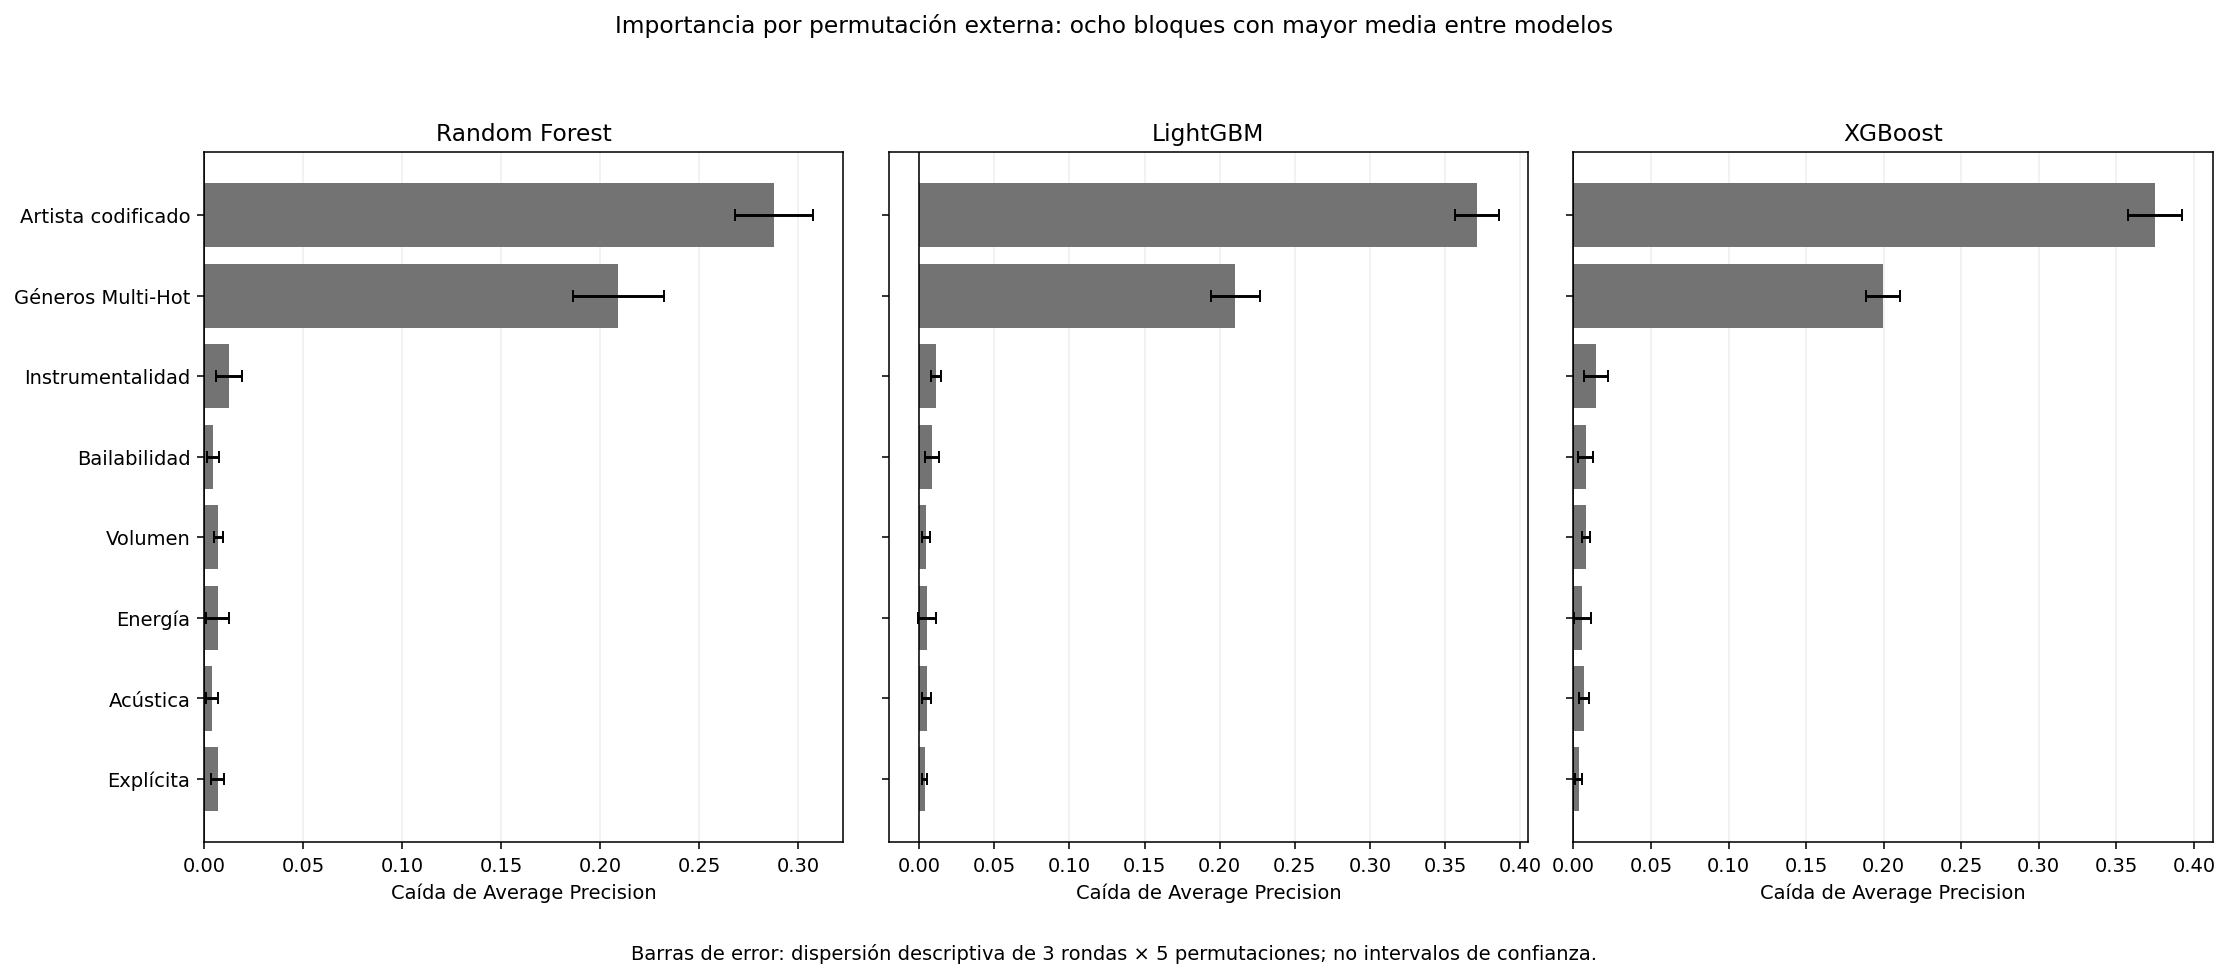

In [39]:
import matplotlib.pyplot as plt

resumen_importancia_ensambles_u3 = importancia_detalle_ensambles_u3.groupby(["Modelo", "Bloque"], as_index=False).agg(
    Caida_AP_media=("Caída AP", "mean"), DE_descriptiva=("Caída AP", "std"),
    Caida_minima=("Caída AP", "min"), Caida_maxima=("Caída AP", "max"), Evaluaciones=("Caída AP", "size"))
resumen_importancia_ensambles_u3 = resumen_importancia_ensambles_u3.sort_values(["Modelo", "Caida_AP_media"], ascending=[True, False])
top_importancias_ensambles_u3 = resumen_importancia_ensambles_u3.groupby("Modelo", sort=False).head(5)
display(top_importancias_ensambles_u3.round(5))

bloques_grafico_u3 = (resumen_importancia_ensambles_u3.groupby("Bloque")["Caida_AP_media"].mean().nlargest(8).index.tolist())
fig_importancia_ensambles_u3, ejes_importancia_u3 = plt.subplots(1, 3, figsize=(16, 7), sharey=True)
for eje, modelo in zip(ejes_importancia_u3, MODELOS_DIAGNOSTICO_U3):
    datos = resumen_importancia_ensambles_u3.loc[resumen_importancia_ensambles_u3["Modelo"].eq(modelo)].set_index("Bloque").loc[bloques_grafico_u3]
    eje.barh(np.arange(len(datos)), datos["Caida_AP_media"], xerr=datos["DE_descriptiva"], color="0.45", capsize=3)
    eje.axvline(0, color="black", linewidth=0.8)
    eje.set_title(modelo)
    eje.set_xlabel("Caída de Average Precision")
    eje.grid(axis="x", alpha=0.2)
    eje.set_axisbelow(True)
ejes_importancia_u3[0].set_yticks(np.arange(len(bloques_grafico_u3)), labels=bloques_grafico_u3)
ejes_importancia_u3[0].invert_yaxis()
fig_importancia_ensambles_u3.suptitle("Importancia por permutación externa: ocho bloques con mayor media entre modelos")
fig_importancia_ensambles_u3.text(0.5, 0.015, "Barras de error: dispersión descriptiva de 3 rondas × 5 permutaciones; no intervalos de confianza.", ha="center", fontsize=10)
fig_importancia_ensambles_u3.tight_layout(rect=[0, 0.05, 1, 0.94])
display(fig_importancia_ensambles_u3)
plt.close(fig_importancia_ensambles_u3)

`import matplotlib.pyplot as plt` carga las herramientas para dibujar. `subplots` crea un panel por modelo; `barh` dibuja las caídas de AP y `xerr` su dispersión descriptiva. La línea en cero ayuda a reconocer importancias pequeñas o negativas. Los ejes muestran los mismos bloques; sus escalas horizontales pueden diferir, por lo que se comparan los valores, no solo la longitud visual.

### Cómo interpretar la tabla y el gráfico

`groupby().agg()` resume quince valores por bloque y modelo: tres rondas por cinco permutaciones. La media es la caída de AP observada; la desviación, mínimo y máximo describen su variación. **Esos quince valores no son quince experimentos independientes**, y sus barras no son intervalos de confianza ni una prueba estadística.

Se muestran las cinco mayores medias por familia. Para el gráfico se eligen ocho bloques con mayor media entre familias únicamente para presentación; no es selección de variables para volver a entrenar. El ranking completo de quince bloques por familia permanece en `resumen_importancia_ensambles_u3`.

Una caída de 0,05 significa restar cinco centésimas de AP a la AP de referencia de esa muestra. No significa perder 5% de accuracy, explicar 5% de popularidad ni que la variable cause un cambio de cinco puntos en una canción. Las importancias no se normalizan para sumar cien.

Artista codificado representa información del catálogo permitido; géneros agrupa 114 indicadores y su importancia es conjunta. Bloques de distinto tamaño y variables correlacionadas requieren interpretación cuidadosa. Una característica redundante puede tener poca importancia individual aun cuando la información compartida sea útil. Alterar un bloque puede generar combinaciones poco realistas; este experimento describe dependencia del modelo, no una intervención musical viable ni causal.

In [40]:
modelo_provisional_u3 = "XGBoost"
metodo_provisional_u3 = "Random"
comparacion_provisional_u3 = resumen_externo_conjunto_u3.loc[
    resumen_externo_conjunto_u3["Método"].eq(METODO_DIAGNOSTICO_U3) &
    resumen_externo_conjunto_u3["Decisión"].eq("Elegido interno"),
    ["Modelo", "Precisión", "Recall", "F1", "Average Precision", "ROC-AUC", "FP", "FN", "KPI simultáneos"],
].copy()
comparacion_provisional_u3["Elección para continuar"] = comparacion_provisional_u3["Modelo"].eq(modelo_provisional_u3)
display(comparacion_provisional_u3.round(6))
print("Elección provisional: XGBoost con artista, procedimiento Random y corte elegido dentro de cada desarrollo.")
print("Prioridad para continuar: recuperar más positivas entre alternativas que cumplen ambas metas; se considera también AP.")
print("La elección es posterior a esta comparación y no constituye otra evaluación independiente ni un modelo final.")

,Modelo,Precisión,Recall,F1,Average Precision,ROC-AUC,FP,FN,KPI simultáneos,Elección para continuar
3,Random Forest,0.503838,0.651317,0.568163,0.590255,0.906953,5042,2741,Cumple,False
7,LightGBM,0.496429,0.663147,0.567803,0.601028,0.910703,5288,2648,Cumple,False
11,XGBoost,0.487494,0.681847,0.568519,0.605341,0.910567,5635,2501,Cumple,True


Elección provisional: XGBoost con artista, procedimiento Random y corte elegido dentro de cada desarrollo.
Prioridad para continuar: recuperar más positivas entre alternativas que cumplen ambas metas; se considera también AP.
La elección es posterior a esta comparación y no constituye otra evaluación independiente ni un modelo final.


### 18.3. Justificación de la elección provisional

Se mantiene **XGBoost con artista, mediante Random**, como procedimiento provisional para continuar la clasificación. Cumplió ambas metas en las tres rondas y obtuvo el mayor recall y AP global entre las tres familias comparadas. Para el objetivo de identificar positivas, recuperar más canciones resulta una prioridad razonable mientras se conserva la precisión mínima. Esta prioridad interpreta el objetivo del proyecto; no se introduce una nueva meta numérica ni se recalcula un corte con respuestas externas.

**F1 no decide por una diferencia mínima:** Random Forest 0,5682, LightGBM 0,5678 y XGBoost 0,5685 son muy cercanos. No hay prueba de superioridad estadística. Random Forest ofrece mayor precisión y menos falsas alarmas, por lo que sería una alternativa si el costo de señalar negativas fuera prioritario. Entre Random Forest y XGBoost, este último recupera 240 positivas adicionales con 593 falsas alarmas adicionales; no se asigna un valor económico inventado a esos errores.

Se conserva Random porque en el espacio probado produjo los mismos parámetros y predicciones que Grid revisando diez configuraciones en lugar de dieciséis para XGBoost. Eso no demuestra que Random siempre encuentre la misma solución ni constituye un benchmark de velocidad entre ejecuciones con distinto paralelismo.

La elección fija de XGBoost **es posterior a observar resultados externos** y por eso sus cifras se presentan como evidencia de desarrollo para una decisión provisional. La regla de selección interna conjunta del bloque 17 es otra evaluación: eligió XGBoost en rondas 1 y 3 y LightGBM en la 2. No se usa esa evaluación para atribuir independencia a esta elección fija posterior.

Las importancias y los subgrupos añaden comprensión y límites, no una nueva confirmación de rendimiento. No se seleccionarán o eliminarán columnas automáticamente a partir de este diagnóstico. El artista puede favorecer modelos apoyados en un catálogo ya conocido; los resultados no garantizan éxito futuro, calidad musical ni buen desempeño sobre artistas nuevos.

Todavía **no existe un modelo final ajustado con todo entrenamiento ni un único corte final de producción**. Los cortes 0,30; 0,30 y 0,25 de XGBoost pertenecen a sus tres desarrollos. No se convierten por mayoría en un umbral global.

El siguiente paso será cerrar los KPI y limitaciones de clasificación y completar la aplicación acotada de Leave-P-Out indicada por la pauta, antes de continuar con la optimización de clustering y los entregables. El test permanece sin consulta en esta unidad.

Referencia: [importancia por permutación, scikit-learn](https://scikit-learn.org/stable/modules/permutation_importance.html). La implementación permuta bloques de columnas preparadas para respetar los indicadores de cada categoría y de géneros.

### Lectura de los diagnósticos ejecutados

**Random Forest:** los tres mayores bloques por caída media de AP fueron Artista codificado: caída AP 0.2877; Géneros Multi-Hot: caída AP 0.2092; Instrumentalidad: caída AP 0.0128. Son dependencias del modelo sobre muestras externas, no porcentajes de causalidad ni un reparto que sume cien.
De sus 5,042 falsas alarmas, 2,083 tenían popularidad 50–<60 (41.31%); de sus 2,741 positivas omitidas, 2,165 estaban en 60–<70 (78.99%). Se usan denominadores distintos para FP y FN. La tabla por bandas permite comparar también tasas y errores alejados del umbral.

**LightGBM:** los tres mayores bloques por caída media de AP fueron Artista codificado: caída AP 0.3714; Géneros Multi-Hot: caída AP 0.2103; Instrumentalidad: caída AP 0.0111. Son dependencias del modelo sobre muestras externas, no porcentajes de causalidad ni un reparto que sume cien.
De sus 5,288 falsas alarmas, 2,339 tenían popularidad 50–<60 (44.23%); de sus 2,648 positivas omitidas, 2,060 estaban en 60–<70 (77.79%). Se usan denominadores distintos para FP y FN. La tabla por bandas permite comparar también tasas y errores alejados del umbral.

**XGBoost:** los tres mayores bloques por caída media de AP fueron Artista codificado: caída AP 0.3749; Géneros Multi-Hot: caída AP 0.1996; Instrumentalidad: caída AP 0.0146. Son dependencias del modelo sobre muestras externas, no porcentajes de causalidad ni un reparto que sume cien.
De sus 5,635 falsas alarmas, 2,484 tenían popularidad 50–<60 (44.08%); de sus 2,501 positivas omitidas, 1,947 estaban en 60–<70 (77.85%). Se usan denominadores distintos para FP y FN. La tabla por bandas permite comparar también tasas y errores alejados del umbral.

**Errores compartidos:** Positivas omitidas por los tres: 2,141; Negativas señaladas por los tres: 4,070. Esto muestra límites comunes, sin evaluar un ensamble nuevo ni demostrar su causa.

Las nueve reproducciones OOF coincidieron con las predicciones guardadas. Los nueve reajustes usaron solo sus desarrollos y las 675 perturbaciones no entrenaron otros modelos. Los KPI del bloque anterior y sus cortes permanecieron fijos.


**Los errores no están todos cerca de 60.** XGBoost también señaló como populares 2,114 canciones con popularidad inferior a 20: representan 37.52% de sus falsas alarmas y 11.50% de las canciones de esa banda. Por eso el límite de clases explica parte de la dificultad, pero no basta para explicar todos los errores. El modelo puede aprender patrones de artistas, géneros y sonido que comparten canciones con popularidades distintas; estas tablas no identifican por sí solas la causa de cada fallo.


**Límite observado con artistas desconocidos.** De 71.728 canciones evaluadas, 6.411 no tenían ningún artista presente en el mapa de su desarrollo. Entre sus 770 positivas, XGBoost detectó 276: recall 35,84%. Cuando había algún artista conocido detectó 5.084 de 7.091 positivas: 71,70%. Random Forest mostró 27,79% frente a 69,19%, y LightGBM 33,25% frente a 69,91%. Todos muestran menor detección en el primer grupo. Estos porcentajes no demuestran causalidad, pero sí limitan la aplicación a artistas nuevos. Las etiquetas de cumplimiento de la tabla de cobertura comparan descriptivamente cada subgrupo con los mismos valores globales de referencia; no son nuevos KPI acordados ni reemplazan el resultado global.

En los tres modelos, artista codificado y géneros registraron las mayores caídas de AP al permutarlos. Instrumentalidad quedó después, con caídas mucho menores. Para XGBoost, por ejemplo, mezclar el artista redujo AP en promedio 0,3749 y mezclar conjuntamente los géneros en 0,1996. Son caídas absolutas de AP, no porcentajes de popularidad explicada. Esta dependencia ayuda a entender por qué hace falta informar resultados de artistas desconocidos junto al promedio general.


## 19. Cierre de KPI y conclusiones de clasificación

### 19.1. Qué estamos cerrando

El objetivo es identificar canciones con **popularidad de 60 o más**. La clase 1 significa que alcanza ese valor; la clase 0, que no lo alcanza. Predecimos una categoría definida sobre este dataset, no el éxito futuro de una canción ni su calidad musical.

Los KPI acordados se mantienen: **precisión ≥ 30% y recall ≥ 60%, simultáneamente**. Precisión responde «de las señaladas como populares, ¿cuántas realmente lo eran?». Recall responde «de todas las populares reales, ¿cuántas recuperamos?». Cumplirlos no significa acertar todas las canciones ni eliminar los errores.

Este cierre reúne las predicciones OOF de la **validación anidada: tres rondas externas y cinco pliegues internos agrupados por canción**. Los cinco pliegues iniciales de la unidad constituyeron otra etapa; no se deben describir estos resultados anidados como cinco rondas externas. Cada ID se evaluó una vez fuera de su desarrollo y sus versiones permanecieron juntas. La codificación de artista, la preparación, los hiperparámetros y el corte se aprendieron dentro del desarrollo correspondiente.

Usamos Random como representante de cada familia porque el bloque anterior comprobó que Grid y Random produjeron los mismos parámetros y predicciones en el espacio probado. Aquí no se entrena, no se busca otro corte y no se consulta test. Es un cierre de evidencia de desarrollo, no la evaluación final independiente.

In [41]:
modelos_cierre_clasificacion_u3 = ["Random Forest", "LightGBM", "XGBoost"]
mascara_cierre_u3 = (
    resumen_externo_conjunto_u3["Método"].eq("Random") &
    resumen_externo_conjunto_u3["Decisión"].eq("Elegido interno") &
    resumen_externo_conjunto_u3["Modelo"].isin(modelos_cierre_clasificacion_u3)
)
comparacion_cierre_clasificacion_u3 = resumen_externo_conjunto_u3.loc[mascara_cierre_u3].copy()
comparacion_cierre_clasificacion_u3 = comparacion_cierre_clasificacion_u3.set_index("Modelo").loc[modelos_cierre_clasificacion_u3].reset_index()
if len(comparacion_cierre_clasificacion_u3) != 3 or comparacion_cierre_clasificacion_u3["Modelo"].duplicated().any():
    raise ValueError("Debe existir exactamente un resultado por ensamble.")
if not comparacion_cierre_clasificacion_u3[["TN", "FP", "FN", "TP"]].sum(axis=1).eq(len(y_train_u3)).all():
    raise ValueError("Los conteos no cubren todo entrenamiento.")
display(comparacion_cierre_clasificacion_u3[["Modelo", "Precisión", "Recall", "F1", "ROC-AUC", "Average Precision", "TP", "FP", "FN", "TN"]].round(6))

Modelo,Precisión,Recall,F1,ROC-AUC,Average Precision,TP,FP,FN,TN
Random Forest,0.503838,0.651317,0.568163,0.906953,0.590255,5120,5042,2741,58825
LightGBM,0.496429,0.663147,0.567803,0.910703,0.601028,5213,5288,2648,58579
XGBoost,0.487494,0.681847,0.568519,0.910567,0.605341,5360,5635,2501,58232


### Cómo se construye e interpreta la comparación

1. La lista fija el orden de las tres familias. La máscara selecciona el procedimiento Random y la decisión con corte aprendido internamente. No escoge un resultado nuevo por rendimiento.
2. `loc[mascara].copy()` recupera las filas guardadas y permite trabajar sobre una copia. `set_index`, `loc` y `reset_index` ordenan la presentación sin alterar las predicciones.
3. Las comprobaciones exigen tres resultados únicos y que TN + FP + FN + TP cubra los 71.728 IDs de entrenamiento por familia. `display` muestra métricas redondeadas; los cálculos conservan su precisión original.
4. TP son populares detectadas; FN, populares omitidas; FP, negativas señaladas por error; TN, negativas descartadas correctamente. Precisión = TP/(TP+FP); recall = TP/(TP+FN); F1 = 2×precisión×recall/(precisión+recall).
5. ROC-AUC describe la capacidad de ordenar positivas por encima de negativas a lo largo de posibles cortes. Average Precision (AP) resume precisión y recuperación al recorrer ese orden, y resulta útil con pocas positivas. Ninguna de las dos equivale a porcentaje de aciertos, probabilidad calibrada ni cumplimiento automático de los KPI.

Las métricas globales se calculan reuniendo todas las predicciones externas: no son un promedio simple de métricas de rondas. Los cortes pueden variar entre desarrollos. F1, AUC y AP ayudan a comparar; no tienen una meta adicional inventada para aprobar.

In [42]:
filas_kpi_cierre_u3 = []
for _, resultado in comparacion_cierre_clasificacion_u3.iterrows():
    precision = resultado["TP"] / (resultado["TP"] + resultado["FP"])
    recall = resultado["TP"] / (resultado["TP"] + resultado["FN"])
    for indicador, meta, valor, formula in [
        ("Precisión", META_PRECISION, precision, "TP / (TP + FP)"),
        ("Recall", META_RECALL, recall, "TP / (TP + FN)"),
    ]:
        filas_kpi_cierre_u3.append({"Modelo": resultado["Modelo"], "KPI": indicador,
            "Meta (%)": meta * 100, "Resultado (%)": valor * 100,
            "Margen (puntos porcentuales)": (valor - meta) * 100,
            "Estado": "Cumple" if valor >= meta else "No cumple", "Cálculo": formula,
            "Evidencia": "OOF externas anidadas; corte elegido internamente"})
tabla_kpi_cierre_clasificacion_u3 = pd.DataFrame(filas_kpi_cierre_u3)
filas_rondas_cierre_u3 = []
for modelo in modelos_cierre_clasificacion_u3:
    for externa in range(1, PLIEGUES_EXTERNOS + 1):
        evidencia = evidencia_conjunta_u3[(externa, modelo, "Random")]
        real = y_train_u3.loc[evidencia["decision"].index]
        decision = evidencia["decision"]
        tp = int((real.eq(1) & decision.eq(1)).sum())
        fp = int((real.eq(0) & decision.eq(1)).sum())
        fn = int((real.eq(1) & decision.eq(0)).sum())
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall = tp / (tp + fn) if tp + fn else np.nan
        filas_rondas_cierre_u3.append({"Modelo": modelo, "Ronda externa": externa,
            "Corte interno": evidencia["corte_info"]["corte"], "IDs": len(real),
            "Precisión (%)": precision * 100, "Recall (%)": recall * 100,
            "Ambos KPI": "Cumple" if precision >= META_PRECISION and recall >= META_RECALL else "No cumple"})
kpi_por_ronda_cierre_u3 = pd.DataFrame(filas_rondas_cierre_u3)
display(tabla_kpi_cierre_clasificacion_u3.round(2))
display(kpi_por_ronda_cierre_u3.round(2))

Modelo,KPI,Meta (%),Resultado (%),Margen (puntos porcentuales),Estado,Cálculo,Evidencia
Random Forest,Precisión,30.0,50.38,20.38,Cumple,TP / (TP + FP),OOF externas anidadas; corte elegido internamente
Random Forest,Recall,60.0,65.13,5.13,Cumple,TP / (TP + FN),OOF externas anidadas; corte elegido internamente
LightGBM,Precisión,30.0,49.64,19.64,Cumple,TP / (TP + FP),OOF externas anidadas; corte elegido internamente
LightGBM,Recall,60.0,66.31,6.31,Cumple,TP / (TP + FN),OOF externas anidadas; corte elegido internamente
XGBoost,Precisión,30.0,48.75,18.75,Cumple,TP / (TP + FP),OOF externas anidadas; corte elegido internamente
XGBoost,Recall,60.0,68.18,8.18,Cumple,TP / (TP + FN),OOF externas anidadas; corte elegido internamente


Modelo,Ronda externa,Corte interno,IDs,Precisión (%),Recall (%),Ambos KPI
Random Forest,1,0.30,24019,48.82,64.53,Cumple
Random Forest,2,0.30,23828,50.92,65.56,Cumple
Random Forest,3,0.30,23881,51.44,65.30,Cumple
LightGBM,1,0.30,24019,48.34,66.35,Cumple
LightGBM,2,0.30,23828,49.16,66.74,Cumple
LightGBM,3,0.30,23881,51.52,65.86,Cumple
XGBoost,1,0.30,24019,48.97,66.11,Cumple
XGBoost,2,0.30,23828,49.29,67.24,Cumple
XGBoost,3,0.25,23881,48.07,71.14,Cumple


### Cómo se calcula el cierre de los KPI

1. `iterrows()` recorre el resultado de cada familia. Se recalculan precisión y recall desde sus conteos para dejar visible el denominador de cada indicador.
2. La lista de dos indicadores conserva las metas acordadas. Multiplicar por cien convierte proporciones en porcentajes. Restar meta a resultado y multiplicar por cien da el margen en **puntos porcentuales**, no la mejora relativa en porcentaje.
3. `valor >= meta` determina cumplimiento usando valores sin redondear. La columna de evidencia deja identificado el origen del resultado.
4. El segundo recorrido recupera cada ronda y su decisión previamente guardada. Alinea las respuestas por ID y cuenta TP, FP y FN con condiciones lógicas. No utiliza las respuestas para cambiar la decisión ni su corte.
5. Se comprueban ambas metas a la vez en cada ronda. Esto complementa el resultado global y evita ocultar una ronda insuficiente detrás del promedio. Cumplir en las tres rondas observadas no garantiza cumplir en toda población futura.

**Resultado:** los tres ensambles cumplen ambas metas globalmente y en sus tres rondas externas con los cortes elegidos dentro del desarrollo. Los cortes son 0,30 en Random Forest y LightGBM; en XGBoost son 0,30; 0,30 y 0,25. No se promedian ni se votan para crear un corte global final.

Con corte fijo 0,50, los tres ensambles optimizados no alcanzaban recall 60%. El cumplimiento corresponde al procedimiento completo con selección interna del corte. No debe atribuirse solo a cambiar los hiperparámetros. La referencia mayoritaria predice todo como negativo: recall 0% y precisión positiva no definida porque no señala ninguna canción; no cumple las metas, aunque su accuracy sea aproximadamente 89%.

In [43]:
cobertura_cierre_clasificacion_u3 = errores_por_cobertura_artista_u3[[
    "Modelo", "Cobertura artista", "IDs", "Positivas reales", "TP", "FN", "Precisión", "Recall"
]].copy()
cobertura_cierre_clasificacion_u3["Precisión (%)"] = cobertura_cierre_clasificacion_u3.pop("Precisión") * 100
cobertura_cierre_clasificacion_u3["Recall (%)"] = cobertura_cierre_clasificacion_u3.pop("Recall") * 100
if not cobertura_cierre_clasificacion_u3.groupby("Modelo")["IDs"].sum().eq(len(y_train_u3)).all():
    raise ValueError("Los subgrupos de cobertura no cubren entrenamiento.")
rf_cierre_u3 = comparacion_cierre_clasificacion_u3.set_index("Modelo").loc["Random Forest"]
xgb_cierre_u3 = comparacion_cierre_clasificacion_u3.set_index("Modelo").loc["XGBoost"]
balance_eleccion_cierre_u3 = pd.DataFrame([{
    "Comparación": "XGBoost respecto a Random Forest",
    "Populares adicionales detectadas": int(xgb_cierre_u3["TP"] - rf_cierre_u3["TP"]),
    "Falsas alarmas adicionales": int(xgb_cierre_u3["FP"] - rf_cierre_u3["FP"]),
}])
display(cobertura_cierre_clasificacion_u3.round(2))
display(balance_eleccion_cierre_u3)

Modelo,Cobertura artista,IDs,Positivas reales,TP,FN,Precisión (%),Recall (%)
Random Forest,Algún artista conocido,65317,7091,4906,2185,49.82,69.19
Random Forest,Ningún artista conocido,6411,770,214,556,67.94,27.79
LightGBM,Algún artista conocido,65317,7091,4957,2134,49.24,69.91
LightGBM,Ningún artista conocido,6411,770,256,514,58.99,33.25
XGBoost,Algún artista conocido,65317,7091,5084,2007,48.34,71.70
XGBoost,Ningún artista conocido,6411,770,276,494,57.86,35.84


Comparación,Populares adicionales detectadas,Falsas alarmas adicionales
XGBoost respecto a Random Forest,240,593


### Qué aporta esta última tabla

`copy()` selecciona resultados de cobertura ya calculados en el bloque 18. `pop` retira cada columna en proporción y devuelve sus valores para mostrarlos como porcentajes. La suma por modelo comprueba que los dos subgrupos cubran entrenamiento. No se vuelve a codificar el artista ni se consulta una respuesta nueva.

La resta de TP y FP cuantifica el intercambio entre XGBoost y Random Forest: **240 populares adicionales detectadas, a cambio de 593 falsas alarmas adicionales** en estas predicciones. No es una comparación económica; falta definir cuánto cuesta cada tipo de error para una aplicación real.

En XGBoost, recall es **71,70% cuando existe algún artista conocido y 35,84% cuando ninguno es conocido** en el desarrollo de esa ronda. Son 5.084 de 7.091 positivas frente a 276 de 770. Random Forest y LightGBM muestran también menor recuperación sin artistas conocidos. Los KPI acordados son globales; esta tabla describe una limitación de cobertura, sin crear nuevos criterios de aprobación por subgrupo ni demostrar su causa.

### 19.2. Elección provisional: XGBoost con artista

**XGBoost con artista y búsqueda Random es la alternativa provisional para continuar.** Entre procedimientos que cumplen precisión ≥ 30% y recall ≥ 60%, ofrece el mayor recall global (68,18%) y AP (0,6053). Detecta 5.360 de las 7.861 populares reales, pero omite 2.501 y genera 5.635 falsas alarmas. Su precisión de 48,75% significa que algo menos de la mitad de las señaladas eran realmente populares; cumplir una meta mínima no convierte ese resultado en ausencia de problemas.

**Random Forest** obtiene mayor precisión (50,38%) y menos falsas alarmas (5.042), pero detecta menos positivas: recall 65,13%. Sería una alternativa razonable si se priorizara reducir falsas alarmas. **LightGBM** queda entre ambos en precisión (49,64%) y recall (66,31%); obtiene un ROC-AUC ligeramente superior, pero esa diferencia pequeña no basta para declararlo superior.

Los F1 son prácticamente iguales: Random Forest 0,5682, LightGBM 0,5678 y XGBoost 0,5685. No elegimos por esas milésimas ni afirmamos superioridad estadística. La prioridad provisional es recuperar más populares manteniendo la precisión mínima; deberá revisarse si cambia el uso esperado o el costo de los errores.

Random conserva la solución de Grid probando diez configuraciones frente a dieciséis de XGBoost en este espacio. No se concluye que Random siempre iguale Grid ni que estas ejecuciones demuestren una ventaja controlada de velocidad.

**El alcance de la elección importa:** hemos observado las evaluaciones externas para decidir conservar una familia fija; sus cifras son evidencia de desarrollo para esa elección posterior, no una confirmación independiente. La regla interna conjunta del bloque 17 seleccionó XGBoost en rondas 1 y 3 y LightGBM en la 2: esa regla y elegir ahora XGBoost fijo son procedimientos distintos.

### 19.3. Conclusiones y limitaciones de clasificación

**Respondemos al objetivo dentro de los datos de entrenamiento:** los tres ensambles permiten identificar una parte importante de las canciones con popularidad ≥ 60 y cumplen las dos metas con cortes elegidos sin usar las respuestas de su evaluación externa. XGBoost recupera más positivas; Random Forest reduce falsas alarmas. Las métricas describen ese intercambio, no un ganador universal.

El análisis de errores limita la interpretación. Los tres modelos omiten conjuntamente 2.141 positivas y señalan erróneamente 4.070 negativas. Parte de los errores está cerca de 60, pero XGBoost también produce 2.114 falsas alarmas entre canciones con popularidad inferior a 20. No basta atribuir toda equivocación al límite de clases. No se eliminan esas canciones para mejorar las métricas.

La permutación indica que **artista codificado y géneros son los bloques de mayor dependencia**, seguidos por instrumentalidad con caídas de AP mucho menores. No son causas de popularidad ni porcentajes de varianza explicada. Se midieron en muestras externas de 5.000 IDs por ronda, con cinco permutaciones; variables correlacionadas, bloques de distinto tamaño y combinaciones artificiales limitan su lectura. Su dispersión es descriptiva, no un intervalo de confianza. Este diagnóstico no se utilizó para eliminar variables o volver a optimizar.

La separación mantiene juntas las versiones identificadas por la clave normalizada de artista y título, reduciendo fuga entre esas versiones. No detecta necesariamente todas las versiones posibles; tampoco separa todos los artistas entre entrenamiento y validación. Por eso no demuestra rendimiento sobre artistas completamente nuevos, y el menor recall observado cuando no se conoce ninguno obliga a ser prudentes. La codificación de artista utiliza solo información permitida y cruzada en el ajuste, pero continúa dependiendo de cobertura del catálogo.

La clase positiva representa cerca del 10,96% de entrenamiento. Accuracy alta por sí sola resulta insuficiente. Popularidad es una medición del catálogo, condicionada por exposición, fecha y otros factores no incluidos; no es calidad musical ni una predicción temporal validada. Los valores producidos por los modelos tampoco se han demostrado como probabilidades calibradas.

Solo hay tres rondas externas y un espacio de búsqueda acotado; la similitud de F1 y las pequeñas diferencias de AUC/AP no prueban diferencias estadísticamente significativas. Las métricas se calculan por ID y por eso canciones con más versiones pueden aportar más observaciones, aunque se mantengan juntas al dividir. La evaluación agrupada reduce un riesgo concreto, sin eliminar todos los sesgos de muestreo y del dataset.

**Estado al cerrar este bloque:** se cierra la comparación y los KPI de clasificación en entrenamiento. No se ha ajustado un único modelo final con todo entrenamiento ni elegido un corte final global. No se consulta test, que además ya fue examinado durante la unidad 2 y no podría presentarse después como una muestra completamente nueva. Queda pendiente la demostración acotada de Leave-P-Out agrupado exigida por la pauta y la optimización de clustering. El cierre no equivale a haber completado toda la unidad 3. Las decisiones y resultados quedan registrados para el informe final.

### 19.4. Curvas de ordenamiento como apoyo al cierre

Se muestran ROC y precisión-recall de las mismas probabilidades OOF externas ya evaluadas, sin ajustar modelos o cortes nuevos. No se utiliza test. Las curvas complementan los valores AUC/AP del cierre, sin convertir la selección posterior de XGBoost en una nueva prueba independiente.


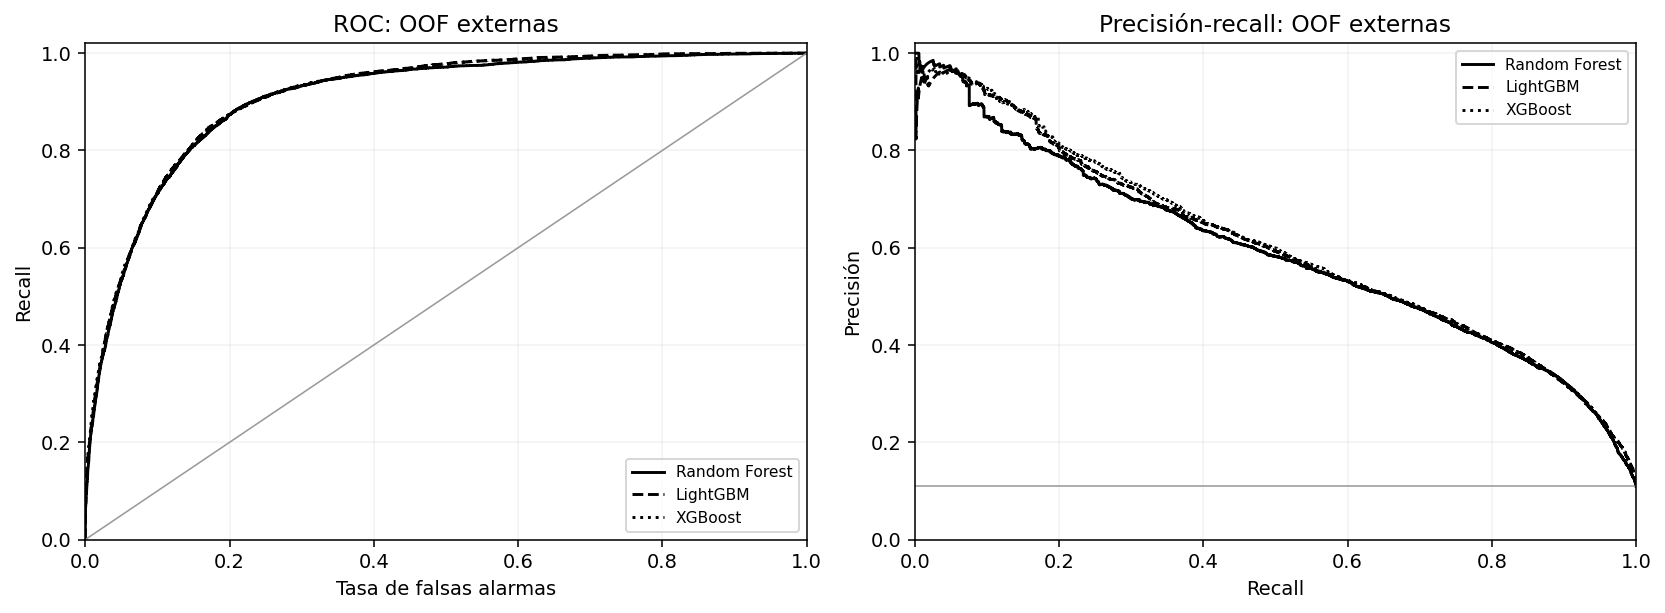

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

fig_curvas_cierre_u3, ejes_curvas_cierre_u3 = plt.subplots(1, 2, figsize=(12, 4.5))
for modelo, estilo in [("Random Forest", "-"), ("LightGBM", "--"), ("XGBoost", ":")]:
    proba = probas_conjuntas_por_pareja_u3[(modelo, "Random")]
    if not proba.index.equals(y_train_u3.index):
        raise ValueError("Las probabilidades y respuestas no están alineadas.")
    fpr, tpr, _ = roc_curve(y_train_u3, proba)
    precision, recall, _ = precision_recall_curve(y_train_u3, proba)
    ejes_curvas_cierre_u3[0].plot(fpr, tpr, linestyle=estilo, color="black", label=modelo)
    ejes_curvas_cierre_u3[1].plot(recall, precision, linestyle=estilo, color="black", label=modelo)
ejes_curvas_cierre_u3[0].plot([0, 1], [0, 1], color="0.6", linewidth=0.8)
ejes_curvas_cierre_u3[1].axhline(y_train_u3.mean(), color="0.6", linewidth=0.8)
ejes_curvas_cierre_u3[0].set(title="ROC: OOF externas", xlabel="Tasa de falsas alarmas", ylabel="Recall")
ejes_curvas_cierre_u3[1].set(title="Precisión-recall: OOF externas", xlabel="Recall", ylabel="Precisión")
for eje in ejes_curvas_cierre_u3:
    eje.set_xlim(0, 1)
    eje.set_ylim(0, 1.02)
    eje.legend(fontsize=8)
    eje.grid(alpha=0.15)
fig_curvas_cierre_u3.tight_layout()
display(fig_curvas_cierre_u3)
plt.close(fig_curvas_cierre_u3)

`roc_curve` recorre las puntuaciones y relaciona falsas alarmas con recall. `precision_recall_curve` relaciona precisión y recall a distintos cortes; no elige uno. Los trazos usan las mismas filas y estilos distintos por familia. La diagonal es referencia de ordenamiento sin discriminación y la horizontal PR indica prevalencia, no un KPI nuevo. `plot`, ejes y leyendas solo presentan estas relaciones.

Las áreas ya calculadas se mantienen: AUC no es accuracy, AP no es una probabilidad de éxito ni cualquier integral trapezoidal de PR. Las puntuaciones proceden de modelos distintos por ronda externa; las curvas globales describen su evaluación reunida, no calibración de un clasificador de producción. La cercanía visual de los trazos no demuestra igualdad o superioridad estadística.


<a id="validacion-lpo"></a>
## 20. Comparación acotada: Leave-P-Out agrupado y cinco pliegues agrupados

### 20.1. Pregunta y alcance

¿Cómo cambia la evaluación si dejamos fuera todas las parejas posibles de grupos en vez de dividirlos en cinco pliegues? Realizaremos una **demostración de funcionamiento y costo**, usando únicamente una muestra pequeña de entrenamiento. No se reabre la selección del modelo ni se sustituye la validación anidada del bloque 17.

El grupo es la clave normalizada de artista y título usada para mantener juntas las versiones. Un grupo puede contener varios IDs. Por eso usamos **`LeavePGroupsOut(n_groups=2)`**, equivalente a dejar fuera dos grupos completos: no `LeavePOut(p=2)`, que dejaría dos filas y podría separar versiones. La cantidad de registros evaluados puede variar porque cada grupo tiene distinto tamaño.

Fijamos diez grupos: cinco de clase 0 y cinco de clase 1; en cada clase, dos grupos con dos o tres IDs y tres grupos con un ID. Se conservan **todos** los IDs de cada grupo elegido. Para controlar tamaño y garantizar ambas clases en cada ajuste, se excluyen de esta demostración los grupos con clases mezcladas y los de más de tres IDs. Esta selección intencional cambia la distribución: no representa la prevalencia del catálogo ni los casos difíciles excluidos.

Se mantiene XGBoost inicial **con artista**, con su configuración original sin optimizar, y corte fijo 0,50. No se utilizan los ganadores ni los cortes del cierre para buscar mejores resultados en la muestra. La imputación, las categorías y el mapa cruzado de artista se vuelven a aprender dentro de cada ajuste. La elección previa de XGBoost y el uso de entrenamiento ya estudiado hacen que esto sea una demostración posterior, no una validación independiente.

In [45]:
from math import comb
from sklearn.model_selection import LeavePGroupsOut, StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score
from sklearn.base import clone
from time import perf_counter

P_GRUPOS_LPO_U3 = 2
CORTE_DEMO_LPO_U3 = 0.50
resumen_grupos_demo_u3 = pd.DataFrame({"Grupo": claves_train_u3, "Clase": y_train_u3}).groupby("Grupo")["Clase"].agg(IDs="size", Clase_min="min", Clase_max="max")
rng_demo_lpo_u3 = np.random.default_rng(SEMILLA)
claves_demo_lpo_u3 = []
for clase in [0, 1]:
    homogeneos = resumen_grupos_demo_u3.loc[
        resumen_grupos_demo_u3["Clase_min"].eq(clase) & resumen_grupos_demo_u3["Clase_max"].eq(clase)
    ]
    for minimo, maximo, cantidad in [(2, 3, 2), (1, 1, 3)]:
        candidatas = homogeneos.index[homogeneos["IDs"].between(minimo, maximo)].sort_values()
        if len(candidatas) < cantidad:
            raise ValueError("No hay suficientes grupos para el diseño fijado.")
        claves_demo_lpo_u3.extend(rng_demo_lpo_u3.choice(candidatas.to_numpy(), size=cantidad, replace=False).tolist())
mascara_demo_lpo_u3 = claves_train_u3.isin(claves_demo_lpo_u3)
X_demo_lpo_u3 = X_train_con_artista_u3.loc[mascara_demo_lpo_u3].copy()
y_demo_lpo_u3 = y_train_u3.loc[X_demo_lpo_u3.index]
g_demo_lpo_u3 = claves_train_u3.loc[X_demo_lpo_u3.index]
if len(X_demo_lpo_u3.index.intersection(ids_test_u2)) or g_demo_lpo_u3.nunique() != 10:
    raise ValueError("Muestra inválida o con IDs de test.")
for grupo in claves_demo_lpo_u3:
    if set(X_demo_lpo_u3.index[g_demo_lpo_u3.eq(grupo)]) != set(claves_train_u3.index[claves_train_u3.eq(grupo)]):
        raise ValueError("Se han separado versiones al seleccionar la muestra.")
tabla_muestra_lpo_u3 = resumen_grupos_demo_u3.loc[claves_demo_lpo_u3].reset_index()
display(tabla_muestra_lpo_u3)
print(f"Muestra: {len(X_demo_lpo_u3)} IDs, 10 grupos, {int(y_demo_lpo_u3.sum())} positivas; proporción positiva {y_demo_lpo_u3.mean():.2%}.")
print(f"Entrenamiento completo: {len(y_train_u3)} IDs, {claves_train_u3.nunique()} grupos; proporción positiva {y_train_u3.mean():.2%}.")

Grupo,IDs,Clase_min,Clase_max
billo's || cumbia caletera,3,0,0
sarcastic sounds;claire rosinkranz;clinton kane || change ur mind,2,0,0
teqkoi || it'll be alright,1,0,0
jon sarta || in peace,1,0,0
joshua radin || paperweight by joshua radin and schuyler fisk,1,0,0
bring me the horizon || teardrops,2,1,1
ashe || moral of the story,2,1,1
xxxtentacion || triumph,1,1,1
rilès || pesetas,1,1,1
sanja göransson || sömn,1,1,1


Muestra: 15 IDs, 10 grupos, 7 positivas; proporción positiva 46.67%.
Entrenamiento completo: 71728 IDs, 64965 grupos; proporción positiva 10.96%.


### Lectura de la selección, línea por línea

Los imports cargan los divisores, métricas, clonación, combinaciones y reloj. Se fija `P=2` en grupos y el corte 0,50 antes de ejecutar. La tabla por grupo cuenta IDs y compara clases mínima y máxima; si coinciden, todas sus versiones tienen la misma clase. Ese filtro se usa solo para esta demostración, sin borrar datos del proyecto.

`default_rng(SEMILLA)` hace reproducible el sorteo. Los dos recorridos eligen las cantidades acordadas por clase y tamaño; `sort_values` fija el orden de candidatas y `replace=False` evita repetir grupos. No se escogen grupos por el resultado que produzca el modelo.

`isin` selecciona todas las filas de las claves elegidas. `loc` alinea características, respuesta y grupos por ID. Las comprobaciones exigen diez claves, ningún ID de test y todas las versiones de cada clave seleccionada. La tabla deja visibles sus IDs y clases; el porcentaje final permite ver cuánto difiere la muestra del entrenamiento completo. No se balancea la base principal: se diseña una muestra didáctica.

In [46]:
divisores_demo_lpo_u3 = {
    "Cinco pliegues agrupados": StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA),
    "Leave-2-grupos-out": LeavePGroupsOut(n_groups=P_GRUPOS_LPO_U3),
}
particiones_demo_lpo_u3 = {}
filas_plan_demo_u3 = []
for nombre, divisor in divisores_demo_lpo_u3.items():
    particiones = list(divisor.split(X_demo_lpo_u3, y_demo_lpo_u3, g_demo_lpo_u3))
    particiones_demo_lpo_u3[nombre] = particiones
    for ronda, (ajuste, validacion) in enumerate(particiones, start=1):
        grupos_ajuste = set(g_demo_lpo_u3.iloc[ajuste])
        grupos_val = set(g_demo_lpo_u3.iloc[validacion])
        if grupos_ajuste.intersection(grupos_val) or len(np.intersect1d(ajuste, validacion)):
            raise ValueError("Hay grupos o IDs compartidos dentro de una ronda.")
        if y_demo_lpo_u3.iloc[ajuste].nunique() != 2:
            raise ValueError("El ajuste debe contener ambas clases.")
        filas_plan_demo_u3.append({"Método": nombre, "Ronda": ronda,
            "IDs ajuste": len(ajuste), "IDs validación": len(validacion),
            "Grupos ajuste": len(grupos_ajuste), "Grupos validación": len(grupos_val),
            "Positivas validación": int(y_demo_lpo_u3.iloc[validacion].sum()),
            "Clases validación": y_demo_lpo_u3.iloc[validacion].nunique(), "Grupos compartidos": 0})
plan_rondas_demo_lpo_u3 = pd.DataFrame(filas_plan_demo_u3)
assert len(particiones_demo_lpo_u3["Leave-2-grupos-out"]) == comb(10, 2) == 45
assert len(particiones_demo_lpo_u3["Cinco pliegues agrupados"]) == 5
display(plan_rondas_demo_lpo_u3)
print(f"Leave-2-grupos-out en todos los grupos de entrenamiento exigiría {comb(claves_train_u3.nunique(), 2):,} ajustes para UNA configuración, antes de otras búsquedas.")

Método,Ronda,IDs ajuste,IDs validación,Grupos ajuste,Grupos validación,Positivas validación,Clases validación,Grupos compartidos
Cinco pliegues agrupados,1,12,3,8,2,0,1,0
Cinco pliegues agrupados,2,13,2,8,2,1,2,0
Cinco pliegues agrupados,3,11,4,8,2,1,2,0
Cinco pliegues agrupados,4,13,2,8,2,1,2,0
Cinco pliegues agrupados,5,11,4,8,2,4,1,0
Leave-2-grupos-out,1,10,5,8,2,2,2,0
Leave-2-grupos-out,2,11,4,8,2,4,1,0
Leave-2-grupos-out,3,12,3,8,2,2,2,0
Leave-2-grupos-out,4,12,3,8,2,2,2,0
Leave-2-grupos-out,5,12,3,8,2,3,1,0


Leave-2-grupos-out en todos los grupos de entrenamiento exigiría 2,110,193,130 ajustes para UNA configuración, antes de otras búsquedas.


### Qué significa cada ronda

El diccionario contiene dos reglas y `split` genera sus posiciones de ajuste y validación. Se materializan las divisiones solo porque la demostración es pequeña; no se generan todas las combinaciones del entrenamiento completo.

`iloc` recupera los grupos por posición. Su intersección debe estar vacía, y el ajuste debe contener ambas clases. Los conteos muestran cuántos registros quedan fuera realmente: **dos grupos no significan dos registros**. `StratifiedGroupKFold` intenta aproximar proporciones de clases sin separar grupos, pero no garantiza dos grupos ni ambas clases en cada validación. Leave-2-grupos-out deja exactamente dos grupos fuera y explora todas sus parejas, incluyendo parejas de la misma clase.

Diez grupos tomados de dos en dos producen `comb(10,2) = 45` rondas; cinco pliegues producen cinco. No se configura «45 repeticiones aleatorias»: son todas las combinaciones del diseño. Las validaciones de Leave-P-Out se solapan entre rondas y cada grupo aparece nueve veces fuera. En ambos métodos se exige separación dentro de cada ronda, no separación entre rondas distintas.

In [47]:
def metricas_demo_lpo_u3(real, proba, corte):
    pred = np.asarray(proba) >= corte
    tn, fp, fn, tp = confusion_matrix(real, pred, labels=[0, 1]).ravel()
    dos_clases = pd.Series(np.asarray(real)).nunique() == 2
    return {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Precisión": tp / (tp + fp) if tp + fp else np.nan,
        "Recall": tp / (tp + fn) if tp + fn else np.nan,
        "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan,
        "ROC-AUC": roc_auc_score(real, proba) if dos_clases else np.nan,
        "AP": average_precision_score(real, proba) if dos_clases else np.nan}

filas_resultados_demo_u3 = []
filas_predicciones_demo_u3 = []
for nombre, particiones in particiones_demo_lpo_u3.items():
    for ronda, (ajuste, validacion) in enumerate(particiones, start=1):
        flujo = clone(flujo_xgb_con_artista_u3)
        inicio = perf_counter()
        flujo.fit(X_demo_lpo_u3.iloc[ajuste], y_demo_lpo_u3.iloc[ajuste])
        codificador = flujo.named_steps["artista"]
        if set(codificador.ids_ajuste_) != set(X_demo_lpo_u3.index[ajuste]) or codificador.claves_ajuste_.intersection(set(g_demo_lpo_u3.iloc[validacion])):
            raise ValueError("El mapa de artista utilizó la validación.")
        columna_positiva = int(np.flatnonzero(flujo.named_steps["modelo"].classes_ == 1)[0])
        proba = flujo.predict_proba(X_demo_lpo_u3.iloc[validacion])[:, columna_positiva]
        segundos = perf_counter() - inicio
        real = y_demo_lpo_u3.iloc[validacion]
        filas_resultados_demo_u3.append({"Método": nombre, "Ronda": ronda,
            "Segundos fit y predicción": segundos, **metricas_demo_lpo_u3(real, proba, CORTE_DEMO_LPO_U3)})
        filas_predicciones_demo_u3.append(pd.DataFrame({"Método": nombre, "Ronda": ronda,
            "ID": real.index, "Grupo": g_demo_lpo_u3.iloc[validacion].to_numpy(),
            "Real": real.to_numpy(), "Puntuación": proba}))
    print(f"Completado: {nombre}, {len(particiones)} ajustes.", flush=True)
resultados_rondas_demo_lpo_u3 = pd.DataFrame(filas_resultados_demo_u3)
predicciones_demo_lpo_u3 = pd.concat(filas_predicciones_demo_u3, ignore_index=True)
display(resultados_rondas_demo_lpo_u3.round(4))

Método,Ronda,Segundos fit y predicción,TN,FP,FN,TP,Precisión,Recall,F1,ROC-AUC,AP
Cinco pliegues agrupados,1,0.1147,2,1,0,0,0.0000,NaN,0.0000,NaN,NaN
Cinco pliegues agrupados,2,0.0264,1,0,1,0,NaN,0.0000,0.0000,0.5,0.5000
Cinco pliegues agrupados,3,0.0273,3,0,0,1,1.0000,1.0000,1.0000,1.0,1.0000
Cinco pliegues agrupados,4,0.0253,0,1,1,0,0.0000,0.0000,0.0000,0.0,0.5000
Cinco pliegues agrupados,5,0.0294,0,0,4,0,NaN,0.0000,0.0000,NaN,NaN
Leave-2-grupos-out,1,0.0271,3,0,2,0,NaN,0.0000,0.0000,1.0,1.0000
Leave-2-grupos-out,2,0.0254,0,0,4,0,NaN,0.0000,0.0000,NaN,NaN
Leave-2-grupos-out,3,0.0267,1,0,0,2,1.0000,1.0000,1.0000,1.0,1.0000
Leave-2-grupos-out,4,0.0255,0,1,0,2,0.6667,1.0000,0.8000,0.5,0.6667
Leave-2-grupos-out,5,0.0255,0,0,3,0,NaN,0.0000,0.0000,NaN,NaN


Completado: Cinco pliegues agrupados, 5 ajustes.
Completado: Leave-2-grupos-out, 45 ajustes.


### Cómo se ejecuta y cómo tratar métricas no definidas

La función calcula la decisión con el corte fijado y obtiene TN, FP, FN y TP en el mismo orden siempre. Las divisiones se realizan solo cuando existe denominador. Precisión es NaN si no se señala ninguna positiva; recall es NaN si no hay positivas reales. AUC necesita ambas clases. Para evitar interpretar una AP trivial de una sola clase como buen resultado, aquí también se informa NaN en esas rondas. No se imputan ceros ni se ocultan esas rondas.

Cada `clone` crea un Pipeline nuevo con la configuración inicial. `fit` recibe exclusivamente el ajuste; dentro de él se aprenden la codificación cruzada de artista, imputación y categorías. Se verifica el origen del mapa antes de predecir. La validación se usa para calcular métricas, nunca como `eval_set`, para ajustar el corte o para buscar otros parámetros.

El reloj registra ajuste y predicción, incluyendo preparación; no incluye todo el tiempo de las tablas o selección. Los segundos dependen del equipo, ejecución y orden de métodos: no constituyen un benchmark controlado. Se guardan probabilidades por ID **y ronda**, porque un mismo ID de Leave-P-Out tiene varias predicciones de modelos distintos. No se usa `cross_val_predict`, que requiere una única aparición de cada observación en validación para su esquema habitual.

In [48]:
filas_resumen_demo_u3 = []
for nombre in divisores_demo_lpo_u3:
    pred = predicciones_demo_lpo_u3.loc[predicciones_demo_lpo_u3["Método"].eq(nombre)]
    rondas = resultados_rondas_demo_lpo_u3.loc[resultados_rondas_demo_lpo_u3["Método"].eq(nombre)]
    plan = plan_rondas_demo_lpo_u3.loc[plan_rondas_demo_lpo_u3["Método"].eq(nombre)]
    visitas = pred.groupby("ID").size().reindex(X_demo_lpo_u3.index, fill_value=0)
    esperado = 9 if nombre == "Leave-2-grupos-out" else 1
    if not visitas.eq(esperado).all():
        raise ValueError("Cobertura inesperada de IDs en validación.")
    filas_resumen_demo_u3.append({"Método": nombre, "Ajustes": len(rondas), "IDs únicos": pred["ID"].nunique(),
        "Evaluaciones ID-ronda": len(pred), "Visitas por ID": esperado,
        "IDs validación mínimo": int(plan["IDs validación"].min()), "IDs validación máximo": int(plan["IDs validación"].max()),
        "Rondas AUC/AP definidas": int(rondas["ROC-AUC"].notna().sum()),
        "AUC media rondas válidas": rondas["ROC-AUC"].mean(), "AP media rondas válidas": rondas["AP"].mean(),
        "Segundos acumulados": rondas["Segundos fit y predicción"].sum(),
        **metricas_demo_lpo_u3(pred["Real"], pred["Puntuación"], CORTE_DEMO_LPO_U3)})
resumen_demo_lpo_u3 = pd.DataFrame(filas_resumen_demo_u3)
display(resumen_demo_lpo_u3.round(4))
parametros_modelo_demo_lpo_u3 = pd.DataFrame([{
    k: flujo_xgb_con_artista_u3.named_steps["modelo"].get_params()[k]
    for k in ["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "min_child_weight", "random_state"]
}])
display(parametros_modelo_demo_lpo_u3)
print("No se modifica XGBoost provisional, su configuración optimizada ni sus cortes.")

Método,Ajustes,IDs únicos,Evaluaciones ID-ronda,Visitas por ID,IDs validación mínimo,IDs validación máximo,Rondas AUC/AP definidas,AUC media rondas válidas,AP media rondas válidas,Segundos acumulados,TN,FP,FN,TP,Precisión,Recall,F1,ROC-AUC,AP
Cinco pliegues agrupados,5,15,15,1,2,4,3,0.50,0.6667,0.2231,6,2,6,1,0.3333,0.1429,0.2000,0.3036,0.5085
Leave-2-grupos-out,45,15,135,9,2,5,25,0.46,0.6727,1.2141,37,35,39,24,0.4068,0.3810,0.3934,0.4190,0.4427


n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,random_state
100,3,0.1,1.0,1.0,1,42


No se modifica XGBoost provisional, su configuración optimizada ni sus cortes.


### Cómo interpretar la comparación sin exagerarla

`groupby("ID").size()` comprueba cuántas evaluaciones recibió cada ID: una con cinco pliegues y nueve con Leave-2-grupos-out. Todos conservan el mismo peso relativo **dentro de cada método**, pero las evaluaciones repetidas no son canciones nuevas ni nueve pruebas independientes.

La precisión, recall, F1, AUC y AP de la tabla resumen se calculan sobre **eventos ID-ronda reunidos**, conservando cada predicción. En Leave-P-Out son evaluaciones repetidas del mismo catálogo mínimo, no OOF de aparición única. No se promedian probabilidades por ID para fingir otro modelo. Las AUC/AP reunidas mezclan puntuaciones de ajustes distintos; deben leerse como descripción de esos eventos, no como rendimiento de un clasificador final.

Las columnas de medias de AUC/AP usan solo rondas donde existen ambas clases y muestran cuántas fueron válidas. No tienen el mismo significado que las métricas reunidas y no son directamente comparables si los métodos tienen distintas composiciones de validación. No se eliminan las otras rondas del registro. La dispersión entre rondas no proporciona un intervalo de confianza: se comparten registros y desarrollos.

No se aplican estos números al cierre de KPI del bloque 19: muestra, prevalencia, tamaño de ajuste, configuración y corte difieren. Este ensayo tampoco decide cuál técnica «da mejor modelo». Con tan pocos ejemplos, métricas altas o bajas pueden cambiar mucho por una o dos canciones, y XGBoost puede aprender muy poco.

### 20.2. Decisión metodológica y limitaciones

**Conservamos cinco pliegues agrupados como protocolo interno de las búsquedas principales**, dentro de las tres rondas externas ya utilizadas. El fundamento es preservar versiones, disponer de validaciones suficientemente grandes y mantener un costo viable, no elegir el divisor que dé mayor puntuación en este ensayo.

Leave-P-Out agrupado se implementó realmente y muestra cómo dejar un número configurable de grupos fuera. Con diez grupos y P=2 resulta abordable: 45 ajustes, frente a cinco. En la base completa, el número de parejas crece de forma combinatoria; multiplicarlo por configuraciones, rondas externas y modelos vuelve inviable esta aplicación exhaustiva. No se ejecuta ese costo completo.

El experimento usa cinco grupos homogéneos por clase y un máximo de tres IDs por grupo. Eso facilita mostrar el procedimiento, pero excluye grupos mixtos y grandes, altera prevalencia y no mide generalización sobre las 71.728 canciones. Incluso dejando dos grupos fuera, la cantidad de registros varía; configurar P no fija exactamente la cantidad de filas. Si se exigiera una cantidad aproximada de registros o un número fijo de rondas sobre toda la base, sería otro diseño, como divisiones agrupadas aleatorias, y no se llamaría Leave-P-Out exhaustivo.

La codificación interna del artista utiliza subgrupos de los datos de ajuste; no añade consultas a las respuestas de validación. Algunos subajustes tan pequeños pueden tener poca variedad y mapas poco informativos. No se introduce balanceo, ajuste de umbral, búsqueda de parámetros ni un nuevo modelo final.

El resultado complementa la explicación exigida por la pauta y mantiene la elección provisional de XGBoost basada en la evidencia principal, con sus limitaciones. No se usa test ni se presenta este ensayo como confirmación independiente. La siguiente fase pendiente es la optimización de clustering con su propio protocolo y métricas.

Referencia de implementación: [LeavePGroupsOut, documentación de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.LeavePGroupsOut.html).

### 20.3. Lectura de los resultados ejecutados



Se seleccionaron **15 IDs en diez grupos**, con 46.67% de positivas frente a 10.96% en entrenamiento. Esta diferencia impide trasladar precisión o AP directamente al catálogo.

**Cinco pliegues agrupados:** 5 ajustes; entre 2 y 4 IDs fuera por ronda; 15 eventos de evaluación de 15 IDs únicos. En eventos reunidos: precisión 0.3333, recall 0.1429, F1 0.2000, AUC 0.3036 y AP 0.5085. AUC/AP por ronda estuvieron definidas en 3 de 5 rondas. Los conteos reunidos fueron TP=1, FP=2, FN=6, TN=6; en Leave-P-Out esos conteos incluyen repeticiones de cada ID.

**Leave-2-grupos-out:** 45 ajustes; entre 2 y 5 IDs fuera por ronda; 135 eventos de evaluación de 15 IDs únicos. En eventos reunidos: precisión 0.4068, recall 0.3810, F1 0.3934, AUC 0.4190 y AP 0.4427. AUC/AP por ronda estuvieron definidas en 25 de 45 rondas. Los conteos reunidos fueron TP=24, FP=35, FN=39, TN=37; en Leave-P-Out esos conteos incluyen repeticiones de cada ID.

Leave-P-Out necesitó nueve veces más ajustes para esta configuración. Sus diferencias de puntuación describen este diseño mínimo; no demuestran que generalice mejor ni peor. Ningún resultado sustituye los KPI principales ni se utiliza para cambiar parámetros o cortes.

**Lectura simple de estas cifras:** con cinco pliegues se detectó 1 de las 7 positivas de la muestra y se señalaron 2 negativas por error: recall 14,29% y precisión 33,33%. Con Leave-2-grupos-out hubo 24 detecciones en 63 eventos de positivas y 35 falsas alarmas: recall 38,10% y precisión 40,68%. Esos 63 eventos son las mismas siete positivas evaluadas nueve veces, no 63 canciones distintas. No son resultados comparables al recall 68,18% del XGBoost optimizado sobre entrenamiento completo.

La AUC reunida fue 0,3036 con cinco pliegues y 0,4190 con Leave-P-Out: en estos eventos mínimos, el ordenamiento fue peor que la referencia 0,50. En cambio, la AP reunida fue mayor con cinco pliegues (0,5085 frente a 0,4427), aunque su recall al corte fijo fuera menor. No es una contradicción: las métricas de ordenamiento y la decisión a un corte responden preguntas distintas, y aquí también se mezclan puntuaciones de ajustes minúsculos. No se concluye que un método sea superior a partir de esas cifras.

AUC/AP por ronda solo pudieron interpretarse en 3 de 5 rondas y en 25 de 45, respectivamente; las demás tenían una sola clase. La muestra intencional tiene 46,67% de positivas y los ajustes contienen muy pocos ejemplos: las métricas son inestables y no permiten juzgar el desempeño real de XGBoost ni rechazar cinco pliegues. Se elige el protocolo principal por su diseño y viabilidad, manteniendo el cierre anterior sin modificaciones.


<a id="agrupamiento"></a>
## 21. Modelos no supervisados: objetivo y protocolo de agrupamiento

### 21.1. Objetivo para playlists

Buscamos **agrupar canciones con características de audio similares para apoyar la exploración y creación de playlists**. Compararemos K-Means, que asigna todas las canciones a un número de grupos fijado, con DBSCAN, que identifica zonas densas y puede marcar canciones como ruido. No existe una etiqueta de grupo correcta que debamos predecir.

La unidad 2 dejó K-Means con siete grupos como referencia y mostró limitaciones de DBSCAN. En esta unidad examinaremos sus parámetros y estabilidad bajo un protocolo común. **K=7 es referencia, no ganador impuesto**; incluiremos K=9 para revisar la alternativa del proyecto original. K=2 no entra en la búsqueda por la necesidad previamente definida de disponer de mayor variedad para playlists, no porque sea matemáticamente inválido.

La clasificación anterior respondió si popularidad alcanza 60. Aquí no utilizaremos esa clase, popularidad ni artista para formar grupos o escoger parámetros. Un grupo musical no significa una categoría de éxito. Estas agrupaciones tampoco constituyen todavía un sistema personalizado de recomendación: faltan preferencias, contexto y evaluación con oyentes.

Este bloque define decisiones y verifica las entradas disponibles. **Todavía no ajusta imputación, escalamiento, K-Means o DBSCAN ni declara KPI cumplidos.** Todo se restringe a los IDs de entrenamiento recuperados de la unidad 2.

In [49]:
import numpy as np
import pandas as pd

variables_clustering_u3 = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo",
]
X_clustering_train_u3 = datos_entrenamiento_u3.loc[:, variables_clustering_u3].copy()
if not X_clustering_train_u3.index.is_unique or not X_clustering_train_u3.index.equals(y_train_u3.index):
    raise ValueError("Los IDs no coinciden con entrenamiento o están repetidos.")
if len(X_clustering_train_u3.index.intersection(ids_test_u2)):
    raise ValueError("Hay IDs reservados para test.")
if X_clustering_train_u3.select_dtypes(include="number").shape[1] != 9:
    raise ValueError("Las nueve características deben ser numéricas.")
if np.isinf(X_clustering_train_u3.to_numpy(dtype=float)).any():
    raise ValueError("Hay infinitos: investigar antes de preparar.")
revision_entradas_clustering_u3 = pd.DataFrame({
    "Tipo": X_clustering_train_u3.dtypes.astype(str),
    "Faltantes": X_clustering_train_u3.isna().sum(),
    "Valores observados distintos": X_clustering_train_u3.nunique(),
})
if not revision_entradas_clustering_u3["Valores observados distintos"].gt(1).all():
    raise ValueError("Hay una variable vacía o constante.")
display(revision_entradas_clustering_u3)
print(f"Base disponible: {len(X_clustering_train_u3):,} IDs de entrenamiento y nueve características musicales; cero IDs de test.")

,Tipo,Faltantes,Valores observados distintos
danceability,float64,0,1138
energy,float64,0,2002
loudness,float64,0,18129
speechiness,float64,0,1457
acousticness,float64,0,4935
instrumentalness,float64,0,5286
liveness,float64,0,1705
valence,float64,0,1769
tempo,float64,136,39322


Base disponible: 71,728 IDs de entrenamiento y nueve características musicales; cero IDs de test.


### Explicación de las entradas y sus controles

`import` carga las herramientas numéricas y tablas. La lista fija exactamente las nueve variables de audio utilizadas en la unidad 2. `loc[:, lista]` selecciona esas columnas y `copy()` crea una copia: no modifica la base preparada ni el CSV.

`index.is_unique` evita contar dos veces un mismo ID; `index.equals` confirma que se conserva entrenamiento. Se usa el índice de `y_train_u3` solo como control de pertenencia, no sus clases para agrupar. La intersección con los IDs reservados debe estar vacía; no se leen sus características para este bloque.

`select_dtypes` comprueba que las nueve columnas son numéricas. `isinf` detecta infinitos; `isna().sum()` cuenta faltantes por columna. Son controles distintos: un faltante no equivale a infinito. `nunique()` cuenta valores presentes diferentes; una variable constante o vacía requiere revisión antes de medir distancias.

La tabla informa la base **antes** de preparar. Encontrar faltantes no implica borrarlos ni reemplazarlos por cero. En el próximo paso se aprenderá la mediana y después la estandarización únicamente del conjunto de ajuste de clustering.

| Variable | Lectura simple y motivo |
|---|---|
| danceability | Indicador de bailabilidad; ayuda a distinguir perfiles rítmicos. |
| energy | Intensidad percibida; distingue perfiles más suaves o intensos. |
| loudness | Volumen en dB; complementa energía, aunque pueden estar correlacionados. |
| speechiness | Presencia estimada de voz hablada; puede separar contenido hablado. |
| acousticness | Indicador de carácter acústico. |
| instrumentalness | Indicador de ausencia de voz; ayuda a identificar perfiles instrumentales. |
| liveness | Indicios de interpretación en vivo; no confirma por sí solo una grabación en concierto. |
| valence | Indicador de carácter musical más positivo; no mide la emoción de cada oyente. |
| tempo | Pulsaciones por minuto; describe velocidad musical aproximada. |

Son descriptores estimados, no juicios de calidad. Excluimos duración para conservar el espacio de nueve variables de la unidad 2; eso limita distinguir canciones largas. Géneros Multi-Hot se reservan para describir perfiles después, evitando que 114 indicadores dominen esta primera comparación. También se excluyen popularidad, clase objetivo, artista codificado, IDs, título y clave de canción de las distancias.

**Resultado de la revisión:** se conservaron los 71.728 IDs de entrenamiento y las nueve columnas numéricas, sin infinitos, columnas vacías ni constantes. Ocho variables no presentan faltantes; tempo tiene 136 (aproximadamente 0,19% de entrenamiento). Esto identifica qué deberá resolver la imputación posterior; todavía no se han reemplazado esos valores ni calculado distancias. Los valores distintos indican variedad observada, no cantidad de grupos ni una medida de calidad del modelo.


In [50]:
plan_optimizacion_clustering_u3 = pd.DataFrame([
    {"Modelo": "K-Means", "Parámetros por revisar": "K=3 a 10; referencia K=7, alternativa K=9",
     "Preparación prevista": "Mediana + StandardScaler; distancia euclídea",
     "Repeticiones previstas": "n_init=10; semillas 42, 43 y 44",
     "Selección": "Separación, tamaños, estabilidad y perfiles; codo como apoyo", "Estado": "Pendiente"},
    {"Modelo": "DBSCAN", "Parámetros por revisar": "min_samples=5, 10 y 20; eps según distancias a vecinos",
     "Preparación prevista": "La misma matriz estandarizada; distancia euclídea",
     "Repeticiones previstas": "Tres submuestras agrupadas de 80% de claves",
     "Selección": "Separación junto con cobertura, ruido, tamaños y estabilidad", "Estado": "Pendiente"},
])
criterios_clustering_u3 = pd.DataFrame([
    ["Entradas", "Solo nueve variables de audio, solo entrenamiento", "Control obligatorio", "Comprobado en este bloque"],
    ["Preparación", "Sin NaN o infinitos después de preparar; mismas columnas y escala", "Control obligatorio", "Pendiente"],
    ["Silhouette", "Más alto suele indicar mejor separación; revisar valores negativos", "Comparativo, sin meta universal", "Pendiente"],
    ["Davies–Bouldin", "Más bajo suele indicar grupos más compactos y separados", "Comparativo, sin meta universal", "Pendiente"],
    ["Inercia y codo", "Apoyo para elegir K, no comparar contra DBSCAN", "Solo K-Means", "Pendiente"],
    ["Tamaños", "Conteos, proporciones, grupo mayor y grupos muy pequeños", "Describir utilidad; sin umbral de aprobación inventado", "Pendiente"],
    ["Cobertura y ruido", "Fracción asignada a grupos; ruido -1 en DBSCAN", "Informar siempre junto a métricas internas", "Pendiente"],
    ["Estabilidad", "ARI sobre IDs comunes; informar cobertura de esa comparación", "Comparativo, sin meta universal", "Pendiente"],
    ["Interpretación", "Perfiles musicales y canciones representativas sin repetir versiones", "Necesario para justificar utilidad; no prueba de satisfacción", "Pendiente"],
], columns=["Criterio", "Qué revisaremos", "Tipo de decisión", "Estado"])
display(plan_optimizacion_clustering_u3)
display(criterios_clustering_u3)

,Modelo,Parámetros por revisar,Preparación prevista,Repeticiones previstas,Selección,Estado
0,K-Means,"K=3 a 10; referencia K=7, alternativa K=9",Mediana + StandardScaler; distancia euclídea,"n_init=10; semillas 42, 43 y 44","Separación, tamaños, estabilidad y perfiles; codo como apoyo",Pendiente
1,DBSCAN,"min_samples=5, 10 y 20; eps según distancias a vecinos",La misma matriz estandarizada; distancia euclídea,Tres submuestras agrupadas de 80% de claves,"Separación junto con cobertura, ruido, tamaños y estabilidad",Pendiente


,Criterio,Qué revisaremos,Tipo de decisión,Estado
0,Entradas,"Solo nueve variables de audio, solo entrenamiento",Control obligatorio,Comprobado en este bloque
1,Preparación,Sin NaN o infinitos después de preparar; mismas columnas y escala,Control obligatorio,Pendiente
2,Silhouette,Más alto suele indicar mejor separación; revisar valores negativos,"Comparativo, sin meta universal",Pendiente
3,Davies–Bouldin,Más bajo suele indicar grupos más compactos y separados,"Comparativo, sin meta universal",Pendiente
4,Inercia y codo,"Apoyo para elegir K, no comparar contra DBSCAN",Solo K-Means,Pendiente
5,Tamaños,"Conteos, proporciones, grupo mayor y grupos muy pequeños",Describir utilidad; sin umbral de aprobación inventado,Pendiente
6,Cobertura y ruido,Fracción asignada a grupos; ruido -1 en DBSCAN,Informar siempre junto a métricas internas,Pendiente
7,Estabilidad,ARI sobre IDs comunes; informar cobertura de esa comparación,"Comparativo, sin meta universal",Pendiente
8,Interpretación,Perfiles musicales y canciones representativas sin repetir versiones,Necesario para justificar utilidad; no prueba de satisfacción,Pendiente


### 21.2. Cómo interpretaremos las métricas

El código crea dos tablas de planificación; las cadenas de texto no ejecutan modelos. `Estado = Pendiente` evita confundir criterios futuros con resultados ya obtenidos. No se trasladan precisión, recall, F1 o ROC-AUC a clustering: no contamos con etiquetas correctas de grupo. Tampoco se reutilizan los KPI de clasificación como metas de playlists.

**Silhouette** compara la distancia de una canción a su grupo con su distancia a otros grupos. Va de −1 a 1: valores mayores sugieren mejor separación; cerca de cero, fronteras difusas; negativos, asignaciones discutibles. No existe un mínimo universal que garantice buenas playlists.

**Davies–Bouldin** compara dispersión interna con separación entre centros. Menor es preferible en ese espacio de variables; no es porcentaje ni «accuracy». Favorece ciertas geometrías y puede describir peor grupos de formas irregulares de DBSCAN. No elegiremos por este índice aislado.

Ambas métricas se registrarán como no definidas si no hay entre dos y N−1 grupos en los registros evaluados. Se vigilarán grupos diminutos y variables sin dispersión; una salida numérica no garantiza utilidad.

**DBSCAN:** el ruido tiene etiqueta −1 y no es un género ni un grupo musical. Silhouette y Davies–Bouldin se calcularán entre registros asignados a grupos, excluyendo ruido; junto a cada cifra se informarán población evaluada y cobertura. Un resultado alto agrupando muy pocas canciones no supera automáticamente a K-Means. Las métricas habituales describirán poblaciones distintas; como complemento, se recalcularán ambos modelos sobre los mismos IDs no ruido de DBSCAN cuando existan suficientes grupos válidos. Si no, se indicará por qué no se puede comparar.

**Inercia y codo:** K-Means suma distancias cuadradas a sus centros. La inercia tiende a bajar al aumentar K; buscar una inflexión ayuda a identificar rendimientos decrecientes, pero no demuestra un K correcto. DBSCAN no comparte ese objetivo: no compararemos sus resultados mediante inercia.

**ARI (índice Rand ajustado)** compara dos asignaciones sin exigir que sus números de grupo coincidan. Un valor 1 indica coincidencia; cerca de 0, concordancia comparable a la referencia por azar; puede ser negativo. No compara contra una verdad musical ni equivale a acierto predictivo. No se usará V de Cramér como criterio principal para elegir grupos: asociarse con un género no demuestra separación musical ni utilidad para playlists.

### 21.3. Protocolo de preparación, búsqueda y estabilidad

1. **Preparación común:** imputar por mediana y aplicar `StandardScaler` a las nueve columnas. Así tempo o volumen no dominan solo por sus unidades. Estandarizar no elimina atípicos ni correlaciones ni garantiza grupos naturales. Ambos modelos recibirán exactamente la misma matriz y orden de IDs.
2. **Costo y población de búsqueda:** comenzar con una muestra reproducible de hasta 10.000 IDs de entrenamiento, obtenida seleccionando claves completas, sin mirar popularidad o resultados. Si un grupo rebasa el cupo no se cortará: se documentará el tamaño finalmente alcanzado y los excluidos. Se aprenderá la preparación en esa muestra para esta fase, no se reutilizará el escalador de clasificación ni uno de test. No se confundirán sus métricas con las de toda la base.
3. **K-Means:** revisar K de 3 a 10, con `n_init=10` y semillas 42, 43 y 44. `n_init` son diez inicializaciones dentro de cada ajuste, no diez pliegues. Comparar codo, separación, perfiles, tamaños y ARI entre semillas sobre la misma muestra. Mantener presentes K=7 y K=9, sin reutilizar números históricos como si fueran obtenidos con esta muestra.
4. **DBSCAN:** para `min_samples` 5, 10 y 20, examinar las distancias al vecino correspondiente en la matriz estandarizada y definir una lista acotada de `eps` a partir de esa evidencia. `eps` es radio, no número de grupos; `min_samples` cuenta también el propio punto. No fijaremos ahora radios sin conocer la escala. No se materializará una matriz completa de distancias de toda la base; se vigilarán memoria y vecindarios muy densos.
5. **Métricas costosas:** silhouette utilizará hasta 2.000 IDs de un panel reproducible común, sin seleccionar por popularidad o por obtener mejor resultado. En DBSCAN se excluirá el ruido de ese panel y se informará cuántos IDs y grupos quedan; no se cambiará la muestra hasta obtener una cifra favorable. Davies–Bouldin, tamaños y cobertura usarán todos los registros asignados de la muestra de búsqueda cuando proceda. Se documentará el conjunto que interviene en cada métrica.
6. **Estabilidad de densidad:** cambiar la semilla de DBSCAN no prueba estabilidad porque no tiene inicialización aleatoria. Con los parámetros candidatos fijos, se reajustará sobre tres submuestras reproducibles de 80% de claves de la muestra, conservando sus versiones. Para aislar la perturbación de densidad se mantendrá la preparación de referencia de esa muestra. ARI se calculará sobre IDs comunes asignados a grupos en ambos ajustes; se informarán su número, cobertura y cambios a/desde ruido. Excluir ruido puede ocultar inestabilidad si no se muestra ese contexto. No será validación independiente ni evaluación del Pipeline completo bajo nuevo muestreo.
7. **Confirmación a escala:** tras comparar candidatos en la muestra, intentar ajustar los elegidos sobre todo entrenamiento, aprendiendo allí su preparación común y recalculando controles y perfiles. La densidad cambia con el tamaño: no se garantiza que los parámetros de DBSCAN se trasladen igual. Si memoria o costo impiden esa fase, se explicitará que el resultado queda limitado a la muestra. No se consultará test para corregir decisiones.
8. **Elección razonada:** revisar conjuntamente separación, cobertura, estabilidad y utilidad de perfiles. Puede haber conflictos y puede concluirse que DBSCAN no resulta útil para esta propuesta. No se inventará una función de puntuación que mezcle números incompatibles ni se elegirá por el mejor índice aislado.

Este es un análisis exploratorio de estructura en entrenamiento, no una validación cruzada supervisada. `GridSearchCV` con accuracy no corresponde aquí. Reajustar DBSCAN en una supuesta validación y puntuar sus nuevos grupos no demostraría capacidad de asignar canciones futuras al modelo ya ajustado. K-Means permite asignar nuevos registros a centros fijos con `predict`; DBSCAN de scikit-learn no ofrece ese mecanismo directamente.

Las versiones quedan juntas al seleccionar muestras o submuestras. Dentro de un ajuste, conservar sus distintos IDs puede aumentar el peso de una canción o la densidad local; no se presenta como ausencia total de sesgo. La estabilidad entre semillas de K-Means y entre submuestras de DBSCAN son pruebas distintas, no números equivalentes de robustez. La evaluación con oyentes y las preferencias personales quedan fuera del alcance actual.

### Estado y siguiente paso

Quedan definidos el objetivo, las nueve variables y los criterios; no hay grupos nuevos ni ganadores de esta fase. Las metas numéricas de clasificación no aplican aquí y los criterios comparativos todavía no se han cumplido ni incumplido.

El siguiente paso será construir y comprobar la muestra agrupada de entrenamiento, imputar y estandarizar sus nueve características, conservando sus IDs. Después se podrá optimizar K-Means y establecer los radios candidatos de DBSCAN. Popularidad y géneros podrán ayudar a describir los grupos al final, pero no determinarán los parámetros ni se usarán como una respuesta correcta.

Referencia metodológica: [agrupamiento y métricas, documentación de scikit-learn](https://scikit-learn.org/stable/modules/clustering.html).

## 22. Muestra agrupada, imputación y escalamiento para clustering

### 22.1. Qué aprenderemos y con qué datos

Prepararemos una única matriz común para comparar K-Means y DBSCAN en la fase de búsqueda. Partimos de las nueve columnas de audio de los 71.728 IDs de entrenamiento; no usamos popularidad, clase o artista para seleccionar la muestra ni para calcular distancias.

El límite de 10.000 registros controla el costo de los vecindarios de DBSCAN y las métricas de distancias. No es una cantidad estadísticamente óptima ni garantiza representatividad. Sortearemos **claves completas** con semilla 42. Cada clave seleccionada aporta todos sus IDs; si un grupo no cabe en el espacio restante, lo omitimos y seguimos con el siguiente. Este límite puede desfavorecer grupos grandes al final: se documenta como limitación, no como muestreo uniforme de canciones o filas.

La clave normalizada de artista y título se utiliza solo como metadato para conservar versiones juntas. Dos IDs diferentes de una clave no se borran: son observaciones distintas de la base preparada. Esta selección no modifica entrenamiento, la partición de la unidad 2 ni los CSV.

In [51]:
LIMITE_MUESTRA_CLUSTER_U3 = 10_000
SEMILLA_MUESTRA_CLUSTER_U3 = 42
claves_audio_train_u3 = claves_train_u3.loc[X_clustering_train_u3.index]
tamanos_claves_audio_u3 = claves_audio_train_u3.groupby(claves_audio_train_u3, sort=True).size()
rng_muestra_cluster_u3 = np.random.default_rng(SEMILLA_MUESTRA_CLUSTER_U3)
orden_claves_cluster_u3 = rng_muestra_cluster_u3.permutation(tamanos_claves_audio_u3.index.to_numpy())
claves_muestra_cluster_u3 = []
ids_acumulados_cluster_u3 = 0
for clave in orden_claves_cluster_u3:
    cantidad = int(tamanos_claves_audio_u3.loc[clave])
    if ids_acumulados_cluster_u3 + cantidad <= LIMITE_MUESTRA_CLUSTER_U3:
        claves_muestra_cluster_u3.append(clave)
        ids_acumulados_cluster_u3 += cantidad
    if ids_acumulados_cluster_u3 == LIMITE_MUESTRA_CLUSTER_U3:
        break
mascara_muestra_cluster_u3 = claves_audio_train_u3.isin(claves_muestra_cluster_u3)
X_muestra_cluster_u3 = X_clustering_train_u3.loc[mascara_muestra_cluster_u3].copy()
g_muestra_cluster_u3 = claves_audio_train_u3.loc[X_muestra_cluster_u3.index].copy()
conteos_muestra_cluster_u3 = g_muestra_cluster_u3.groupby(g_muestra_cluster_u3).size()
if not conteos_muestra_cluster_u3.equals(tamanos_claves_audio_u3.loc[conteos_muestra_cluster_u3.index]):
    raise ValueError("La selección cortó alguna clave: faltan versiones.")
if not X_muestra_cluster_u3.index.is_unique or len(X_muestra_cluster_u3) != ids_acumulados_cluster_u3:
    raise ValueError("IDs repetidos o tamaño inconsistente.")
if len(X_muestra_cluster_u3.index.intersection(ids_test_u2)):
    raise ValueError("La muestra incluye IDs de test.")
if not 0 < len(X_muestra_cluster_u3) <= LIMITE_MUESTRA_CLUSTER_U3:
    raise ValueError("La muestra está vacía o excede el límite.")
resumen_muestra_cluster_u3 = pd.DataFrame([
    {"Conjunto": "Entrenamiento disponible", "IDs": len(X_clustering_train_u3), "Claves": len(tamanos_claves_audio_u3),
     "Claves con varias versiones": int(tamanos_claves_audio_u3.gt(1).sum()), "IDs de claves con varias versiones": int(tamanos_claves_audio_u3.loc[tamanos_claves_audio_u3.gt(1)].sum())},
    {"Conjunto": "Muestra de búsqueda", "IDs": len(X_muestra_cluster_u3), "Claves": g_muestra_cluster_u3.nunique(),
     "Claves con varias versiones": int(conteos_muestra_cluster_u3.gt(1).sum()), "IDs de claves con varias versiones": int(conteos_muestra_cluster_u3.loc[conteos_muestra_cluster_u3.gt(1)].sum())},
])
display(resumen_muestra_cluster_u3)
print(f"Muestra: {len(X_muestra_cluster_u3) / len(X_clustering_train_u3):.2%} de los IDs de entrenamiento; espacio sin ocupar: {LIMITE_MUESTRA_CLUSTER_U3 - len(X_muestra_cluster_u3)}.")

,Conjunto,IDs,Claves,Claves con varias versiones,IDs de claves con varias versiones
0,Entrenamiento disponible,71728,64965,3777,10540
1,Muestra de búsqueda,10000,9030,530,1500


Muestra: 13.94% de los IDs de entrenamiento; espacio sin ocupar: 0.


### Explicación de la selección

1. Las dos constantes fijan el cupo de registros y la semilla. La semilla hace repetible el orden, sin garantizar representatividad.
2. `loc` alinea las claves con el índice de audio. `groupby(...).size()` cuenta cuántos IDs tiene cada clave; `sort=True` fija el orden de partida antes del sorteo.
3. `default_rng` crea un generador local y `permutation` mezcla las claves sin repetirlas. No mira clases, popularidad ni resultados de modelos.
4. La lista guarda claves completas y el acumulador cuenta sus registros. El `for` examina una clave cada vez; el `if` solo la admite si cabe completa. `break` termina al llenar el cupo. Si no se llena exactamente, la muestra menor sigue siendo válida.
5. `isin` selecciona todos los IDs de esas claves. El orden final conserva el de entrenamiento: el sorteo define pertenencia, no necesita reordenar las filas para los modelos. `copy()` permite trabajar sin modificar la base.
6. Recontar IDs por clave y compararlos con entrenamiento comprueba que no falte ninguna versión. Los otros controles verifican IDs únicos, cupo y ausencia de test.
7. La tabla separa **número de claves** de **número de IDs**. «IDs de claves con varias versiones» incluye todas las versiones de esas claves, no solo las adicionales. La fracción de muestra se refiere a registros, no a artistas o grupos musicales.

Se muestrean unidades agrupadas con un cupo en filas. No corresponde interpretar las filas como una muestra aleatoria simple ni las versiones como observaciones independientes. Al mantenerlas, una canción con más versiones puede influir más en la densidad y los centros; no se ha corregido ese peso.

In [52]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

preparador_clustering_u3 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalamiento", StandardScaler()),
])
matriz_preparada_cluster_u3 = preparador_clustering_u3.fit_transform(X_muestra_cluster_u3)
X_muestra_cluster_escalada_u3 = pd.DataFrame(
    matriz_preparada_cluster_u3, index=X_muestra_cluster_u3.index, columns=variables_clustering_u3,
)
imputador_cluster_u3 = preparador_clustering_u3.named_steps["imputacion"]
escalador_cluster_u3 = preparador_clustering_u3.named_steps["escalamiento"]
X_muestra_cluster_imputada_u3 = pd.DataFrame(
    imputador_cluster_u3.transform(X_muestra_cluster_u3),
    index=X_muestra_cluster_u3.index, columns=variables_clustering_u3,
)
revision_imputacion_cluster_u3 = pd.DataFrame({
    "Faltantes antes": X_muestra_cluster_u3.isna().sum(),
    "Mediana de la muestra": imputador_cluster_u3.statistics_,
    "Valores reemplazados": X_muestra_cluster_u3.isna().sum(),
    "Faltantes después": X_muestra_cluster_imputada_u3.isna().sum(),
}, index=variables_clustering_u3)
revision_escalamiento_cluster_u3 = pd.DataFrame({
    "Media antes": X_muestra_cluster_imputada_u3.mean(),
    "DE antes (ddof=0)": X_muestra_cluster_imputada_u3.std(ddof=0),
    "Media después": X_muestra_cluster_escalada_u3.mean(),
    "DE después (ddof=0)": X_muestra_cluster_escalada_u3.std(ddof=0),
    "Mínimo después": X_muestra_cluster_escalada_u3.min(),
    "Máximo después": X_muestra_cluster_escalada_u3.max(),
})
display(revision_imputacion_cluster_u3.round(6))
display(revision_escalamiento_cluster_u3.round(6))

,Faltantes antes,Mediana de la muestra,Valores reemplazados,Faltantes después
danceability,0,0.578000,0,0
energy,0,0.669000,0,0
loudness,0,-7.223000,0,0
speechiness,0,0.048900,0,0
acousticness,0,0.186000,0,0
instrumentalness,0,0.000052,0,0
liveness,0,0.132000,0,0
valence,0,0.454000,0,0
tempo,16,122.017500,16,0


,Media antes,DE antes (ddof=0),Media después,DE después (ddof=0),Mínimo después,Máximo después
danceability,0.561675,0.177359,0.0,1.0,-3.166891,2.347362
energy,0.632296,0.255335,0.0,1.0,-2.476259,1.436169
loudness,-8.512098,5.169097,-0.0,1.0,-7.366644,2.007333
speechiness,0.086879,0.110181,0.0,1.0,-0.788518,7.969820
acousticness,0.329882,0.338453,-0.0,1.0,-0.974676,1.968129
instrumentalness,0.174742,0.325232,-0.0,1.0,-0.537284,2.537446
liveness,0.215331,0.191446,-0.0,1.0,-1.063126,4.062088
valence,0.466765,0.262449,0.0,1.0,-1.778496,2.012715
tempo,122.088594,29.810975,0.0,1.0,-2.614326,3.083945


### Explicación de imputación y escalamiento

1. Los imports cargan el reemplazo de faltantes, el escalador y el encadenamiento de operaciones. `Pipeline` garantiza el orden: primero mediana, luego estandarización.
2. `SimpleImputer(strategy="median")` aprende un valor central por columna con los datos observados de la muestra. Solo rellena faltantes; no convierte los demás valores en medianas. Se elige mediana porque es menos sensible a extremos que la media; aun así, reemplazar faltantes reduce variación y no recupera el tempo verdadero.
3. `StandardScaler()` aprende media y desviación de las columnas ya imputadas. Transforma cada valor mediante **z = (valor − media de la muestra) / desviación de la muestra**, con `ddof=0`.
4. `fit_transform(X_muestra_cluster_u3)` aprende y aplica ambas operaciones exclusivamente sobre la muestra. No recibe respuestas ni datos de test. En esta búsqueda exploratoria la preparación pertenece a esa misma muestra: no es evidencia de generalización independiente.
5. `DataFrame` restaura nombres e IDs en el arreglo transformado. Esa será la **misma matriz** para K-Means y DBSCAN; no se preparará una escala diferente para favorecer un modelo.
6. `named_steps` recupera los objetos ya ajustados. `transform` del imputador permite mostrar los valores antes del escalamiento **sin volver a aprender** medianas.
7. La tabla de imputación muestra faltantes, mediana aprendida, cantidad reemplazada y faltantes restantes. La mediana se aprende para todas las columnas aunque no necesiten reemplazos. No debe confundirse la mediana de esta muestra con la del entrenamiento completo.
8. La tabla de escalamiento compara medias y desviaciones antes y después. `std(ddof=0)` usa la misma definición que el escalador. Tras transformar esperamos media aproximadamente cero y desviación uno para cada columna no constante; residuos numéricos diminutos son normales.

Un valor escalado de 2 significa dos desviaciones por encima de la media de esa variable en la muestra, no un valor musical «bueno». Un valor negativo significa estar por debajo de esa media, no necesariamente un error. Los valores no quedan limitados a [0,1] ni a [−1,1]. Un extremo puede seguir siendo extremo: no se recortan atípicos ni se eliminan canciones para mejorar las métricas.

Escalar evita que las unidades de tempo o volumen determinen por sí solas las distancias. No elimina correlaciones como energía-volumen ni garantiza que todas las variables aporten igual información musical.

In [53]:
if not X_muestra_cluster_imputada_u3.index.equals(X_muestra_cluster_u3.index) or not X_muestra_cluster_escalada_u3.index.equals(X_muestra_cluster_u3.index):
    raise ValueError("Cambió el orden o la identidad de las filas.")
if X_muestra_cluster_escalada_u3.columns.tolist() != variables_clustering_u3 or X_muestra_cluster_escalada_u3.shape != X_muestra_cluster_u3.shape:
    raise ValueError("Cambió la estructura de características.")
if not np.isfinite(X_muestra_cluster_escalada_u3.to_numpy()).all():
    raise ValueError("La matriz preparada tiene faltantes o infinitos.")
if not X_muestra_cluster_imputada_u3.std(ddof=0).gt(0).all():
    raise ValueError("Hay una columna constante en la muestra.")
observados_muestra_cluster_u3 = X_muestra_cluster_u3.notna().to_numpy()
np.testing.assert_allclose(
    X_muestra_cluster_imputada_u3.to_numpy()[observados_muestra_cluster_u3],
    X_muestra_cluster_u3.to_numpy()[observados_muestra_cluster_u3], rtol=0, atol=0,
)
for variable in variables_clustering_u3:
    faltaban = X_muestra_cluster_u3[variable].isna()
    mediana = revision_imputacion_cluster_u3.loc[variable, "Mediana de la muestra"]
    if not X_muestra_cluster_imputada_u3.loc[faltaban, variable].eq(mediana).all():
        raise ValueError("La imputación no coincide con la mediana aprendida.")
np.testing.assert_allclose(X_muestra_cluster_escalada_u3.mean(), 0, atol=1e-10)
np.testing.assert_allclose(X_muestra_cluster_escalada_u3.std(ddof=0), 1, atol=1e-10)
np.testing.assert_allclose(
    escalador_cluster_u3.inverse_transform(X_muestra_cluster_escalada_u3),
    X_muestra_cluster_imputada_u3.to_numpy(), rtol=1e-10, atol=1e-10,
)
if int(escalador_cluster_u3.n_samples_seen_) != len(X_muestra_cluster_u3):
    raise ValueError("El escalador aprendió con una cantidad inesperada de registros.")
controles_preparacion_cluster_u3 = pd.DataFrame([
    ["Versiones completas", True], ["IDs únicos y orden conservado", True],
    ["Nueve columnas conservadas", True], ["Sin faltantes ni infinitos", True],
    ["Observados intactos al imputar", True], ["Medias cero y DE uno", True],
    ["Escalamiento reversible hasta datos imputados", True], ["Solo muestra de entrenamiento, sin test", True],
], columns=["Control verificado", "Cumple"])
display(controles_preparacion_cluster_u3)
print("Preparación comprobada: aún no se ajustaron K-Means ni DBSCAN.")

,Control verificado,Cumple
0,Versiones completas,True
1,IDs únicos y orden conservado,True
2,Nueve columnas conservadas,True
3,Sin faltantes ni infinitos,True
4,Observados intactos al imputar,True
5,Medias cero y DE uno,True
6,Escalamiento reversible hasta datos imputados,True
7,"Solo muestra de entrenamiento, sin test",True


Preparación comprobada: aún no se ajustaron K-Means ni DBSCAN.


### Explicación de las comprobaciones

Se comparan índices, columnas y forma para evitar que una transformación cambie el registro al que pertenece cada resultado. `isfinite` exige valores presentes y finitos. La desviación positiva descarta columnas constantes en la muestra, algo que no garantizaba el control sobre toda la base.

La máscara `notna()` localiza los valores originalmente observados. `assert_allclose` con tolerancia cero verifica que la imputación no los alteró; el recorrido por columnas comprueba que cada faltante recibió la mediana correspondiente. Las otras tolerancias permiten únicamente pequeños residuos de cálculo al verificar medias, desviaciones e inversión del escalamiento.

`inverse_transform` recupera las unidades originales **después de imputar**, no el valor desconocido de los faltantes. `n_samples_seen_` registra cuántas filas usó el escalador. Los controles se muestran como verdaderos únicamente después de que las comprobaciones anteriores pasan; si alguna falla, la ejecución se detiene.

La matriz está lista para medir distancias y ajustar candidatos. No hay grupos calculados, silhouette, Davies–Bouldin ni evidencia de utilidad para playlists todavía.

### Uso posterior y límites

La búsqueda de ambos modelos usará `X_muestra_cluster_escalada_u3`. Para interpretar perfiles en unidades musicales se conservará `X_muestra_cluster_imputada_u3`, junto con los IDs y `g_muestra_cluster_u3` como metadatos. No se agrega la clave a las nueve columnas.

Las submuestras de estabilidad conservarán grupos completos y emplearán esta preparación fija para aislar cambios de densidad; no se describirá ese ensayo como evaluación independiente del Pipeline. Cuando se intente confirmar los candidatos en todo entrenamiento, se creará un preparador nuevo y se volverán a calcular perfiles y métricas con esa población. No se reutilizarán las cifras de esta muestra como si correspondieran a toda la base.

**Siguiente paso:** probar los K previstos en K-Means, comparar codo, separación, tamaños y estabilidad; después analizar distancias a vecinos para acotar `eps` de DBSCAN. Los datos de test y los resultados de clasificación no intervienen en esas decisiones.

**Resultados ejecutados:** la muestra contiene 10,000 IDs en 9,030 claves completas. Conserva 530 claves con varias versiones. Se reemplazaron 16 valores faltantes; la mediana de tempo aprendida fue 122.017500 BPM. Después de preparar no quedan faltantes ni infinitos, y las nueve columnas tienen media aproximadamente cero y desviación uno. Esto verifica preparación numérica, no calidad del agrupamiento.


## 23. K-Means: comparación de K=3 a K=10

### 23.1. Experimento común y significado de estabilidad

Usaremos exclusivamente las **10.000 filas y nueve columnas ya preparadas** del bloque 22. No volvemos a aprender medianas o escalas, no usamos popularidad o artista y no consultamos test. Cada ajuste recibe todos los IDs de la muestra, de modo que no se separan sus versiones en subconjuntos de ajuste.

Probaremos ocho valores de K con semillas 42, 43 y 44: **24 ajustes**, cada uno con `n_init=10`. Eso implica hasta 240 inicializaciones, no 240 modelos evaluados por separado, ni pliegues de validación cruzada. Cada ajuste conserva la solución de menor inercia de sus diez inicializaciones.

Silhouette se calculará sobre el mismo panel agrupado de hasta 2.000 registros. Inercia, Davies–Bouldin, tamaños y ARI utilizarán la muestra completa de 10.000 IDs. Cambiar la semilla permite estudiar sensibilidad a inicialización manteniendo fijos datos y escala; no mide estabilidad frente a nuevas canciones o una población futura.

K=7 y K=9 son referencias de interés, pero no se impone un ganador. No buscaremos K=2 por el alcance de variedad para playlists ya definido, no porque sea inválido para K-Means.

In [54]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, pairwise_distances
from itertools import combinations
from threadpoolctl import threadpool_limits
from time import perf_counter

KS_BUSQUEDA_CLUSTER_U3 = list(range(3, 11))
SEMILLAS_KMEANS_U3 = [42, 43, 44]
LIMITE_PANEL_SIL_U3 = 2_000
if not X_muestra_cluster_escalada_u3.index.equals(g_muestra_cluster_u3.index):
    raise ValueError("Grupos y matriz no están alineados.")
if not X_muestra_cluster_escalada_u3.columns.tolist() == variables_clustering_u3:
    raise ValueError("Cambió el espacio de características.")
if not np.isfinite(X_muestra_cluster_escalada_u3.to_numpy()).all():
    raise ValueError("La matriz preparada contiene faltantes o infinitos.")
tamanos_panel_sil_u3 = g_muestra_cluster_u3.groupby(g_muestra_cluster_u3, sort=True).size()
orden_panel_sil_u3 = np.random.default_rng(4242).permutation(tamanos_panel_sil_u3.index.to_numpy())
claves_panel_sil_u3 = []
filas_panel_sil_u3 = 0
for clave in orden_panel_sil_u3:
    cantidad = int(tamanos_panel_sil_u3.loc[clave])
    if filas_panel_sil_u3 + cantidad <= LIMITE_PANEL_SIL_U3:
        claves_panel_sil_u3.append(clave)
        filas_panel_sil_u3 += cantidad
    if filas_panel_sil_u3 == LIMITE_PANEL_SIL_U3:
        break
mascara_panel_sil_u3 = g_muestra_cluster_u3.isin(claves_panel_sil_u3)
ids_panel_sil_cluster_u3 = X_muestra_cluster_escalada_u3.index[mascara_panel_sil_u3]
X_panel_sil_cluster_u3 = X_muestra_cluster_escalada_u3.loc[ids_panel_sil_cluster_u3]
if not g_muestra_cluster_u3.loc[ids_panel_sil_cluster_u3].groupby(g_muestra_cluster_u3.loc[ids_panel_sil_cluster_u3]).size().equals(tamanos_panel_sil_u3.loc[sorted(claves_panel_sil_u3)]):
    raise ValueError("El panel cortó alguna clave.")
with threadpool_limits(limits=1):
    distancias_panel_sil_u3 = pairwise_distances(X_panel_sil_cluster_u3, metric="euclidean", n_jobs=1)
np.fill_diagonal(distancias_panel_sil_u3, 0.0)
print(f"Panel común de silhouette: {len(ids_panel_sil_cluster_u3):,} IDs, {len(claves_panel_sil_u3):,} claves completas.")
print(f"Distancias del panel: {distancias_panel_sil_u3.nbytes / 1024**2:.2f} MiB; no se crea la matriz de 10.000 × 10.000.")

Panel común de silhouette: 2,000 IDs, 1,765 claves completas.
Distancias del panel: 30.52 MiB; no se crea la matriz de 10.000 × 10.000.


### Explicación del panel y sus distancias

1. Los imports cargan K-Means, métricas, parejas de semillas, control de hilos y reloj. `range(3,11)` incluye 3 y termina en 10. Las listas fijan el experimento antes de ver sus resultados.
2. Las comprobaciones exigen alineación, las mismas nueve columnas y valores finitos; no ajustan la preparación.
3. `groupby().size()` cuenta versiones por clave. `default_rng(4242).permutation` sortea claves completas sin mirar etiquetas de grupo o métricas; usa una semilla propia para el panel.
4. El recorrido admite una clave solo si caben todos sus registros. `isin` recupera los IDs de las claves escogidas y `loc` obtiene sus nueve características. La comparación de conteos comprueba que no falten versiones.
5. `pairwise_distances` calcula las distancias euclídeas entre registros de ese panel una sola vez. Las reutilizaremos con las distintas etiquetas. Es equivalente a medir silhouette sobre ese panel en el espacio original estandarizado; no es silhouette exacta de las 10.000 filas.
6. `fill_diagonal` fija en cero la distancia de cada registro a sí mismo, evitando residuos de redondeo. `nbytes` informa memoria del arreglo. `threadpool_limits` restringe hilos para controlar recursos sin cambiar el objetivo del ajuste.

El panel común hace comparables las aproximaciones entre K y semillas, pero una única muestra puede omitir grupos pequeños y variar respecto al valor de toda la base. Por eso informaremos cuántos grupos aparecen y no cambiaremos el panel para favorecer una configuración. La selección agrupada con cupo tampoco equivale a una muestra uniforme de IDs.

In [55]:
modelos_kmeans_busqueda_u3 = {}
etiquetas_kmeans_busqueda_u3 = {}
filas_metricas_kmeans_u3 = []
filas_tamanos_kmeans_u3 = []
for k in KS_BUSQUEDA_CLUSTER_U3:
    for semilla in SEMILLAS_KMEANS_U3:
        modelo = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, tol=1e-4, algorithm="lloyd", random_state=semilla)
        inicio = perf_counter()
        with threadpool_limits(limits=1):
            etiquetas = pd.Series(modelo.fit_predict(X_muestra_cluster_escalada_u3),
                index=X_muestra_cluster_escalada_u3.index, name="Grupo")
            etiquetas_panel = etiquetas.loc[ids_panel_sil_cluster_u3]
            grupos_panel = etiquetas_panel.nunique()
            silhouette = silhouette_score(distancias_panel_sil_u3, etiquetas_panel, metric="precomputed") if 2 <= grupos_panel < len(etiquetas_panel) else np.nan
            db = davies_bouldin_score(X_muestra_cluster_escalada_u3, etiquetas) if 2 <= etiquetas.nunique() < len(etiquetas) else np.nan
        tamanos = etiquetas.value_counts().sort_index()
        if etiquetas.nunique() != k or int(tamanos.sum()) != len(X_muestra_cluster_escalada_u3):
            raise ValueError("K no coincide con los grupos efectivos o faltan filas.")
        modelos_kmeans_busqueda_u3[(k, semilla)] = modelo
        etiquetas_kmeans_busqueda_u3[(k, semilla)] = etiquetas
        filas_metricas_kmeans_u3.append({"K": k, "Semilla": semilla, "Inercia": modelo.inertia_,
            "Silhouette panel": silhouette, "Davies–Bouldin": db, "Grupos en panel": grupos_panel,
            "Tamaño mínimo": int(tamanos.min()), "Tamaño máximo": int(tamanos.max()),
            "Grupo menor (%)": 100 * tamanos.min() / len(etiquetas), "Grupo mayor (%)": 100 * tamanos.max() / len(etiquetas),
            "Iteraciones": modelo.n_iter_, "Alcanza max_iter": modelo.n_iter_ >= modelo.max_iter,
            "Segundos ajuste y métricas": perf_counter() - inicio})
        for grupo, cantidad in tamanos.items():
            filas_tamanos_kmeans_u3.append({"K": k, "Semilla": semilla, "Grupo": int(grupo),
                "IDs": int(cantidad), "% muestra": cantidad / len(etiquetas) * 100})
    print(f"K={k}: tres ajustes y métricas completados.", flush=True)
metricas_kmeans_busqueda_u3 = pd.DataFrame(filas_metricas_kmeans_u3)
tamanos_kmeans_busqueda_u3 = pd.DataFrame(filas_tamanos_kmeans_u3)
display(metricas_kmeans_busqueda_u3.round(5))

K=3: tres ajustes y métricas completados.
K=4: tres ajustes y métricas completados.
K=5: tres ajustes y métricas completados.
K=6: tres ajustes y métricas completados.
K=7: tres ajustes y métricas completados.
K=8: tres ajustes y métricas completados.
K=9: tres ajustes y métricas completados.
K=10: tres ajustes y métricas completados.


,K,Semilla,Inercia,Silhouette panel,Davies–Bouldin,Grupos en panel,Tamaño mínimo,Tamaño máximo,Grupo menor (%),Grupo mayor (%),Iteraciones,Alcanza max_iter,Segundos ajuste y métricas
0,3,42,63082.22025,0.16306,1.91294,3,2299,4306,22.99,43.06,10,False,0.08043
1,3,43,63082.18614,0.16306,1.91309,3,2297,4303,22.97,43.03,22,False,0.05289
2,3,44,63082.15793,0.16278,1.91317,3,2299,4304,22.99,43.04,16,False,0.05112
3,4,42,57050.75666,0.16956,1.71080,4,727,3976,7.27,39.76,13,False,0.05416
4,4,43,57379.95806,0.16931,1.69916,4,465,4084,4.65,40.84,15,False,0.05746
5,4,44,57050.05930,0.16973,1.71018,4,725,3983,7.25,39.83,20,False,0.05182
6,5,42,51578.47471,0.17029,1.64044,5,710,3402,7.10,34.02,14,False,0.06627
7,5,43,51578.02955,0.17023,1.64007,5,710,3401,7.10,34.01,15,False,0.06227
8,5,44,51577.77524,0.17122,1.63725,5,708,3414,7.08,34.14,19,False,0.05684
9,6,42,47277.70365,0.17989,1.48202,6,113,3163,1.13,31.63,20,False,0.06212


### Explicación de los ajustes y de sus resultados

Los diccionarios guardan modelos y etiquetas por pareja `(K, semilla)`; las listas acumulan tablas. Los dos recorridos ejecutan exactamente 24 ajustes. `init="k-means++"` inicia centros separados de manera probabilística; `n_init=10` repite la inicialización dentro de cada ajuste. Se fijan algoritmo, tolerancia e iteraciones para hacer explícita la configuración.

`fit_predict` aprende centros con la muestra preparada y devuelve una etiqueta por ID. La `Series` conserva el índice, de modo que `loc` puede recuperar correctamente las etiquetas del panel. No hay respuestas correctas de grupo ni etiquetas de popularidad durante el ajuste.

`silhouette_score(..., metric="precomputed")` utiliza las distancias ya calculadas de los mismos IDs. La condición evita una métrica indefinida si solo aparece un grupo o cada fila es su propio grupo. `davies_bouldin_score` utiliza las nueve características y las etiquetas de **toda la muestra**. Silhouette mayor y Davies–Bouldin menor son preferibles como diagnósticos, no garantías de playlists buenas.

`value_counts` obtiene tamaños y `sort_index` los ordena por etiqueta; se exige K grupos efectivos y cobertura completa. K-Means no genera ruido: que asigne 100% no demuestra que cada asignación sea adecuada. Inercia es la suma de distancias cuadradas a los centros sobre las 10.000 filas; no es porcentaje y depende de escala y cantidad de datos.

El mínimo y máximo describen cuántos IDs reúnen los grupos extremos. Un grupo pequeño puede ser un nicho útil o un conjunto poco estable: el tamaño por sí solo no decide. `n_iter_` informa cuántas iteraciones necesitó la mejor inicialización guardada; alcanzar el límite sería una alerta a revisar, no prueba automática de convergencia de las otras inicializaciones. Los segundos incluyen cálculo de métricas y no son un benchmark de modelos.

Las etiquetas 0, 1, etc. son identificadores arbitrarios. «Grupo 0» con otra semilla o con otro K no garantiza el mismo perfil musical.

In [56]:
filas_estabilidad_kmeans_u3 = []
for k in KS_BUSQUEDA_CLUSTER_U3:
    for semilla_a, semilla_b in combinations(SEMILLAS_KMEANS_U3, 2):
        a = etiquetas_kmeans_busqueda_u3[(k, semilla_a)]
        b = etiquetas_kmeans_busqueda_u3[(k, semilla_b)]
        if not a.index.equals(b.index):
            raise ValueError("Las etiquetas no describen los mismos IDs en igual orden.")
        filas_estabilidad_kmeans_u3.append({"K": k, "Semilla A": semilla_a, "Semilla B": semilla_b,
            "IDs comparados": len(a), "ARI": adjusted_rand_score(a, b)})
estabilidad_kmeans_busqueda_u3 = pd.DataFrame(filas_estabilidad_kmeans_u3)
resumen_kmeans_busqueda_u3 = metricas_kmeans_busqueda_u3.groupby("K").agg(
    Inercia_media=("Inercia", "mean"), Inercia_DE=("Inercia", "std"),
    Silhouette_media=("Silhouette panel", "mean"), Silhouette_DE=("Silhouette panel", "std"),
    DB_media=("Davies–Bouldin", "mean"), DB_DE=("Davies–Bouldin", "std"),
    Grupo_mayor_porcentaje=("Grupo mayor (%)", "mean"), Grupo_menor_porcentaje=("Grupo menor (%)", "mean"),
    Minimo_IDs_observado=("Tamaño mínimo", "min"), Maximo_IDs_observado=("Tamaño máximo", "max"),
    Ajustes=("Semilla", "size"), Alertas_max_iter=("Alcanza max_iter", "sum"),
)
resumen_ari_kmeans_u3 = estabilidad_kmeans_busqueda_u3.groupby("K")["ARI"].agg(ARI_media="mean", ARI_minimo="min", ARI_maximo="max")
resumen_kmeans_busqueda_u3 = resumen_kmeans_busqueda_u3.join(resumen_ari_kmeans_u3)
resumen_kmeans_busqueda_u3["Reducción inercia anterior (%)"] = -resumen_kmeans_busqueda_u3["Inercia_media"].pct_change() * 100
tamanos_kmeans_semilla42_u3 = tamanos_kmeans_busqueda_u3.loc[tamanos_kmeans_busqueda_u3["Semilla"].eq(42)].copy()
display(resumen_kmeans_busqueda_u3.round(5))
display(estabilidad_kmeans_busqueda_u3.round(5))
display(tamanos_kmeans_semilla42_u3.round(2))

,Inercia_media,Inercia_DE,Silhouette_media,Silhouette_DE,DB_media,DB_DE,Grupo_mayor_porcentaje,Grupo_menor_porcentaje,Minimo_IDs_observado,Maximo_IDs_observado,Ajustes,Alertas_max_iter,ARI_media,ARI_minimo,ARI_maximo,Reducción inercia anterior (%)
K,,,,,,,,,,,,,,,,
3,63082.18810,0.03120,0.16297,0.00016,1.91306,0.00012,43.04333,22.98333,2297,4306,3,0,0.99883,0.99849,0.99916,NaN
4,57160.25801,190.26615,0.16953,0.00021,1.70671,0.00655,40.14333,6.39000,465,4084,3,0,0.86760,0.80257,0.99501,9.38764
5,51578.09317,0.35405,0.17058,0.00056,1.63925,0.00174,34.05667,7.09333,708,3414,3,0,0.95614,0.93432,0.99525,9.76581
6,47282.35790,7.59196,0.17950,0.00125,1.48324,0.00187,31.59333,1.13000,113,3193,3,0,0.96716,0.95772,0.98354,8.32860
7,43109.71131,0.30114,0.18815,0.00008,1.40181,0.00027,29.48000,1.01000,101,2954,3,0,0.99430,0.99231,0.99738,8.82495
8,40739.13831,0.35901,0.18759,0.00011,1.37930,0.00058,26.92000,0.91000,91,2696,3,0,0.99343,0.99016,0.99605,5.49893
9,38684.78010,0.88438,0.17563,0.00133,1.39005,0.00425,22.93333,0.91000,91,2338,3,0,0.94500,0.91970,0.99447,5.04271
10,37116.44607,82.90936,0.17237,0.00619,1.44476,0.01685,20.05000,0.89667,88,2287,3,0,0.75711,0.65662,0.92857,4.05414


,K,Semilla A,Semilla B,IDs comparados,ARI
0,3,42,43,10000,0.99849
1,3,42,44,10000,0.99883
2,3,43,44,10000,0.99916
3,4,42,43,10000,0.80257
4,4,42,44,10000,0.99501
5,4,43,44,10000,0.80522
6,5,42,43,10000,0.99525
7,5,42,44,10000,0.93432
8,5,43,44,10000,0.93885
9,6,42,43,10000,0.98354


,K,Semilla,Grupo,IDs,% muestra
0,3,42,0,4306,43.06
1,3,42,1,2299,22.99
2,3,42,2,3395,33.95
9,4,42,0,2195,21.95
10,4,42,1,3976,39.76
11,4,42,2,3102,31.02
12,4,42,3,727,7.27
21,5,42,0,3402,34.02
22,5,42,1,813,8.13
23,5,42,2,710,7.10


### Explicación de estabilidad, promedios y tamaños

`combinations([42,43,44],2)` produce tres parejas por K. Antes de calcular ARI se comprueba que ambas asignaciones describen los mismos IDs en el mismo orden. ARI permite comparar aunque cambien los números de los grupos: 1 es coincidencia de particiones, cerca de 0 es concordancia ajustada comparable al azar y puede ser negativo. No es accuracy ni compara con una verdad musical.

`groupby("K").agg(...)` resume los tres ajustes de cada K. Las desviaciones estándar describen variación por inicialización; **no son intervalos de confianza**, y esos ajustes no son tres muestras independientes. La media y el mínimo de ARI ayudan a no ocultar una pareja menos coincidente. Las tres parejas tampoco son independientes entre sí.

`join` une resultados por K. `pct_change` calcula la variación respecto al K anterior; cambiarle el signo y multiplicar por cien informa reducción relativa de inercia. Para K=3 aparece NaN porque no se probó K=2: no es error ni cero para imputar. Una reducción decreciente ayuda a observar el codo, pero no se aplica un detector automático ni se afirma que siempre exista una inflexión inequívoca.

La tabla de tamaños usa la semilla **42 fijada previamente**, no la que muestre mejores métricas. Contiene todos los grupos de los ocho K; la tabla completa con las otras semillas permanece disponible. Tamaños y métricas globales no dicen todavía qué música identifica cada grupo: faltará estudiar perfiles y canciones representativas.

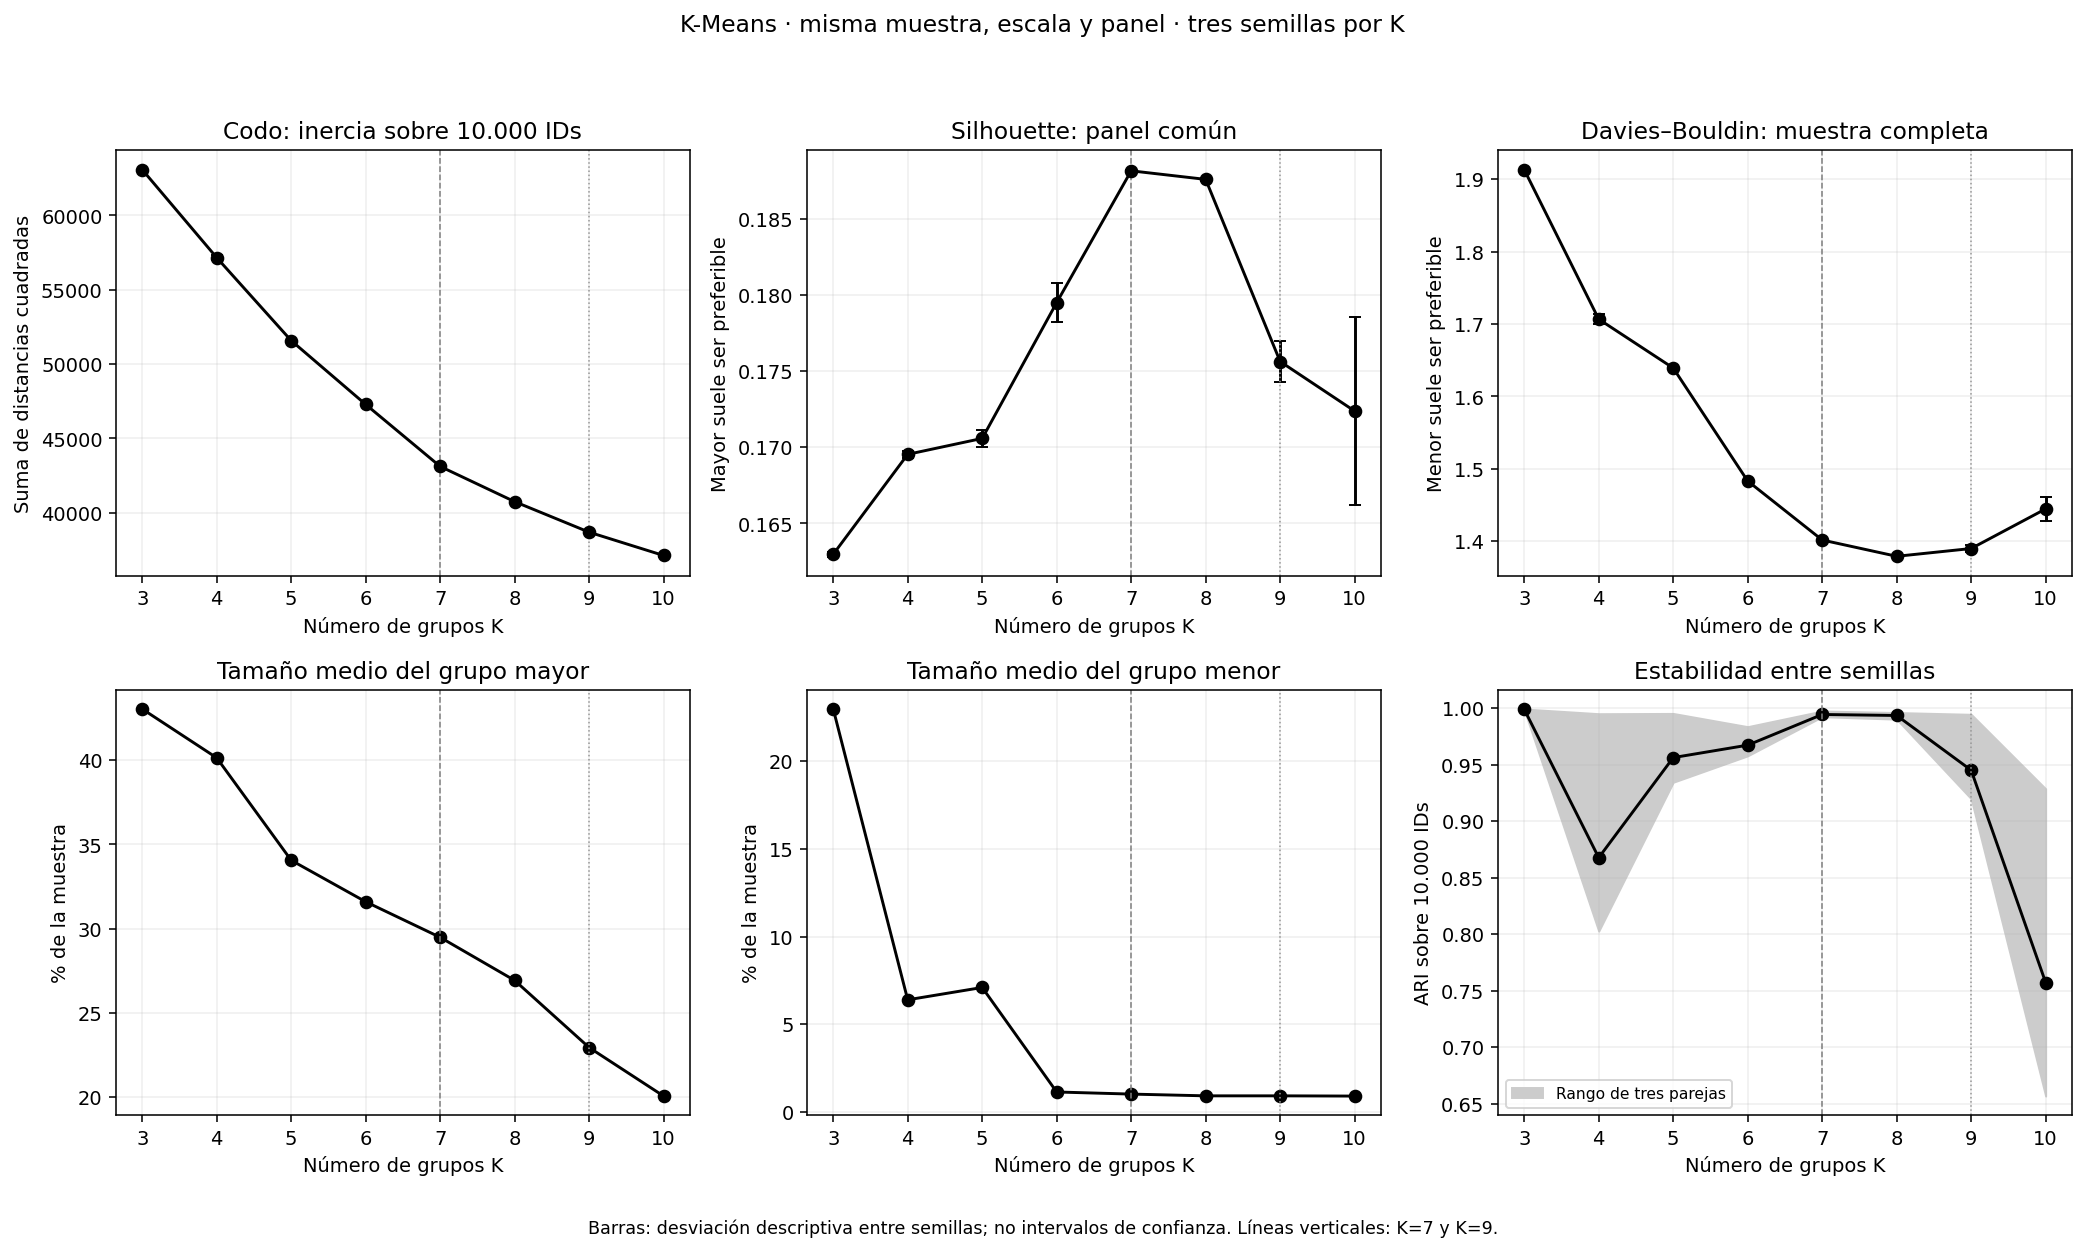

In [57]:
import matplotlib.pyplot as plt

fig_busqueda_kmeans_u3, ejes_busqueda_kmeans_u3 = plt.subplots(2, 3, figsize=(15, 9))
rk = resumen_kmeans_busqueda_u3
paneles_kmeans_u3 = [
    ("Inercia_media", "Inercia_DE", "Codo: inercia sobre 10.000 IDs", "Suma de distancias cuadradas"),
    ("Silhouette_media", "Silhouette_DE", "Silhouette: panel común", "Mayor suele ser preferible"),
    ("DB_media", "DB_DE", "Davies–Bouldin: muestra completa", "Menor suele ser preferible"),
    ("Grupo_mayor_porcentaje", None, "Tamaño medio del grupo mayor", "% de la muestra"),
    ("Grupo_menor_porcentaje", None, "Tamaño medio del grupo menor", "% de la muestra"),
    ("ARI_media", None, "Estabilidad entre semillas", "ARI sobre 10.000 IDs"),
]
for eje, (columna, dispersion, titulo, ylabel) in zip(ejes_busqueda_kmeans_u3.flat, paneles_kmeans_u3):
    if dispersion:
        eje.errorbar(rk.index, rk[columna], yerr=rk[dispersion], marker="o", color="black", capsize=3)
    else:
        eje.plot(rk.index, rk[columna], marker="o", color="black")
    if columna == "ARI_media":
        eje.fill_between(rk.index, rk["ARI_minimo"], rk["ARI_maximo"], color="0.8", label="Rango de tres parejas")
        eje.legend(fontsize=8)
    eje.axvline(7, color="0.5", linestyle="--", linewidth=0.8)
    eje.axvline(9, color="0.6", linestyle=":", linewidth=0.8)
    eje.set(title=titulo, xlabel="Número de grupos K", ylabel=ylabel)
    eje.set_xticks(KS_BUSQUEDA_CLUSTER_U3)
    eje.grid(alpha=0.2)
fig_busqueda_kmeans_u3.suptitle("K-Means · misma muestra, escala y panel · tres semillas por K")
fig_busqueda_kmeans_u3.text(0.5, 0.012, "Barras: desviación descriptiva entre semillas; no intervalos de confianza. Líneas verticales: K=7 y K=9.", ha="center", fontsize=9)
fig_busqueda_kmeans_u3.tight_layout(rect=[0, 0.04, 1, 0.95])
display(fig_busqueda_kmeans_u3)
plt.close(fig_busqueda_kmeans_u3)

### Cómo leer los gráficos y qué podemos decidir

`subplots` crea seis paneles. `errorbar` muestra media y dispersión entre semillas cuando corresponde; `plot` muestra tamaños medios o ARI medio. La franja de ARI es el mínimo y máximo de las tres parejas. Las líneas verticales señalan K=7 y K=9 como referencias, no como resultados aprobados.

Se observa si la inercia sigue bajando con ganancias cada vez menores; luego se contrasta con silhouette, Davies–Bouldin, tamaños y estabilidad. Una silhouette mayor puede corresponder a menos grupos y menor variedad; más K puede producir perfiles más específicos a costa de separación o estabilidad. No se suman estas métricas en un puntaje inventado y no se selecciona el K que dé la cifra más conveniente.

Las diferencias pequeñas de silhouette en un solo panel no demuestran superioridad estadística. Una estabilidad alta indica consistencia ante inicialización, no adecuación musical ni generalización. Los modelos siguen trabajando en nueve descriptores; correlaciones y versiones con varios IDs pueden influir en los resultados.

**Estado:** el experimento compara candidatos; no confirma aún un K final para playlists. El siguiente paso será revisar perfiles musicales y representantes de los candidatos, especialmente K=7 y K=9 si los resultados los mantienen razonables, y después contrastarlos con DBSCAN bajo su protocolo de cobertura y ruido. No se modificó preparación ni se consultó test.

### 23.2. Lectura de los resultados ejecutados



La mayor silhouette media del panel fue la de **K=7 (0.18815)**; el menor Davies–Bouldin medio correspondió a **K=8 (1.37930)** y la mayor estabilidad media a **K=3 (ARI 0.99883)**. Son máximos o mínimos observados en este experimento, no metas de aprobación ni una votación automática por un K.

**K=7:** inercia media 43109.71; silhouette media 0.18815; Davies–Bouldin medio 1.40181; ARI medio 0.99430, mínimo 0.99231. El grupo menor ocupa en promedio 1.01% y el mayor 29.48%. Son promedios de tres ajustes, no tamaños de un único modelo.

**K=9:** inercia media 38684.78; silhouette media 0.17563; Davies–Bouldin medio 1.39005; ARI medio 0.94500, mínimo 0.91970. El grupo menor ocupa en promedio 0.91% y el mayor 22.93%. Son promedios de tres ajustes, no tamaños de un único modelo.

En K=7→8, 8→9 y 9→10, las reducciones relativas de inercia fueron 5.50%, 5.04% y 4.05%. Las cifras permiten examinar rendimientos decrecientes, pero no establecen por sí mismas un codo único.

Los 24 ajustes conservaron las 10.000 filas; se registraron 0 alertas de alcanzar max_iter en las soluciones guardadas. El panel de silhouette contenía 2000 IDs. La tabla por ajuste permite comprobar si aparecen todos los grupos en cada panel.

### Qué nos dicen estos resultados para playlists

**K=7 es un candidato sólido para continuar, no una elección final.** Presenta la mayor silhouette media (0,18815), muy próxima a K=8 (0,18759), y ARI medio 0,99430. Una silhouette alrededor de 0,19 sugiere separación limitada y posibles fronteras difusas; no significa 19% de canciones correctas. El ARI cercano a uno indica particiones muy similares entre las tres semillas probadas, no 99% de acierto musical.

**K=8 también merece revisar sus perfiles:** tiene el menor Davies–Bouldin (1,37930), frente a 1,40181 en K=7, y ARI 0,99343. No se puede descartarlo solo por haber trabajado antes con siete grupos. La diferencia de silhouette con K=7 es pequeña y no se ha contrastado con otros paneles; no demuestra superioridad general de siete.

**K=9 ofrece más variedad potencial y grupos menos grandes**, pero no mejora todos los criterios: silhouette 0,17563 y ARI medio 0,94500, con mínimo 0,91970, frente a 0,99231 como mínimo en K=7. Su Davies–Bouldin 1,39005 es ligeramente mejor que el de K=7 y peor que el de K=8. El grupo mayor ocupa en promedio 22,93% frente a 29,48% en K=7. Esto describe particiones más subdivididas, sin demostrar todavía perfiles musicales más útiles. Los grupos no se corresponden automáticamente uno a uno entre K.

En **K=10** la estabilidad baja a ARI medio 0,75711 y mínimo 0,65662; silhouette y Davies–Bouldin también empeoran respecto a K=7 y K=8. No hay una ventaja clara por aumentar K hasta diez en este experimento. K=3 es muy estable (ARI 0,99883), pero presenta menor silhouette, mayor Davies–Bouldin y una partición más general; estabilidad sola no resuelve el objetivo de variedad.

La reducción de inercia al pasar de K=6 a K=7 es 8,82%, y de K=7 a K=8 es 5,50%. El gráfico es compatible con una disminución de las ganancias a partir de la zona de siete, pero sigue siendo una lectura exploratoria del codo, no una prueba de que siete sea el número verdadero.

Desde K=6 aparecen grupos de alrededor de 1% de la muestra; en K=7 el mínimo observado es 101 IDs y en K=9 es 91. Debemos describir su música y comprobar si son nichos útiles o agrupaciones dominadas por características extremas. No se borran por ser pequeños ni se les asignan nombres musicales antes de revisar sus perfiles.

**Decisión de esta fase:** mantener K=7 como referencia provisional y contrastar perfiles de K=7, K=8 y K=9 antes de elegir. Incorporar K=8 responde a su resultado actual, no a cambiar los datos o repetir la búsqueda hasta favorecer un modelo. Los datos y la preparación permanecen fijos; las conclusiones corresponden a esta muestra de entrenamiento, no a test ni a toda la base.


## 24. Perfiles musicales: K=7, K=8 y K=9

### 24.1. Qué buscamos al agregar grupos

Un K mayor solo aporta utilidad para playlists si permite distinguir perfiles musicales interpretables sin fragmentarlos de manera poco estable. Revisaremos medias, dispersión interna, tamaños y correspondencias entre particiones sobre los mismos 10.000 IDs preparados. No se ajustan modelos nuevos ni se consulta test.

Usamos la **semilla 42 fijada previamente** para describir los tres modelos. No se elige una semilla distinta para que cada K parezca mejor. Las métricas del bloque 23 eran medias de tres semillas; estos perfiles pertenecen a una realización concreta.

Las etiquetas son arbitrarias: grupo 0 de K=7 no tiene por qué ser grupo 0 de K=8. Las tablas de cruces mostrarán qué canciones comparten realmente los grupos. No suponemos que los modelos sean jerárquicos o que un K mayor solo divida un grupo anterior.

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

KS_PERFILES_U3 = [7, 8, 9]
SEMILLA_PERFILES_U3 = 42
perfiles_z_789_u3 = {}
perfiles_originales_789_u3 = {}
dispersion_original_789_u3 = {}
resumen_perfiles_789_u3 = {}
rasgos_perfiles_789_u3 = []
for k in KS_PERFILES_U3:
    etiquetas = etiquetas_kmeans_busqueda_u3[(k, SEMILLA_PERFILES_U3)]
    if not etiquetas.index.equals(X_muestra_cluster_escalada_u3.index):
        raise ValueError("Las etiquetas no coinciden con los IDs preparados.")
    perfiles_z_789_u3[k] = X_muestra_cluster_escalada_u3.groupby(etiquetas).mean()
    perfiles_originales_789_u3[k] = X_muestra_cluster_imputada_u3.groupby(etiquetas).mean()
    dispersion_original_789_u3[k] = X_muestra_cluster_imputada_u3.groupby(etiquetas).std(ddof=0)
    tamanos = etiquetas.value_counts().sort_index()
    resumen = pd.DataFrame({"IDs": tamanos, "% muestra": tamanos / len(etiquetas) * 100})
    resumen["Claves distintas"] = g_muestra_cluster_u3.groupby(etiquetas).nunique()
    resumen["Tempo imputado (%)"] = X_muestra_cluster_u3["tempo"].isna().groupby(etiquetas).mean() * 100
    resumen_perfiles_789_u3[k] = resumen
    for grupo, medias in perfiles_z_789_u3[k].iterrows():
        for variable in medias.abs().nlargest(3).index:
            rasgos_perfiles_789_u3.append({"K": k, "Grupo": grupo, "Variable": variable,
                "Media z": medias[variable], "Media original": perfiles_originales_789_u3[k].loc[grupo, variable],
                "DE interna original": dispersion_original_789_u3[k].loc[grupo, variable]})
    print(f"K={k}: tamaños y medias musicales en unidades originales.")
    display(resumen.round(2))
    display(perfiles_originales_789_u3[k].round(4))
rasgos_destacados_789_u3 = pd.DataFrame(rasgos_perfiles_789_u3)
display(rasgos_destacados_789_u3.round(4))

K=7: tamaños y medias musicales en unidades originales.
K=8: tamaños y medias musicales en unidades originales.
K=9: tamaños y medias musicales en unidades originales.


,IDs,% muestra,Claves distintas,Tempo imputado (%)
Grupo,,,,
0,1175,11.75,1147,0.00
1,638,6.38,607,0.16
2,2946,29.46,2562,0.00
3,101,1.01,99,0.00
4,2309,23.09,2113,0.00
5,2123,21.23,1861,0.00
6,708,7.08,678,2.12


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Grupo,,,,,,,,,
0,0.5811,0.7313,-8.6250,0.0731,0.1280,0.8004,0.1661,0.3475,126.4767
1,0.5156,0.7551,-7.2171,0.0956,0.2875,0.1060,0.7527,0.4943,123.7348
2,0.7099,0.7159,-6.4954,0.0978,0.2212,0.0190,0.1650,0.6960,117.2658
3,0.5815,0.6730,-11.3085,0.8457,0.7317,0.0149,0.6627,0.4491,97.2142
4,0.4732,0.8119,-5.5091,0.0859,0.0780,0.0365,0.1960,0.3760,140.6364
5,0.5304,0.3804,-10.4692,0.0537,0.6804,0.0303,0.1671,0.4019,112.5792
6,0.3339,0.1732,-21.4095,0.0509,0.8684,0.7529,0.1660,0.1793,104.9638


,IDs,% muestra,Claves distintas,Tempo imputado (%)
Grupo,,,,
0,2000,20.00,1748,0.00
1,701,7.01,671,2.14
2,614,6.14,584,0.00
3,2696,26.96,2310,0.00
4,1153,11.53,1125,0.00
5,2133,21.33,1959,0.00
6,612,6.12,582,0.16
7,91,0.91,90,0.00


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Grupo,,,,,,,,,
0,0.5234,0.3732,-10.5371,0.0479,0.6888,0.0319,0.1666,0.3898,112.3872
1,0.3340,0.1721,-21.4731,0.0509,0.8683,0.7578,0.1662,0.1798,104.9357
2,0.7140,0.6734,-7.0781,0.3168,0.2509,0.0227,0.1783,0.5558,125.6778
3,0.6950,0.7173,-6.5211,0.0625,0.2270,0.0206,0.1671,0.7078,118.2922
4,0.5816,0.7312,-8.6447,0.0702,0.1282,0.8053,0.1672,0.3479,126.5579
5,0.4636,0.8161,-5.4600,0.0750,0.0713,0.0411,0.1972,0.3610,138.7259
6,0.5115,0.7549,-7.2350,0.0881,0.2901,0.1070,0.7602,0.4935,124.0368
7,0.5649,0.6912,-11.2721,0.8720,0.7571,0.0162,0.7132,0.4333,95.9966


,IDs,% muestra,Claves distintas,Tempo imputado (%)
Grupo,,,,
0,565,5.65,535,0.00
1,684,6.84,654,2.05
2,1262,12.62,1162,0.00
3,1567,15.67,1433,0.00
4,2331,23.31,1959,0.00
5,1779,17.79,1580,0.06
6,1128,11.28,1101,0.00
7,91,0.91,90,0.00
8,593,5.93,564,0.17


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Grupo,,,,,,,,,
0,0.7230,0.6653,-7.2353,0.3225,0.2546,0.0272,0.1770,0.5521,118.9727
1,0.3320,0.1698,-21.6089,0.0503,0.8698,0.7647,0.1648,0.1789,104.7620
2,0.4583,0.8152,-5.4520,0.0893,0.1135,0.0450,0.2053,0.4849,164.2682
3,0.5248,0.7601,-5.9722,0.0631,0.0860,0.0326,0.1825,0.3160,111.6774
4,0.7057,0.7060,-6.6615,0.0625,0.2613,0.0220,0.1687,0.7405,116.7462
5,0.5212,0.3527,-10.8947,0.0479,0.7271,0.0401,0.1654,0.3835,114.0873
6,0.5787,0.7341,-8.6527,0.0697,0.1208,0.8069,0.1662,0.3396,126.4014
7,0.5649,0.6912,-11.2721,0.8720,0.7571,0.0162,0.7132,0.4333,95.9966
8,0.5130,0.7541,-7.2817,0.0872,0.2940,0.1132,0.7682,0.4982,123.5937


,K,Grupo,Variable,Media z,Media original,DE interna original
0,7,0,instrumentalness,1.9238,0.8004,0.1374
1,7,0,acousticness,-0.5964,0.1280,0.2203
2,7,0,valence,-0.4546,0.3475,0.2554
3,7,1,liveness,2.8069,0.7527,0.1483
4,7,1,energy,0.4808,0.7551,0.1825
5,7,1,danceability,-0.2598,0.5156,0.1562
6,7,2,valence,0.8733,0.6960,0.1832
7,7,2,danceability,0.8355,0.7099,0.1065
8,7,2,instrumentalness,-0.4788,0.0190,0.0778
9,7,3,speechiness,6.8867,0.8457,0.1343


### Cómo se construyen y leen los perfiles

1. Los imports cargan tablas, gráficos y parejas de elementos. Las constantes fijan los tres K y una sola semilla para presentación.
2. Se recuperan etiquetas ya calculadas y se exige igual índice y orden. No se reasignan canciones ni se cambian centros.
3. `groupby(etiquetas).mean()` calcula una media por grupo y variable. En escala z indica cuántas desviaciones de la muestra separan la media del grupo de la media global; en unidades originales permite leer tempo en BPM y volumen en dB. La media z del grupo no es una nueva estandarización dentro de él.
4. `std(ddof=0)` describe dispersión dentro del grupo. La tabla de rasgos muestra esa dispersión para las variables destacadas: dos grupos con medias distintas pueden contener canciones muy parecidas. No se infiere separación perfecta mirando centros.
5. `value_counts` cuenta IDs; dividir por 10.000 convierte tamaño en proporción. `nunique` cuenta claves distintas, que pueden ser menos que IDs por las versiones. La columna de tempo imputado ayuda a interpretar si ese descriptor tuvo reemplazos.
6. `abs().nlargest(3)` elige los tres mayores contrastes absolutos de cada perfil respecto a la muestra, tanto positivos como negativos. No son importancias de variables, causas ni pruebas estadísticas. Se mantiene el signo de la media z para saber la dirección.

Bailabilidad, energía, acústica, instrumentalidad, voz hablada y valencia son indicadores estimados. Una media de instrumentalidad alta permite describir un perfil como «más instrumental» respecto a la muestra, no afirmar que todas sus canciones carezcan de voz. Tampoco valencia es la emoción de cada oyente. Los nombres musicales serán descripciones relativas, no géneros oficiales.

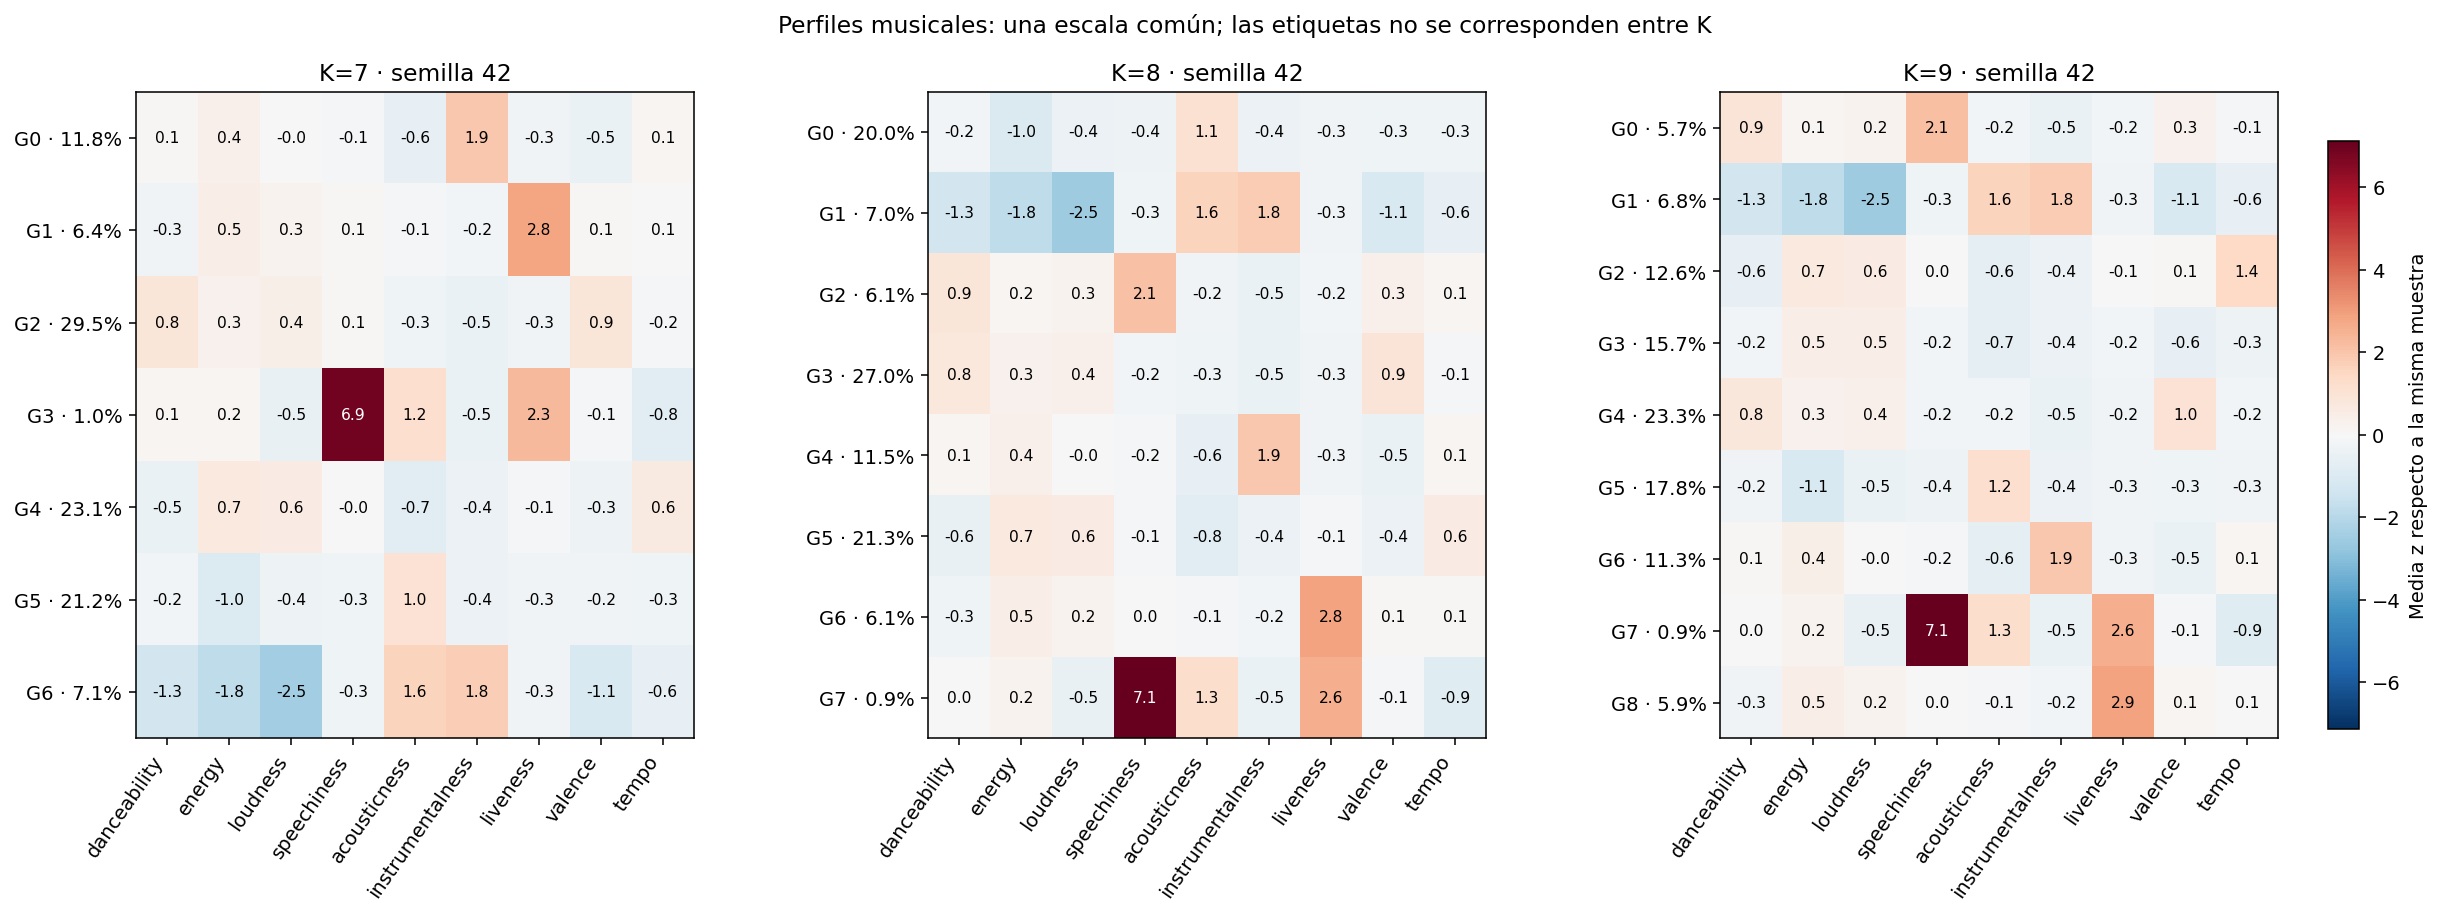

In [59]:
fig_perfiles_789_u3, ejes_perfiles_789_u3 = plt.subplots(1, 3, figsize=(18, 7))
limite_perfiles_789_u3 = max(float(perfil.abs().to_numpy().max()) for perfil in perfiles_z_789_u3.values())
for eje, k in zip(ejes_perfiles_789_u3, KS_PERFILES_U3):
    perfil = perfiles_z_789_u3[k]
    imagen = eje.imshow(perfil, cmap="RdBu_r", vmin=-limite_perfiles_789_u3, vmax=limite_perfiles_789_u3, aspect="auto")
    eje.set_xticks(range(len(perfil.columns)), perfil.columns, rotation=55, ha="right")
    eje.set_yticks(range(k), [f"G{g} · {resumen_perfiles_789_u3[k].loc[g, '% muestra']:.1f}%" for g in perfil.index])
    eje.set_title(f"K={k} · semilla 42")
    for i in range(k):
        for j in range(len(perfil.columns)):
            v = perfil.iloc[i, j]
            eje.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > limite_perfiles_789_u3 * 0.55 else "black")
fig_perfiles_789_u3.subplots_adjust(left=0.06, right=0.91, bottom=0.24, top=0.90, wspace=0.42)
barra_perfiles_789_u3 = fig_perfiles_789_u3.add_axes([0.93, 0.25, 0.012, 0.60])
fig_perfiles_789_u3.colorbar(imagen, cax=barra_perfiles_789_u3, label="Media z respecto a la misma muestra")
fig_perfiles_789_u3.suptitle("Perfiles musicales: una escala común; las etiquetas no se corresponden entre K")
display(fig_perfiles_789_u3)
plt.close(fig_perfiles_789_u3)

### Cómo leer el gráfico

Cada fila es un grupo y cada columna un descriptor. `imshow` representa las medias z con una **misma escala de color en los tres paneles**: azul significa media inferior a la global, rojo superior y blanco cercana. Los números muestran cuánto se aleja el promedio, no el valor de cada canción. El porcentaje junto al grupo corresponde a su tamaño.

La escala se fija con el mayor contraste observado entre todos los paneles para que un mismo color signifique el mismo valor. Los grupos con valores extremos pueden comprimir visualmente diferencias pequeñas: por eso se incluyen números y tablas originales. Una fila de color intenso no demuestra que ese grupo sea una mejor playlist.

`subplots`, etiquetas y barra de color preparan la presentación; no alteran datos. La comparación relevante es entre combinaciones musicales y su población, no entre el mismo número de fila de distintos K.

In [60]:
cruces_perfiles_789_u3 = {}
transiciones_perfiles_789_u3 = []
for ka, kb in [(7, 8), (7, 9), (8, 9)]:
    a = etiquetas_kmeans_busqueda_u3[(ka, SEMILLA_PERFILES_U3)]
    b = etiquetas_kmeans_busqueda_u3[(kb, SEMILLA_PERFILES_U3)]
    cruce = pd.crosstab(a.rename(f"K={ka}"), b.rename(f"K={kb}"))
    porcentajes = cruce.div(cruce.sum(axis=1), axis=0) * 100
    cruces_perfiles_789_u3[(ka, kb)] = {"IDs": cruce, "% fila": porcentajes}
    if cruce.to_numpy().sum() != len(a):
        raise ValueError("El cruce perdió registros.")
    print(f"K={ka} → K={kb}: porcentaje de cada grupo de origen que llega a cada destino.")
    display(porcentajes.round(2))
    for origen, fila in cruce.iterrows():
        destinos = fila.sort_values(ascending=False)
        for destino, cantidad in destinos.head(2).items():
            transiciones_perfiles_789_u3.append({"K origen": ka, "Grupo origen": origen,
                "IDs origen": int(fila.sum()), "K destino": kb, "Grupo destino": destino,
                "IDs compartidos": int(cantidad), "% del origen": cantidad / fila.sum() * 100})
transiciones_principales_789_u3 = pd.DataFrame(transiciones_perfiles_789_u3)
display(transiciones_principales_789_u3.round(2))

filas_centros_cercanos_789_u3 = []
for k in KS_PERFILES_U3:
    medias = perfiles_z_789_u3[k]
    pares = []
    for ga, gb in combinations(medias.index, 2):
        diferencia = (medias.loc[ga] - medias.loc[gb]).abs()
        pares.append({"K": k, "Grupo A": ga, "Grupo B": gb,
            "Distancia centros (z euclídea)": float(np.linalg.norm(medias.loc[ga] - medias.loc[gb])),
            "Contraste mayor": diferencia.idxmax(), "Diferencia absoluta z": diferencia.max()})
    filas_centros_cercanos_789_u3.extend(sorted(pares, key=lambda fila: fila["Distancia centros (z euclídea)"])[:3])
centros_cercanos_789_u3 = pd.DataFrame(filas_centros_cercanos_789_u3)
display(centros_cercanos_789_u3.round(4))

K=7 → K=8: porcentaje de cada grupo de origen que llega a cada destino.
K=7 → K=9: porcentaje de cada grupo de origen que llega a cada destino.
K=8 → K=9: porcentaje de cada grupo de origen que llega a cada destino.


K=8,0,1,2,3,4,5,6,7
K=7,,,,,,,,
0,0.09,0.00,1.02,0.26,97.70,0.94,0.00,0.0
1,0.00,0.00,2.82,0.47,0.31,0.63,95.77,0.0
2,0.03,0.00,14.32,85.51,0.00,0.14,0.00,0.0
3,0.00,0.00,9.90,0.00,0.00,0.00,0.00,90.1
4,0.04,0.00,4.63,3.98,0.00,91.29,0.04,0.0
5,93.74,0.00,2.12,3.72,0.14,0.28,0.00,0.0
6,0.99,99.01,0.00,0.00,0.00,0.00,0.00,0.0


K=9,0,1,2,3,4,5,6,7,8
K=7,,,,,,,,,
0,1.19,0.00,1.53,1.96,0.43,0.34,94.55,0.0,0.00
1,2.82,0.00,1.88,2.82,0.00,0.00,0.00,0.0,92.48
2,13.78,0.00,3.09,9.50,73.59,0.00,0.03,0.0,0.00
3,9.90,0.00,0.00,0.00,0.00,0.00,0.00,90.1,0.00
4,2.94,0.00,48.42,47.12,0.69,0.13,0.65,0.0,0.04
5,2.26,0.00,1.08,7.44,6.69,82.48,0.00,0.0,0.05
6,0.14,96.61,0.00,0.00,0.00,2.97,0.14,0.0,0.14


K=9,0,1,2,3,4,5,6,7,8
K=8,,,,,,,,,
0,0.30,0.00,1.00,7.25,3.65,87.70,0.05,0.0,0.05
1,0.14,97.57,0.00,0.00,0.00,2.00,0.14,0.0,0.14
2,89.09,0.00,8.96,0.65,0.81,0.33,0.00,0.0,0.16
3,0.26,0.00,5.08,11.13,83.38,0.00,0.11,0.0,0.04
4,0.17,0.00,1.56,1.56,0.35,0.52,95.66,0.0,0.17
5,0.05,0.00,47.77,51.01,0.05,0.14,0.94,0.0,0.05
6,0.16,0.00,2.12,1.96,0.00,0.00,0.00,0.0,95.75
7,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.0,0.00


,K origen,Grupo origen,IDs origen,K destino,Grupo destino,IDs compartidos,% del origen
0,7,0,1175,8,4,1148,97.70
1,7,0,1175,8,2,12,1.02
2,7,1,638,8,6,611,95.77
3,7,1,638,8,2,18,2.82
4,7,2,2946,8,3,2519,85.51
5,7,2,2946,8,2,422,14.32
6,7,3,101,8,7,91,90.10
7,7,3,101,8,2,10,9.90
8,7,4,2309,8,5,2108,91.29
9,7,4,2309,8,2,107,4.63


,K,Grupo A,Grupo B,Distancia centros (z euclídea),Contraste mayor,Diferencia absoluta z
0,7,2,4,2.0685,danceability,1.3346
1,7,2,5,2.5736,acousticness,1.3568
2,7,0,4,2.5784,instrumentalness,2.3489
3,8,3,5,2.0884,valence,1.3212
4,8,2,3,2.4049,speechiness,2.3078
5,8,4,5,2.5843,instrumentalness,2.3500
6,9,2,3,1.9498,tempo,1.7641
7,9,3,4,2.0056,valence,1.6172
8,9,2,4,2.4422,tempo,1.5941


### Qué revelan las correspondencias

`crosstab` cuenta cuántos IDs comparten cada par de grupos. Dividir por la suma de cada **fila** muestra qué proporción del grupo de origen va a cada destino; cada fila suma cien. No es porcentaje del destino ni porcentaje de acierto. La tabla completa de conteos queda guardada junto a la de porcentajes.

Ordenar cada fila permite mostrar sus dos destinos principales, sin borrar destinos menores de la tabla completa. Un grupo que se reparte entre dos destinos puede señalar una subdivisión útil, pero otros grupos pueden mezclarse también. No se trata de un árbol jerárquico ni se supone que un K mayor conserve las fronteras previas.

Las tres parejas de centros más próximos por K ayudan a identificar perfiles que requieren atención por similitud. `norm` mide distancia euclídea entre medias en la misma escala z; la diferencia absoluta por variable identifica el mayor contraste entre esas medias. No es distancia entre todas las canciones ni una prueba de redundancia. Las dispersiones internas siguen siendo importantes.

Estos análisis no utilizan popularidad, géneros o artistas para decidir parámetros. Tampoco se inventan etiquetas de estilo a partir de la posición del grupo.

### Estado de esta comparación

La utilidad para playlists se interpreta combinando perfiles, tamaños y las métricas y estabilidad del bloque anterior. Más grupos pueden ofrecer variedad, pero también fronteras menos consistentes. No se afirma satisfacción de usuarios sin escuchar canciones y evaluar recomendaciones.

La selección que se justifique aquí será **provisional sobre la muestra**. Falta comparar con DBSCAN y, si es viable, comprobar el comportamiento de los candidatos a escala de todo entrenamiento. Test no interviene, y los resultados de la unidad 2 no se presentan como confirmación independiente de esta decisión.

In [61]:
# Nombres descriptivos relativos: no son géneros oficiales ni validación por oyentes.
nombres_perfiles_789_u3 = {
    7: {0: "Más instrumental, energía media-alta", 1: "Más indicios de interpretación en vivo",
        2: "Más bailable y de mayor valencia", 3: "Voz hablada muy marcada: revisar contenido",
        4: "Energético, menos acústico y más rápido", 5: "Más acústico, menor energía",
        6: "Acústico e instrumental, poca energía y volumen"},
    8: {0: "Más acústico, menor energía", 1: "Acústico e instrumental, poca energía y volumen",
        2: "Bailable con mayor presencia de voz hablada", 3: "Bailable, mayor valencia y menor voz hablada",
        4: "Más instrumental, energía media-alta", 5: "Energético, menos acústico y más rápido",
        6: "Más indicios de interpretación en vivo", 7: "Voz hablada muy marcada: revisar contenido"},
    9: {0: "Bailable con mayor presencia de voz hablada", 1: "Acústico e instrumental, poca energía y volumen",
        2: "Energético y de tempo más rápido", 3: "Energético con tempo menor que el otro grupo energético",
        4: "Bailable, mayor valencia y menor voz hablada", 5: "Más acústico, menor energía",
        6: "Más instrumental, energía media-alta", 7: "Voz hablada muy marcada: revisar contenido",
        8: "Más indicios de interpretación en vivo"},
}
filas_lectura_perfiles_789_u3 = []
for k, nombres in nombres_perfiles_789_u3.items():
    for grupo, nombre in nombres.items():
        filas_lectura_perfiles_789_u3.append({"K": k, "Grupo": grupo, "Descripción relativa": nombre,
            "IDs": int(resumen_perfiles_789_u3[k].loc[grupo, "IDs"]),
            "% muestra": resumen_perfiles_789_u3[k].loc[grupo, "% muestra"]})
lectura_perfiles_789_u3 = pd.DataFrame(filas_lectura_perfiles_789_u3)
k_provisional_perfiles_u3 = 8
comparacion_utilidad_789_u3 = resumen_kmeans_busqueda_u3.loc[[7, 8, 9], [
    "Silhouette_media", "DB_media", "ARI_media", "ARI_minimo"
]].copy()
comparacion_utilidad_789_u3["Lectura para playlists"] = [
    "Siete perfiles generales; interpretación más simple",
    "Añade contraste de voz hablada con separación y estabilidad similares a K=7",
    "Añade contraste de tempo; menor estabilidad y silhouette que K=7/K=8",
]
comparacion_utilidad_789_u3["Provisional para playlists generales"] = comparacion_utilidad_789_u3.index == k_provisional_perfiles_u3
display(lectura_perfiles_789_u3.round(2))
display(comparacion_utilidad_789_u3.round(5))

,K,Grupo,Descripción relativa,IDs,% muestra
0,7,0,"Más instrumental, energía media-alta",1175,11.75
1,7,1,Más indicios de interpretación en vivo,638,6.38
2,7,2,Más bailable y de mayor valencia,2946,29.46
3,7,3,Voz hablada muy marcada: revisar contenido,101,1.01
4,7,4,"Energético, menos acústico y más rápido",2309,23.09
5,7,5,"Más acústico, menor energía",2123,21.23
6,7,6,"Acústico e instrumental, poca energía y volumen",708,7.08
7,8,0,"Más acústico, menor energía",2000,20.00
8,8,1,"Acústico e instrumental, poca energía y volumen",701,7.01
9,8,2,Bailable con mayor presencia de voz hablada,614,6.14


,Silhouette_media,DB_media,ARI_media,ARI_minimo,Lectura para playlists,Provisional para playlists generales
K,,,,,,
7,0.18815,1.40181,0.99430,0.99231,Siete perfiles generales; interpretación más simple,False
8,0.18759,1.37930,0.99343,0.99016,Añade contraste de voz hablada con separación y estabilidad similares a K=7,True
9,0.17563,1.39005,0.94500,0.91970,Añade contraste de tempo; menor estabilidad y silhouette que K=7/K=8,False


### 24.2. Lectura musical de los resultados y elección provisional

El diccionario del código asigna **descripciones humanas** a medias ya calculadas. El recorrido une nombres, tamaños y porcentajes; no crea etiquetas nuevas ni vuelve a ajustar el modelo. La tabla de utilidad recupera las métricas medias del bloque 23, mientras que los nombres describen la semilla 42. `k_provisional_perfiles_u3 = 8` registra una decisión interpretativa provisional; no es una optimización automática ni cambia los modelos guardados.

**Qué conserva K=7.** Distingue un perfil más instrumental con energía media-alta (1.175 IDs), otro más acústico e instrumental de poca energía (708), un perfil más acústico de menor energía (2.123), otro bailable con mayor valencia (2.946), uno energético y más rápido (2.309), uno con indicios de interpretación en vivo (638) y un grupo muy marcado por voz hablada (101). Son diferencias que pueden orientar exploración. No garantizan que todas las canciones de un grupo combinen bien ni que sean del mismo género.

**Qué añade K=8.** El grupo 2 reúne 614 IDs y combina bailabilidad media 0,714 con speechiness 0,3168; el grupo 3 reúne 2.696 IDs, con bailabilidad 0,695 y speechiness 0,0625. También difieren en valencia media (0,5558 frente a 0,7078). La diferencia principal es presencia estimada de voz hablada, no una separación entre canciones bailables y no bailables. Esa distinción podría ayudar a evitar mezclar perfiles vocales muy distintos en una misma selección.

El cruce muestra que 85,5% del grupo bailable 2 de K=7 pasa al grupo 3 de K=8, y 14,3% al grupo 2 de K=8. **Son porcentajes del grupo de K=7**, no la composición completa de los destinos: el grupo nuevo de 614 IDs recibe también canciones de otros orígenes. No se ha dividido una partición de manera estrictamente jerárquica.

K=8 mantiene prácticamente la silhouette media de K=7 (0,18759 frente a 0,18815), mejora Davies–Bouldin (1,37930 frente a 1,40181) y conserva estabilidad alta entre semillas (ARI medio 0,99343 frente a 0,99430). Las diferencias pequeñas no prueban superioridad estadística. El argumento para considerar el grupo adicional es su **contraste musical interpretable acompañado de métricas similares**, no una cifra aislada.

**Qué añade K=9.** Sus grupos energéticos 2 y 3 tienen 1.262 y 1.567 IDs, tempo medio 164,27 y 111,68 BPM, y energía media 0,8152 y 0,7601. El grupo 5 energético de K=8 se reparte principalmente entre ellos: 47,8% y 51,0% de su población, respectivamente. Hay otras reasignaciones en la partición. La separación puede ser útil para playlists que prioricen tempo, aunque tempo estimado no garantiza sensación rítmica uniforme y su percepción puede diferir de los BPM.

A cambio, K=9 tiene menor silhouette media (0,17563) y menor estabilidad entre semillas (ARI medio 0,94500, mínimo 0,91970). No afirmamos que esos perfiles sean inútiles o que todos sus grupos sean inestables: la evidencia indica que esta partición global cambia más con inicialización. Su grupo energético rápido no es simplemente un duplicado del otro; ambos tienen una diferencia musical que podría justificar revisarlo si el objetivo se orienta a velocidad.

### 24.3. Cuál resulta más útil y por qué cambia la referencia

**Para la propuesta general de explorar playlists, elegimos provisionalmente K=8 como el equilibrio más útil entre los tres**, sujeto a revisar canciones y comparar con DBSCAN. Conserva los grandes contrastes de K=7 y distingue un perfil bailable con más voz hablada sin una pérdida importante de separación o estabilidad observada. Es una valoración de diseño apoyada en estos datos, **no una demostración de satisfacción de oyentes**.

K=7 era la referencia provisional por sus métricas y la continuidad con la unidad 2. Ahora incorporamos evidencia adicional de perfiles: cambiar a K=8 no corrige un error del experimento anterior ni significa que siete fuese inválido. La decisión estaba explícitamente pendiente de interpretación musical. Si se prioriza la simplicidad de siete categorías, K=7 sigue siendo defendible. Si el requisito principal pasa a ser distinguir velocidades, K=9 puede ser una alternativa para investigar.

**Límites concretos para playlists:**

- En K=8, el grupo 7 tiene solo 91 IDs de 90 claves y speechiness medio 0,8720: merece revisar si el contenido encaja en playlists musicales. No se elimina ni se etiqueta como podcast o género sin comprobar canciones. El mismo conjunto de 91 IDs aparece en el grupo 7 de K=9, lo que no demuestra por sí solo utilidad.
- El grupo 1 de K=8 tiene tempo imputado en aproximadamente 2,14% de sus 701 IDs (15 registros). Sus medias de tempo incluyen reemplazos; no todas representan mediciones observadas. La imputación no originó por sí sola el perfil, y estas tablas no permiten atribuirle causalidad.
- Centros diferentes no significan canciones separadas sin solapamientos; las dispersiones internas y la silhouette moderada limitan la lectura. La tabla de rasgos incluye desviaciones internas para revisar esa variación.
- Las versiones con distintos IDs siguen aportando peso, aun cuando se conserve su clave. Los resultados se limitan a esta muestra agrupada, su escala y las nueve variables disponibles.
- Los nombres propuestos describen tendencias relativas, sin incorporar géneros ni artista como entradas. No son géneros oficiales ni recomendaciones personalizadas.

**Estado:** queda K=8 como candidato provisional de playlists generales, manteniendo K=7 y K=9 como alternativas documentadas. No se entrenó ningún modelo nuevo ni se modificó la preparación, la clasificación o test. El siguiente paso es revisar canciones representativas de estos perfiles y contrastar DBSCAN con cobertura y ruido antes de cerrar el agrupamiento.


## 25. Canciones representativas de los ocho grupos

### 25.1. Qué significa «representativa»

Usaremos K=8, semilla 42, la alternativa provisional del bloque 24, sin volver a ajustar centros o preparación. Seleccionaremos **tres canciones por grupo cercanas a su centro en las nueve variables estandarizadas**, conservando ejemplos de todos los grupos, incluso el de voz hablada muy marcada.

Un centro es un promedio de características y puede no corresponder a ninguna canción real. Una canción cercana ilustra ese promedio, pero no representa toda la diversidad del grupo, no es necesariamente popular ni garantiza calidad o compatibilidad con el gusto de una persona.

La selección usa solo las 10.000 filas de la muestra preparada. No incorpora popularidad, clase, artista como característica ni canciones de test. Los nombres se recuperan de la clave normalizada ya disponible, exclusivamente para identificar los ejemplos: pueden aparecer en minúsculas o sin la grafía original.

In [62]:
import numpy as np
import pandas as pd

K_REPRESENTATIVAS_U3 = 8
SEMILLA_REPRESENTATIVAS_U3 = 42
EJEMPLOS_POR_GRUPO_U3 = 3
modelo_representativas_u3 = modelos_kmeans_busqueda_u3[(K_REPRESENTATIVAS_U3, SEMILLA_REPRESENTATIVAS_U3)]
etiquetas_representativas_u3 = etiquetas_kmeans_busqueda_u3[(K_REPRESENTATIVAS_U3, SEMILLA_REPRESENTATIVAS_U3)]
if not etiquetas_representativas_u3.index.equals(X_muestra_cluster_escalada_u3.index):
    raise ValueError("Las etiquetas no coinciden con la muestra.")
if modelo_representativas_u3.n_clusters != 8 or modelo_representativas_u3.n_features_in_ != 9:
    raise ValueError("El modelo no corresponde al espacio de ocho grupos y nueve variables.")
centros_por_id_representativas_u3 = modelo_representativas_u3.cluster_centers_[etiquetas_representativas_u3.to_numpy(dtype=int)]
distancia_centro_k8_u3 = pd.Series(
    np.linalg.norm(X_muestra_cluster_escalada_u3.to_numpy() - centros_por_id_representativas_u3, axis=1),
    index=X_muestra_cluster_escalada_u3.index, name="Distancia al centro",
)
if not np.isfinite(distancia_centro_k8_u3).all():
    raise ValueError("Distancias no finitas.")
candidatas_representativas_k8_u3 = pd.DataFrame({
    "Clave": g_muestra_cluster_u3, "Grupo": etiquetas_representativas_u3,
    "Distancia al centro": distancia_centro_k8_u3,
})
candidatas_representativas_k8_u3["ID Spotify"] = candidatas_representativas_k8_u3.index.astype(str)
candidatas_representativas_k8_u3["Percentil distancia (%)"] = candidatas_representativas_k8_u3.groupby("Grupo")["Distancia al centro"].rank(method="max", pct=True) * 100
candidatas_representativas_k8_u3["Tempo imputado"] = X_muestra_cluster_u3["tempo"].isna()
print(f"Distancias calculadas para {len(candidatas_representativas_k8_u3):,} registros de la muestra; no se ajustó el modelo.")

Distancias calculadas para 10,000 registros de la muestra; no se ajustó el modelo.


### Explicación de las distancias

1. Las constantes fijan K, semilla y tres ejemplos. Los diccionarios recuperan el modelo y etiquetas guardados; los controles evitan mezclar particiones o columnas.
2. `cluster_centers_[etiquetas]` recupera para cada fila el centro de su grupo. La resta compara sus nueve características estandarizadas con ese centro.
3. `np.linalg.norm(..., axis=1)` calcula la distancia euclídea de cada fila: raíz de la suma de las nueve diferencias cuadradas. La `Series` devuelve el ID a cada resultado. No se cambia el centro ni se usa el título para medir cercanía.
4. La tabla reúne metadatos, grupo, distancia e ID. `rank(pct=True)` ordena distancias dentro de cada grupo y las expresa como proporción; multiplicar por cien da percentil. `method="max"` asigna a empates la posición más alta ocupada.
5. Un percentil pequeño señala cercanía relativa al centro del grupo. No es probabilidad de pertenencia ni porcentaje de similitud musical; tampoco es silhouette. Las distancias entre grupos con distinta dispersión no tienen el mismo significado de representatividad.
6. `isna()` identifica si el tempo del registro original de la muestra faltaba, antes de imputar. Así no se presenta un reemplazo como si fuera un BPM medido.

In [63]:
ids_representativas_k8_u3 = []
claves_usadas_representativas_u3 = set()
audios_usados_representativas_u3 = set()
for grupo in range(K_REPRESENTATIVAS_U3):
    candidatas = candidatas_representativas_k8_u3.loc[candidatas_representativas_k8_u3["Grupo"].eq(grupo)]
    candidatas = candidatas.sort_values(["Distancia al centro", "ID Spotify"], kind="stable")
    elegidas = 0
    for id_cancion, fila in candidatas.iterrows():
        audio = tuple(X_muestra_cluster_imputada_u3.loc[id_cancion].to_numpy())
        if fila["Clave"] in claves_usadas_representativas_u3 or audio in audios_usados_representativas_u3:
            continue
        ids_representativas_k8_u3.append(id_cancion)
        claves_usadas_representativas_u3.add(fila["Clave"])
        audios_usados_representativas_u3.add(audio)
        elegidas += 1
        if elegidas == EJEMPLOS_POR_GRUPO_U3:
            break
    if elegidas != EJEMPLOS_POR_GRUPO_U3:
        raise ValueError("No hay suficientes ejemplos distintos con los criterios fijados.")
representativas_k8_u3 = candidatas_representativas_k8_u3.loc[ids_representativas_k8_u3].copy()
partes_nombres_representativas_u3 = representativas_k8_u3["Clave"].str.partition(" || ")
if not partes_nombres_representativas_u3[1].eq(" || ").all():
    raise ValueError("Alguna clave no permite recuperar artista y título.")
representativas_k8_u3["Artista normalizado"] = partes_nombres_representativas_u3[0]
representativas_k8_u3["Título normalizado"] = partes_nombres_representativas_u3[2]
representativas_k8_u3["Perfil relativo"] = representativas_k8_u3["Grupo"].map(nombres_perfiles_789_u3[8])
representativas_k8_u3["Orden de ejemplo"] = representativas_k8_u3.groupby("Grupo").cumcount() + 1
representativas_k8_u3["Enlace Spotify"] = "https://open.spotify.com/track/" + representativas_k8_u3["ID Spotify"]
display(representativas_k8_u3[["Grupo", "Perfil relativo", "Orden de ejemplo", "Artista normalizado", "Título normalizado", "ID Spotify", "Distancia al centro", "Percentil distancia (%)", "Tempo imputado"]].round(4))

,Grupo,Perfil relativo,Orden de ejemplo,Artista normalizado,Título normalizado,ID Spotify,Distancia al centro,Percentil distancia (%),Tempo imputado
track_id,,,,,,,,,
2KogAeAixsmxIzDmMHKhjY,0,"Más acústico, menor energía",1,terence lam,下一位前度 in ab major,2KogAeAixsmxIzDmMHKhjY,0.5531,0.0500,False
2b7aJhLWeh7TR7IJXI2pog,0,"Más acústico, menor energía",2,george jones;the jordanaires,blue side of lonesome,2b7aJhLWeh7TR7IJXI2pog,0.5818,0.1000,False
5yT64ThZuLnIWp1Fd9Ctx6,0,"Más acústico, menor energía",3,phoebe hunt;the gatherers,just for tonight,5yT64ThZuLnIWp1Fd9Ctx6,0.6331,0.1500,False
1chTrqszWQEOP4RsNuOZf7,1,"Acústico e instrumental, poca energía y volumen",1,gioachino rossini;academy of st. martin in the fields;sir neville marriner,il barbiere di siviglia: overture (sinfonia),1chTrqszWQEOP4RsNuOZf7,0.6667,0.1427,False
5JaEvKVQbXVxqq2S6a1CVj,1,"Acústico e instrumental, poca energía y volumen",2,fazıl say;jamal aliyev,"hayat ağacı süiti, op. 100: iii. ece",5JaEvKVQbXVxqq2S6a1CVj,0.7208,0.2853,False
5aQo0YEgGT3IEujA4Bj8kf,1,"Acústico e instrumental, poca energía y volumen",3,piano radiance,my heart will go on,5aQo0YEgGT3IEujA4Bj8kf,0.8478,0.4280,False
6rVjToYxm3G5DkGCEOJg7S,2,Bailable con mayor presencia de voz hablada,1,gabb mc;caio passos;igão;love funk;mc kadu;mc gp;mc kelvinho;mc dena,festa de maloka,6rVjToYxm3G5DkGCEOJg7S,0.8072,0.1629,False
3lqkAMf2hntLJNIb2cb35T,2,Bailable con mayor presencia de voz hablada,2,that girl lay lay;lil duval,lit (feat. lil duval),3lqkAMf2hntLJNIb2cb35T,0.9221,0.3257,False
658Q0tI2WvcrSwXkUFtnQR,2,Bailable con mayor presencia de voz hablada,3,bounty killer,if a war,658Q0tI2WvcrSwXkUFtnQR,0.9269,0.4886,False


### Explicación de la selección y los nombres

Se crean una lista de IDs y dos conjuntos de control. El primer recorrido visita grupos 0 a 7 en orden fijado; `sort_values` ordena por distancia y, en caso de empate, por ID. No se escogen ejemplos por fama, género o popularidad.

El segundo recorrido revisa candidatos cercanos. La tupla `audio` contiene las nueve características imputadas. `continue` omite una clave ya seleccionada o un vector de audio exactamente repetido entre los ejemplos; esto **no deduplica ni elimina registros del modelo**. No elimina canciones parecidas, solo igualdad exacta de los nueve valores imputados. `add` registra lo elegido, el contador avanza y `break` termina al conseguir tres.

Esta es una selección cercana al centro **sujeta a diversidad de claves y valores exactos**. No promete las tres distancias mínimas absolutas de cada grupo ni un óptimo global: si una versión ya fue elegida en un grupo anterior, se busca la siguiente candidata disponible. La verificación se detiene si no se pueden obtener tres distintas, en lugar de repetirlas silenciosamente.

`str.partition(" || ")` divide la clave por su separador: artista normalizado, separador y título normalizado. No se divide por guiones de títulos. `map` agrega los perfiles descriptivos del bloque anterior; `cumcount()+1` numera los tres ejemplos por grupo. El enlace se construye desde el ID para facilitar una revisión posterior. **No se ha escuchado ni verificado disponibilidad de audio** en esta selección automática.

No repetir claves entre los ejemplos ayuda a evitar una playlist ilustrativa dominada por versiones de la misma canción. Las versiones siguen presentes y juntas en la muestra con la que se aprendieron los grupos.

In [64]:
comparacion_audio_representativas_k8_u3 = {}
for grupo in range(K_REPRESENTATIVAS_U3):
    seleccion = representativas_k8_u3.loc[representativas_k8_u3["Grupo"].eq(grupo)]
    ejemplos_audio = X_muestra_cluster_imputada_u3.loc[seleccion.index].copy()
    ejemplos_audio.index = [f"Ejemplo {orden}" for orden in seleccion["Orden de ejemplo"]]
    comparacion = pd.concat([
        perfiles_originales_789_u3[8].loc[[grupo]].rename(index={grupo: "Promedio del grupo"}),
        dispersion_original_789_u3[8].loc[[grupo]].rename(index={grupo: "DE interna del grupo"}),
        ejemplos_audio,
    ])
    comparacion_audio_representativas_k8_u3[grupo] = comparacion
    print(f"Grupo {grupo}: {nombres_perfiles_789_u3[8][grupo]}")
    display(seleccion[["Orden de ejemplo", "Artista normalizado", "Título normalizado", "Enlace Spotify"]])
    display(comparacion.round(4))

if len(representativas_k8_u3) != 24 or not representativas_k8_u3.groupby("Grupo").size().eq(3).all():
    raise ValueError("Debe haber tres ejemplos por cada uno de los ocho grupos.")
if not representativas_k8_u3.index.is_unique or not representativas_k8_u3["Clave"].is_unique:
    raise ValueError("Hay IDs o versiones repetidos en los ejemplos.")
if not representativas_k8_u3.index.isin(X_muestra_cluster_escalada_u3.index).all():
    raise ValueError("Un ejemplo no pertenece a la muestra preparada.")
if X_muestra_cluster_imputada_u3.loc[representativas_k8_u3.index].duplicated().any():
    raise ValueError("Se repitieron características de audio exactas en los ejemplos.")
controles_representativas_k8_u3 = representativas_k8_u3.groupby("Grupo").agg(
    Ejemplos=("ID Spotify", "size"), Tempos_imputados=("Tempo imputado", "sum"),
    Distancia_minima=("Distancia al centro", "min"), Distancia_maxima=("Distancia al centro", "max"),
    Percentil_maximo=("Percentil distancia (%)", "max"),
)
display(controles_representativas_k8_u3.round(4))
print("24 ejemplos comprobados, sin claves ni vectores exactos repetidos; solo muestra preparada de entrenamiento.")

Grupo 0: Más acústico, menor energía
Grupo 1: Acústico e instrumental, poca energía y volumen
Grupo 2: Bailable con mayor presencia de voz hablada
Grupo 3: Bailable, mayor valencia y menor voz hablada
Grupo 4: Más instrumental, energía media-alta
Grupo 5: Energético, menos acústico y más rápido
Grupo 6: Más indicios de interpretación en vivo
Grupo 7: Voz hablada muy marcada: revisar contenido
24 ejemplos comprobados, sin claves ni vectores exactos repetidos; solo muestra preparada de entrenamiento.


,Orden de ejemplo,Artista normalizado,Título normalizado,Enlace Spotify
track_id,,,,
2KogAeAixsmxIzDmMHKhjY,1,terence lam,下一位前度 in ab major,https://open.spotify.com/track/2KogAeAixsmxIzDmMHKhjY
2b7aJhLWeh7TR7IJXI2pog,2,george jones;the jordanaires,blue side of lonesome,https://open.spotify.com/track/2b7aJhLWeh7TR7IJXI2pog
5yT64ThZuLnIWp1Fd9Ctx6,3,phoebe hunt;the gatherers,just for tonight,https://open.spotify.com/track/5yT64ThZuLnIWp1Fd9Ctx6


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.5234,0.3732,-10.5371,0.0479,0.6888,0.0319,0.1666,0.3898,112.3872
DE interna del grupo,0.1380,0.1382,3.1924,0.0361,0.2249,0.1187,0.1056,0.2051,28.4729
Ejemplo 1,0.5910,0.3920,-9.7370,0.0283,0.6370,0.0000,0.1430,0.3540,117.8500
Ejemplo 2,0.4860,0.3200,-11.3830,0.0349,0.5890,0.0000,0.2040,0.4610,111.0390
Ejemplo 3,0.4770,0.2830,-9.8600,0.0354,0.7340,0.0004,0.1470,0.2920,112.6210


,Orden de ejemplo,Artista normalizado,Título normalizado,Enlace Spotify
track_id,,,,
1chTrqszWQEOP4RsNuOZf7,1,gioachino rossini;academy of st. martin in the fields;sir neville marriner,il barbiere di siviglia: overture (sinfonia),https://open.spotify.com/track/1chTrqszWQEOP4RsNuOZf7
5JaEvKVQbXVxqq2S6a1CVj,2,fazıl say;jamal aliyev,"hayat ağacı süiti, op. 100: iii. ece",https://open.spotify.com/track/5JaEvKVQbXVxqq2S6a1CVj
5aQo0YEgGT3IEujA4Bj8kf,3,piano radiance,my heart will go on,https://open.spotify.com/track/5aQo0YEgGT3IEujA4Bj8kf


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.3340,0.1721,-21.4731,0.0509,0.8683,0.7578,0.1662,0.1798,104.9357
DE interna del grupo,0.1791,0.1660,6.2070,0.0408,0.2107,0.2860,0.1532,0.1774,31.0293
Ejemplo 1,0.3220,0.1400,-20.7470,0.0489,0.9060,0.7590,0.1250,0.2850,92.1220
Ejemplo 2,0.2910,0.1090,-20.7750,0.0430,0.9860,0.8840,0.1200,0.2290,108.1540
Ejemplo 3,0.3820,0.1100,-21.2270,0.0350,0.9810,0.9710,0.1390,0.1860,103.5510


,Orden de ejemplo,Artista normalizado,Título normalizado,Enlace Spotify
track_id,,,,
6rVjToYxm3G5DkGCEOJg7S,1,gabb mc;caio passos;igão;love funk;mc kadu;mc gp;mc kelvinho;mc dena,festa de maloka,https://open.spotify.com/track/6rVjToYxm3G5DkGCEOJg7S
3lqkAMf2hntLJNIb2cb35T,2,that girl lay lay;lil duval,lit (feat. lil duval),https://open.spotify.com/track/3lqkAMf2hntLJNIb2cb35T
658Q0tI2WvcrSwXkUFtnQR,3,bounty killer,if a war,https://open.spotify.com/track/658Q0tI2WvcrSwXkUFtnQR


... (8 outputs left out)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.5115,0.7549,-7.235,0.0881,0.2901,0.1070,0.7602,0.4935,124.0368
DE interna del grupo,0.1553,0.1836,3.770,0.0799,0.2806,0.2590,0.1458,0.2517,30.6772
Ejemplo 1,0.5100,0.7760,-6.645,0.0440,0.4620,0.0000,0.7500,0.5080,116.9200
Ejemplo 2,0.5750,0.8450,-4.594,0.0544,0.3010,0.0000,0.7930,0.5570,124.7940
Ejemplo 3,0.4810,0.8300,-6.302,0.0339,0.1150,0.0002,0.7060,0.5290,118.2280


,Orden de ejemplo,Artista normalizado,Título normalizado,Enlace Spotify
track_id,,,,
7FUYnd7l379jFnwFYTvR4b,1,andrew norelli,l gaga,https://open.spotify.com/track/7FUYnd7l379jFnwFYTvR4b
36RDt4tcwMGggg0GqIs7YZ,2,chad daniels,"rock, paper, scissors, jesus",https://open.spotify.com/track/36RDt4tcwMGggg0GqIs7YZ
1WzFJkpI1M4P6jc6JCoExt,3,dan cummins,getting my zapples riled,https://open.spotify.com/track/1WzFJkpI1M4P6jc6JCoExt


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.5649,0.6912,-11.2721,0.8720,0.7571,0.0162,0.7132,0.4333,95.9966
DE interna del grupo,0.0854,0.2084,6.2413,0.1126,0.1854,0.1112,0.2525,0.1872,27.6799
Ejemplo 1,0.5720,0.8000,-12.0020,0.9140,0.8220,0.0000,0.6510,0.4070,92.5910
Ejemplo 2,0.5900,0.7710,-9.2950,0.9140,0.7840,0.0000,0.6600,0.4330,100.9520
Ejemplo 3,0.6110,0.7290,-12.8560,0.9520,0.7000,0.0000,0.7120,0.5220,83.0520


,Ejemplos,Tempos_imputados,Distancia_minima,Distancia_maxima,Percentil_maximo
Grupo,,,,,
0,3,0,0.5531,0.6331,0.1500
1,3,0,0.6667,0.8478,0.4280
2,3,0,0.8072,0.9269,0.4886
3,3,0,0.5056,0.5265,0.1855
4,3,0,0.8217,0.8584,0.2602
5,3,0,0.5501,0.5623,0.1406
6,3,0,0.7807,0.9503,0.4902
7,3,0,0.7185,1.0217,3.2967


### Cómo comparar cada ejemplo con su grupo

`loc` recupera las mismas nueve características de los IDs seleccionados. Se cambian los nombres de sus filas a Ejemplo 1–3 para relacionarlos con la tabla de artistas y títulos; no se alteran valores. `concat` coloca primero promedio y desviación interna del grupo y después cada canción.

La media es una referencia, no una canción ideal. La desviación muestra variación de las canciones del grupo en las unidades originales. Un ejemplo puede acercarse al centro en conjunto y aun diferir en una variable: minimizamos distancia conjunta, no exigimos que cada valor sea igual a la media.

Al leer las tablas: energía, acústica, instrumentalidad o voz hablada son indicadores; tempo se expresa en BPM y volumen en dB. No se comparan sus magnitudes como si compartieran unidades. La distancia se calculó sobre la versión estandarizada, no sumando directamente BPM y dB.

Los controles finales exigen 24 ejemplos, tres por grupo, IDs y claves únicos, pertenencia a la muestra y ausencia de vectores de audio exactos repetidos. La tabla de distancias y percentiles informa qué tan centrales resultaron bajo las restricciones. Un control superado verifica el procedimiento, no satisfacción de oyentes.

### 25.2. Uso para playlists y limitaciones

Estos ejemplos son un punto de partida para **escuchar y explorar** cada perfil, no una playlist personalizada terminada. Se pueden elegir una o más canciones de un grupo como referencia y después buscar otras próximas a ellas; estar cerca del mismo centro no garantiza que sean las canciones más próximas entre sí. Más adelante conviene revisar distancia a una canción de referencia y comparar con buscar vecinas en toda la muestra.

Para una playlist más acústica y de menor energía, los grupos 0 y 1 ofrecen perfiles distintos: el 1 destaca además por instrumentalidad y menor volumen. Para música más energética, los grupos 4 y 5 también contrastan: el 4 presenta mayor instrumentalidad y el 5 menor acústica. Los grupos 2 y 3 comparten bailabilidad elevada pero difieren en voz hablada; esa diferencia puede orientar selecciones vocales sin atribuirles un género por su nombre.

El grupo 6 tiene mayores indicios estimados de interpretación en vivo; habrá que escucharlo antes de asegurar que las canciones son grabaciones de conciertos. El grupo 7, de voz hablada muy marcada, requiere revisión de contenido antes de incorporarlo a playlists musicales. Se conserva y se muestran ejemplos; no se elimina para mejorar la apariencia del resultado ni se lo llama automáticamente podcast.

Los tres ejemplos centrales no describen los bordes, outliers ni toda la variedad del grupo. La regla evita repetir claves y audio idéntico, pero no impone diversidad de artistas, idioma, década o género ni conoce gustos personales. No usa popularidad y no demuestra que los temas seleccionados sean conocidos o buenos.

La mediana puede influir en la distancia cuando el tempo faltaba; por eso se marca cada reemplazo. Las versiones y las correlaciones del audio siguen influyendo en los centros aprendidos. Los nombres normalizados son metadatos para identificación, no evidencia auditiva. No se ajustaron modelos ni se tocaron datos de test.

K=8 continúa como candidato provisional. Esta revisión añade ejemplos trazables del perfil; aún faltan contraste con DBSCAN, controles a escala y validación de utilidad con escucha o usuarios antes de afirmar que una playlist funciona.

### 25.3. Ejemplos seleccionados y lectura de sus resultados



**Grupo 0 — Más acústico, menor energía:** terence lam — 下一位前度 in ab major; george jones;the jordanaires — blue side of lonesome; phoebe hunt;the gatherers — just for tonight. El grupo tiene medias de energía 0.373, acústica 0.689, instrumentalidad 0.032, voz hablada 0.048 y tempo 112.39 BPM. Son valores del grupo, no las cifras individuales de sus tres ejemplos; esas aparecen en la tabla correspondiente.

**Grupo 1 — Acústico e instrumental, poca energía y volumen:** gioachino rossini;academy of st. martin in the fields;sir neville marriner — il barbiere di siviglia: overture (sinfonia); fazıl say;jamal aliyev — hayat ağacı süiti, op. 100: iii. ece; piano radiance — my heart will go on. El grupo tiene medias de energía 0.172, acústica 0.868, instrumentalidad 0.758, voz hablada 0.051 y tempo 104.94 BPM. Son valores del grupo, no las cifras individuales de sus tres ejemplos; esas aparecen en la tabla correspondiente.

**Grupo 2 — Bailable con mayor presencia de voz hablada:** gabb mc;caio passos;igão;love funk;mc kadu;mc gp;mc kelvinho;mc dena — festa de maloka; that girl lay lay;lil duval — lit (feat. lil duval); bounty killer — if a war. El grupo tiene medias de energía 0.673, acústica 0.251, instrumentalidad 0.023, voz hablada 0.317 y tempo 125.68 BPM. Son valores del grupo, no las cifras individuales de sus tres ejemplos; esas aparecen en la tabla correspondiente.

**Grupo 3 — Bailable, mayor valencia y menor voz hablada:** los enanitos verdes — lamento boliviano; stephen sanchez — see the light; onerepublic — run. El grupo tiene medias de energía 0.717, acústica 0.227, instrumentalidad 0.021, voz hablada 0.063 y tempo 118.29 BPM. Son valores del grupo, no las cifras individuales de sus tres ejemplos; esas aparecen en la tabla correspondiente.

**Grupo 4 — Más instrumental, energía media-alta:** nima a.m. — mirage; scooter — foreplay; dj seduction — you and me. El grupo tiene medias de energía 0.731, acústica 0.128, instrumentalidad 0.805, voz hablada 0.070 y tempo 126.56 BPM. Son valores del grupo, no las cifras individuales de sus tres ejemplos; esas aparecen en la tabla correspondiente.

**Grupo 5 — Energético, menos acústico y más rápido:** the fray — heartbeat; rosa de saron;leonardo gonçalves — sobre a dúvida; thirty seconds to mars — do or die. El grupo tiene medias de energía 0.816, acústica 0.071, instrumentalidad 0.041, voz hablada 0.075 y tempo 138.73 BPM. Son valores del grupo, no las cifras individuales de sus tres ejemplos; esas aparecen en la tabla correspondiente.

**Grupo 6 — Más indicios de interpretación en vivo:** natiruts — leve com você - ao vivo; matheus & kauan;jorge & mateus — mundo paralelo - ao vivo; the infamous stringdusters — another night. El grupo tiene medias de energía 0.755, acústica 0.290, instrumentalidad 0.107, voz hablada 0.088 y tempo 124.04 BPM. Son valores del grupo, no las cifras individuales de sus tres ejemplos; esas aparecen en la tabla correspondiente.

**Grupo 7 — Voz hablada muy marcada: revisar contenido:** andrew norelli — l gaga; chad daniels — rock, paper, scissors, jesus; dan cummins — getting my zapples riled. El grupo tiene medias de energía 0.691, acústica 0.757, instrumentalidad 0.016, voz hablada 0.872 y tempo 96.00 BPM. Son valores del grupo, no las cifras individuales de sus tres ejemplos; esas aparecen en la tabla correspondiente.

Se eligieron 24 canciones de 24 claves distintas. En 0 ejemplos el tempo había sido imputado. Las distancias de los ejemplos van de 0.5056 a 1.0217; son distancias en nueve dimensiones estandarizadas, no puntuaciones de calidad o de similitud en porcentaje.

### Lectura de una canción concreta por grupo



**Grupo 0, ejemplo 1: terence lam — 下一位前度 in ab major.** acústica 0.6370, frente a media del grupo 0.6888; energía 0.3920, frente a media del grupo 0.3732. La cercanía se decidió con las nueve variables juntas; estas dos solo ayudan a explicar rasgos destacados. El promedio describe el grupo y no reemplaza los valores individuales.

**Grupo 1, ejemplo 1: gioachino rossini;academy of st. martin in the fields;sir neville marriner — il barbiere di siviglia: overture (sinfonia).** volumen (dB) -20.7470, frente a media del grupo -21.4731; energía 0.1400, frente a media del grupo 0.1721. La cercanía se decidió con las nueve variables juntas; estas dos solo ayudan a explicar rasgos destacados. El promedio describe el grupo y no reemplaza los valores individuales.

**Grupo 2, ejemplo 1: gabb mc;caio passos;igão;love funk;mc kadu;mc gp;mc kelvinho;mc dena — festa de maloka.** voz hablada 0.3080, frente a media del grupo 0.3168; bailabilidad 0.6410, frente a media del grupo 0.7140. La cercanía se decidió con las nueve variables juntas; estas dos solo ayudan a explicar rasgos destacados. El promedio describe el grupo y no reemplaza los valores individuales.

**Grupo 3, ejemplo 1: los enanitos verdes — lamento boliviano.** valencia 0.6800, frente a media del grupo 0.7078; bailabilidad 0.7140, frente a media del grupo 0.6950. La cercanía se decidió con las nueve variables juntas; estas dos solo ayudan a explicar rasgos destacados. El promedio describe el grupo y no reemplaza los valores individuales.

**Grupo 4, ejemplo 1: nima a.m. — mirage.** instrumentalidad 0.9010, frente a media del grupo 0.8053; acústica 0.0102, frente a media del grupo 0.1282. La cercanía se decidió con las nueve variables juntas; estas dos solo ayudan a explicar rasgos destacados. El promedio describe el grupo y no reemplaza los valores individuales.

**Grupo 5, ejemplo 1: the fray — heartbeat.** acústica 0.0006, frente a media del grupo 0.0713; energía 0.8210, frente a media del grupo 0.8161. La cercanía se decidió con las nueve variables juntas; estas dos solo ayudan a explicar rasgos destacados. El promedio describe el grupo y no reemplaza los valores individuales.

**Grupo 6, ejemplo 1: natiruts — leve com você - ao vivo.** indicios de interpretación en vivo 0.7500, frente a media del grupo 0.7602; energía 0.7760, frente a media del grupo 0.7549. La cercanía se decidió con las nueve variables juntas; estas dos solo ayudan a explicar rasgos destacados. El promedio describe el grupo y no reemplaza los valores individuales.

**Grupo 7, ejemplo 1: andrew norelli — l gaga.** voz hablada 0.9140, frente a media del grupo 0.8720; indicios de interpretación en vivo 0.6510, frente a media del grupo 0.7132. La cercanía se decidió con las nueve variables juntas; estas dos solo ayudan a explicar rasgos destacados. El promedio describe el grupo y no reemplaza los valores individuales.

En el grupo 7, tres ejemplos ocupan aproximadamente el 3,30% de sus 91 registros; en un grupo de 2.000, tres registros equivalen al 0,15%. Por eso un percentil mayor en el grupo pequeño no indica por sí solo peor representatividad. Los ejemplos siguen siendo centrales bajo las restricciones; no muestran sus fronteras.


## 26. Ejemplo de sugerencias desde una canción de referencia

### 26.1. Pregunta y alcance

Tomaremos como referencia el primer ejemplo del grupo 3 de K=8, semilla 42: **«lamento boliviano», de los enanitos verdes**, seleccionado antes por cercanía al centro. Compararemos cinco canciones próximas dentro de ese grupo y cinco próximas en toda la muestra. Se elige esa referencia como ejemplo didáctico del perfil bailable con menor voz hablada, no por su popularidad ni por lograr una lista más atractiva.

La similitud se medirá por distancia euclídea en las mismas nueve variables estandarizadas. El centro se usó para elegir representantes; ahora medimos **distancia a la canción**, que es otra pregunta. No reajustamos K-Means o escalamiento y no buscamos canciones fuera de los 10.000 IDs preparados.

Las listas serán sugerencias exploratorias basadas en audio. No son una recomendación personalizada, una evaluación con oyentes ni una playlist publicada en Spotify.

In [65]:
import numpy as np
import pandas as pd

N_SUGERENCIAS_PLAYLIST_U3 = 5
id_referencia_playlist_u3 = representativas_k8_u3.loc[
    representativas_k8_u3["Grupo"].eq(3)
].sort_values("Orden de ejemplo").index[0]
etiquetas_playlist_u3 = etiquetas_kmeans_busqueda_u3[(8, 42)]
if id_referencia_playlist_u3 not in X_muestra_cluster_escalada_u3.index:
    raise ValueError("La referencia no pertenece a la muestra preparada.")
if not etiquetas_playlist_u3.index.equals(X_muestra_cluster_escalada_u3.index):
    raise ValueError("Las etiquetas y las características no están alineadas.")
grupo_referencia_playlist_u3 = int(etiquetas_playlist_u3.loc[id_referencia_playlist_u3])
clave_referencia_playlist_u3 = g_muestra_cluster_u3.loc[id_referencia_playlist_u3]
vector_referencia_playlist_u3 = X_muestra_cluster_escalada_u3.loc[id_referencia_playlist_u3].to_numpy()
distancias_playlist_u3 = pd.Series(
    np.linalg.norm(X_muestra_cluster_escalada_u3.to_numpy() - vector_referencia_playlist_u3, axis=1),
    index=X_muestra_cluster_escalada_u3.index, name="Distancia a referencia",
)
candidatas_playlist_u3 = pd.DataFrame({"Clave": g_muestra_cluster_u3,
    "Grupo": etiquetas_playlist_u3, "Distancia a referencia": distancias_playlist_u3})
candidatas_playlist_u3["ID Spotify"] = candidatas_playlist_u3.index.astype(str)
partes_playlist_u3 = candidatas_playlist_u3["Clave"].str.partition(" || ")
if not partes_playlist_u3[1].eq(" || ").all():
    raise ValueError("No se pueden identificar algunas canciones desde sus claves.")
candidatas_playlist_u3["Artista normalizado"] = partes_playlist_u3[0]
candidatas_playlist_u3["Título normalizado"] = partes_playlist_u3[2]
candidatas_playlist_u3["Perfil relativo"] = candidatas_playlist_u3["Grupo"].map(nombres_perfiles_789_u3[8])
candidatas_playlist_u3["Tempo imputado"] = X_muestra_cluster_u3["tempo"].isna()
candidatas_playlist_u3["Enlace Spotify"] = "https://open.spotify.com/track/" + candidatas_playlist_u3["ID Spotify"]
display(candidatas_playlist_u3.loc[[id_referencia_playlist_u3], ["Artista normalizado", "Título normalizado", "Grupo", "Perfil relativo", "Tempo imputado", "Enlace Spotify"]])
display(X_muestra_cluster_imputada_u3.loc[[id_referencia_playlist_u3]].round(4))

,Artista normalizado,Título normalizado,Grupo,Perfil relativo,Tempo imputado,Enlace Spotify
track_id,,,,,,
5TuTzdZVv2k4Gtl7Rn6pow,los enanitos verdes,lamento boliviano,3,"Bailable, mayor valencia y menor voz hablada",False,https://open.spotify.com/track/5TuTzdZVv2k4Gtl7Rn6pow


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
track_id,,,,,,,,,
5TuTzdZVv2k4Gtl7Rn6pow,0.714,0.734,-7.125,0.0306,0.176,0.0006,0.115,0.68,123.57


### Explicación de la referencia y las distancias

1. Los imports cargan cálculos y tablas. La constante fija cinco sugerencias antes de examinar resultados.
2. `loc` recupera representantes del grupo 3, `sort_values` conserva su orden fijado y `index[0]` toma el primero. No se hace una nueva selección por popularidad. La pertenencia a la muestra y alineación de etiquetas se comprueban antes de restar vectores.
3. Se recuperan grupo, clave y nueve valores estandarizados de la referencia. Restar el vector a todas las filas calcula diferencias por variable; `norm(..., axis=1)` produce una distancia por canción. La referencia debe tener distancia cero a sí misma.
4. Se reúnen distancias, claves, etiquetas e IDs en una tabla. `partition` recupera nombres normalizados; `map` añade descripciones ya definidas y `isna` marca tempo faltante antes de imputar. Ningún metadato entra en la distancia.
5. Las dos tablas muestran la identidad y los valores musicales originales de la referencia. Sus BPM y dB sirven para interpretar; la búsqueda utiliza valores estandarizados para no mezclar unidades directamente.

Menor distancia significa más cercanía en estas nueve características. No existe un rango fijo de cero a uno, no es porcentaje de coincidencia y no demuestra que dos canciones suenen iguales. Género, letra, idioma, duración y gustos personales no están incluidos.

In [66]:
def buscar_sugerencias_playlist_u3(solo_grupo):
    disponibles = candidatas_playlist_u3.loc[
        candidatas_playlist_u3["Clave"].ne(clave_referencia_playlist_u3)
    ].copy()
    if solo_grupo:
        disponibles = disponibles.loc[disponibles["Grupo"].eq(grupo_referencia_playlist_u3)]
    disponibles = disponibles.sort_values(["Distancia a referencia", "ID Spotify"], kind="stable")
    claves_usadas = set()
    audios_usados = {tuple(X_muestra_cluster_imputada_u3.loc[id_referencia_playlist_u3].to_numpy())}
    ids_elegidos = []
    for id_cancion, fila in disponibles.iterrows():
        audio = tuple(X_muestra_cluster_imputada_u3.loc[id_cancion].to_numpy())
        if fila["Clave"] in claves_usadas or audio in audios_usados:
            continue
        ids_elegidos.append(id_cancion)
        claves_usadas.add(fila["Clave"])
        audios_usados.add(audio)
        if len(ids_elegidos) == N_SUGERENCIAS_PLAYLIST_U3:
            break
    if len(ids_elegidos) < N_SUGERENCIAS_PLAYLIST_U3:
        raise ValueError("No hay suficientes canciones distintas bajo estas restricciones.")
    resultado = disponibles.loc[ids_elegidos].copy()
    resultado["Orden de cercanía"] = np.arange(1, len(resultado) + 1)
    return resultado

sugerencias_grupo_playlist_u3 = buscar_sugerencias_playlist_u3(solo_grupo=True)
sugerencias_globales_playlist_u3 = buscar_sugerencias_playlist_u3(solo_grupo=False)
columnas_sugerencias_playlist_u3 = ["Orden de cercanía", "Artista normalizado", "Título normalizado", "Grupo", "Distancia a referencia", "Tempo imputado", "Enlace Spotify"]
print("Sugerencias dentro del grupo de referencia:")
display(sugerencias_grupo_playlist_u3[columnas_sugerencias_playlist_u3].round(5))
print("Sugerencias dentro de toda la muestra preparada:")
display(sugerencias_globales_playlist_u3[columnas_sugerencias_playlist_u3].round(5))

Sugerencias dentro del grupo de referencia:
Sugerencias dentro de toda la muestra preparada:


,Orden de cercanía,Artista normalizado,Título normalizado,Grupo,Distancia a referencia,Tempo imputado,Enlace Spotify
track_id,,,,,,,
4R5rg9XCEp7sX5jS6whkEa,1,la mississippi,lo que ves,3,0.32201,False,https://open.spotify.com/track/4R5rg9XCEp7sX5jS6whkEa
6Q2Lb0R6siWVAF6DFvLXRF,2,hawk.;reznikov;alex albino,beggin' - remix,3,0.41882,False,https://open.spotify.com/track/6Q2Lb0R6siWVAF6DFvLXRF
3SLB6FGYtuzkbwJwxTHpKh,3,cleverson silva,kadoshi origens: compromisso,3,0.42268,False,https://open.spotify.com/track/3SLB6FGYtuzkbwJwxTHpKh
4oVgLpuFYVSvsmOJ5Q8eV4,4,the gibson brothers,hey ho (move your body) - radio edit,3,0.45685,False,https://open.spotify.com/track/4oVgLpuFYVSvsmOJ5Q8eV4
0AD2yBPuGEHzalpcvgBPMr,5,sujatha,sundarano,3,0.50121,False,https://open.spotify.com/track/0AD2yBPuGEHzalpcvgBPMr


,Orden de cercanía,Artista normalizado,Título normalizado,Grupo,Distancia a referencia,Tempo imputado,Enlace Spotify
track_id,,,,,,,
4R5rg9XCEp7sX5jS6whkEa,1,la mississippi,lo que ves,3,0.32201,False,https://open.spotify.com/track/4R5rg9XCEp7sX5jS6whkEa
6Q2Lb0R6siWVAF6DFvLXRF,2,hawk.;reznikov;alex albino,beggin' - remix,3,0.41882,False,https://open.spotify.com/track/6Q2Lb0R6siWVAF6DFvLXRF
3SLB6FGYtuzkbwJwxTHpKh,3,cleverson silva,kadoshi origens: compromisso,3,0.42268,False,https://open.spotify.com/track/3SLB6FGYtuzkbwJwxTHpKh
4oVgLpuFYVSvsmOJ5Q8eV4,4,the gibson brothers,hey ho (move your body) - radio edit,3,0.45685,False,https://open.spotify.com/track/4oVgLpuFYVSvsmOJ5Q8eV4
0AD2yBPuGEHzalpcvgBPMr,5,sujatha,sundarano,3,0.50121,False,https://open.spotify.com/track/0AD2yBPuGEHzalpcvgBPMr


### Explicación de las dos búsquedas

La función empieza excluyendo **toda la clave de referencia**, no solo su ID. Así otra versión de la misma canción no aparece como sugerencia. `solo_grupo=True` restringe candidatos al grupo de la referencia; `False` permite los ocho grupos. Ambas búsquedas utilizan las mismas características, distancia y restricciones.

`sort_values` ordena por cercanía y usa el ID como desempate reproducible. Se recorre esa lista ordenada y se elige la siguiente canción disponible. Los conjuntos evitan repetir claves o vectores de audio exactos dentro de cada lista; el vector de referencia se registra desde el principio para excluir también copias de sus nueve valores bajo otra clave. Esto no garantiza excluir todos los remixes o versiones que tengan otras claves y otro audio.

`break` termina cuando hay cinco. Si no hay suficientes, se informa el problema en lugar de repetir registros. La columna de orden numera cercanía; **no es una propuesta de secuenciación musical de transiciones**. `return` devuelve una copia con metadatos.

Las dos listas pueden compartir canciones, porque son alternativas de búsqueda, no diez sugerencias distintas. La lista del grupo restringe dónde buscar; la global obtiene las vecinas disponibles por esta distancia entre todos los candidatos. El agrupamiento facilita organizar o filtrar el catálogo, pero no garantiza vecinos más cercanos que la búsqueda global.

In [67]:
comparaciones_audio_playlist_u3 = {}
for nombre, sugerencias in [("Mismo grupo", sugerencias_grupo_playlist_u3), ("Toda la muestra", sugerencias_globales_playlist_u3)]:
    ids = [id_referencia_playlist_u3] + sugerencias.index.tolist()
    audio = X_muestra_cluster_imputada_u3.loc[ids].copy()
    audio.index = ["Referencia"] + [f"Sugerencia {i}" for i in range(1, len(sugerencias) + 1)]
    comparaciones_audio_playlist_u3[nombre] = audio
    print(nombre + ": características originales de referencia y sugerencias")
    display(audio.round(4))

filas_comparacion_playlist_u3 = []
for nombre, sugerencias in [("Mismo grupo", sugerencias_grupo_playlist_u3), ("Toda la muestra", sugerencias_globales_playlist_u3)]:
    if len(sugerencias) != 5 or not sugerencias.index.is_unique or not sugerencias["Clave"].is_unique:
        raise ValueError("Cantidad o unicidad incorrecta en sugerencias.")
    if sugerencias["Clave"].eq(clave_referencia_playlist_u3).any() or not sugerencias.index.isin(X_muestra_cluster_escalada_u3.index).all():
        raise ValueError("Aparece una versión de referencia o un ID ajeno a la muestra.")
    if not sugerencias["Distancia a referencia"].is_monotonic_increasing:
        raise ValueError("La lista no está ordenada por cercanía.")
    vectores = X_muestra_cluster_imputada_u3.loc[[id_referencia_playlist_u3] + sugerencias.index.tolist()]
    if vectores.duplicated().any():
        raise ValueError("Hay vectores exactos de audio repetidos.")
    filas_comparacion_playlist_u3.append({"Búsqueda": nombre, "Sugerencias": len(sugerencias),
        "Grupos presentes": sugerencias["Grupo"].nunique(),
        "Distancia media": sugerencias["Distancia a referencia"].mean(),
        "Distancia máxima": sugerencias["Distancia a referencia"].max(),
        "Tempos imputados": int(sugerencias["Tempo imputado"].sum())})
comparacion_busquedas_playlist_u3 = pd.DataFrame(filas_comparacion_playlist_u3)
ids_comunes_playlist_u3 = sugerencias_grupo_playlist_u3.index.intersection(sugerencias_globales_playlist_u3.index)
display(comparacion_busquedas_playlist_u3.round(5))
print(f"IDs comunes entre alternativas: {len(ids_comunes_playlist_u3)} de cinco.")
if not sugerencias_grupo_playlist_u3["Grupo"].eq(grupo_referencia_playlist_u3).all():
    raise ValueError("La búsqueda restringida salió del grupo.")
if not np.isclose(distancias_playlist_u3.loc[id_referencia_playlist_u3], 0):
    raise ValueError("La referencia no tiene distancia cero a sí misma.")
print("Controles superados: solo muestra preparada, sin versiones de referencia ni claves/audio exacto repetidos en cada lista.")

Mismo grupo: características originales de referencia y sugerencias
Toda la muestra: características originales de referencia y sugerencias
IDs comunes entre alternativas: 5 de cinco.
Controles superados: solo muestra preparada, sin versiones de referencia ni claves/audio exacto repetidos en cada lista.


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Referencia,0.714,0.734,-7.125,0.0306,0.176,0.0006,0.1150,0.680,123.570
Sugerencia 1,0.733,0.750,-6.583,0.0294,0.230,0.0000,0.0861,0.701,128.044
Sugerencia 2,0.708,0.730,-7.080,0.0658,0.125,0.0000,0.0855,0.644,125.994
Sugerencia 3,0.682,0.692,-7.250,0.0410,0.111,0.0000,0.0924,0.651,130.000
Sugerencia 4,0.734,0.723,-6.983,0.0432,0.067,0.0007,0.0872,0.723,118.523
Sugerencia 5,0.740,0.669,-7.913,0.0544,0.224,0.0000,0.1080,0.724,129.926


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Referencia,0.714,0.734,-7.125,0.0306,0.176,0.0006,0.1150,0.680,123.570
Sugerencia 1,0.733,0.750,-6.583,0.0294,0.230,0.0000,0.0861,0.701,128.044
Sugerencia 2,0.708,0.730,-7.080,0.0658,0.125,0.0000,0.0855,0.644,125.994
Sugerencia 3,0.682,0.692,-7.250,0.0410,0.111,0.0000,0.0924,0.651,130.000
Sugerencia 4,0.734,0.723,-6.983,0.0432,0.067,0.0007,0.0872,0.723,118.523
Sugerencia 5,0.740,0.669,-7.913,0.0544,0.224,0.0000,0.1080,0.724,129.926


,Búsqueda,Sugerencias,Grupos presentes,Distancia media,Distancia máxima,Tempos imputados
0,Mismo grupo,5,1,0.42432,0.50121,0
1,Toda la muestra,5,1,0.42432,0.50121,0


### Cómo interpretar las tablas y crear una selección inicial

`loc` recupera los nueve valores imputados de la referencia y sus cinco vecinas para comparar características una a una. Se conservan los valores originales; las filas se renombran para relacionarlas con el orden de sugerencias. Las diferencias en una sola característica no explican por sí solas el ranking, que utiliza las nueve estandarizadas conjuntamente.

Los controles verifican pertenencia, diversidad mínima y orden. `is_monotonic_increasing` permite empates válidos; la igualdad exacta del vector de audio se comprueba aparte. La tabla resumen informa cuántos grupos aparecen y las distancias media y máxima. La media es una descripción de las cinco sugerencias, no una precisión de recomendación. El número de grupos tampoco prueba diversidad percibida por oyentes.

La intersección informa cuántos IDs comparten las dos alternativas. Si coinciden los cinco, para esta referencia la restricción de grupo no cambia el resultado; **no demuestra que eso ocurra para cualquier canción**. Si difieren, habrá que revisar las vecinas externas antes de decidir si la frontera del grupo aporta algo útil.

Para iniciar una playlist se puede tomar la referencia más una de las listas, es decir seis canciones, y revisar por escucha su coherencia. No se unen automáticamente ambas listas ni se publican. La cercanía de cada sugerencia a la referencia no asegura cercanía entre todas las sugerencias ni transiciones fluidas entre ellas. No se ha optimizado idioma, artistas, letras, duración o variedad de época.

### Alcance de la demostración

Las recomendaciones ilustran una búsqueda de vecinos en descriptores de audio, no un nuevo modelo supervisado ni una predicción de popularidad. No se usa el artista para calcular distancias ni se aplica un filtro de artista: puede repetirse un artista entre canciones distintas. La restricción de versiones se basa en la clave normalizada disponible, que puede no detectar todas las relaciones entre grabaciones.

La normalización puede cambiar grafías de nombres. Los enlaces permiten una revisión posterior, sin afirmar que se hayan escuchado o verificado. Tempo imputado se marca explícitamente porque un valor reemplazado también influye en distancia.

Este único ejemplo no valida K=8, la calidad de playlists ni generalización a otras canciones. Sirve para hacer concreta la utilidad potencial y sus límites. La muestra, mediana, escala y centros permanecen fijos; no se consulta test. Queda pendiente contrastar DBSCAN y su cobertura antes del cierre del agrupamiento.

### Lectura del ejemplo ejecutado



La referencia es **lamento boliviano — los enanitos verdes**, grupo 3. Presenta bailabilidad 0.714, energía 0.734, voz hablada 0.0306, valencia 0.680 y tempo 123.57 BPM. Estas son cifras de la canción, no promedios del grupo.

**Dentro del grupo:** lo que ves — la mississippi (distancia 0.3220, grupo 3); beggin' - remix — hawk.;reznikov;alex albino (distancia 0.4188, grupo 3); kadoshi origens: compromisso — cleverson silva (distancia 0.4227, grupo 3); hey ho (move your body) - radio edit — the gibson brothers (distancia 0.4569, grupo 3); sundarano — sujatha (distancia 0.5012, grupo 3).

**En toda la muestra:** lo que ves — la mississippi (distancia 0.3220, grupo 3); beggin' - remix — hawk.;reznikov;alex albino (distancia 0.4188, grupo 3); kadoshi origens: compromisso — cleverson silva (distancia 0.4227, grupo 3); hey ho (move your body) - radio edit — the gibson brothers (distancia 0.4569, grupo 3); sundarano — sujatha (distancia 0.5012, grupo 3).

Las alternativas comparten **5 de cinco IDs**. Para esta referencia se obtiene la misma lista: el filtro por grupo no aporta un cambio de selección; no se atribuye por ello una mejora a K-Means.

La vecina global más cercana es **lo que ves — la mississippi**. Su bailabilidad es 0.733, energía 0.750, voz hablada 0.0294, valencia 0.701 y tempo 128.04 BPM. Comparar con la referencia ayuda a leer afinidades y diferencias, pero la distancia utiliza además las otras cuatro variables y la escala aprendida.

Tempos imputados en las sugerencias: 0 en la lista del grupo y 0 en la global. Una sugerencia no fue elegida por popularidad, por el nombre del artista ni por haber sido escuchada; es el resultado de la regla matemática descrita.

## 27. DBSCAN: distancias a vecinos y parámetros candidatos

### 27.1. Qué queremos decidir

Antes de ajustar DBSCAN analizaremos qué radios son razonables en las nueve características estandarizadas de los **10.000 IDs de la muestra**. No utilizaremos popularidad, artistas, resultados de test ni etiquetas K-Means para escogerlos. No se recalcula la mediana o la escala.

`eps` es el radio de vecindad euclídea: hasta qué distancia consideramos próximo otro registro. No es porcentaje, número de grupos, BPM ni distancia máxima entre dos canciones de un mismo grupo. Un grupo puede extenderse por conexiones sucesivas.

`min_samples` fija cuántos registros deben caer en ese radio para que un punto sea **núcleo**, contando el propio punto. Un núcleo permite expandir un grupo; un punto frontera puede pertenecer a él sin ser núcleo. Ruido es un punto no incorporado a ningún grupo bajo esos parámetros; no significa canción incorrecta o de mala calidad.

Mantendremos los valores previstos de `min_samples`: 5, 10 y 20. Son candidatos para estudiar sensibilidad, no tamaños mínimos garantizados de playlists ni una demostración de que sean óptimos. En nueve dimensiones, 20 explora una exigencia mayor de densidad; se conservan 5 y 10 para examinar estructuras locales más pequeñas. Las versiones siguen juntas en la muestra, aunque cada ID aporta una observación y puede aumentar densidad local.

In [68]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits

MIN_SAMPLES_DBSCAN_U3 = [5, 10, 20]
CUANTILES_EPS_DBSCAN_U3 = [0.50, 0.70, 0.80, 0.90, 0.95]
if not X_muestra_cluster_escalada_u3.index.equals(g_muestra_cluster_u3.index):
    raise ValueError("La matriz y sus claves no están alineadas.")
if X_muestra_cluster_escalada_u3.shape != (10000, 9) or not np.isfinite(X_muestra_cluster_escalada_u3.to_numpy()).all():
    raise ValueError("No corresponde a la muestra preparada de nueve variables.")
indice_vecinos_dbscan_u3 = NearestNeighbors(
    n_neighbors=max(MIN_SAMPLES_DBSCAN_U3), metric="euclidean", algorithm="ball_tree", leaf_size=40, n_jobs=1,
)
with threadpool_limits(limits=1):
    indice_vecinos_dbscan_u3.fit(X_muestra_cluster_escalada_u3)
    distancias_vecinos_dbscan_u3, posiciones_vecinos_dbscan_u3 = indice_vecinos_dbscan_u3.kneighbors(X_muestra_cluster_escalada_u3)
if not np.isfinite(distancias_vecinos_dbscan_u3).all() or (distancias_vecinos_dbscan_u3 < 0).any():
    raise ValueError("Distancias inválidas.")
np.testing.assert_allclose(distancias_vecinos_dbscan_u3[:, 0], 0, atol=1e-10)
if not (np.diff(distancias_vecinos_dbscan_u3, axis=1) >= -1e-12).all():
    raise ValueError("Los vecinos no están ordenados por distancia.")
distancias_m_dbscan_u3 = pd.DataFrame({
    m: distancias_vecinos_dbscan_u3[:, m - 1] for m in MIN_SAMPLES_DBSCAN_U3
}, index=X_muestra_cluster_escalada_u3.index)
resumen_distancias_dbscan_u3 = distancias_m_dbscan_u3.quantile([0, 0.50, 0.70, 0.80, 0.90, 0.95, 0.99, 1]).T
resumen_distancias_dbscan_u3.index.name = "min_samples"
resumen_distancias_dbscan_u3.columns = ["Mínimo", "P50", "P70", "P80", "P90", "P95", "P99", "Máximo"]
display(resumen_distancias_dbscan_u3.round(6))
print(f"Consulta: {distancias_vecinos_dbscan_u3.shape[0]:,} registros × {distancias_vecinos_dbscan_u3.shape[1]} vecinos, contando el propio punto.")
print(f"Distancias e índices devueltos ocupan {(distancias_vecinos_dbscan_u3.nbytes + posiciones_vecinos_dbscan_u3.nbytes) / 1024**2:.2f} MiB; no incluye árbol ni memoria temporal.")

Consulta: 10,000 registros × 20 vecinos, contando el propio punto.
Distancias e índices devueltos ocupan 3.05 MiB; no incluye árbol ni memoria temporal.


,Mínimo,P50,P70,P80,P90,P95,P99,Máximo
min_samples,,,,,,,,
5,0.0,0.816744,0.995347,1.120482,1.328861,1.539906,2.150804,6.570028
10,0.0,0.942933,1.142933,1.286161,1.513143,1.750557,2.434650,6.980012
20,0.0,1.074087,1.295972,1.456937,1.704278,1.967610,2.728340,7.355080


### Explicación del cálculo de vecinos

1. Se importan las herramientas y se fijan los tres valores de densidad y cinco cuantiles antes de ver grupos. Los controles verifican la muestra conocida y sus datos finitos.
2. `NearestNeighbors` crea un índice de búsqueda, no ajusta DBSCAN ni asigna grupos. Se solicitan veinte vecinos porque bastan para estudiar 5, 10 y 20. `ball_tree` organiza búsquedas exactas; `leaf_size` controla su organización y `n_jobs=1` limita paralelismo. No modifica las distancias euclídeas.
3. `fit` construye el índice con la muestra preparada. `kneighbors(X_muestra_cluster_escalada_u3)` recibe **explícitamente la misma matriz**: la consulta cuenta el propio registro con distancia cero. Llamar `kneighbors()` sin X excluye el propio punto y cambiaría la convención.
4. Por ello, para `min_samples=m` se toma la columna **m−1** del arreglo, que empieza a contar en cero. Para m=5 se mide la distancia al cuarto vecino distinto del propio punto en ausencia de empates, contando cinco registros en total. Si hay audio idéntico de otros IDs, varios vecinos pueden estar a distancia cero; eso es densidad en los datos, no un error de cálculo.
5. Se exige que las distancias sean finitas, no negativas, ordenadas y que la primera sea cero. En empates no se exige que el primer índice sea el propio ID; varios puntos pueden tener los mismos valores.
6. El DataFrame conserva un valor por ID y m. `quantile` resume su distribución: P90 es el radio por debajo o igual al cual queda aproximadamente 90% de las distancias m-ésimas, con interpolación. No significa 90% de canciones bien agrupadas.
7. Los arrays solo guardan veinte vecinos por ID, no una matriz de 10.000×10.000. El tamaño impreso no representa toda la memoria usada por el procedimiento.

Los vecinos pueden incluir versiones de la misma clave. No se eliminan ni se separan porque DBSCAN trabajará con esa misma población de IDs. Eso debe recordarse al interpretar una zona densa como si contuviera canciones totalmente independientes.

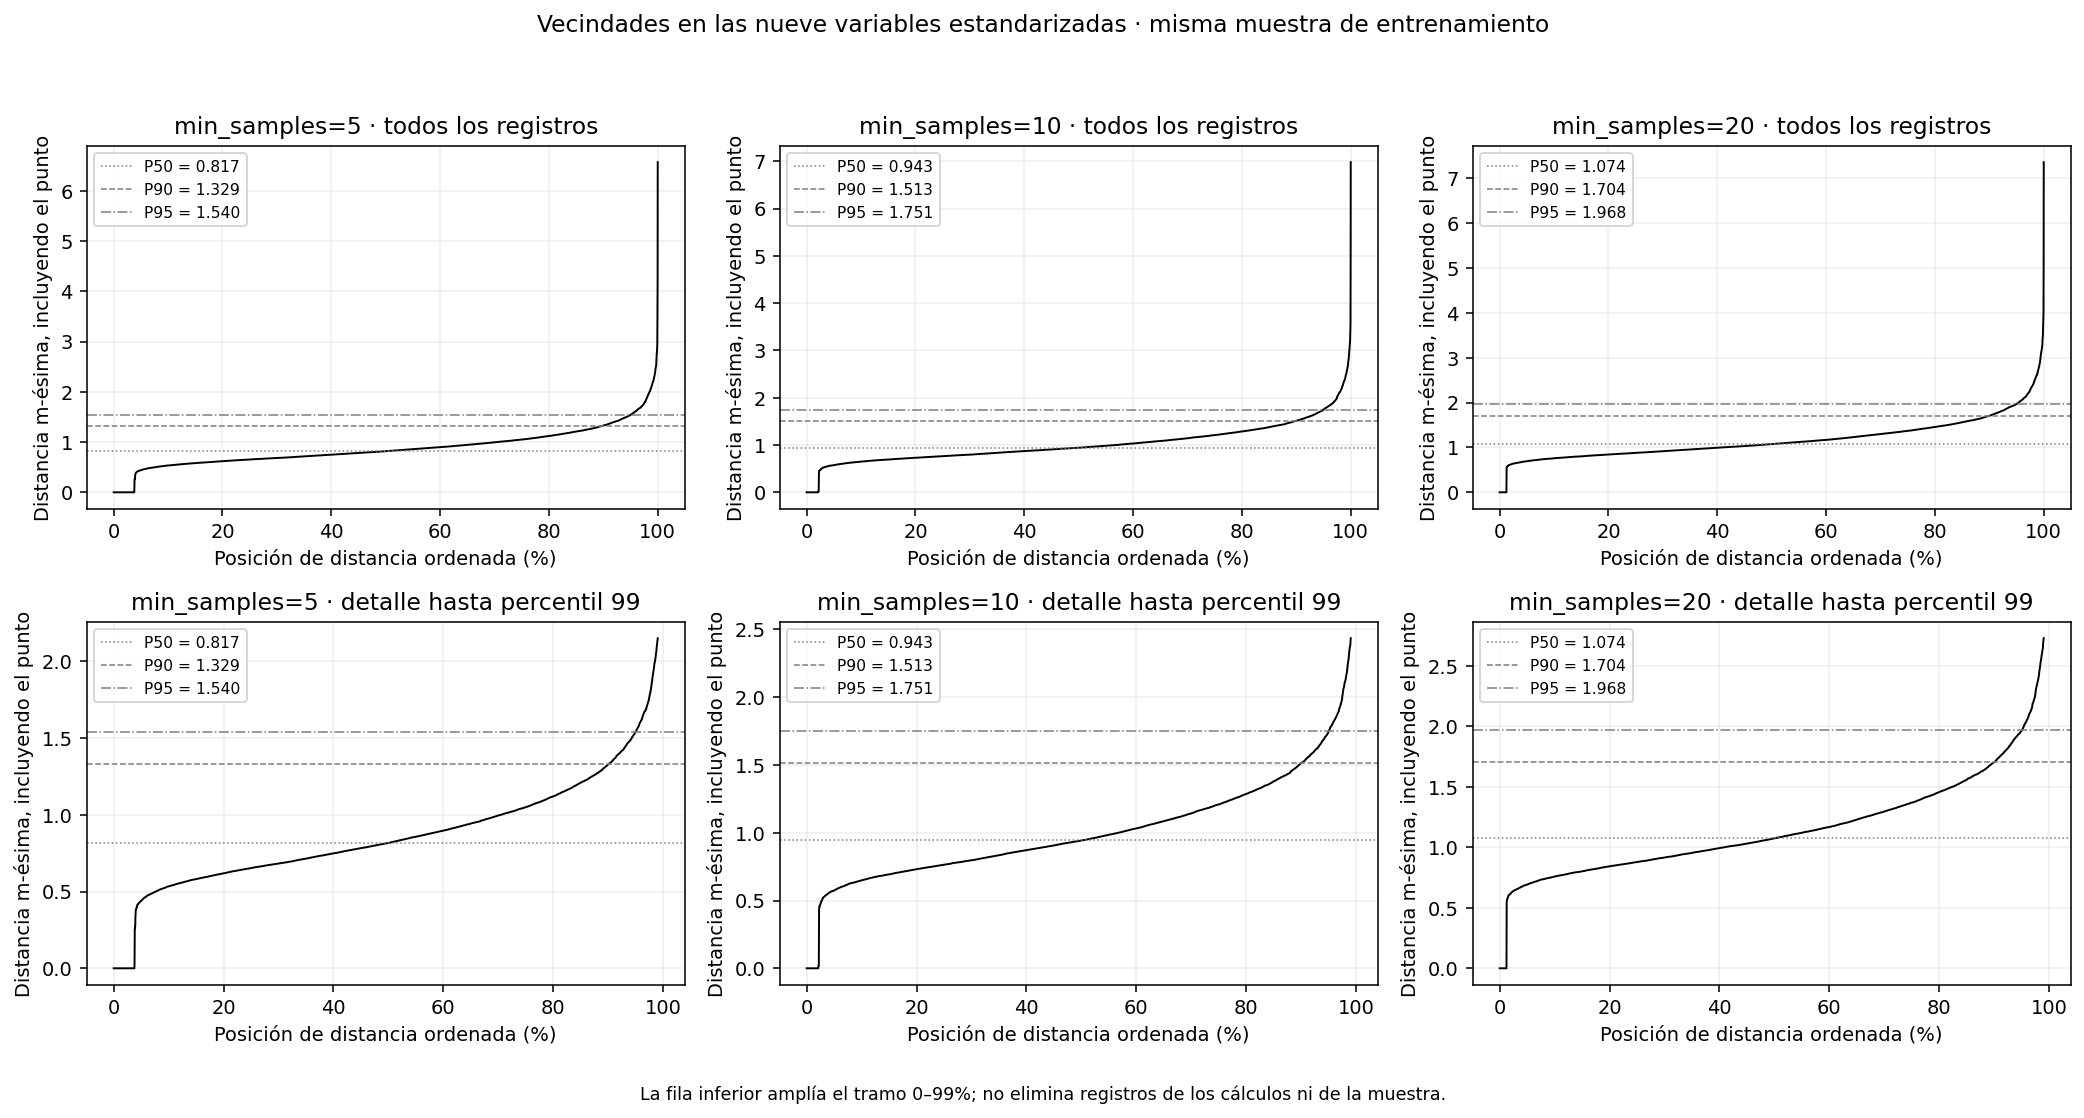

In [69]:
import matplotlib.pyplot as plt

fig_vecinos_dbscan_u3, ejes_vecinos_dbscan_u3 = plt.subplots(2, 3, figsize=(15, 8))
for columna, m in enumerate(MIN_SAMPLES_DBSCAN_U3):
    ordenadas = np.sort(distancias_m_dbscan_u3[m].to_numpy())
    posiciones = np.arange(1, len(ordenadas) + 1) / len(ordenadas) * 100
    for fila in [0, 1]:
        eje = ejes_vecinos_dbscan_u3[fila, columna]
        mascara = np.ones(len(ordenadas), dtype=bool) if fila == 0 else posiciones <= 99
        eje.plot(posiciones[mascara], ordenadas[mascara], color="black", linewidth=1)
        for q, estilo in [(0.50, ":"), (0.90, "--"), (0.95, "-.")]:
            eps = float(distancias_m_dbscan_u3[m].quantile(q))
            eje.axhline(eps, color="0.5", linestyle=estilo, linewidth=0.8, label=f"P{int(q*100)} = {eps:.3f}")
        eje.set(title=f"min_samples={m} · " + ("todos los registros" if fila == 0 else "detalle hasta percentil 99"),
            xlabel="Posición de distancia ordenada (%)", ylabel="Distancia m-ésima, incluyendo el punto")
        eje.grid(alpha=0.2)
        eje.legend(fontsize=8)
fig_vecinos_dbscan_u3.suptitle("Vecindades en las nueve variables estandarizadas · misma muestra de entrenamiento")
fig_vecinos_dbscan_u3.text(0.5, 0.01, "La fila inferior amplía el tramo 0–99%; no elimina registros de los cálculos ni de la muestra.", ha="center", fontsize=9)
fig_vecinos_dbscan_u3.tight_layout(rect=[0, 0.04, 1, 0.95])
display(fig_vecinos_dbscan_u3)
plt.close(fig_vecinos_dbscan_u3)

### Cómo leer las curvas

Se ordenan las distancias de menor a mayor únicamente para dibujarlas. El eje horizontal es posición o percentil, no tempo, ID ni cantidad de grupos. A la izquierda aparecen zonas con muchos vecinos cercanos; a la derecha, registros que necesitan un radio mayor para reunir m puntos.

Una subida más pronunciada puede orientar un rango de radios antes de incorporar zonas menos densas, pero no garantiza un único codo ni un valor óptimo. En datos con densidades diferentes puede no existir un radio global que separe todos los perfiles musicales.

La fila superior muestra todos los registros, incluidos extremos; la inferior permite leer hasta el percentil 99 sin que la cola comprima el resto del gráfico. **No se eliminó ese 1%**: sigue en cuantiles, planes y futuros ajustes. Las líneas son P50, P90 y P95; no umbrales de aprobación ni cortes elegidos por silhouette.

Al aumentar `min_samples`, normalmente hace falta más radio para reunir más puntos. Comparar m distintos con exactamente el mismo `eps` no equivale a exigir la misma densidad. Por eso definiremos radios a partir de la curva de cada m.

In [70]:
filas_plan_eps_dbscan_u3 = []
for m in MIN_SAMPLES_DBSCAN_U3:
    for q in CUANTILES_EPS_DBSCAN_U3:
        eps = float(distancias_m_dbscan_u3[m].quantile(q))
        if not np.isfinite(eps) or eps <= 0:
            raise ValueError("Un radio candidato no es positivo: revisar empates, no corregirlo silenciosamente.")
        nucleos_potenciales = int(distancias_m_dbscan_u3[m].le(eps).sum())
        filas_plan_eps_dbscan_u3.append({"min_samples": m, "Cuantil de origen": q,
            "eps": eps, "Núcleos potenciales": nucleos_potenciales,
            "% núcleos potenciales": nucleos_potenciales / len(distancias_m_dbscan_u3) * 100})
plan_eps_dbscan_detalle_u3 = pd.DataFrame(filas_plan_eps_dbscan_u3)
plan_eps_dbscan_u3 = plan_eps_dbscan_detalle_u3.drop_duplicates(["min_samples", "eps"]).copy()
plan_eps_dbscan_u3["Estado"] = "Candidato pendiente de ajuste"
display(plan_eps_dbscan_u3.round(6))
print(f"Configuraciones candidatas únicas: {len(plan_eps_dbscan_u3)}; todavía no hay etiquetas DBSCAN.")

Configuraciones candidatas únicas: 15; todavía no hay etiquetas DBSCAN.


,min_samples,Cuantil de origen,eps,Núcleos potenciales,% núcleos potenciales,Estado
0,5,0.50,0.816744,5000,50.00,Candidato pendiente de ajuste
1,5,0.70,0.995347,7000,70.00,Candidato pendiente de ajuste
2,5,0.80,1.120482,8000,80.00,Candidato pendiente de ajuste
3,5,0.90,1.328861,9000,90.00,Candidato pendiente de ajuste
4,5,0.95,1.539906,9500,95.00,Candidato pendiente de ajuste
5,10,0.50,0.942933,5000,50.00,Candidato pendiente de ajuste
6,10,0.70,1.142933,7000,70.00,Candidato pendiente de ajuste
7,10,0.80,1.286161,8000,80.00,Candidato pendiente de ajuste
8,10,0.90,1.513143,9001,90.01,Candidato pendiente de ajuste
9,10,0.95,1.750557,9500,95.00,Candidato pendiente de ajuste


### Qué significan los radios y el porcentaje de núcleos

Se recorre cada m y cada cuantil fijado: P50, P70, P80, P90 y P95. `quantile` produce un radio en la escala real de esa vecindad; solo se redondea al mostrarlo, no al guardarlo. Exigimos radio positivo y finito. Si los cuantiles producen el mismo radio, `drop_duplicates` evita ajustar dos veces el mismo par. No se añaden radios tras mirar resultados de agrupamiento.

La regla `distancia_m <= eps` identifica los IDs que reúnen al menos m registros dentro de eps, contando el propio punto. Es un diagnóstico de **núcleos potenciales** con métrica euclídea y pesos uniformes, no un ajuste de DBSCAN. Cerca de límites exactos puede existir una diferencia numérica mínima; después comprobaremos los núcleos del modelo ajustado.

Por ejemplo, un radio del P90 debería permitir que aproximadamente 90% de los puntos satisfaga esa condición; los empates y la interpolación pueden alterar el porcentaje exacto. **No es 90% de cobertura ni 10% de ruido:** un punto sin densidad propia puede ser frontera de un grupo. Tampoco informa cuántos grupos resultarán. Muchas zonas densas pueden conectarse en un grupo dominante.

Los cinco radios por cada m exploran desde zonas densas hasta mayor cobertura potencial. No se asume que P95 sea mejor por incluir más núcleos ni que P50 produzca playlists más específicas. `min_samples` controla densidad local; no fija exactamente el tamaño final de cada grupo ni cuántas canciones recibirá una playlist.

### Protocolo que queda definido

Se conserva la misma muestra, preparación y distancia euclídea, y se dejan hasta quince pares `(eps, min_samples)` para el siguiente bloque. No se escoge todavía un único par ganador. El próximo paso será ajustarlos y registrar número de grupos sin ruido, cobertura, ruido, proporción del grupo mayor, silhouette y Davies–Bouldin cuando se puedan calcular. El ruido no se tratará como un grupo musical.

Una silhouette alta con muy poca cobertura no bastará para superar a K-Means. Se revisarán tamaños, perfiles y posteriormente estabilidad con las submuestras agrupadas previstas. Si todos los candidatos producen resultados poco útiles, se informará sin borrar ruido o grupos para mejorar cifras; cualquier ampliación de búsqueda se documentará como otra exploración.

Los parámetros son específicos de la muestra y su escala. Reajustar con más registros cambia densidad y puede requerir revisar radios; no se trasladarán ciegamente a todo entrenamiento. DBSCAN todavía no se ajustó en este bloque: ajustar un índice de vecinos no equivale a producir grupos.

Referencias de implementación: [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html) y [NearestNeighbors](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html), documentación de scikit-learn.

### 27.2. Lectura de los resultados ejecutados



**min_samples=5:** P50=0.8167, P70=0.9953, P80=1.1205, P90=1.3289 y P95=1.5399. P99=2.1508 y máximo=6.5700; estos dos últimos describen la cola y no se añaden automáticamente como candidatos.

**min_samples=10:** P50=0.9429, P70=1.1429, P80=1.2862, P90=1.5131 y P95=1.7506. P99=2.4346 y máximo=6.9800; estos dos últimos describen la cola y no se añaden automáticamente como candidatos.

**min_samples=20:** P50=1.0741, P70=1.2960, P80=1.4569, P90=1.7043 y P95=1.9676. P99=2.7283 y máximo=7.3551; estos dos últimos describen la cola y no se añaden automáticamente como candidatos.

Se definieron **15 configuraciones únicas** y ninguna se presenta aún como ganadora. Los radios se calculan en nueve dimensiones estandarizadas: no se interpretan como distancia en un gráfico PCA ni como porcentaje de similitud. Los candidatos del P50 investigan zonas más densas y los del P95 admiten radios mayores; se necesita ajustar DBSCAN para conocer cobertura y grupos.

**Lectura de la forma observada:** las curvas muestran un aumento gradual y una cola final más pronunciada; no identificamos por esta inspección un único codo indiscutible. Por eso mantenemos varios radios candidatos en lugar de declarar uno óptimo. Los máximos (aproximadamente 6,57; 6,98 y 7,36) están bastante por encima de P95; usar el máximo solo para abarcar los extremos podría conectar zonas diferentes. No se usa como radio elegido ni se eliminan esos registros.

**Distancias cero:** 377 IDs tienen distancia m-ésima cero para m=5; 211 IDs tienen distancia m-ésima cero para m=10; 124 IDs tienen distancia m-ésima cero para m=20. No es solo la distancia de cada punto a sí mismo: para alcanzar esa posición con cero deben existir otros IDs con el mismo vector preparado. Es una limitación importante para interpretar densidad como diversidad de canciones. No implica IDs duplicados ni demuestra que sean exactamente la misma grabación; hay igualdad en estos nueve descriptores. No se borraron esos registros ni se cambió la muestra.


## 28. DBSCAN: ejecución de los quince candidatos

### 28.1. Qué se mantiene fijo

Ajustaremos los quince pares del bloque 27 sobre **la misma muestra preparada de 10.000 IDs y nueve variables**. No se cambian radios después de ver resultados, no se aprende otra escala y no se utiliza test. Cada ajuste contiene todas las versiones seleccionadas.

Registraremos grupos sin ruido, cobertura, ruido, tamaños, núcleos y métricas internas. Silhouette usa el panel común del bloque 23, excluyendo sus registros de ruido para cada candidato; Davies–Bouldin usa todos los IDs asignados de la muestra. Esto implica poblaciones diferentes entre candidatos y se informa su tamaño.

Para la inspección posterior consideraremos como evaluables los candidatos con al menos dos grupos reales y silhouette y Davies–Bouldin definidos. **Evaluable no significa adecuado para playlists.** Entre ellos se identificarán hasta tres casos distintos: el de mayor silhouette, el de mayor cobertura y el de menor dominio del grupo mayor entre asignados, con desempate por el orden de la tabla. Son representantes de distintos intercambios, no ganadores de un puntaje inventado. Si no hay evaluables, se inspeccionarán hasta tres con mayor cobertura, dejando explícita su insuficiencia.

In [71]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances
from threadpoolctl import threadpool_limits
from time import perf_counter
import warnings

if not X_muestra_cluster_escalada_u3.index.equals(g_muestra_cluster_u3.index):
    raise ValueError("La matriz y las claves no están alineadas.")
if len(plan_eps_dbscan_u3) != 15 or plan_eps_dbscan_u3.duplicated(["min_samples", "eps"]).any():
    raise ValueError("El plan no corresponde a los quince pares distintos.")
if not ids_panel_sil_cluster_u3.isin(X_muestra_cluster_escalada_u3.index).all():
    raise ValueError("El panel no pertenece a la muestra.")
with threadpool_limits(limits=1):
    distancias_panel_dbscan_u3 = pairwise_distances(
        X_muestra_cluster_escalada_u3.loc[ids_panel_sil_cluster_u3], metric="euclidean", n_jobs=1,
    )
np.fill_diagonal(distancias_panel_dbscan_u3, 0.0)
modelos_dbscan_busqueda_u3 = {}
etiquetas_dbscan_busqueda_u3 = {}
filas_resultados_dbscan_u3 = []
filas_tamanos_dbscan_u3 = []
for numero, (_, fila) in enumerate(plan_eps_dbscan_u3.iterrows(), start=1):
    candidato = f"D{numero:02d}"
    eps = float(fila["eps"])
    m = int(fila["min_samples"])
    modelo = DBSCAN(eps=eps, min_samples=m, metric="euclidean", algorithm="ball_tree", leaf_size=40, n_jobs=1)
    inicio = perf_counter()
    with warnings.catch_warnings(record=True) as avisos, threadpool_limits(limits=1):
        warnings.simplefilter("always")
        etiquetas = pd.Series(modelo.fit_predict(X_muestra_cluster_escalada_u3), index=X_muestra_cluster_escalada_u3.index, name="Grupo DBSCAN")
        asignadas = etiquetas.ne(-1)
        tamanos = etiquetas.loc[asignadas].value_counts().sort_index()
        n_asignadas = int(asignadas.sum())
        n_grupos = len(tamanos)
        etiquetas_panel = etiquetas.loc[ids_panel_sil_cluster_u3]
        mascara_panel = etiquetas_panel.ne(-1).to_numpy()
        ep = etiquetas_panel.loc[etiquetas_panel.ne(-1)]
        sil_valida = 2 <= ep.nunique() < len(ep)
        silhouette = silhouette_score(distancias_panel_dbscan_u3[np.ix_(mascara_panel, mascara_panel)], ep, metric="precomputed") if sil_valida else np.nan
        db_valido = 2 <= n_grupos < n_asignadas
        db = davies_bouldin_score(X_muestra_cluster_escalada_u3.loc[asignadas], etiquetas.loc[asignadas]) if db_valido else np.nan
    modelos_dbscan_busqueda_u3[candidato] = modelo
    etiquetas_dbscan_busqueda_u3[candidato] = etiquetas
    nucleos_esperados = int(distancias_m_dbscan_u3[m].le(eps).sum())
    filas_resultados_dbscan_u3.append({"Candidato": candidato, "eps": eps, "min_samples": m,
        "Cuantil": float(fila["Cuantil de origen"]), "Grupos sin ruido": n_grupos,
        "IDs asignados": n_asignadas, "Cobertura (%)": n_asignadas / len(etiquetas) * 100,
        "IDs ruido": int((~asignadas).sum()), "Ruido (%)": (~asignadas).mean() * 100,
        "Núcleos": len(modelo.core_sample_indices_), "Núcleos esperados": nucleos_esperados,
        "Diferencia núcleos": len(modelo.core_sample_indices_) - nucleos_esperados,
        "Grupo menor (IDs)": int(tamanos.min()) if n_grupos else 0,
        "Grupo mayor (% muestra)": tamanos.max() / len(etiquetas) * 100 if n_grupos else np.nan,
        "Grupo mayor (% asignados)": tamanos.max() / n_asignadas * 100 if n_asignadas else np.nan,
        "IDs panel sin ruido": len(ep), "Grupos en panel sin ruido": ep.nunique(),
        "Silhouette panel sin ruido": silhouette, "Davies–Bouldin sin ruido": db,
        "Motivo silhouette": "Definida" if sil_valida else "No hay entre 2 y N-1 grupos en panel sin ruido",
        "Motivo DB": "Definido" if db_valido else "No hay entre 2 y N-1 grupos sin ruido",
        "Avisos": "; ".join(str(a.message) for a in avisos), "Segundos ajuste y métricas": perf_counter() - inicio})
    for grupo, cantidad in etiquetas.value_counts().sort_index().items():
        filas_tamanos_dbscan_u3.append({"Candidato": candidato, "Grupo": int(grupo), "Es ruido": grupo == -1,
            "IDs": int(cantidad), "% muestra": cantidad / len(etiquetas) * 100})
    print(f"{candidato}: eps={eps:.4f}, min_samples={m}, {n_grupos} grupos, cobertura={n_asignadas/len(etiquetas):.2%}.", flush=True)
resultados_dbscan_busqueda_u3 = pd.DataFrame(filas_resultados_dbscan_u3)
tamanos_dbscan_busqueda_u3 = pd.DataFrame(filas_tamanos_dbscan_u3)
display(resultados_dbscan_busqueda_u3.round(5))
display(tamanos_dbscan_busqueda_u3.round(2))

D01: eps=0.8167, min_samples=5, 37 grupos, cobertura=62.07%.
D02: eps=0.9953, min_samples=5, 27 grupos, cobertura=80.00%.
D03: eps=1.1205, min_samples=5, 12 grupos, cobertura=88.07%.
D04: eps=1.3289, min_samples=5, 5 grupos, cobertura=94.53%.
D05: eps=1.5399, min_samples=5, 3 grupos, cobertura=97.40%.
D06: eps=0.9429, min_samples=10, 9 grupos, cobertura=67.20%.
D07: eps=1.1429, min_samples=10, 3 grupos, cobertura=83.51%.
D08: eps=1.2862, min_samples=10, 3 grupos, cobertura=90.78%.
D09: eps=1.5131, min_samples=10, 3 grupos, cobertura=96.26%.
D10: eps=1.7506, min_samples=10, 3 grupos, cobertura=98.11%.
D11: eps=1.0741, min_samples=20, 3 grupos, cobertura=71.05%.
D12: eps=1.2960, min_samples=20, 1 grupos, cobertura=86.51%.
D13: eps=1.4569, min_samples=20, 1 grupos, cobertura=92.63%.
D14: eps=1.7043, min_samples=20, 2 grupos, cobertura=97.25%.
D15: eps=1.9676, min_samples=20, 2 grupos, cobertura=98.47%.


,Candidato,eps,min_samples,Cuantil,Grupos sin ruido,IDs asignados,Cobertura (%),IDs ruido,Ruido (%),Núcleos,Núcleos esperados,Diferencia núcleos,Grupo menor (IDs),Grupo mayor (% muestra),Grupo mayor (% asignados),IDs panel sin ruido,Grupos en panel sin ruido,Silhouette panel sin ruido,Davies–Bouldin sin ruido,Motivo silhouette,Motivo DB,Avisos,Segundos ajuste y métricas
0,D01,0.81674,5,0.50,37,6207,62.07,3793,37.93,5000,5000,0,2,57.26,92.25068,1238,21,-0.23318,1.01811,Definida,Definido,,0.44097
1,D02,0.99535,5,0.70,27,8000,80.00,2000,20.00,7000,7000,0,3,78.55,98.18750,1595,19,-0.21584,0.93840,Definida,Definido,,0.37237
2,D03,1.12048,5,0.80,12,8807,88.07,1193,11.93,8000,8000,0,3,87.27,99.09163,1760,8,0.00248,1.06870,Definida,Definido,,0.38495
3,D04,1.32886,5,0.90,5,9453,94.53,547,5.47,9000,9000,0,5,93.77,99.19602,1876,3,0.40922,0.88645,Definida,Definido,,0.41590
4,D05,1.53991,5,0.95,3,9740,97.40,260,2.60,9500,9500,0,2,96.69,99.27105,1948,3,0.25558,0.68059,Definida,Definido,,0.45901
5,D06,0.94293,10,0.50,9,6720,67.20,3280,32.80,5000,5000,0,3,63.80,94.94048,1340,9,-0.09844,1.01405,Definida,Definido,,0.34903
6,D07,1.14293,10,0.70,3,8351,83.51,1649,16.49,7000,7000,0,5,83.33,99.78446,1660,3,0.06914,1.08994,Definida,Definido,,0.37820
7,D08,1.28616,10,0.80,3,9078,90.78,922,9.22,8000,8000,0,9,90.53,99.72461,1803,3,0.57914,1.06681,Definida,Definido,,0.40814
8,D09,1.51314,10,0.90,3,9626,96.26,374,3.74,8999,9001,-2,10,95.62,99.33513,1922,3,0.40445,0.58233,Definida,Definido,,0.44701
9,D10,1.75056,10,0.95,3,9811,98.11,189,1.89,9500,9500,0,21,97.26,99.13363,1960,3,0.35089,0.66814,Definida,Definido,,0.52357


,Candidato,Grupo,Es ruido,IDs,% muestra
0,D01,-1,True,3793,37.93
1,D01,0,False,5726,57.26
2,D01,1,False,26,0.26
3,D01,2,False,241,2.41
4,D01,3,False,9,0.09
5,D01,4,False,6,0.06
6,D01,5,False,13,0.13
7,D01,6,False,12,0.12
8,D01,7,False,6,0.06
9,D01,8,False,7,0.07


### Explicación del ajuste y las tablas

1. Se comprueba el plan de quince pares y el panel ya fijado. Las distancias del panel se calculan una vez; no es una matriz de toda la muestra. Su diagonal se deja en cero.
2. Cada par recibe un identificador D01–D15 siguiendo el orden del bloque 27. `DBSCAN` fija radio, densidad y distancia; no tiene una semilla de inicialización como K-Means. Los radios conservan toda su precisión interna.
3. `fit_predict` obtiene una etiqueta por ID. `ne(-1)` distingue asignados de ruido. `value_counts` cuenta solo grupos reales para tamaños, pero la tabla detallada conserva también el ruido, identificado expresamente.
4. `loc` conserva el orden del panel; la máscara extrae las mismas filas y columnas de sus distancias. Silhouette no incluye ruido como un grupo artificial. Se calcula solo si existe una partición válida. Davies–Bouldin se calcula sobre todos los asignados cuando hay al menos dos grupos reales. NaN es «no definido», no cero para imputar; se incluye el motivo.
5. `core_sample_indices_` cuenta núcleos del modelo y se contrasta con la condición del bloque 27. Una diferencia distinta de cero requiere revisar límites numéricos, no se oculta. Núcleos, asignados y cobertura no son sinónimos: los puntos frontera también pueden quedar asignados.
6. Cobertura = asignados/10.000; ruido = no asignados/10.000. «Grupo mayor (% muestra)» divide por 10.000; «% asignados» divide solo por asignados. El segundo permite detectar un grupo dominante aunque haya mucho ruido.
7. Los avisos se registran, no se silencian. El reloj incluye ajuste y métricas; los tiempos no son un benchmark controlado frente a K-Means. Los diccionarios conservan todos los modelos y etiquetas, no solo los casos con mejor apariencia.

Una silhouette elevada puede reflejar un grupo enorme separado de unos pocos nichos o extremos. No basta para afirmar que existe una buena organización del catálogo. Los grupos pequeños pueden ser nichos legítimos, pero requieren revisión de perfiles y estabilidad.

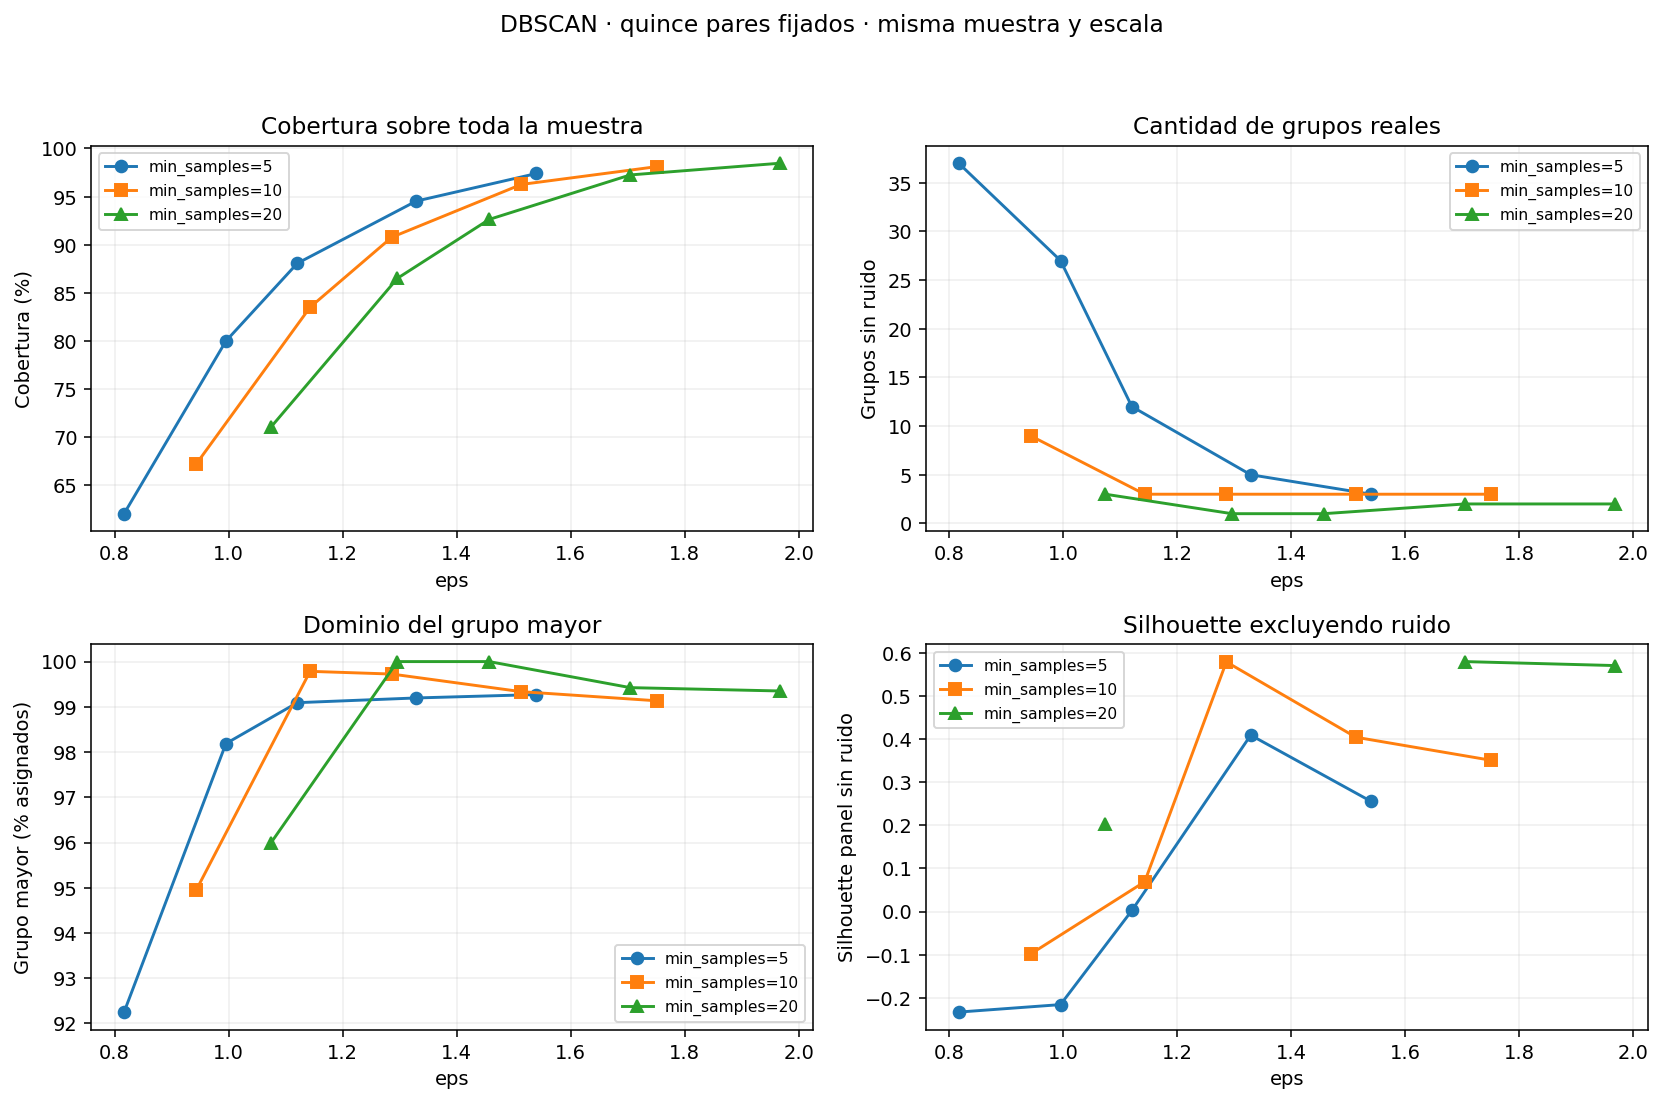

,eps,min_samples,Cuantil,Grupos sin ruido,IDs asignados,Cobertura (%),IDs ruido,Ruido (%),Núcleos,Núcleos esperados,Diferencia núcleos,Grupo menor (IDs),Grupo mayor (% muestra),Grupo mayor (% asignados),IDs panel sin ruido,Grupos en panel sin ruido,Silhouette panel sin ruido,Davies–Bouldin sin ruido,Motivo silhouette,Motivo DB,Avisos,Segundos ajuste y métricas,Motivo de inspección
Candidato,,,,,,,,,,,,,,,,,,,,,,,
D14,1.70428,20,0.90,2,9725,97.25,275,2.75,9000,9000,0,56,96.69,99.42416,1948,2,0.57986,0.49673,Definida,Definido,,0.49481,Mayor silhouette definida
D15,1.96761,20,0.95,2,9847,98.47,153,1.53,9500,9500,0,64,97.83,99.35006,1972,2,0.57062,0.51885,Definida,Definido,,0.57965,Mayor cobertura entre evaluables
D01,0.81674,5,0.50,37,6207,62.07,3793,37.93,5000,5000,0,2,57.26,92.25068,1238,21,-0.23318,1.01811,Definida,Definido,,0.44097,Menor dominio entre evaluables


In [72]:
import matplotlib.pyplot as plt

fig_resultados_dbscan_u3, ejes_resultados_dbscan_u3 = plt.subplots(2, 2, figsize=(12, 8))
for m, marcador in [(5, "o"), (10, "s"), (20, "^")]:
    datos = resultados_dbscan_busqueda_u3.loc[resultados_dbscan_busqueda_u3["min_samples"].eq(m)]
    for eje, columna, titulo in [
        (ejes_resultados_dbscan_u3[0, 0], "Cobertura (%)", "Cobertura sobre toda la muestra"),
        (ejes_resultados_dbscan_u3[0, 1], "Grupos sin ruido", "Cantidad de grupos reales"),
        (ejes_resultados_dbscan_u3[1, 0], "Grupo mayor (% asignados)", "Dominio del grupo mayor"),
        (ejes_resultados_dbscan_u3[1, 1], "Silhouette panel sin ruido", "Silhouette excluyendo ruido"),
    ]:
        eje.plot(datos["eps"], datos[columna], marker=marcador, label=f"min_samples={m}")
        eje.set(title=titulo, xlabel="eps", ylabel=columna)
        eje.grid(alpha=0.2)
        eje.legend(fontsize=8)
fig_resultados_dbscan_u3.suptitle("DBSCAN · quince pares fijados · misma muestra y escala")
fig_resultados_dbscan_u3.tight_layout(rect=[0, 0, 1, 0.95])
display(fig_resultados_dbscan_u3)
plt.close(fig_resultados_dbscan_u3)

evaluables_dbscan_u3 = resultados_dbscan_busqueda_u3.loc[
    resultados_dbscan_busqueda_u3["Grupos sin ruido"].ge(2) &
    resultados_dbscan_busqueda_u3["Silhouette panel sin ruido"].notna() &
    resultados_dbscan_busqueda_u3["Davies–Bouldin sin ruido"].notna()
].copy()
seleccion_inspeccion_dbscan_u3 = []
motivos_inspeccion_dbscan_u3 = {}
if len(evaluables_dbscan_u3):
    for columna, ascendente, motivo in [
        ("Silhouette panel sin ruido", False, "Mayor silhouette definida"),
        ("Cobertura (%)", False, "Mayor cobertura entre evaluables"),
        ("Grupo mayor (% asignados)", True, "Menor dominio entre evaluables"),
    ]:
        elegido = evaluables_dbscan_u3.sort_values(columna, ascending=ascendente, kind="stable").iloc[0]["Candidato"]
        if elegido not in seleccion_inspeccion_dbscan_u3:
            seleccion_inspeccion_dbscan_u3.append(elegido)
            motivos_inspeccion_dbscan_u3[elegido] = motivo
        else:
            motivos_inspeccion_dbscan_u3[elegido] += "; " + motivo
else:
    seleccion_inspeccion_dbscan_u3 = resultados_dbscan_busqueda_u3.sort_values("Cobertura (%)", ascending=False, kind="stable").head(3)["Candidato"].tolist()
    motivos_inspeccion_dbscan_u3 = {c: "Diagnóstico por cobertura; sin métricas internas evaluables" for c in seleccion_inspeccion_dbscan_u3}
candidatos_inspeccion_dbscan_u3 = resultados_dbscan_busqueda_u3.set_index("Candidato").loc[seleccion_inspeccion_dbscan_u3].copy()
candidatos_inspeccion_dbscan_u3["Motivo de inspección"] = pd.Series(motivos_inspeccion_dbscan_u3)
display(candidatos_inspeccion_dbscan_u3.round(5))

### Cómo se eligen los casos para inspección

Los gráficos mantienen las quince configuraciones y muestran sus intercambios: cubrir más no implica crear más grupos ni grupos más equilibrados. Una métrica no definida deja un hueco; no se dibuja un cero inventado. Los valores de eps son los propios de cada curva de vecinos, no un mismo radio usado para todos los m.

El filtro `ge(2)` y `notna` identifica casos evaluables. No introduce un KPI de aprobación. Los recorridos seleccionan los extremos informativos previstos y evitan repetir el mismo caso cuando satisface varios motivos. El criterio de mayor cobertura se aplica solo entre evaluables para no confundir un único grupo que cubra todo con una solución útil.

Estos candidatos se inspeccionarán aunque muestren limitaciones. La selección es descriptiva sobre entrenamiento y no constituye confirmación independiente ni búsqueda anidada. No se declara ganador a quien obtenga la silhouette más alta sin revisar cobertura, dominio, perfiles y estabilidad.

## 29. DBSCAN: inspección de candidatos, perfiles y estabilidad

### 29.1. Casos informativos, no aprobación automática

El bloque 28 seleccionó casos por separación, cobertura y menor dominio del grupo mayor. Los inspeccionaremos aunque su estructura no resulte útil: «evaluable» no significa «razonable para crear playlists». No se cambiarán parámetros tras observar sus resultados.

La estabilidad usa tres submuestras reproducibles del 80% de las claves de la muestra original, conservando todas sus versiones. Se reutiliza **la preparación fija de referencia** para aislar cambios de densidad; esto no evalúa todo el Pipeline bajo nuevo muestreo ni mide generalización. El resto de entrenamiento y test no intervienen.

In [73]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score
from sklearn.base import clone
from threadpoolctl import threadpool_limits

filas_limites_nucleos_u3 = []
for _, fila in resultados_dbscan_busqueda_u3.loc[resultados_dbscan_busqueda_u3["Diferencia núcleos"].ne(0)].iterrows():
    candidato = fila["Candidato"]
    m, eps = int(fila["min_samples"]), float(fila["eps"])
    esperado = distancias_m_dbscan_u3[m].le(eps).to_numpy()
    real = np.zeros(len(X_muestra_cluster_escalada_u3), dtype=bool)
    real[modelos_dbscan_busqueda_u3[candidato].core_sample_indices_] = True
    posiciones = np.flatnonzero(esperado != real)
    indice = NearestNeighbors(radius=eps, metric="euclidean", algorithm="ball_tree", leaf_size=40, n_jobs=1).fit(X_muestra_cluster_escalada_u3)
    consultas = X_muestra_cluster_escalada_u3.iloc[posiciones]
    radios = [np.nextafter(eps, 0), eps, np.nextafter(eps, np.inf)]
    with threadpool_limits(limits=1):
        conteos = [[len(v) for v in indice.radius_neighbors(consultas, radius=radio, return_distance=False)] for radio in radios]
    for j, posicion in enumerate(posiciones):
        filas_limites_nucleos_u3.append({"Candidato": candidato, "ID": X_muestra_cluster_escalada_u3.index[posicion],
            "eps": eps, "distancia m": distancias_m_dbscan_u3.iloc[posicion][m],
            "distancia m menos eps": distancias_m_dbscan_u3.iloc[posicion][m] - eps,
            "Núcleo según distancia": bool(esperado[posicion]), "Núcleo real": bool(real[posicion]),
            "Vecinos radio inmediatamente inferior": conteos[0][j], "Vecinos eps": conteos[1][j],
            "Vecinos radio inmediatamente superior": conteos[2][j]})
revision_limites_nucleos_u3 = pd.DataFrame(filas_limites_nucleos_u3)
display(revision_limites_nucleos_u3)
print("Los radios y las etiquetas originales se conservan; el diagnóstico no corrige el ajuste.")

Los radios y las etiquetas originales se conservan; el diagnóstico no corrige el ajuste.


,Candidato,ID,eps,distancia m,distancia m menos eps,Núcleo según distancia,Núcleo real,Vecinos radio inmediatamente inferior,Vecinos eps,Vecinos radio inmediatamente superior
0,D09,58Mh6zmqSo9IvysPAXnG0h,1.513143,1.513143,0.0,True,False,9,9,10
1,D09,68BrsbxdeKZcG9JcxOhlOR,1.513143,1.513143,0.0,True,False,9,9,10


### Explicación de la comprobación de límites

Se revisan solo candidatos donde no coincide el conteo esperado de núcleos con el modelo. `core_sample_indices_` construye la máscara real; la comparación con `distancia_m <= eps` localiza exactamente los registros discrepantes.

El índice de vecinos se consulta solo para esos IDs. `nextafter` toma el número representable inmediatamente inferior o superior al radio, para detectar sensibilidad numérica justo en el límite. Se cuentan vecinos con esos radios y con el original; los valores se muestran sin redondear el radio de los modelos. No se modifica `eps`, etiquetas o métricas para forzar coincidencia.

Si la distancia m-ésima y el radio coinciden o están a precisión de máquina, dos procedimientos de consulta pueden resolver un límite numérico de forma diferente. El conteo **real del modelo** sigue siendo el que se informa. La tabla permite contrastar esta explicación en vez de ocultar la diferencia. No es evidencia de fuga de información ni de que dos canciones cambien de clase de popularidad.

In [74]:
perfiles_dbscan_inspeccion_z_u3 = {}
perfiles_dbscan_inspeccion_original_u3 = {}
dispersion_dbscan_inspeccion_u3 = {}
resumen_grupos_dbscan_inspeccion_u3 = {}
filas_rasgos_dbscan_u3 = []
filas_ejemplos_dbscan_u3 = []
for candidato in seleccion_inspeccion_dbscan_u3:
    etiquetas = etiquetas_dbscan_busqueda_u3[candidato]
    asignadas = etiquetas.ne(-1)
    perfiles_z = X_muestra_cluster_escalada_u3.loc[asignadas].groupby(etiquetas.loc[asignadas]).mean()
    perfiles = X_muestra_cluster_imputada_u3.loc[asignadas].groupby(etiquetas.loc[asignadas]).mean()
    dispersion = X_muestra_cluster_imputada_u3.loc[asignadas].groupby(etiquetas.loc[asignadas]).std(ddof=0)
    resumen = pd.DataFrame({"IDs": etiquetas.loc[asignadas].value_counts().sort_index()})
    resumen["% muestra"] = resumen["IDs"] / len(etiquetas) * 100
    resumen["% asignados"] = resumen["IDs"] / asignadas.sum() * 100
    resumen["Claves distintas"] = g_muestra_cluster_u3.loc[asignadas].groupby(etiquetas.loc[asignadas]).nunique()
    resumen["Tempo imputado (%)"] = X_muestra_cluster_u3.loc[asignadas, "tempo"].isna().groupby(etiquetas.loc[asignadas]).mean() * 100
    perfiles_dbscan_inspeccion_z_u3[candidato] = perfiles_z
    perfiles_dbscan_inspeccion_original_u3[candidato] = perfiles
    dispersion_dbscan_inspeccion_u3[candidato] = dispersion
    resumen_grupos_dbscan_inspeccion_u3[candidato] = resumen
    for grupo, medias in perfiles_z.iterrows():
        for variable in medias.abs().nlargest(3).index:
            filas_rasgos_dbscan_u3.append({"Candidato": candidato, "Grupo": grupo, "Variable": variable,
                "Media z": medias[variable], "Media original": perfiles.loc[grupo, variable],
                "DE interna original": dispersion.loc[grupo, variable]})
    grupos_ejemplos = resumen.sort_values("IDs", ascending=False, kind="stable").head(3).index.tolist()
    if len(resumen):
        menor = resumen["IDs"].idxmin()
        if menor not in grupos_ejemplos:
            grupos_ejemplos.append(menor)
    claves_usadas = set()
    audios_usados = set()
    for grupo in grupos_ejemplos:
        ids_grupo = etiquetas.index[etiquetas.eq(grupo)]
        distancias = np.linalg.norm(X_muestra_cluster_escalada_u3.loc[ids_grupo].to_numpy() - perfiles_z.loc[grupo].to_numpy(), axis=1)
        candidatas = pd.DataFrame({"Distancia a media descriptiva": distancias, "Clave": g_muestra_cluster_u3.loc[ids_grupo], "ID": ids_grupo.astype(str)}, index=ids_grupo)
        elegidas = 0
        for id_cancion, fila in candidatas.sort_values(["Distancia a media descriptiva", "ID"], kind="stable").iterrows():
            audio = tuple(X_muestra_cluster_imputada_u3.loc[id_cancion].to_numpy())
            if fila["Clave"] in claves_usadas or audio in audios_usados:
                continue
            artista, separador, titulo = fila["Clave"].partition(" || ")
            if not separador:
                raise ValueError("Clave inválida al recuperar nombres.")
            filas_ejemplos_dbscan_u3.append({"Candidato": candidato, "Grupo": grupo, "ID": id_cancion,
                "Clave": fila["Clave"], "Artista normalizado": artista, "Título normalizado": titulo,
                "Distancia a media descriptiva": fila["Distancia a media descriptiva"],
                "Tempo imputado": bool(pd.isna(X_muestra_cluster_u3.loc[id_cancion, "tempo"])),
                "Enlace Spotify": "https://open.spotify.com/track/" + str(id_cancion)})
            claves_usadas.add(fila["Clave"]); audios_usados.add(audio); elegidas += 1
            if elegidas == 2:
                break
    print(candidato + ": tamaños y medias originales de TODOS sus grupos sin ruido")
    display(resumen.round(3))
    display(perfiles.round(4))
rasgos_dbscan_inspeccion_u3 = pd.DataFrame(filas_rasgos_dbscan_u3)
ejemplos_dbscan_inspeccion_u3 = pd.DataFrame(filas_ejemplos_dbscan_u3)
display(rasgos_dbscan_inspeccion_u3.round(4))
display(ejemplos_dbscan_inspeccion_u3.round(4))

D14: tamaños y medias originales de TODOS sus grupos sin ruido
D15: tamaños y medias originales de TODOS sus grupos sin ruido
D01: tamaños y medias originales de TODOS sus grupos sin ruido


,IDs,% muestra,% asignados,Claves distintas,Tempo imputado (%)
Grupo DBSCAN,,,,,
0,9669,96.69,99.424,8711,0.021
1,56,0.56,0.576,56,0.000


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Grupo DBSCAN,,,,,,,,,
0,0.5652,0.6330,-8.3491,0.0768,0.3231,0.1677,0.2028,0.4710,122.3579
1,0.5711,0.7599,-9.8928,0.9206,0.7975,0.0000,0.8169,0.4204,90.2030


,IDs,% muestra,% asignados,Claves distintas,Tempo imputado (%)
Grupo DBSCAN,,,,,
0,9783,97.83,99.35,8819,0.041
1,64,0.64,0.65,64,0.000


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Grupo DBSCAN,,,,,,,,,
0,0.5642,0.632,-8.3935,0.0783,0.3240,0.1711,0.2053,0.4699,122.4019
1,0.5667,0.763,-9.8423,0.9105,0.7992,0.0000,0.7991,0.4165,90.2768


,IDs,% muestra,% asignados,Claves distintas,Tempo imputado (%)
Grupo DBSCAN,,,,,
0,5726,57.26,92.251,5026,0.0
1,26,0.26,0.419,1,0.0
2,241,2.41,3.883,235,0.0
3,9,0.09,0.145,9,0.0
4,6,0.06,0.097,1,0.0
5,13,0.13,0.209,2,0.0
6,12,0.12,0.193,12,0.0
7,6,0.06,0.097,3,0.0
8,7,0.07,0.113,7,0.0


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Grupo DBSCAN,,,,,,,,,
0,0.5873,0.6691,-7.0935,0.0571,0.2747,0.0669,0.1586,0.4934,121.6154
1,0.4840,0.3320,-10.3120,0.0370,0.7870,0.0000,0.3730,0.6830,134.9990
2,0.3018,0.0966,-23.3475,0.0441,0.9443,0.8952,0.1083,0.1225,97.9089
3,0.6069,0.8166,-7.9537,0.0464,0.0165,0.5584,0.1592,0.4591,97.7299
4,0.6760,0.3380,-7.9600,0.0284,0.3720,0.0000,0.4680,0.3210,92.0290
5,0.8668,0.5805,-5.3299,0.0684,0.0929,0.0014,0.3037,0.5658,94.8487
6,0.2150,0.9798,-4.6484,0.1175,0.0002,0.7973,0.3039,0.0899,113.0057
7,0.6202,0.6825,-5.4963,0.0365,0.1524,0.0001,0.5753,0.6633,104.7530
8,0.3011,0.1808,-20.3629,0.0443,0.9559,0.9196,0.1003,0.1933,164.5370


,Candidato,Grupo,Variable,Media z,Media original,DE interna original
0,D14,0,speechiness,-0.0916,0.0768,0.0740
1,D14,0,liveness,-0.0655,0.2028,0.1732
2,D14,0,loudness,0.0315,-8.3491,4.9821
3,D14,1,speechiness,7.5672,0.9206,0.0400
4,D14,1,liveness,3.1422,0.8169,0.1170
5,D14,1,acousticness,1.3815,0.7975,0.0808
6,D15,0,speechiness,-0.0779,0.0783,0.0770
7,D15,0,liveness,-0.0522,0.2053,0.1765
8,D15,0,loudness,0.0229,-8.3935,5.0317
9,D15,1,speechiness,7.4753,0.9105,0.0540


,Candidato,Grupo,ID,Clave,Artista normalizado,Título normalizado,Distancia a media descriptiva,Tempo imputado,Enlace Spotify
0,D14,0,1cgy2FSOQMbq7DHCVgMAUA,lost frequencies;james arthur || questions,lost frequencies;james arthur,questions,0.8439,False,https://open.spotify.com/track/1cgy2FSOQMbq7DHCVgMAUA
1,D14,0,2cgCsP1m4K4tilrfRw9nM3,cassiane || não posso desistir,cassiane,não posso desistir,0.9454,False,https://open.spotify.com/track/2cgCsP1m4K4tilrfRw9nM3
2,D14,1,36RDt4tcwMGggg0GqIs7YZ,"chad daniels || rock, paper, scissors, jesus",chad daniels,"rock, paper, scissors, jesus",0.9142,False,https://open.spotify.com/track/36RDt4tcwMGggg0GqIs7YZ
3,D14,1,251W7xD4sW3iPIvig9W2yb,ryan sickler || we got a joint!,ryan sickler,we got a joint!,0.9222,False,https://open.spotify.com/track/251W7xD4sW3iPIvig9W2yb
4,D15,0,1cgy2FSOQMbq7DHCVgMAUA,lost frequencies;james arthur || questions,lost frequencies;james arthur,questions,0.8542,False,https://open.spotify.com/track/1cgy2FSOQMbq7DHCVgMAUA
5,D15,0,2cgCsP1m4K4tilrfRw9nM3,cassiane || não posso desistir,cassiane,não posso desistir,0.9577,False,https://open.spotify.com/track/2cgCsP1m4K4tilrfRw9nM3
6,D15,1,36RDt4tcwMGggg0GqIs7YZ,"chad daniels || rock, paper, scissors, jesus",chad daniels,"rock, paper, scissors, jesus",0.8325,False,https://open.spotify.com/track/36RDt4tcwMGggg0GqIs7YZ
7,D15,1,7FUYnd7l379jFnwFYTvR4b,andrew norelli || l gaga,andrew norelli,l gaga,0.8990,False,https://open.spotify.com/track/7FUYnd7l379jFnwFYTvR4b
8,D01,0,2jvZdz0iA6cSQHOASmMZhW,la grande sophie || missive,la grande sophie,missive,0.6536,False,https://open.spotify.com/track/2jvZdz0iA6cSQHOASmMZhW
9,D01,0,2H5H81MQ9TxLuqitJDlPtz,juninho black || faz-me respirar,juninho black,faz-me respirar,0.6582,False,https://open.spotify.com/track/2H5H81MQ9TxLuqitJDlPtz


### Explicación de perfiles y ejemplos

Los diccionarios guardan perfiles por candidato, sin mezclar números de grupo entre modelos. Se excluye ruido para describir grupos reales, pero su cantidad permanece en el bloque anterior. `groupby().mean()` calcula medias en escala común y unidades originales; `std(ddof=0)` describe variación interna, no incertidumbre del promedio.

Las proporciones distinguen población total y asignada. `nunique()` cuenta claves distintas para no confundir muchos IDs con muchas canciones independientes. La marca de tempo informa dónde la media incorpora valores imputados.

Los tres rasgos más alejados en valor absoluto describen contrastes respecto a la muestra, conservando el signo. No son importancias predictivas ni nombres de géneros. Un grupo mayor con medias próximas a las globales puede mezclar muchos perfiles musicales; una media general no asegura una playlist coherente.

Se muestran ejemplos de hasta cuatro grupos por candidato: los tres mayores y el menor, si no estaba incluido. Las tablas de perfiles sí conservan TODOS los grupos. Se eligen hasta dos ejemplos por grupo próximos a su media descriptiva y sin repetir claves o vectores de audio exactos dentro del candidato. Si faltan ejemplos distintos no se inventan ni repiten: se conservará la cantidad disponible. Un mismo ejemplo puede aparecer en candidatos distintos porque son alternativas.

**DBSCAN no aprende centros:** la media se calcula solo para describir y seleccionar ejemplos. En grupos no convexos puede caer fuera de una zona densa; proximidad a esa media no garantiza representación de todos sus sectores. No se usó la distancia a esa media para formar grupos. Los enlaces y nombres sirven para una revisión posterior; no se ha escuchado el audio ni confirmado un estilo.

In [75]:
SEMILLAS_SUBMUESTRA_DBSCAN_U3 = [42, 43, 44]
claves_base_estabilidad_dbscan_u3 = np.array(sorted(g_muestra_cluster_u3.unique()))
cantidad_claves_estabilidad_dbscan_u3 = int(np.floor(0.80 * len(claves_base_estabilidad_dbscan_u3)))
ids_submuestras_dbscan_u3 = {}
for semilla in SEMILLAS_SUBMUESTRA_DBSCAN_U3:
    claves = np.random.default_rng(semilla).choice(claves_base_estabilidad_dbscan_u3, size=cantidad_claves_estabilidad_dbscan_u3, replace=False)
    ids = g_muestra_cluster_u3.index[g_muestra_cluster_u3.isin(claves)]
    if not set(ids).issubset(set(X_muestra_cluster_escalada_u3.index)):
        raise ValueError("La submuestra salió de la muestra de entrenamiento.")
    for clave in claves:
        if set(ids[g_muestra_cluster_u3.loc[ids].eq(clave)]) != set(g_muestra_cluster_u3.index[g_muestra_cluster_u3.eq(clave)]):
            raise ValueError("Se separaron versiones en una submuestra.")
    ids_submuestras_dbscan_u3[semilla] = ids
filas_estabilidad_dbscan_u3 = []
etiquetas_submuestras_dbscan_u3 = {}
for candidato in seleccion_inspeccion_dbscan_u3:
    for semilla, ids in ids_submuestras_dbscan_u3.items():
        modelo = clone(modelos_dbscan_busqueda_u3[candidato])
        with threadpool_limits(limits=1):
            nueva = pd.Series(modelo.fit_predict(X_muestra_cluster_escalada_u3.loc[ids]), index=ids)
        referencia = etiquetas_dbscan_busqueda_u3[candidato].loc[ids]
        ref_asignada, nueva_asignada = referencia.ne(-1), nueva.ne(-1)
        ambas = ref_asignada & nueva_asignada
        ari_valido = ambas.sum() > 1 and 2 <= referencia.loc[ambas].nunique() < ambas.sum() and 2 <= nueva.loc[ambas].nunique() < ambas.sum()
        ari = adjusted_rand_score(referencia.loc[ambas], nueva.loc[ambas]) if ari_valido else np.nan
        tamanos = nueva.loc[nueva_asignada].value_counts()
        filas_estabilidad_dbscan_u3.append({"Candidato": candidato, "Semilla submuestra": semilla,
            "Claves": g_muestra_cluster_u3.loc[ids].nunique(), "IDs comunes": len(ids),
            "Grupos nuevos sin ruido": nueva.loc[nueva_asignada].nunique(),
            "Cobertura nueva (%)": nueva_asignada.mean() * 100,
            "Grupo mayor nuevo (% asignados)": tamanos.max() / nueva_asignada.sum() * 100 if nueva_asignada.any() else np.nan,
            "Asignados en ambos": int(ambas.sum()), "Cobertura comparación ARI (%)": ambas.mean() * 100,
            "Ruido en ambos": int((~ref_asignada & ~nueva_asignada).sum()),
            "Asignado a ruido": int((ref_asignada & ~nueva_asignada).sum()),
            "Ruido a asignado": int((~ref_asignada & nueva_asignada).sum()),
            "ARI solo asignados comunes": ari,
            "Motivo ARI": "Definido" if ari_valido else "No hay al menos dos grupos válidos en ambas particiones de la intersección"})
        etiquetas_submuestras_dbscan_u3[(candidato, semilla)] = nueva
        print(f"Estabilidad {candidato}, semilla de submuestra {semilla}: {len(ids)} IDs, cobertura {nueva_asignada.mean():.2%}.", flush=True)
estabilidad_dbscan_inspeccion_u3 = pd.DataFrame(filas_estabilidad_dbscan_u3)
resumen_estabilidad_dbscan_u3 = estabilidad_dbscan_inspeccion_u3.groupby("Candidato").agg(
    ARI_medio=("ARI solo asignados comunes", "mean"), ARI_minimo=("ARI solo asignados comunes", "min"),
    ARI_definidos=("ARI solo asignados comunes", "count"), Rondas=("Semilla submuestra", "size"),
    Cobertura_media=("Cobertura nueva (%)", "mean"), Cobertura_minima=("Cobertura nueva (%)", "min"),
    Dominio_medio=("Grupo mayor nuevo (% asignados)", "mean"),
    Asignados_a_ruido_total=("Asignado a ruido", "sum"),
)
display(estabilidad_dbscan_inspeccion_u3.round(5))
display(resumen_estabilidad_dbscan_u3.round(5))

Estabilidad D14, semilla de submuestra 42: 8029 IDs, cobertura 96.10%.
Estabilidad D14, semilla de submuestra 43: 7976 IDs, cobertura 96.79%.
Estabilidad D14, semilla de submuestra 44: 7993 IDs, cobertura 96.58%.
Estabilidad D15, semilla de submuestra 42: 8029 IDs, cobertura 97.99%.
Estabilidad D15, semilla de submuestra 43: 7976 IDs, cobertura 98.23%.
Estabilidad D15, semilla de submuestra 44: 7993 IDs, cobertura 98.21%.
Estabilidad D01, semilla de submuestra 42: 8029 IDs, cobertura 59.45%.
Estabilidad D01, semilla de submuestra 43: 7976 IDs, cobertura 58.90%.
Estabilidad D01, semilla de submuestra 44: 7993 IDs, cobertura 58.86%.


,Candidato,Semilla submuestra,Claves,IDs comunes,Grupos nuevos sin ruido,Cobertura nueva (%),Grupo mayor nuevo (% asignados),Asignados en ambos,Cobertura comparación ARI (%),Ruido en ambos,Asignado a ruido,Ruido a asignado,ARI solo asignados comunes,Motivo ARI
0,D14,42,7224,8029,1,96.10163,100.00000,7716,96.10163,226,87,0,NaN,No hay al menos dos grupos válidos en ambas particiones de la intersección
1,D14,43,7224,7976,2,96.79037,99.46891,7720,96.79037,218,38,0,1.00000,Definido
2,D14,44,7224,7993,2,96.58451,99.43005,7720,96.58451,225,48,0,1.00000,Definido
3,D15,42,7224,8029,2,97.99477,99.54245,7868,97.99477,131,30,0,1.00000,Definido
4,D15,43,7224,7976,2,98.23220,99.36184,7835,98.23220,128,13,0,1.00000,Definido
5,D15,44,7224,7993,2,98.21093,99.29936,7850,98.21093,122,21,0,1.00000,Definido
6,D01,42,7224,8029,36,59.44700,85.94176,4773,59.44700,3013,243,0,0.61521,Definido
7,D01,43,7224,7976,37,58.90171,84.16347,4698,58.90171,3030,248,0,0.54702,Definido
8,D01,44,7224,7993,33,58.86401,85.39851,4705,58.86401,3020,268,0,0.59223,Definido


,ARI_medio,ARI_minimo,ARI_definidos,Rondas,Cobertura_media,Cobertura_minima,Dominio_medio,Asignados_a_ruido_total
Candidato,,,,,,,,
D01,0.58482,0.54702,3,3,59.07091,58.86401,85.16791,759
D14,1.00000,1.00000,2,3,96.49217,96.10163,99.63299,173
D15,1.00000,1.00000,3,3,98.14597,97.99477,99.40122,64


### Explicación de estabilidad y sus denominadores

Se ordenan las claves y se sortean tres conjuntos con 80% de ellas sin reemplazo. La cantidad de IDs varía porque las claves contienen distinto número de versiones. No se muestrea por popularidad ni por etiquetas DBSCAN; las mismas tres submuestras se usan para todos los candidatos.

Los controles exigen que cada clave seleccionada conserve todos sus IDs de la muestra. `clone` recupera parámetros fijos sin conservar el ajuste y `fit_predict` reajusta DBSCAN sobre la submuestra estandarizada. La semilla controla la selección de datos, no una inicialización de DBSCAN. No se retocan eps o min_samples cuando baja densidad.

La referencia se restringe a esos mismos IDs. Las máscaras distinguen cuatro situaciones: asignado en ambos, ruido en ambos, asignado que pasa a ruido y ruido que pasa a asignado. Sus conteos deben sumar los IDs comunes. El ARI se calcula únicamente en asignados en ambos y exige al menos dos grupos válidos en cada partición; si no, se registra NaN y motivo, evitando celebrar ARI=1 por un único grupo.

La cobertura de comparación ARI divide los asignados en ambos por los IDs comunes, no por 10.000. La cobertura nueva divide todos los asignados nuevos por esos mismos IDs. Un ARI alto sobre pocos registros puede ocultar cambios a ruido; por eso se muestran ambas coberturas y transiciones.

La media y el mínimo resumen hasta tres ARI definidos e indican cuántos fueron posibles. No son intervalos de confianza ni tres evaluaciones independientes: comparten datos y una misma referencia. El total de transiciones suma eventos de las tres submuestras, no canciones únicas. Mantener preparación fija permite observar sensibilidad de densidad, no robustez completa frente a aprender nuevas medianas y escalas.

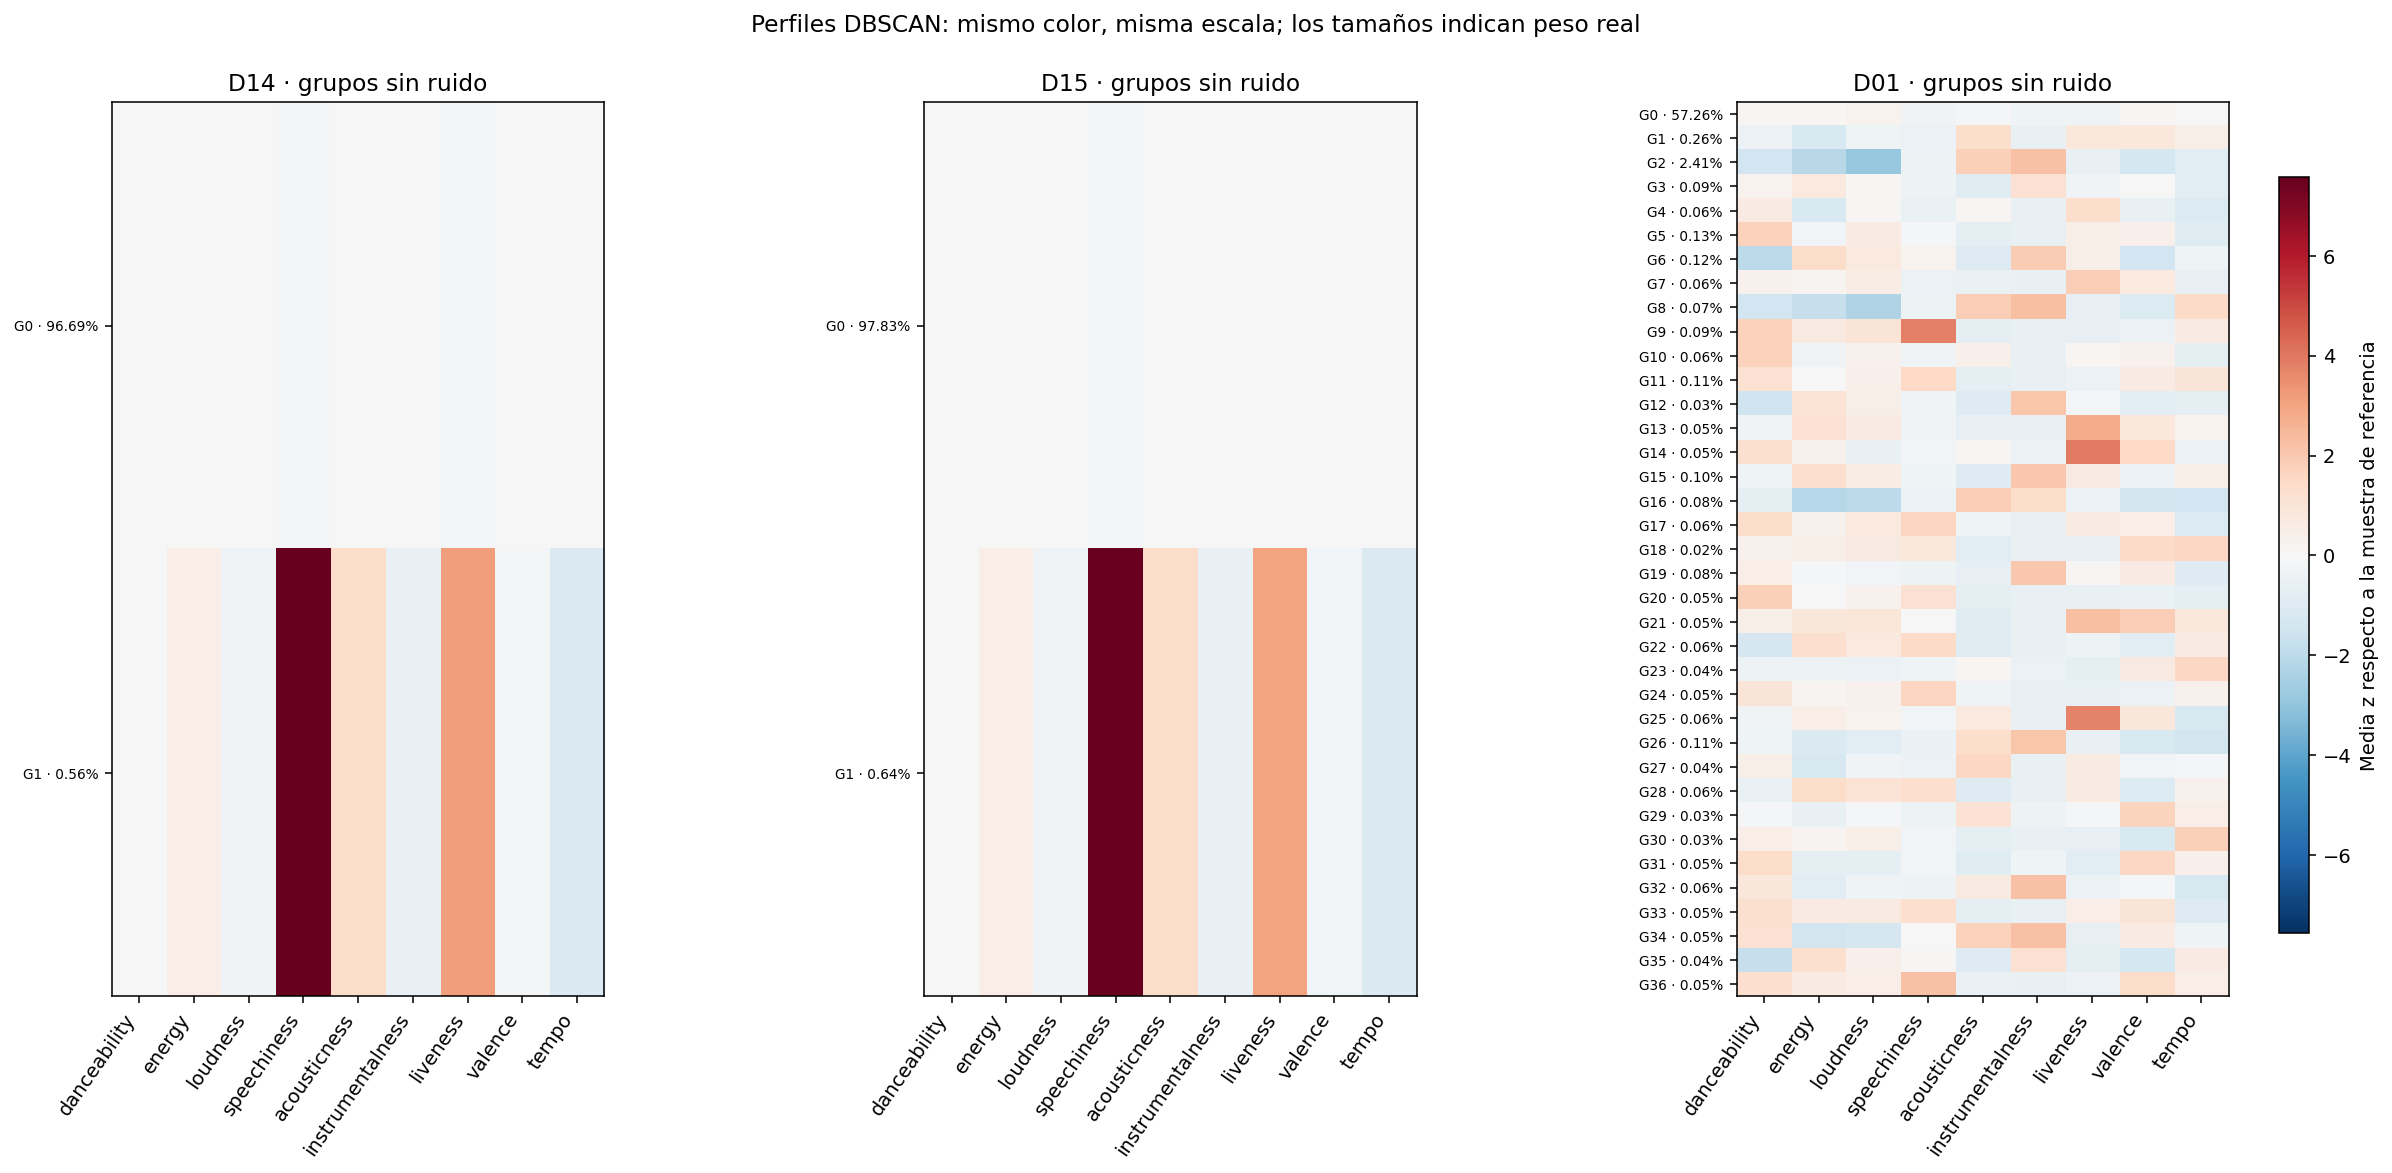

In [76]:
import matplotlib.pyplot as plt

fig_perfiles_dbscan_u3, ejes_perfiles_dbscan_u3 = plt.subplots(1, len(seleccion_inspeccion_dbscan_u3), figsize=(6 * len(seleccion_inspeccion_dbscan_u3), 9), squeeze=False)
limite = max(float(v.abs().to_numpy().max()) for v in perfiles_dbscan_inspeccion_z_u3.values() if len(v))
for eje, candidato in zip(ejes_perfiles_dbscan_u3.flat, seleccion_inspeccion_dbscan_u3):
    perfil = perfiles_dbscan_inspeccion_z_u3[candidato]
    imagen = eje.imshow(perfil, cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
    eje.set_xticks(range(len(perfil.columns)), perfil.columns, rotation=55, ha="right")
    eje.set_yticks(range(len(perfil)), [f"G{g} · {resumen_grupos_dbscan_inspeccion_u3[candidato].loc[g, '% muestra']:.2f}%" for g in perfil.index], fontsize=7)
    eje.set_title(candidato + " · grupos sin ruido")
fig_perfiles_dbscan_u3.subplots_adjust(left=0.07, right=0.91, bottom=0.20, top=0.91, wspace=0.65)
barra = fig_perfiles_dbscan_u3.add_axes([0.93, 0.25, 0.012, 0.60])
fig_perfiles_dbscan_u3.colorbar(imagen, cax=barra, label="Media z respecto a la muestra de referencia")
fig_perfiles_dbscan_u3.suptitle("Perfiles DBSCAN: mismo color, misma escala; los tamaños indican peso real")
display(fig_perfiles_dbscan_u3)
plt.close(fig_perfiles_dbscan_u3)

### Cómo interpretar el mapa de perfiles

Cada panel conserva TODOS los grupos reales del candidato. El porcentaje de cada fila usa la muestra completa. Rojo y azul comparan medias con la misma muestra de referencia; una escala común evita que cada panel exagere sus propios contrastes. Los identificadores de grupo no se corresponden entre candidatos.

Muchas filas no implican una segmentación útil si casi toda la población queda en una sola. Las medias de grupos diminutos pueden reflejar pocos vectores repetidos o registros extremos; se revisan junto con sus claves distintas, dispersión y ejemplos. El ruido sigue contabilizado en las tablas y no se renombra como playlist adicional.

La inspección no asigna géneros oficiales ni demuestra que canciones de perfiles similares formen una buena playlist. Los candidatos se analizan como evidencia del comportamiento encontrado, sin ocultar casos desfavorables.

In [77]:
from sklearn.neighbors import NearestNeighbors

# Un caso real permite distinguir min_samples de tamaño final del grupo.
candidato_borde_dbscan_u3 = "D01"
modelo_borde_dbscan_u3 = modelos_dbscan_busqueda_u3[candidato_borde_dbscan_u3]
etiquetas_borde_dbscan_u3 = etiquetas_dbscan_busqueda_u3[candidato_borde_dbscan_u3]
tamanos_borde_dbscan_u3 = etiquetas_borde_dbscan_u3.loc[etiquetas_borde_dbscan_u3.ne(-1)].value_counts()
grupo_borde_dbscan_u3 = int(tamanos_borde_dbscan_u3.idxmin())
mascara_core_borde_dbscan_u3 = np.zeros(len(etiquetas_borde_dbscan_u3), dtype=bool)
mascara_core_borde_dbscan_u3[modelo_borde_dbscan_u3.core_sample_indices_] = True
posiciones_core_grupo_dbscan_u3 = np.flatnonzero(etiquetas_borde_dbscan_u3.eq(grupo_borde_dbscan_u3).to_numpy() & mascara_core_borde_dbscan_u3)
if not len(posiciones_core_grupo_dbscan_u3):
    raise ValueError("El grupo elegido no tiene núcleo para inspeccionar.")
posicion_core_ejemplo_dbscan_u3 = int(posiciones_core_grupo_dbscan_u3[0])
indice_borde_dbscan_u3 = NearestNeighbors(radius=modelo_borde_dbscan_u3.eps, algorithm="ball_tree", metric="euclidean", leaf_size=40).fit(X_muestra_cluster_escalada_u3)
posiciones_radio_ejemplo_dbscan_u3 = indice_borde_dbscan_u3.radius_neighbors(
    X_muestra_cluster_escalada_u3.iloc[[posicion_core_ejemplo_dbscan_u3]], return_distance=False,
)[0]
vecinos_nucleo_ejemplo_dbscan_u3 = pd.DataFrame({
    "ID": X_muestra_cluster_escalada_u3.index[posiciones_radio_ejemplo_dbscan_u3],
    "Grupo final": etiquetas_borde_dbscan_u3.iloc[posiciones_radio_ejemplo_dbscan_u3].to_numpy(),
    "Es núcleo": mascara_core_borde_dbscan_u3[posiciones_radio_ejemplo_dbscan_u3],
})
print(f"{candidato_borde_dbscan_u3}: grupo {grupo_borde_dbscan_u3} con {tamanos_borde_dbscan_u3.loc[grupo_borde_dbscan_u3]} IDs, min_samples={modelo_borde_dbscan_u3.min_samples}.")
print(f"Su núcleo examinado reúne {len(vecinos_nucleo_ejemplo_dbscan_u3)} registros dentro de eps.")
display(vecinos_nucleo_ejemplo_dbscan_u3)
resumen_lectura_dbscan_u3 = candidatos_inspeccion_dbscan_u3[[
    "eps", "min_samples", "Grupos sin ruido", "Cobertura (%)", "Ruido (%)", "Grupo mayor (% asignados)",
    "Silhouette panel sin ruido", "Davies–Bouldin sin ruido"
]].join(resumen_estabilidad_dbscan_u3[["ARI_medio", "ARI_definidos", "Rondas", "Cobertura_media"]])
display(resumen_lectura_dbscan_u3.round(5))

D01: grupo 18 con 2 IDs, min_samples=5.
Su núcleo examinado reúne 5 registros dentro de eps.


,ID,Grupo final,Es núcleo
0,6Y0dk2LmTiHN27v85wEHcv,0,False
1,7AH9Fmka4of4Y25lfhvBUC,0,False
2,1lIb7Ze8PHhWwdXDtPF00j,18,True
3,6mx6kZqFsUaT3rYdxQ4Ajw,0,False
4,35bUCSCnEQRek7xXNG0XIM,18,False


,eps,min_samples,Grupos sin ruido,Cobertura (%),Ruido (%),Grupo mayor (% asignados),Silhouette panel sin ruido,Davies–Bouldin sin ruido,ARI_medio,ARI_definidos,Rondas,Cobertura_media
Candidato,,,,,,,,,,,,
D14,1.70428,20,2,97.25,2.75,99.42416,0.57986,0.49673,1.00000,2,3,96.49217
D15,1.96761,20,2,98.47,1.53,99.35006,0.57062,0.51885,1.00000,3,3,98.14597
D01,0.81674,5,37,62.07,37.93,92.25068,-0.23318,1.01811,0.58482,3,3,59.07091


### 29.2. Cómo leer el caso de min_samples y grupos pequeños

El código recupera el menor grupo real de D01 y localiza uno de sus núcleos mediante `core_sample_indices_`. Después consulta sus vecinos con exactamente el radio del modelo. Es una inspección del ajuste guardado, no otro DBSCAN ni un cambio de parámetros. La tabla muestra a qué grupo quedó asignado cada vecino y si es núcleo.

**Resultado concreto:** el grupo 18 tiene dos IDs aunque `min_samples=5`. Su núcleo examinado reúne cinco registros dentro del radio: dos terminan en el grupo 18 y tres en el grupo 0. Estos últimos no son núcleos en la tabla. Son puntos frontera que ya quedaron asociados a otro grupo. La condición de núcleo cuenta los vecinos locales, no solo los que reciben la misma etiqueta final. Así se entiende por qué `min_samples` no debe interpretarse como tamaño mínimo garantizado de cada playlist. Los puntos frontera compartidos pueden depender del orden de recorrido; este ensayo no evaluó esa sensibilidad adicional.

### 29.3. Resultados de los quince candidatos

**Se ejecutaron los quince pares definidos, sin ampliar la búsqueda después.** La cobertura varió entre 62,07% y 98,47%, pero el grupo mayor reunió entre 92,25% y 100% de los asignados. No se encontró una partición de varios perfiles con peso sustancial que organice el catálogo como requiere nuestra propuesta.

D12 y D13 produjeron **un solo grupo real**, por lo que silhouette y Davies–Bouldin no están definidos. Se conservan sus resultados con NaN y motivo; no se ocultan ni se interpretan como cero. D14 y D15 produjeron dos grupos: tampoco aportan la variedad que buscamos, aunque sus métricas internas puedan parecer buenas.

El porcentaje de núcleos no era cobertura. Por ejemplo, D01 tiene 5.000 núcleos y 6.207 asignados; los 1.207 restantes asignados son frontera. Quedan 3.793 como ruido. Esto ilustra por qué el P50 no significaba que solo 50% pudiera recibir grupo.

**La diferencia de D09 quedó localizada:** dos IDs tienen distancia m-ésima numéricamente igual a eps, pero la consulta por radio devuelve nueve vecinos con el radio original y diez con el número representable inmediatamente superior. Por ello el modelo cuenta 8.999 núcleos y el diagnóstico por distancia m-ésima contaba 9.001. Se conserva el ajuste original sin cambiar eps para forzar coincidencia. La diferencia ocurre en un límite numérico y no afecta la selección de los tres casos de inspección.

### 29.4. Qué muestran los tres casos inspeccionados

**D14 — mayor silhouette definida (eps≈1,70428, min_samples=20).** Silhouette 0,57986 y Davies–Bouldin 0,49673 parecen favorables si se miran solos. Sin embargo, son 9.669 IDs en un grupo, 56 en otro y 275 de ruido. El grupo mayor reúne **99,42% de los asignados**. El pequeño tiene speechiness medio 0,921 y liveness 0,817, frente a 0,077 y 0,203 en el mayor: distingue sobre todo un perfil extremo de voz hablada, sin segmentar la gran mayoría en estilos musicales útiles. Los ejemplos incluyen «rock, paper, scissors, jesus», de chad daniels, y «we got a joint!», de ryan sickler; sus nombres no sustituyen escuchar y revisar el contenido.

En estabilidad, D14 quedó en **un solo grupo** con la submuestra de semilla 42. El ARI se deja sin definir para esa comparación porque celebrar coincidencia de una sola agrupación sería poco informativo. En las otras dos submuestras, ARI=1 entre los asignados comunes; esto no compensa que desaparezca el grupo pequeño en una de las pruebas. La cobertura media nueva fue 96,49%.

**D15 — mayor cobertura entre evaluables (eps≈1,96761, min_samples=20).** Asigna 9.847 IDs y deja 153 como ruido. Son 9.783 en el grupo mayor y 64 en un perfil pequeño similar al anterior; el mayor reúne **99,35% de los asignados**. Silhouette 0,57062 y Davies–Bouldin 0,51885 describen esa separación muy desigual, no ocho perfiles de playlist. El grupo pequeño presenta speechiness medio 0,911 y liveness 0,799.

Su ARI es 1 en las tres comparaciones **solo entre registros asignados en ambos ajustes**, con cobertura media nueva 98,15%. Aun así hubo 64 eventos de paso de asignado a ruido sumando las tres submuestras; no son necesariamente 64 canciones únicas. ARI=1 indica que los registros retenidos conservaron su partición, no que todos conservaran cobertura ni que la división sea útil. Una partición estable y casi única puede seguir siendo demasiado general.

**D01 — menor dominio del grupo mayor entre evaluables (eps≈0,81674, min_samples=5).** Produce 37 grupos y 37,93% de ruido; silhouette −0,23318 y Davies–Bouldin 1,01811. Su grupo mayor tiene 5.726 IDs y representa **92,25% de los asignados**. Tener 37 etiquetas no equivale a disponer de 37 playlists comparables en tamaño o calidad.

Existe un nicho interpretable: su grupo 2 tiene 241 IDs de 235 claves, acústica media 0,944, instrumentalidad 0,895 y energía 0,097. Podría interesar para explorar música más acústica e instrumental de baja energía. Pero otros grupos apenas contienen unos pocos IDs: el grupo 1 reúne **26 IDs de una sola clave**. La densidad puede reflejar versiones, no diversidad de canciones. En ese grupo se muestra un único ejemplo distinto, «let it snow! let it snow! let it snow!», de dean martin, sin inventar un segundo.

D01 muestra ARI medio 0,58482, mínimo 0,54702 y cobertura media nueva 59,07% al reducir datos. Las tres submuestras producen 36, 37 y 33 grupos, frente a 37 en la muestra completa. Hubo 759 eventos de paso a ruido. Es más sensible al cambio de densidad y deja gran parte del catálogo sin asignar.

La silhouette negativa de D01 sugiere asignaciones discutibles según distancias medias del panel, pero no demuestra que todos sus grupos carezcan de interés. La geometría irregular de DBSCAN y el dominio del grupo grande limitan estos índices. Se conservan los perfiles completos para ver tanto nichos útiles como problemas globales.

### 29.5. Conclusión de esta fase

**Ninguno de los quince candidatos se considera adecuado por ahora para organizar esta muestra en varias playlists musicales generales.** No se declara un ganador solo porque muestre silhouette alta, cobertura casi total o ARI=1. Los tres casos se eligieron para entender los intercambios; inspeccionarlos no significa aprobarlos.

DBSCAN aporta una exploración de densidad, perfiles extremos y algún nicho pequeño. Para nuestra organización general, en el espacio y parámetros probados produce sobre todo un gran grupo con pequeños satélites o mucho ruido. Esto no demuestra que DBSCAN sea universalmente peor ni que otra representación o búsqueda no pueda mejorar el resultado. No se cambiaron radios, variables o escala para buscar una conclusión favorable.

La comparación con K-Means requiere todavía el bloque específico sobre cobertura, perfiles y, cuando proceda, los mismos IDs asignados; no se atribuye una superioridad formal comparando directamente silhouette de poblaciones diferentes. **K=8 conserva su estado provisional**, sin reemplazarlo por un candidato DBSCAN en esta fase. La comprobación a escala de todo entrenamiento sigue pendiente.

Los mapas de perfiles dan la misma altura visual a cada fila: **la altura no representa tamaño de grupo**. Sus porcentajes al lado de la etiqueta son esenciales para no interpretar dos filas como dos mitades del catálogo. Las medias no sustituyen escuchar canciones y revisar su variación interna.

Se completaron los puntos solicitados: quince ajustes, inspección de tres casos, perfiles, ejemplos y tres submuestras por caso (**nueve reajustes adicionales de DBSCAN**). No se usaron datos de test, popularidad o artista para ajustar, ni se modificó la preparación o los CSV. Las conclusiones se limitan a la muestra y protocolo; quedan registradas para el informe final.


## 30. Comparación: DBSCAN y K-Means de ocho grupos

### 30.1. Una decisión para playlists, no un concurso de una sola métrica

Compararemos K=8, semilla 42, con D01, D14 y D15, los casos DBSCAN inspeccionados por menor dominio, mayor silhouette y mayor cobertura entre evaluables. No se ocultan los otros doce ajustes: sus resultados permanecen en el bloque 28. No se ejecuta otra búsqueda ni se cambian parámetros para favorecer un método.

Todos proceden de la misma matriz de **10.000 IDs, nueve características y preparación fija**. Hay dos niveles de evaluación: la cobertura del conjunto completo y la calidad geométrica sobre canciones asignadas. DBSCAN deja ruido y K-Means no; por eso no compararemos directamente sus silhouette como si siempre describieran las mismas filas.

Mostraremos métricas originales y una comparación adicional de ambas particiones sobre **los mismos IDs asignados por cada DBSCAN**, sin reajustar ningún modelo al retirar ruido. Finalmente, K-Means se reajustará tres veces en las mismas submuestras agrupadas del bloque 29 para comparar sensibilidad al muestreo. Esos son los únicos ajustes nuevos.

In [78]:
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances, adjusted_rand_score
from sklearn.base import clone
from threadpoolctl import threadpool_limits

CANDIDATOS_COMPARACION_CLUSTER_U3 = ["D01", "D14", "D15"]
etiquetas_k8_comparacion_u3 = etiquetas_kmeans_busqueda_u3[(8, 42)]
modelo_k8_comparacion_u3 = modelos_kmeans_busqueda_u3[(8, 42)]
if not etiquetas_k8_comparacion_u3.index.equals(X_muestra_cluster_escalada_u3.index):
    raise ValueError("K-Means y la muestra no están alineados.")
metricas_k8_comparacion_u3 = metricas_kmeans_busqueda_u3.loc[
    metricas_kmeans_busqueda_u3["K"].eq(8) & metricas_kmeans_busqueda_u3["Semilla"].eq(42)
].iloc[0]
tamanos_k8_comparacion_u3 = etiquetas_k8_comparacion_u3.value_counts()
filas_comparacion_cluster_u3 = [{"Modelo": "K-Means K=8", "Grupos sin ruido": 8,
    "IDs asignados": len(etiquetas_k8_comparacion_u3), "Cobertura (%)": 100.0, "Ruido (%)": 0.0,
    "Grupo mayor (% muestra)": tamanos_k8_comparacion_u3.max() / len(etiquetas_k8_comparacion_u3) * 100,
    "Grupo mayor (% asignados)": tamanos_k8_comparacion_u3.max() / len(etiquetas_k8_comparacion_u3) * 100,
    "Silhouette panel asignados": metricas_k8_comparacion_u3["Silhouette panel"],
    "Davies–Bouldin asignados": metricas_k8_comparacion_u3["Davies–Bouldin"],
    "IDs panel asignados": len(ids_panel_sil_cluster_u3)}]
for candidato in CANDIDATOS_COMPARACION_CLUSTER_U3:
    fila = resultados_dbscan_busqueda_u3.set_index("Candidato").loc[candidato]
    filas_comparacion_cluster_u3.append({"Modelo": candidato, "Grupos sin ruido": fila["Grupos sin ruido"],
        "IDs asignados": fila["IDs asignados"], "Cobertura (%)": fila["Cobertura (%)"], "Ruido (%)": fila["Ruido (%)"],
        "Grupo mayor (% muestra)": fila["Grupo mayor (% muestra)"], "Grupo mayor (% asignados)": fila["Grupo mayor (% asignados)"],
        "Silhouette panel asignados": fila["Silhouette panel sin ruido"],
        "Davies–Bouldin asignados": fila["Davies–Bouldin sin ruido"], "IDs panel asignados": fila["IDs panel sin ruido"]})
comparacion_global_cluster_u3 = pd.DataFrame(filas_comparacion_cluster_u3)
display(comparacion_global_cluster_u3.round(5))

,Modelo,Grupos sin ruido,IDs asignados,Cobertura (%),Ruido (%),Grupo mayor (% muestra),Grupo mayor (% asignados),Silhouette panel asignados,Davies–Bouldin asignados,IDs panel asignados
0,K-Means K=8,8,10000,100.00,0.00,26.96,26.96000,0.18755,1.37869,2000
1,D01,37,6207,62.07,37.93,57.26,92.25068,-0.23318,1.01811,1238
2,D14,2,9725,97.25,2.75,96.69,99.42416,0.57986,0.49673,1948
3,D15,2,9847,98.47,1.53,97.83,99.35006,0.57062,0.51885,1972


### Explicación de la tabla general

La lista fija los tres casos de diagnóstico. Se recuperan etiquetas y métricas de **K=8, semilla 42**; no se mezclan sus perfiles con las medias de tres semillas del bloque 23. `value_counts` permite comprobar su grupo mayor.

Las filas de DBSCAN proceden de los resultados originales, no de un nuevo ajuste. `DataFrame` reúne campos comparables y `round` solo redondea la presentación. Las proporciones del grupo mayor distinguen toda la muestra de solo asignados.

K-Means cubre el 100% **por diseño**, incluso si una canción queda lejos de cualquier centro. No tener ruido no significa detectar todos los casos correctamente. En DBSCAN, excluir ruido puede ser útil para encontrar zonas densas, pero reduce el catálogo disponible para playlists.

Silhouette mayor y Davies–Bouldin menor indican ciertas propiedades geométricas de la partición evaluada; no expresan precisión ni satisfacción musical. La primera usa el panel común, después de retirar ruido donde corresponde; el segundo usa todos los asignados. La tabla incluye sus tamaños para no confundir poblaciones distintas.

In [79]:
with threadpool_limits(limits=1):
    distancias_panel_comparacion_cluster_u3 = pairwise_distances(
        X_muestra_cluster_escalada_u3.loc[ids_panel_sil_cluster_u3], metric="euclidean", n_jobs=1,
    )
np.fill_diagonal(distancias_panel_comparacion_cluster_u3, 0.0)
filas_metricas_cohorte_cluster_u3 = []
for candidato in CANDIDATOS_COMPARACION_CLUSTER_U3:
    etiquetas_db = etiquetas_dbscan_busqueda_u3[candidato]
    if not etiquetas_db.index.equals(etiquetas_k8_comparacion_u3.index):
        raise ValueError("Los métodos no describen los mismos IDs.")
    ids_cohorte = etiquetas_db.index[etiquetas_db.ne(-1)]
    mascara_panel = etiquetas_db.loc[ids_panel_sil_cluster_u3].ne(-1).to_numpy()
    ids_panel_cohorte = ids_panel_sil_cluster_u3[mascara_panel]
    for nombre, etiquetas in [("K-Means K=8", etiquetas_k8_comparacion_u3), (candidato, etiquetas_db)]:
        etiquetas_total = etiquetas.loc[ids_cohorte]
        etiquetas_panel = etiquetas.loc[ids_panel_cohorte]
        valida_sil = 2 <= etiquetas_panel.nunique() < len(etiquetas_panel)
        valida_db = 2 <= etiquetas_total.nunique() < len(etiquetas_total)
        with threadpool_limits(limits=1):
            sil = silhouette_score(distancias_panel_comparacion_cluster_u3[np.ix_(mascara_panel, mascara_panel)], etiquetas_panel, metric="precomputed") if valida_sil else np.nan
            db = davies_bouldin_score(X_muestra_cluster_escalada_u3.loc[ids_cohorte], etiquetas_total) if valida_db else np.nan
        filas_metricas_cohorte_cluster_u3.append({"Cohorte": "Asignados de " + candidato, "Modelo evaluado": nombre,
            "IDs cohorte": len(ids_cohorte), "IDs panel cohorte": len(ids_panel_cohorte),
            "Grupos efectivos cohorte": etiquetas_total.nunique(), "Grupos efectivos panel": etiquetas_panel.nunique(),
            "Silhouette misma cohorte": sil, "Davies–Bouldin misma cohorte": db,
            "Silhouette definida": valida_sil, "DB definido": valida_db})
comparacion_mismos_ids_cluster_u3 = pd.DataFrame(filas_metricas_cohorte_cluster_u3)
display(comparacion_mismos_ids_cluster_u3.round(5))

,Cohorte,Modelo evaluado,IDs cohorte,IDs panel cohorte,Grupos efectivos cohorte,Grupos efectivos panel,Silhouette misma cohorte,Davies–Bouldin misma cohorte,Silhouette definida,DB definido
0,Asignados de D01,K-Means K=8,6207,1238,7,7,0.20322,1.30278,True,True
1,Asignados de D01,D01,6207,1238,37,21,-0.23318,1.01811,True,True
2,Asignados de D14,K-Means K=8,9725,1948,8,8,0.19330,1.33775,True,True
3,Asignados de D14,D14,9725,1948,2,2,0.57986,0.49673,True,True
4,Asignados de D15,K-Means K=8,9847,1972,8,8,0.19181,1.34600,True,True
5,Asignados de D15,D15,9847,1972,2,2,0.57062,0.51885,True,True


### Por qué se repite el cálculo sobre los mismos IDs

1. Se prepara una sola matriz de distancias del panel original. No se sortean paneles distintos para favorecer un resultado.
2. Para cada DBSCAN, `ne(-1)` identifica su cohorte de asignados. La máscara del panel retira exactamente los mismos IDs para los dos métodos en esa pareja.
3. El segundo recorrido evalúa las etiquetas de K-Means y DBSCAN **ya aprendidas**, restringidas a esa cohorte. No hay `fit`, no se eliminan filas del modelo ni se reclasifica el ruido.
4. Se cuentan grupos efectivos, porque al retirar canciones pueden desaparecer etiquetas de K-Means. Si la partición no permite una métrica válida, se registra NaN y la condición en las columnas de control.
5. Se recalculan silhouette y Davies–Bouldin usando las mismas canciones y la misma escala para cada pareja. Los perfiles y números de grupo siguen perteneciendo a sus modelos originales.

Esto corrige la diferencia de población **dentro de cada pareja**, pero la cohorte fue seleccionada por DBSCAN: es un análisis condicionado a su cobertura, no una evaluación independiente ni una razón para borrar ruido del proyecto. Las cohortes de D01, D14 y D15 difieren; no se comparan sus métricas como si fueran la misma población.

Incluso con los mismos IDs, una silhouette alta puede favorecer una división entre un grupo enorme y un extremo pequeño. La comparación geométrica no reemplaza el requisito práctico de disponer de varios perfiles musicales interpretables.

D01: destino de cada grupo K=8; la columna -1 es ruido, no una playlist
D14: destino de cada grupo K=8; la columna -1 es ruido, no una playlist
D15: destino de cada grupo K=8; la columna -1 es ruido, no una playlist


D01,-1,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36
Grupo K=8,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,28.15,69.85,1.3,0.00,0.00,0.3,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05,0.00,0.00,0.00,0.2,0.00,0.05,0.00,0.00,0.00,0.00,0.10,0.00,0.00
1,55.63,6.13,0.0,34.38,0.00,0.0,0.00,0.00,0.00,1.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.28,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.43,0.00,0.00
2,83.22,9.45,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.0,1.47,0.00,1.79,0.00,0.00,0.00,0.00,0.00,0.98,0.00,0.00,0.81,0.00,0.00,0.00,0.81,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.65,0.00,0.00,0.81
3,17.62,81.27,0.0,0.00,0.00,0.0,0.48,0.00,0.00,0.0,0.00,0.22,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.07,0.00,0.00,0.00,0.00,0.04,0.00,0.00,0.00,0.0,0.00,0.07,0.00,0.19,0.00,0.04,0.00,0.00,0.00
4,60.80,34.95,0.0,0.00,0.78,0.0,0.00,0.87,0.00,0.0,0.00,0.00,0.00,0.26,0.00,0.00,0.87,0.00,0.00,0.00,0.69,0.00,0.00,0.00,0.00,0.00,0.00,0.17,0.0,0.00,0.00,0.00,0.00,0.52,0.00,0.00,0.09,0.00
5,23.39,75.57,0.0,0.00,0.00,0.0,0.00,0.09,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.28,0.09,0.00,0.00,0.00,0.0,0.28,0.00,0.14,0.00,0.00,0.00,0.00,0.14,0.00
6,91.99,3.59,0.0,0.00,0.00,0.0,0.00,0.00,0.98,0.0,0.00,0.00,0.00,0.00,0.82,0.82,0.00,0.00,0.00,0.00,0.00,0.00,0.82,0.00,0.00,0.00,0.98,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
7,100.00,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


D14,-1,0,1
Grupo K=8,,,
0,0.45,99.55,0.00
1,8.70,91.30,0.00
2,7.33,92.67,0.00
3,0.04,99.96,0.00
4,3.47,96.53,0.00
5,0.09,99.91,0.00
6,13.40,86.60,0.00
7,38.46,0.00,61.54


D15,-1,0,1
Grupo K=8,,,
0,0.05,99.95,0.00
1,5.85,94.15,0.00
2,2.93,97.07,0.00
3,0.00,100.00,0.00
4,0.95,99.05,0.00
5,0.05,99.95,0.00
6,8.82,91.18,0.00
7,29.67,0.00,70.33


,IDs,% muestra,Claves distintas,Tempo imputado (%),Descripción relativa
Grupo,,,,,
0,2000,20.00,1748,0.000000,"Más acústico, menor energía"
1,701,7.01,671,2.139800,"Acústico e instrumental, poca energía y volumen"
2,614,6.14,584,0.000000,Bailable con mayor presencia de voz hablada
3,2696,26.96,2310,0.000000,"Bailable, mayor valencia y menor voz hablada"
4,1153,11.53,1125,0.000000,"Más instrumental, energía media-alta"
5,2133,21.33,1959,0.000000,"Energético, menos acústico y más rápido"
6,612,6.12,582,0.163399,Más indicios de interpretación en vivo
7,91,0.91,90,0.000000,Voz hablada muy marcada: revisar contenido


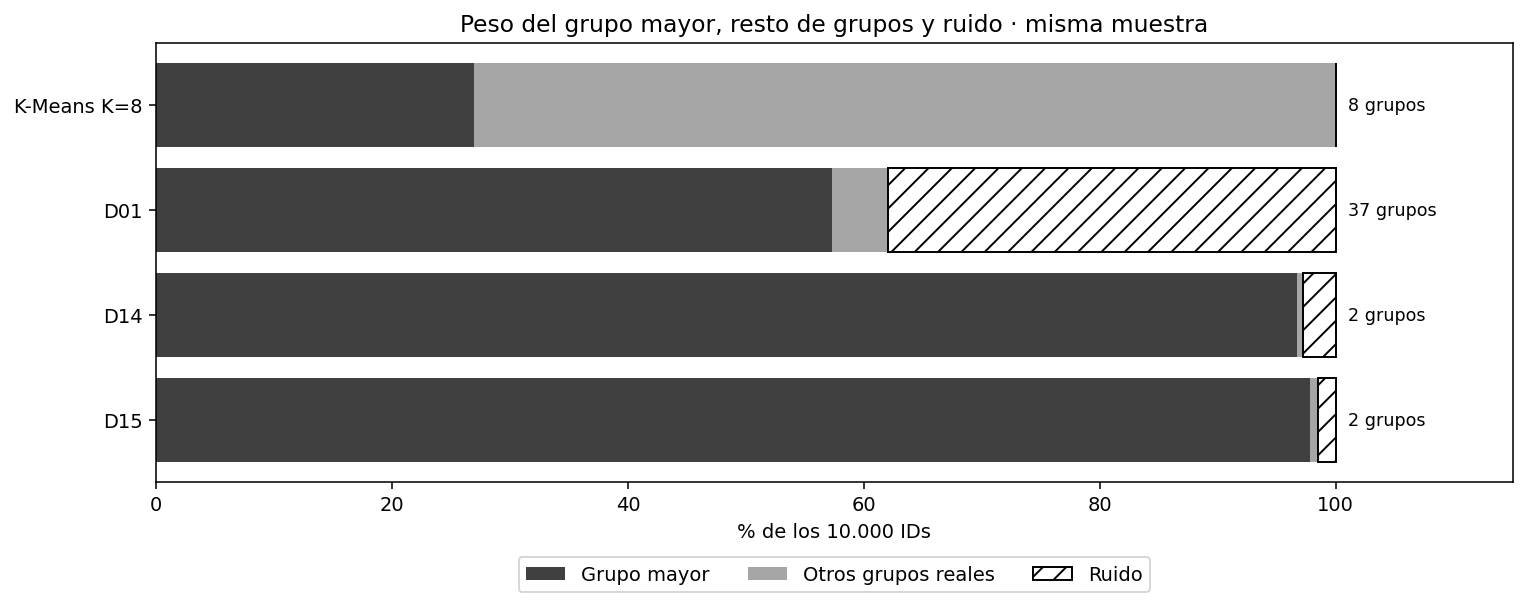

In [80]:
cruces_k8_dbscan_u3 = {}
for candidato in CANDIDATOS_COMPARACION_CLUSTER_U3:
    cruce = pd.crosstab(etiquetas_k8_comparacion_u3.rename("Grupo K=8"), etiquetas_dbscan_busqueda_u3[candidato].rename(candidato))
    porcentajes = cruce.div(cruce.sum(axis=1), axis=0) * 100
    cruces_k8_dbscan_u3[candidato] = {"IDs": cruce, "% del grupo K=8": porcentajes}
    print(candidato + ": destino de cada grupo K=8; la columna -1 es ruido, no una playlist")
    display(porcentajes.round(2))
perfiles_k8_comparacion_u3 = resumen_perfiles_789_u3[8].copy()
perfiles_k8_comparacion_u3["Descripción relativa"] = pd.Series(nombres_perfiles_789_u3[8])
display(perfiles_k8_comparacion_u3)

import matplotlib.pyplot as plt
fig_cobertura_cluster_u3, eje_cobertura_cluster_u3 = plt.subplots(figsize=(11, 4.5))
base = comparacion_global_cluster_u3.set_index("Modelo")
mayor = base["Grupo mayor (% muestra)"]
otros = base["Cobertura (%)"] - mayor
ruido = base["Ruido (%)"]
eje_cobertura_cluster_u3.barh(base.index, mayor, color="0.25", label="Grupo mayor")
eje_cobertura_cluster_u3.barh(base.index, otros, left=mayor, color="0.65", label="Otros grupos reales")
eje_cobertura_cluster_u3.barh(base.index, ruido, left=mayor + otros, color="white", edgecolor="black", hatch="//", label="Ruido")
for fila, nombre in enumerate(base.index):
    eje_cobertura_cluster_u3.text(101, fila, f"{int(base.loc[nombre, 'Grupos sin ruido'])} grupos", va="center", fontsize=9)
eje_cobertura_cluster_u3.invert_yaxis()
eje_cobertura_cluster_u3.set(xlim=(0, 115), xlabel="% de los 10.000 IDs", title="Peso del grupo mayor, resto de grupos y ruido · misma muestra")
eje_cobertura_cluster_u3.set_xticks([0, 20, 40, 60, 80, 100])
eje_cobertura_cluster_u3.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
fig_cobertura_cluster_u3.tight_layout()
display(fig_cobertura_cluster_u3)
plt.close(fig_cobertura_cluster_u3)

### Cómo leer cobertura y perfiles juntos

`crosstab` cuenta IDs compartidos entre cada grupo de K-Means y las etiquetas DBSCAN. Dividir por la suma de fila muestra a dónde va **cada grupo de K=8**, incluyendo ruido. Las filas suman cien; no son porcentajes del grupo DBSCAN de destino ni un porcentaje de acierto.

Estas tablas permiten comprobar si el grupo gigante de DBSCAN mezcla varios perfiles previos. Que no coincidan las etiquetas no significa automáticamente error: los métodos buscan estructuras diferentes. Los perfiles y sus tamaños determinan si esa estructura responde al objetivo de playlists.

La tabla de K=8 recupera las descripciones del bloque 24: contrastes de acústica, instrumentalidad, energía, bailabilidad, voz hablada e indicios de vivo. Son tendencias relativas de indicadores, no géneros oficiales ni garantía de coherencia de todas las canciones.

En el gráfico cada barra representa exactamente los mismos 10.000 IDs. Se suman grupo mayor, otros grupos reales y ruido. A diferencia del mapa de calor, **la longitud sí representa tamaño**. «Otros grupos» reúne varios perfiles, no una playlist adicional. Un modelo que concentra casi todo en un grupo no aporta una organización detallada aunque cubra muchas canciones.

In [81]:
filas_estabilidad_k8_muestreo_u3 = []
etiquetas_k8_submuestras_u3 = {}
for semilla, ids in ids_submuestras_dbscan_u3.items():
    if not ids.isin(X_muestra_cluster_escalada_u3.index).all():
        raise ValueError("Submuestra fuera de la muestra preparada.")
    if set(ids) != set(g_muestra_cluster_u3.index[g_muestra_cluster_u3.isin(g_muestra_cluster_u3.loc[ids].unique())]):
        raise ValueError("Se cortaron versiones.")
    modelo = clone(modelo_k8_comparacion_u3)
    with threadpool_limits(limits=1):
        nueva = pd.Series(modelo.fit_predict(X_muestra_cluster_escalada_u3.loc[ids]), index=ids)
    referencia = etiquetas_k8_comparacion_u3.loc[ids]
    ari = adjusted_rand_score(referencia, nueva)
    etiquetas_k8_submuestras_u3[semilla] = nueva
    filas_estabilidad_k8_muestreo_u3.append({"Modelo": "K-Means K=8", "Semilla submuestra": semilla,
        "IDs comunes": len(ids), "Grupos nuevos": nueva.nunique(), "Cobertura nueva (%)": 100.0,
        "IDs comparación ARI": len(ids), "ARI asignados comunes": ari,
        "Asignado a ruido": 0, "Ruido a asignado": 0})
filas_estabilidad_comparable_u3 = filas_estabilidad_k8_muestreo_u3.copy()
for _, fila in estabilidad_dbscan_inspeccion_u3.iterrows():
    filas_estabilidad_comparable_u3.append({"Modelo": fila["Candidato"], "Semilla submuestra": fila["Semilla submuestra"],
        "IDs comunes": fila["IDs comunes"], "Grupos nuevos": fila["Grupos nuevos sin ruido"],
        "Cobertura nueva (%)": fila["Cobertura nueva (%)"], "IDs comparación ARI": fila["Asignados en ambos"],
        "ARI asignados comunes": fila["ARI solo asignados comunes"],
        "Asignado a ruido": fila["Asignado a ruido"], "Ruido a asignado": fila["Ruido a asignado"]})
estabilidad_comparacion_cluster_u3 = pd.DataFrame(filas_estabilidad_comparable_u3)
resumen_estabilidad_comparacion_cluster_u3 = estabilidad_comparacion_cluster_u3.groupby("Modelo").agg(
    ARI_medio=("ARI asignados comunes", "mean"), ARI_minimo=("ARI asignados comunes", "min"),
    ARI_definidos=("ARI asignados comunes", "count"), Rondas=("Semilla submuestra", "size"),
    Cobertura_media=("Cobertura nueva (%)", "mean"), IDs_ARI_minimo=("IDs comparación ARI", "min"),
)
filas_ari_cohorte_u3 = []
for candidato in CANDIDATOS_COMPARACION_CLUSTER_U3:
    for semilla, ids in ids_submuestras_dbscan_u3.items():
        ref_db = etiquetas_dbscan_busqueda_u3[candidato].loc[ids]
        nueva_db = etiquetas_submuestras_dbscan_u3[(candidato, semilla)]
        mascara = ref_db.ne(-1) & nueva_db.ne(-1)
        for nombre, referencia, nueva in [
            ("K-Means K=8", etiquetas_k8_comparacion_u3.loc[ids], etiquetas_k8_submuestras_u3[semilla]),
            (candidato, ref_db, nueva_db),
        ]:
            a, b = referencia.loc[mascara], nueva.loc[mascara]
            valida = len(a) > 1 and 2 <= a.nunique() < len(a) and 2 <= b.nunique() < len(b)
            filas_ari_cohorte_u3.append({"Cohorte DBSCAN": candidato, "Semilla submuestra": semilla,
                "Modelo": nombre, "IDs comunes asignados DB en ambos": len(a),
                "Grupos referencia": a.nunique(), "Grupos submuestra": b.nunique(),
                "ARI misma cohorte": adjusted_rand_score(a, b) if valida else np.nan,
                "ARI definido": valida})
estabilidad_mismos_ids_cluster_u3 = pd.DataFrame(filas_ari_cohorte_u3)
display(estabilidad_comparacion_cluster_u3.round(5))
display(resumen_estabilidad_comparacion_cluster_u3.round(5))
display(estabilidad_mismos_ids_cluster_u3.round(5))
print("Tres ajustes nuevos de K-Means; DBSCAN reutiliza sus nueve reajustes previos. Preparación y parámetros fijos.")

Tres ajustes nuevos de K-Means; DBSCAN reutiliza sus nueve reajustes previos. Preparación y parámetros fijos.


,Modelo,Semilla submuestra,IDs comunes,Grupos nuevos,Cobertura nueva (%),IDs comparación ARI,ARI asignados comunes,Asignado a ruido,Ruido a asignado
0,K-Means K=8,42,8029,8,100.00000,8029,0.97307,0,0
1,K-Means K=8,43,7976,8,100.00000,7976,0.94237,0,0
2,K-Means K=8,44,7993,8,100.00000,7993,0.64893,0,0
3,D14,42,8029,1,96.10163,7716,NaN,87,0
4,D14,43,7976,2,96.79037,7720,1.00000,38,0
5,D14,44,7993,2,96.58451,7720,1.00000,48,0
6,D15,42,8029,2,97.99477,7868,1.00000,30,0
7,D15,43,7976,2,98.23220,7835,1.00000,13,0
8,D15,44,7993,2,98.21093,7850,1.00000,21,0
9,D01,42,8029,36,59.44700,4773,0.61521,243,0


,ARI_medio,ARI_minimo,ARI_definidos,Rondas,Cobertura_media,IDs_ARI_minimo
Modelo,,,,,,
D01,0.58482,0.54702,3,3,59.07091,4698
D14,1.00000,1.00000,2,3,96.49217,7716
D15,1.00000,1.00000,3,3,98.14597,7835
K-Means K=8,0.85479,0.64893,3,3,100.00000,7976


,Cohorte DBSCAN,Semilla submuestra,Modelo,IDs comunes asignados DB en ambos,Grupos referencia,Grupos submuestra,ARI misma cohorte,ARI definido
0,D01,42,K-Means K=8,4773,7,7,0.96954,True
1,D01,42,D01,4773,25,36,0.61521,True
2,D01,43,K-Means K=8,4698,7,7,0.93450,True
3,D01,43,D01,4698,23,37,0.54702,True
4,D01,44,K-Means K=8,4705,7,7,0.63833,True
5,D01,44,D01,4705,23,33,0.59223,True
6,D14,42,K-Means K=8,7716,7,7,0.97273,True
7,D14,42,D14,7716,1,1,NaN,False
8,D14,43,K-Means K=8,7720,8,8,0.94112,True
9,D14,43,D14,7720,2,2,1.00000,True


### Qué permite comparar esta prueba de estabilidad

Se reutilizan las mismas tres submuestras de 7.224 claves completas, con 8.029, 7.976 y 7.993 IDs. Se verifica pertenencia y versiones completas. `clone` mantiene K=8, `n_init=10` y semilla del modelo 42; la semilla 42/43/44 de la tabla es **del sorteo de datos**. La variación observada corresponde al cambio de muestra con el mismo procedimiento, no a nuevas búsquedas de K.

K-Means se reajusta sobre las filas estandarizadas sin aprender otro escalador, igual que DBSCAN en su prueba previa. Se compara con el modelo de referencia restringido a esos IDs. ARI no necesita alinear números de grupo: compara qué parejas quedan juntas.

La primera tabla conserva el protocolo natural de cada método: todos los IDs comunes para K-Means y solo asignados en ambos para DBSCAN. **Sus ARI no son directamente equivalentes**, porque difieren población y número de grupos. Las columnas de cobertura e IDs explican ese contexto.

Por eso la última tabla aplica la misma máscara de asignados DBSCAN en ambos ajustes a las dos particiones de cada pareja. No hay ajustes adicionales para esa tabla. Si DBSCAN pierde su segundo grupo se registra ARI no definido para él, aunque K-Means aún permita calcularlo; no se impone una coincidencia artificial.

Esta comparación de población ayuda, pero un ARI alto entre dos grupos muy generales no significa mayor utilidad que ocho perfiles. La medida evalúa conservación de partición, no riqueza musical. Los promedios de hasta tres rondas no son intervalos de confianza ni observaciones independientes. Tampoco se confunden con la estabilidad entre semillas de inicialización del bloque 23, que respondió otra pregunta.

In [82]:
# Diagnóstico de la submuestra menos coincidente: no cambia el modelo.
estabilidad_k8_sola_u3 = estabilidad_comparacion_cluster_u3.loc[estabilidad_comparacion_cluster_u3["Modelo"].eq("K-Means K=8")]
semilla_menor_ari_k8_u3 = int(estabilidad_k8_sola_u3.loc[estabilidad_k8_sola_u3["ARI asignados comunes"].idxmin(), "Semilla submuestra"])
etiquetas_sub_menor_ari_u3 = etiquetas_k8_submuestras_u3[semilla_menor_ari_k8_u3]
cruce_k8_sub_menor_ari_u3 = pd.crosstab(
    etiquetas_kmeans_busqueda_u3[(8, 42)].loc[etiquetas_sub_menor_ari_u3.index].rename("Grupo K=8 referencia"),
    etiquetas_sub_menor_ari_u3.rename("Grupo K=8 submuestra"),
)
porcentajes_k8_sub_menor_ari_u3 = cruce_k8_sub_menor_ari_u3.div(cruce_k8_sub_menor_ari_u3.sum(axis=1), axis=0) * 100
display(porcentajes_k8_sub_menor_ari_u3.round(2))
modelo_agrupamiento_provisional_u3 = "K-Means"
k_agrupamiento_provisional_u3 = 8
resumen_decision_agrupamiento_u3 = pd.DataFrame([
    ["Varios perfiles musicales", "Ocho perfiles descritos y ejemplificados", "D14/D15: grupo mayor y nicho extremo; D01: muchas etiquetas pequeñas", "Favorece K=8 para explorar varias playlists"],
    ["Cobertura", "100%, asignación forzada por diseño", "62,07%–98,47% en los casos inspeccionados", "La cobertura debe leerse con la utilidad de los grupos"],
    ["Dominio del grupo mayor", "26,96% de la muestra en la semilla 42", "92,25%–99,42% de los asignados en los casos inspeccionados", "K=8 reparte el catálogo en perfiles con mayor peso relativo"],
    ["Geometría", "Silhouette y Davies–Bouldin menos favorables que D14/D15", "D14/D15 mejores incluso sobre los mismos IDs", "No se afirma que K=8 gane todas las métricas"],
    ["Estabilidad al reducir datos", "ARI medio 0,85479; mínimo 0,64893", "D15 conserva su partición gruesa; D14 pierde un grupo en una prueba; D01 cambia más", "Mantener elección provisional y documentar sensibilidad"],
    ["Utilidad validada por oyentes", "No evaluada", "No evaluada", "No se promete calidad ni satisfacción"],
], columns=["Criterio", "Evidencia K-Means K=8", "Evidencia DBSCAN", "Interpretación"])
display(resumen_decision_agrupamiento_u3)
print("Elección provisional para playlists generales: K-Means de ocho grupos sobre la muestra. No es modelo final de toda la base.")

Elección provisional para playlists generales: K-Means de ocho grupos sobre la muestra. No es modelo final de toda la base.


Grupo K=8 submuestra,0,1,2,3,4,5,6,7
Grupo K=8 referencia,,,,,,,,
0,90.62,0.38,0.00,8.19,0.00,0.0,0.82,0.00
1,1.06,0.00,0.00,0.00,98.94,0.0,0.00,0.00
2,6.19,60.48,2.79,8.78,0.00,1.2,18.56,2.00
3,0.51,79.31,0.05,15.07,0.00,0.0,4.92,0.14
4,0.22,0.11,0.11,1.51,0.00,0.0,1.94,96.12
5,0.00,0.06,0.12,50.62,0.00,0.0,48.49,0.71
6,0.41,0.00,95.32,2.04,0.20,0.0,2.04,0.00
7,0.00,0.00,0.00,0.00,0.00,100.0,0.00,0.00


,Criterio,Evidencia K-Means K=8,Evidencia DBSCAN,Interpretación
0,Varios perfiles musicales,Ocho perfiles descritos y ejemplificados,D14/D15: grupo mayor y nicho extremo; D01: muchas etiquetas pequeñas,Favorece K=8 para explorar varias playlists
1,Cobertura,"100%, asignación forzada por diseño","62,07%–98,47% en los casos inspeccionados",La cobertura debe leerse con la utilidad de los grupos
2,Dominio del grupo mayor,"26,96% de la muestra en la semilla 42","92,25%–99,42% de los asignados en los casos inspeccionados",K=8 reparte el catálogo en perfiles con mayor peso relativo
3,Geometría,Silhouette y Davies–Bouldin menos favorables que D14/D15,D14/D15 mejores incluso sobre los mismos IDs,No se afirma que K=8 gane todas las métricas
4,Estabilidad al reducir datos,"ARI medio 0,85479; mínimo 0,64893",D15 conserva su partición gruesa; D14 pierde un grupo en una prueba; D01 cambia más,Mantener elección provisional y documentar sensibilidad
5,Utilidad validada por oyentes,No evaluada,No evaluada,No se promete calidad ni satisfacción


### 30.2. Resultados: qué aportan y qué no aportan las métricas

**K-Means K=8, semilla 42:** asigna 10.000 canciones, con ocho grupos de 91 a 2.696 IDs; el grupo mayor representa 26,96% de la muestra. Su silhouette del panel es 0,18755 y Davies–Bouldin 1,37869. La separación es limitada: no presentamos ocho estilos perfectamente separados ni una precisión del 18,76%.

**D01:** agrupa 6.207 registros, deja 3.793 como ruido y produce 37 grupos. El mayor concentra 92,25% de los asignados. En exactamente esos 6.207 IDs, K-Means tiene silhouette 0,20322 y D01 −0,23318; sus Davies–Bouldin son 1,30278 y 1,01811, respectivamente. Los criterios no coinciden en quién parece mejor: las formas y tamaños influyen. K-Means conserva siete grupos efectivos en esa cohorte porque el perfil de voz hablada muy marcada quedó completamente como ruido en D01.

D01 deja como ruido 83,22% del perfil bailable con mayor voz hablada de K=8 y 91,99% del perfil con más indicios de vivo. Son porcentajes de cada grupo K=8, no del ruido total. Puede detectar un nicho acústico/instrumental de baja energía de 241 IDs, pero no organiza una gran parte del catálogo en varias playlists amplias.

**D14 y D15:** su silhouette sigue siendo mayor que K-Means incluso después de igualar las canciones evaluadas. En asignados de D14, las silhouette son 0,57986 de DBSCAN y 0,19330 de K-Means, y Davies–Bouldin 0,49673 frente a 1,33775. En asignados de D15 son 0,57062 frente a 0,19181 y 0,51885 frente a 1,34600. **La diferencia no se explica solo por excluir ruido.**

El problema para playlists es su estructura: D14 tiene 9.669 IDs en un grupo y 56 en otro; D15, 9.783 y 64. El grupo mayor reúne 99,42% y 99,35% de los asignados. Los cruces muestran que mezclan en él los perfiles acústico, instrumental, bailable y energético de K=8; el grupo pequeño recoge parte del perfil de voz hablada muy marcada. Por ejemplo, D15 incorpora al mismo grupo mayor el 100% del perfil bailable con menor voz hablada de K=8 y el 99,95% de su perfil más acústico de menor energía.

Estas divisiones pueden separar un extremo del resto con buenos índices, pero no ofrecen la variedad de perfiles que buscamos para explorar playlists. **No elegimos automáticamente la mayor silhouette**, ni afirmamos que ocho grupos sean la verdad musical. La decisión depende del propósito de organizar varios perfiles y de las limitaciones observadas.

### 30.3. Estabilidad: una limitación nueva que debemos conservar

Los tres reajustes de K-Means sobre las mismas submuestras de DBSCAN dieron ARI **0,97307; 0,94237; 0,64893**, con media **0,85479**. Conservan ocho grupos y cobertura completa por diseño. Esto es menos uniforme que el ARI medio 0,99343 entre inicializaciones sobre la muestra fija del bloque 23. **Ser estable al cambiar semillas de inicialización no garantiza estabilidad al cambiar datos.**

En la submuestra de semilla 44, los perfiles bailables de referencia 2 y 3 pasan mayoritariamente al mismo destino (60,5% y 79,3%, respectivamente). El perfil energético 5 se reparte en dos destinos principales (50,6% y 48,5%). Son cambios de partición reales, no solo números de grupo permutados; el ARI ya es invariante a esos nombres. La tabla adicional usa la submuestra de menor ARI como diagnóstico posterior, no como prueba independiente o selección de nuevos parámetros. No atribuimos la causa a una variable aislada.

**D15 conserva mejor su división gruesa** entre asignados comunes: ARI=1 en las tres pruebas, con cobertura nueva media 98,15% y algunos registros que pasan a ruido. También sobre exactamente los mismos IDs de esa comparación, K-Means obtiene ARI 0,97317; 0,94188 y 0,64659. No ocultamos que la partición de dos grupos es más consistente en estas pruebas; esa consistencia no la convierte en una organización variada para playlists.

**D14** tiene ARI=1 en dos pruebas, pero en la tercera pierde el segundo grupo y su ARI no se informa como un éxito trivial. **D01** presenta media 0,58482 entre asignados comunes y cobertura nueva media 59,07%; muestra mayor sensibilidad y un catálogo considerable sin asignar.

El número de grupos y la resolución de la partición difieren. ARI compara conservación de parejas, no riqueza musical ni calidad de recomendaciones. Ninguna de estas tres pruebas ofrece un intervalo de confianza o demuestra estabilidad futura. No habíamos fijado un KPI numérico de ARI: la caída de K-Means se registra como limitación, no se oculta ni se inventa ahora un umbral de aprobación.

### 30.4. Elección provisional para playlists

**Conservamos K-Means de ocho grupos como el procedimiento más útil de los comparados para nuestra propuesta de playlists generales, dentro de esta muestra.** La razón es que ofrece varios perfiles interpretables y ejemplos trazables, evita el dominio casi total de un único grupo y permite explorar todo el catálogo disponible. Se reconoce que asignar todas las canciones es una propiedad del algoritmo, no un mérito de calidad por sí solo.

La elección **no se basa en ganar todas las métricas**. DBSCAN D14/D15 muestra mejores índices geométricos y D15 mayor consistencia de su partición gruesa. K=8 se prefiere para el objetivo de variedad y organización musical, a costa de separación modesta y sensibilidad al muestreo que todavía debe investigarse al confirmar el modelo a escala.

DBSCAN conserva valor como exploración de densidad, ruido y algunos nichos o perfiles extremos. Los quince parámetros probados no dieron una alternativa convincente para organizar la muestra en varias playlists amplias. Esto no demuestra que otra representación, otros parámetros o un objetivo diferente no pudieran hacerlo útil. No se ampliaron las búsquedas para alterar esta conclusión.

No se ha validado satisfacción con oyentes, coherencia de transiciones, idioma, letras, duración o gustos personales. Los ocho nombres son descripciones relativas de descriptores, no géneros oficiales. El grupo de voz hablada muy marcada requiere revisar contenido; conservarlo en la partición no obliga a incorporarlo a una playlist musical.

**Estado:** comparación completada sobre la muestra preparada de entrenamiento. Se añadieron tres ajustes de K-Means para el ensayo comparable y se reutilizaron los reajustes DBSCAN. No se consultó test ni se cambió escala o CSV. Queda pendiente intentar confirmar los candidatos en todo entrenamiento y después cerrar criterios y conclusiones de agrupamiento. La elección sigue siendo provisional y no se presenta como resultado del catálogo completo.


**Dos precisiones del protocolo:** conservar versiones completas al muestrear no obliga a que reciban el mismo grupo si sus descriptores son diferentes. Las cohortes sin ruido son filtros de evaluación sobre modelos ya ajustados, no nuevas particiones para entrenar. Además, mantener la semilla de K-Means no conserva los mismos centros iniciales al cambiar la población: la prueba describe sensibilidad del procedimiento completo a las submuestras, sin aislar causalmente el efecto de quitar filas de las decisiones de inicialización.


## 31. Comprobación a escala: todo entrenamiento

### 31.1. Qué cambia y qué se mantiene fijo

Pasamos de 10.000 a **71.728 IDs de entrenamiento**, conservando sus 64.965 claves completas. Se crea una preparación nueva aprendida exclusivamente en esta población. No se sobrescribe el preparador de la muestra ni se consulta test. Popularidad y artista no entran en los nueve descriptores.

Se conserva K=8, semilla 42 y diez inicializaciones para K-Means. Para DBSCAN se revisan los mismos D01, D14 y D15, con radios y `min_samples` sin retocar. Antes de ajustar se contará cuántas relaciones de vecindad requerirían. Se fija un límite operativo de **512 MiB solo para sus índices**: si lo superan, no se materializan esos vecindarios. Es control de recursos de esta ejecución, no KPI musical ni garantía de memoria total.

La comparación entre muestra y base completa es una comprobación de escala **dentro de entrenamiento**, no una prueba independiente: los 10.000 IDs originales forman parte de los 71.728. Cambian población y preparación simultáneamente; no aislaremos causalmente el efecto de cada cambio.

In [83]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.neighbors import BallTree
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, pairwise_distances
from scipy.optimize import linear_sum_assignment
from threadpoolctl import threadpool_limits
from time import perf_counter

X_audio_completo_u3 = X_clustering_train_u3.loc[:, variables_clustering_u3].copy()
g_audio_completo_u3 = claves_train_u3.loc[X_audio_completo_u3.index]
if len(X_audio_completo_u3) != 71728 or not X_audio_completo_u3.index.equals(ids_train_u2):
    raise ValueError("La población no coincide con todo entrenamiento.")
if not X_audio_completo_u3.index.is_unique or len(X_audio_completo_u3.index.intersection(ids_test_u2)):
    raise ValueError("Hay IDs repetidos o reservados para test.")
if not X_muestra_cluster_u3.index.isin(X_audio_completo_u3.index).all():
    raise ValueError("La muestra no está contenida en entrenamiento.")
if not g_audio_completo_u3.groupby(g_audio_completo_u3).size().loc[g_muestra_cluster_u3.unique()].sort_index().equals(g_muestra_cluster_u3.groupby(g_muestra_cluster_u3).size().sort_index()):
    raise ValueError("Las claves de la muestra no conservan todas sus versiones en entrenamiento.")
preparador_audio_completo_u3 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")), ("escalamiento", StandardScaler()),
])
X_audio_completo_escalado_u3 = pd.DataFrame(preparador_audio_completo_u3.fit_transform(X_audio_completo_u3), index=X_audio_completo_u3.index, columns=variables_clustering_u3)
X_audio_completo_imputado_u3 = pd.DataFrame(preparador_audio_completo_u3.named_steps["imputacion"].transform(X_audio_completo_u3), index=X_audio_completo_u3.index, columns=variables_clustering_u3)
if not np.isfinite(X_audio_completo_escalado_u3.to_numpy()).all() or not X_audio_completo_imputado_u3.std(ddof=0).gt(0).all():
    raise ValueError("Preparación no válida.")
np.testing.assert_allclose(X_audio_completo_escalado_u3.mean(), 0, atol=1e-10)
np.testing.assert_allclose(X_audio_completo_escalado_u3.std(ddof=0), 1, atol=1e-10)
observados_completo_u3 = X_audio_completo_u3.notna().to_numpy()
np.testing.assert_array_equal(X_audio_completo_imputado_u3.to_numpy()[observados_completo_u3], X_audio_completo_u3.to_numpy()[observados_completo_u3])
comparacion_preparacion_completo_u3 = pd.DataFrame({
    "Mediana muestra": preparador_clustering_u3.named_steps["imputacion"].statistics_,
    "Mediana entrenamiento": preparador_audio_completo_u3.named_steps["imputacion"].statistics_,
    "Media imputada muestra": preparador_clustering_u3.named_steps["escalamiento"].mean_,
    "Media imputada entrenamiento": preparador_audio_completo_u3.named_steps["escalamiento"].mean_,
    "Escala muestra": preparador_clustering_u3.named_steps["escalamiento"].scale_,
    "Escala entrenamiento": preparador_audio_completo_u3.named_steps["escalamiento"].scale_,
    "Faltantes entrenamiento": X_audio_completo_u3.isna().sum(),
}, index=variables_clustering_u3)
display(comparacion_preparacion_completo_u3.round(6))
print(f"Preparación nueva: {len(X_audio_completo_u3):,} IDs, {g_audio_completo_u3.nunique():,} claves; cero IDs de test.")

Preparación nueva: 71,728 IDs, 64,965 claves; cero IDs de test.


,Mediana muestra,Mediana entrenamiento,Media imputada muestra,Media imputada entrenamiento,Escala muestra,Escala entrenamiento,Faltantes entrenamiento
danceability,0.578000,0.57600,0.561675,0.562235,0.177359,0.176822,0
energy,0.669000,0.67700,0.632296,0.635066,0.255335,0.256615,0
loudness,-7.223000,-7.17100,-8.512098,-8.495483,5.169097,5.244282,0
speechiness,0.048900,0.04910,0.086879,0.087644,0.110181,0.113413,0
acousticness,0.186000,0.18400,0.329882,0.326809,0.338453,0.337681,0
instrumentalness,0.000052,0.00006,0.174742,0.174006,0.325232,0.324200,0
liveness,0.132000,0.13200,0.215331,0.217218,0.191446,0.195063,0
valence,0.454000,0.45600,0.466765,0.468839,0.262449,0.263128,0
tempo,122.017500,122.02100,122.088594,122.291349,29.810975,29.655854,136


### Explicación de la preparación completa

Los imports cargan transformaciones, modelos auxiliares, métricas y emparejamiento de etiquetas. `copy()` conserva las nueve columnas sin alterar la base. Los controles verifican la población histórica, exclusión de test, inclusión de la muestra y versiones completas de sus claves.

El Pipeline nuevo aprende medianas, medias y escalas con todo entrenamiento y crea dos tablas con sus IDs: unidades originales imputadas y escala z. Se comprueban finitud, variación, media cero, desviación uno y conservación de valores observados al imputar. Los faltantes no recuperan su valor verdadero: reciben la mediana nueva.

La tabla compara parámetros de los dos preparadores. No se mezclan escalas: todos los modelos completos usarán la nueva; los modelos de muestra permanecen sin cambios. Un radio numéricamente igual puede corresponder a vecindades distintas si cambia la escala, además de la mayor densidad por incluir más registros.

In [84]:
LIMITE_INDICES_DBSCAN_MIB_U3 = 512
CANDIDATOS_ESCALA_DBSCAN_U3 = ["D01", "D14", "D15"]
arbol_recursos_completo_u3 = BallTree(X_audio_completo_escalado_u3.to_numpy(), leaf_size=40, metric="euclidean")
conteos_radio_completo_u3 = {}
filas_recursos_dbscan_completo_u3 = []
for candidato in CANDIDATOS_ESCALA_DBSCAN_U3:
    modelo = modelos_dbscan_busqueda_u3[candidato]
    with threadpool_limits(limits=1):
        conteos = arbol_recursos_completo_u3.query_radius(X_audio_completo_escalado_u3.to_numpy(), r=modelo.eps, count_only=True)
    conteos_radio_completo_u3[candidato] = conteos
    mib_indices = int(conteos.sum()) * np.dtype(np.intp).itemsize / 1024**2
    filas_recursos_dbscan_completo_u3.append({"Candidato": candidato, "eps": modelo.eps, "min_samples": modelo.min_samples,
        "Relaciones de vecindad": int(conteos.sum()), "MiB solo índices": mib_indices,
        "Vecinos medios": conteos.mean(), "Vecinos máximos": int(conteos.max()),
        "Ajuste autorizado por límite operativo": mib_indices <= LIMITE_INDICES_DBSCAN_MIB_U3,
        "Estado": "Se ajustará" if mib_indices <= LIMITE_INDICES_DBSCAN_MIB_U3 else "No ajustado: supera límite de índices"})
recursos_dbscan_completo_u3 = pd.DataFrame(filas_recursos_dbscan_completo_u3)
display(recursos_dbscan_completo_u3.round(4))

,Candidato,eps,min_samples,Relaciones de vecindad,MiB solo índices,Vecinos medios,Vecinos máximos,Ajuste autorizado por límite operativo,Estado
0,D01,0.8167,5,4693436,35.8081,65.4338,793,True,Se ajustará
1,D14,1.7043,20,179913550,1372.6315,2508.2750,12842,False,No ajustado: supera límite de índices
2,D15,1.9676,20,327588978,2499.3056,4567.1004,19387,False,No ajustado: supera límite de índices


### Explicación del control de recursos

`BallTree` organiza exactamente la misma matriz euclídea. `query_radius(..., count_only=True)` cuenta vecinos por fila **sin guardar las listas de todos sus índices**. Incluye el propio registro. Sumar los conteos da relaciones dirigidas de vecindad, no canciones únicas ni grupos; una pareja puede contarse desde ambos puntos.

Multiplicar por el tamaño de un índice estima solo el espacio que ocuparían esos índices en la implementación directa de DBSCAN. **No es la memoria máxima del ajuste:** faltan objetos, copias, componentes y temporales. Por eso se aplica el límite operativo antes de materializar listas grandes. El conteo exacto tampoco es un ajuste DBSCAN; no produce etiquetas, cobertura o silhouette.

Los candidatos que superen el límite se conservarán con estado «no ajustado». No se reducirán datos, radios o columnas de manera silenciosa para presentarlos como una comprobación equivalente de todo entrenamiento. Un límite de recursos no demuestra que sus grupos serían malos; significa que no se han calculado aquí.

In [85]:
rng_panel_completo_u3 = np.random.default_rng(4242)
tamanos_claves_panel_completo_u3 = g_audio_completo_u3.groupby(g_audio_completo_u3, sort=True).size()
claves_panel_completo_u3 = []
filas_panel_completo_u3 = 0
for clave in rng_panel_completo_u3.permutation(tamanos_claves_panel_completo_u3.index.to_numpy()):
    cantidad = int(tamanos_claves_panel_completo_u3.loc[clave])
    if filas_panel_completo_u3 + cantidad <= 2000:
        claves_panel_completo_u3.append(clave)
        filas_panel_completo_u3 += cantidad
    if filas_panel_completo_u3 == 2000:
        break
ids_panel_completo_u3 = X_audio_completo_u3.index[g_audio_completo_u3.isin(claves_panel_completo_u3)]
with threadpool_limits(limits=1):
    distancias_panel_completo_u3 = pairwise_distances(X_audio_completo_escalado_u3.loc[ids_panel_completo_u3])
np.fill_diagonal(distancias_panel_completo_u3, 0.0)
modelos_agrupamiento_completo_u3 = {}
etiquetas_agrupamiento_completo_u3 = {}
filas_metricas_completo_u3 = []
plan_modelos_completo_u3 = {"K-Means K=8": modelos_kmeans_busqueda_u3[(8, 42)]}
for _, fila in recursos_dbscan_completo_u3.iterrows():
    if fila["Ajuste autorizado por límite operativo"]:
        plan_modelos_completo_u3[fila["Candidato"]] = modelos_dbscan_busqueda_u3[fila["Candidato"]]
for nombre, plantilla in plan_modelos_completo_u3.items():
    modelo = clone(plantilla)
    inicio = perf_counter()
    with threadpool_limits(limits=1):
        etiquetas = pd.Series(modelo.fit_predict(X_audio_completo_escalado_u3), index=X_audio_completo_u3.index)
        asignadas = etiquetas.ne(-1)
        tamanos = etiquetas.loc[asignadas].value_counts()
        ep = etiquetas.loc[ids_panel_completo_u3]
        mascara = ep.ne(-1).to_numpy()
        evaluadas = ep.loc[ep.ne(-1)]
        sil = silhouette_score(distancias_panel_completo_u3[np.ix_(mascara, mascara)], evaluadas, metric="precomputed") if 2 <= evaluadas.nunique() < len(evaluadas) else np.nan
        db = davies_bouldin_score(X_audio_completo_escalado_u3.loc[asignadas], etiquetas.loc[asignadas]) if 2 <= len(tamanos) < asignadas.sum() else np.nan
    modelos_agrupamiento_completo_u3[nombre] = modelo
    etiquetas_agrupamiento_completo_u3[nombre] = etiquetas
    filas_metricas_completo_u3.append({"Modelo": nombre, "IDs": len(etiquetas), "Grupos sin ruido": len(tamanos),
        "Cobertura (%)": asignadas.mean() * 100, "Ruido (%)": (~asignadas).mean() * 100,
        "Grupo menor (IDs)": int(tamanos.min()) if len(tamanos) else 0,
        "Grupo mayor (% muestra)": tamanos.max() / len(etiquetas) * 100 if len(tamanos) else np.nan,
        "Grupo mayor (% asignados)": tamanos.max() / asignadas.sum() * 100 if asignadas.any() else np.nan,
        "IDs panel sin ruido": len(evaluadas), "Grupos panel sin ruido": evaluadas.nunique(),
        "Silhouette panel": sil, "Davies–Bouldin asignados": db,
        "Inercia": modelo.inertia_ if nombre == "K-Means K=8" else np.nan,
        "Inercia por ID": modelo.inertia_ / len(etiquetas) if nombre == "K-Means K=8" else np.nan,
        "Segundos ajuste y métricas": perf_counter() - inicio})
    print(f"{nombre}: {len(etiquetas):,} IDs, {len(tamanos)} grupos reales, cobertura {asignadas.mean():.2%}.", flush=True)
metricas_agrupamiento_completo_u3 = pd.DataFrame(filas_metricas_completo_u3)
display(metricas_agrupamiento_completo_u3.round(5))

K-Means K=8: 71,728 IDs, 8 grupos reales, cobertura 100.00%.
D01: 71,728 IDs, 95 grupos reales, cobertura 86.51%.


,Modelo,IDs,Grupos sin ruido,Cobertura (%),Ruido (%),Grupo menor (IDs),Grupo mayor (% muestra),Grupo mayor (% asignados),IDs panel sin ruido,Grupos panel sin ruido,Silhouette panel,Davies–Bouldin asignados,Inercia,Inercia por ID,Segundos ajuste y métricas
0,K-Means K=8,71728,8,100.00000,0.00000,824,25.25792,25.25792,2000,8,0.18505,1.38467,284971.79972,3.97295,0.70479
1,D01,71728,95,86.51154,13.48846,2,85.20243,98.48678,1727,16,-0.27308,0.96124,NaN,NaN,12.36846


### Explicación de los ajustes y las métricas completas

Se elige un panel nuevo de hasta 2.000 IDs por claves completas y sin mirar etiquetas o popularidad. La selección con cupo tiene las mismas limitaciones de muestreo agrupado que antes. La matriz de distancias corresponde solo a ese panel, no a 71.728×71.728.

El plan incluye K=8 y únicamente los DBSCAN que pasan el control de memoria. `clone` conserva parámetros y borra el ajuste anterior. `fit_predict` aprende nuevos centros o zonas densas con **todo entrenamiento preparado**, no asigna simplemente a centros de la muestra. Los parámetros no se optimizan de nuevo.

Las métricas distinguen asignados y ruido, con denominadores explícitos. Silhouette usa el nuevo panel sin ruido; Davies–Bouldin, todos los asignados cuando hay una partición válida. NaN no se reemplaza por cero. Cantidades de panel o número de grupos diferentes limitan comparar cifras nativas directamente con la muestra.

La inercia solo pertenece a K-Means. La suma crece con población; no se interpreta una suma mayor como empeoramiento automático. Se muestra también por ID, pero cambian escala y población, así que tampoco es una prueba independiente de calidad. El tiempo incluye métricas y no es un benchmark controlado.

No hay métricas completas para candidatos no ajustados. Sus estados están en la tabla de recursos, separados de las filas que sí se ejecutaron.

In [86]:
comparacion_escalas_cluster_u3 = []
for _, fila in metricas_agrupamiento_completo_u3.iterrows():
    nombre = fila["Modelo"]
    muestra = comparacion_global_cluster_u3.set_index("Modelo").loc[nombre]
    for poblacion, origen in [("Muestra", muestra), ("Todo entrenamiento", fila)]:
        comparacion_escalas_cluster_u3.append({"Modelo": nombre, "Población": poblacion,
            "IDs población": len(X_muestra_cluster_u3) if poblacion == "Muestra" else len(X_audio_completo_u3),
            "Grupos": origen["Grupos sin ruido"], "Cobertura (%)": origen["Cobertura (%)"],
            "Ruido (%)": origen["Ruido (%)"], "Grupo mayor (% asignados)": origen["Grupo mayor (% asignados)"],
            "Silhouette panel propio": origen["Silhouette panel asignados"] if poblacion == "Muestra" else origen["Silhouette panel"],
            "Davies–Bouldin propios": origen["Davies–Bouldin asignados"]})
comparacion_escalas_cluster_u3 = pd.DataFrame(comparacion_escalas_cluster_u3)
with threadpool_limits(limits=1):
    distancias_panel_comun_escala_u3 = pairwise_distances(X_audio_completo_escalado_u3.loc[ids_panel_sil_cluster_u3])
np.fill_diagonal(distancias_panel_comun_escala_u3, 0.0)
filas_cambio_comunes_u3 = []
filas_geometria_comunes_u3 = []
for nombre, etiquetas_completo in etiquetas_agrupamiento_completo_u3.items():
    etiquetas_muestra = etiquetas_kmeans_busqueda_u3[(8, 42)] if nombre == "K-Means K=8" else etiquetas_dbscan_busqueda_u3[nombre]
    nuevas = etiquetas_completo.loc[etiquetas_muestra.index]
    ambas = etiquetas_muestra.ne(-1) & nuevas.ne(-1)
    a, b = etiquetas_muestra.loc[ambas], nuevas.loc[ambas]
    ari_valido = len(a) > 1 and 2 <= a.nunique() < len(a) and 2 <= b.nunique() < len(b)
    filas_cambio_comunes_u3.append({"Modelo": nombre, "IDs comunes": len(nuevas), "Asignados en ambos": int(ambas.sum()),
        "ARI asignados comunes": adjusted_rand_score(a, b) if ari_valido else np.nan,
        "Asignado muestra a ruido completo": int((etiquetas_muestra.ne(-1) & nuevas.eq(-1)).sum()),
        "Ruido muestra a asignado completo": int((etiquetas_muestra.eq(-1) & nuevas.ne(-1)).sum()),
        "Ruido en ambos": int((etiquetas_muestra.eq(-1) & nuevas.eq(-1)).sum())})
    ids_cohorte = a.index
    mascara_panel = ids_panel_sil_cluster_u3.isin(ids_cohorte)
    ids_panel = ids_panel_sil_cluster_u3[mascara_panel]
    for origen, etiquetas in [("Modelo muestra", etiquetas_muestra), ("Modelo completo", nuevas)]:
        total = etiquetas.loc[ids_cohorte]
        panel = etiquetas.loc[ids_panel]
        with threadpool_limits(limits=1):
            sil = silhouette_score(distancias_panel_comun_escala_u3[np.ix_(mascara_panel, mascara_panel)], panel, metric="precomputed") if 2 <= panel.nunique() < len(panel) else np.nan
            db = davies_bouldin_score(X_audio_completo_escalado_u3.loc[ids_cohorte], total) if 2 <= total.nunique() < len(total) else np.nan
        filas_geometria_comunes_u3.append({"Modelo": nombre, "Ajuste": origen, "IDs cohorte": len(ids_cohorte),
            "IDs panel cohorte": len(ids_panel), "Grupos cohorte": total.nunique(),
            "Silhouette misma escala e IDs": sil, "DB misma escala e IDs": db})
cambios_asignacion_comunes_u3 = pd.DataFrame(filas_cambio_comunes_u3)
geometria_ids_comunes_escala_u3 = pd.DataFrame(filas_geometria_comunes_u3)
display(comparacion_escalas_cluster_u3.round(5))
display(cambios_asignacion_comunes_u3.round(5))
display(geometria_ids_comunes_escala_u3.round(5))

,Modelo,Población,IDs población,Grupos,Cobertura (%),Ruido (%),Grupo mayor (% asignados),Silhouette panel propio,Davies–Bouldin propios
0,K-Means K=8,Muestra,10000,8.0,100.00000,0.00000,26.96000,0.18755,1.37869
1,K-Means K=8,Todo entrenamiento,71728,8.0,100.00000,0.00000,25.25792,0.18505,1.38467
2,D01,Muestra,10000,37.0,62.07000,37.93000,92.25068,-0.23318,1.01811
3,D01,Todo entrenamiento,71728,95.0,86.51154,13.48846,98.48678,-0.27308,0.96124


,Modelo,IDs comunes,Asignados en ambos,ARI asignados comunes,Asignado muestra a ruido completo,Ruido muestra a asignado completo,Ruido en ambos
0,K-Means K=8,10000,10000,0.65562,0,0,0
1,D01,10000,6207,0.07216,0,2391,1402


,Modelo,Ajuste,IDs cohorte,IDs panel cohorte,Grupos cohorte,Silhouette misma escala e IDs,DB misma escala e IDs
0,K-Means K=8,Modelo muestra,10000,2000,8,0.18731,1.38389
1,K-Means K=8,Modelo completo,10000,2000,8,0.17363,1.40696
2,D01,Modelo muestra,6207,1238,37,-0.23858,1.02070
3,D01,Modelo completo,6207,1238,4,0.35332,0.75030


### Cómo interpretar la comparación con la muestra

La primera tabla muestra cada ajuste en su población y preparación propias. Sus métricas no son evaluaciones sobre la misma distribución ni los mismos paneles: se usan para describir escala, cobertura y estructura, no para declarar una mejora predictiva.

Para cambios de asignación se restringe el modelo completo a los 10.000 IDs originales. ARI se calcula entre asignados en ambos cuando hay al menos dos grupos válidos; se informan también transiciones a/desde ruido. ARI es invariante a cambiar números de grupo. Un ARI alto no prueba generalización: ambos ajustes utilizaron esas canciones.

La tercera tabla mantiene **los mismos IDs y la misma escala completa** para evaluar etiquetas aprendidas en muestra y entrenamiento. El modelo de muestra no se reajusta ni sus etiquetas se recalculan en esa escala; es un diagnóstico geométrico de sus particiones anteriores. Las cohortes son los asignados en ambos ajustes de cada método. Los filtros son de evaluación, no nuevas particiones para entrenar.

Así se distingue el cambio de etiquetas de parte de los cambios de medición. Aun así, no se identifica por separado el efecto de más registros, nueva preparación e inicialización. Las etiquetas y métricas completas no se presentan como un test ciego.

In [87]:
perfiles_completo_original_u3 = {}
resumen_grupos_completo_u3 = {}
for nombre, etiquetas in etiquetas_agrupamiento_completo_u3.items():
    asignadas = etiquetas.ne(-1)
    perfiles_completo_original_u3[nombre] = X_audio_completo_imputado_u3.loc[asignadas].groupby(etiquetas.loc[asignadas]).mean()
    tamanos = etiquetas.loc[asignadas].value_counts().sort_index()
    resumen = pd.DataFrame({"IDs": tamanos, "% entrenamiento": tamanos / len(etiquetas) * 100,
        "% asignados": tamanos / asignadas.sum() * 100})
    resumen["Claves distintas"] = g_audio_completo_u3.loc[asignadas].groupby(etiquetas.loc[asignadas]).nunique()
    resumen_grupos_completo_u3[nombre] = resumen
    print(nombre + ": tamaños de todos los grupos sin ruido")
    display(resumen.round(3))
    display(perfiles_completo_original_u3[nombre].round(4))
cruce_k8_muestra_completo_u3 = pd.crosstab(
    etiquetas_kmeans_busqueda_u3[(8, 42)].rename("Grupo muestra"),
    etiquetas_agrupamiento_completo_u3["K-Means K=8"].loc[X_muestra_cluster_u3.index].rename("Grupo completo"),
)
filas, columnas = linear_sum_assignment(-cruce_k8_muestra_completo_u3.to_numpy())
correspondencia_k8_escala_u3 = dict(zip(cruce_k8_muestra_completo_u3.index[filas], cruce_k8_muestra_completo_u3.columns[columnas]))
filas_perfiles_pareados_u3 = []
for grupo_muestra, grupo_completo in correspondencia_k8_escala_u3.items():
    anterior = perfiles_originales_789_u3[8].loc[grupo_muestra]
    actual = perfiles_completo_original_u3["K-Means K=8"].loc[grupo_completo]
    for variable in X_audio_completo_u3.columns:
        filas_perfiles_pareados_u3.append({"Grupo muestra": grupo_muestra, "Grupo completo": grupo_completo,
            "Variable": variable, "Media muestra": anterior[variable], "Media completa": actual[variable],
            "Diferencia original": actual[variable] - anterior[variable],
            "Cambio en DE muestra": (actual[variable] - anterior[variable]) / preparador_clustering_u3.named_steps["escalamiento"].scale_[X_audio_completo_u3.columns.get_loc(variable)]})
comparacion_perfiles_pareados_escala_u3 = pd.DataFrame(filas_perfiles_pareados_u3)
resumen_cambios_perfiles_escala_u3 = comparacion_perfiles_pareados_escala_u3.assign(Absoluto=lambda t:t["Cambio en DE muestra"].abs()).sort_values("Absoluto", ascending=False).groupby("Grupo muestra", sort=True).head(1)
display(cruce_k8_muestra_completo_u3.div(cruce_k8_muestra_completo_u3.sum(axis=1), axis=0).mul(100).round(2))
display(resumen_cambios_perfiles_escala_u3.round(5))

K-Means K=8: tamaños de todos los grupos sin ruido
D01: tamaños de todos los grupos sin ruido


,IDs,% entrenamiento,% asignados,Claves distintas
0,11838,16.504,16.504,10694
1,5131,7.153,7.153,4921
2,18117,25.258,25.258,15770
3,10222,14.251,14.251,9251
4,824,1.149,1.149,819
5,7944,11.075,11.075,7733
6,4781,6.665,6.665,4533
7,12871,17.944,17.944,11528


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.5308,0.7527,-6.0030,0.0712,0.0961,0.0313,0.1811,0.3308,108.7243
1,0.3370,0.1662,-21.5344,0.0509,0.8590,0.7888,0.1630,0.1767,105.1964
2,0.7220,0.7089,-6.7048,0.0964,0.2426,0.0224,0.1633,0.7357,117.0750
3,0.4771,0.8142,-5.3420,0.1028,0.1184,0.0399,0.1991,0.4834,163.5403
4,0.5715,0.6813,-11.2172,0.8518,0.7484,0.0076,0.6684,0.4349,100.3796
5,0.5838,0.7399,-8.5044,0.0719,0.1155,0.8020,0.1712,0.3407,126.8606
6,0.5209,0.7517,-7.1249,0.0881,0.2937,0.0800,0.7550,0.5032,123.5624
7,0.5251,0.3566,-10.9443,0.0537,0.7267,0.0380,0.1622,0.3936,114.2780


,IDs,% entrenamiento,% asignados,Claves distintas
0,61114,85.202,98.487,54904
1,311,0.434,0.501,311
2,5,0.007,0.008,5
3,38,0.053,0.061,1
4,31,0.043,0.050,30
5,8,0.011,0.013,8
6,9,0.013,0.015,6
7,6,0.008,0.010,1
8,5,0.007,0.008,5
9,3,0.004,0.005,3


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.5683,0.6437,-8.0780,0.0682,0.3090,0.1478,0.1919,0.4739,122.0646
1,0.5556,0.7832,-9.7344,0.9246,0.8129,0.0000,0.8084,0.3830,92.9594
2,0.6326,0.9014,-7.2050,0.0876,0.0108,0.8866,0.3990,0.4150,167.8174
3,0.6470,0.8760,-5.6620,0.1850,0.8810,0.0000,0.2600,0.9490,151.9250
4,0.1647,0.9876,-18.8112,0.0557,0.3246,0.9638,0.8916,0.0026,100.4204
5,0.2050,0.1634,-24.2195,0.0465,0.3628,0.8818,0.1146,0.0362,124.0162
6,0.0000,0.0000,-17.5020,0.0000,0.0000,0.1240,0.6880,0.0000,122.0210
7,0.6760,0.3380,-7.9600,0.0284,0.3720,0.0000,0.4680,0.3210,92.0290
8,0.0000,0.0009,-42.4386,0.0000,0.9776,0.8330,0.0999,0.0000,122.0210
9,0.7163,0.2280,-12.1993,0.1170,0.9163,0.9243,0.1407,0.2693,149.4460


Grupo completo,0,1,2,3,4,5,6,7
Grupo muestra,,,,,,,,
0,8.05,0.00,0.35,0.95,0.00,0.05,0.10,90.50
1,0.00,98.00,0.00,0.00,0.00,0.00,0.00,2.00
2,9.45,0.00,57.33,20.52,1.47,1.95,2.77,6.51
3,13.17,0.00,80.56,5.79,0.00,0.15,0.11,0.22
4,1.39,0.09,0.17,1.13,0.00,96.70,0.00,0.52
5,48.48,0.00,0.05,50.21,0.00,1.08,0.09,0.09
6,2.12,0.16,0.00,1.63,0.00,0.82,95.10,0.16
7,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00


,Grupo muestra,Grupo completo,Variable,Media muestra,Media completa,Diferencia original,Cambio en DE muestra,Absoluto
21,2,3,speechiness,0.31678,0.10280,-0.21397,-1.94202,1.94202
53,5,0,tempo,138.72587,108.72429,-30.00158,-1.00639,1.00639
30,3,2,speechiness,0.06250,0.09641,0.03391,0.30776,0.30776
69,7,4,liveness,0.71322,0.66837,-0.04485,-0.23427,0.23427
4,0,7,acousticness,0.68883,0.72666,0.03783,0.11176,0.11176
14,1,1,instrumentalness,0.75783,0.78884,0.03101,0.09534,0.09534
59,6,6,instrumentalness,0.10701,0.08000,-0.02700,-0.08303,0.08303
40,4,5,acousticness,0.12822,0.11555,-0.01268,-0.03746,0.03746


### Explicación de perfiles y correspondencias

Las medias se calculan en unidades musicales imputadas del entrenamiento completo. Se conservan tamaños absolutos, porcentaje de toda la población y porcentaje de asignados. En DBSCAN no se transforma el ruido en otro perfil musical. Los nombres descriptivos de K=8 de la muestra **no se copian según el mismo número** a la partición nueva.

`crosstab` compara etiquetas de muestra y ajuste completo en los mismos 10.000 IDs. `linear_sum_assignment` busca una correspondencia uno a uno que maximice el solapamiento total; solo ayuda a alinear la presentación. No impone igualdad de grupos ni modifica etiquetas. Si una partición mezcla o divide perfiles, la tabla de porcentajes lo revelará.

La tabla pareada compara medias del grupo de muestra con las de su grupo completo asociado. También expresa el cambio en desviaciones de la muestra para comparar unidades diferentes. No es un intervalo de confianza o un test estadístico. Se muestra la variable de mayor cambio absoluto por pareja; la tabla completa conserva las nueve.

No se presupone que K=8 conserve los mismos perfiles por tener ocho grupos: el tamaño y el significado musical deben comprobarse con estos datos. La comparación de medias completas y de muestra incorpora poblaciones diferentes y no demuestra un efecto causal.

,IDs,% entrenamiento,% asignados,Claves distintas,Perfil relativo
0,11838,16.504,16.504,10694,"Energético, de tempo menor que el otro perfil energético"
1,5131,7.153,7.153,4921,"Acústico e instrumental, poca energía y volumen"
2,18117,25.258,25.258,15770,Más bailable y de mayor valencia
3,10222,14.251,14.251,9251,Energético y de tempo más rápido
4,824,1.149,1.149,819,Voz hablada muy marcada: revisar contenido
5,7944,11.075,11.075,7733,"Más instrumental, energía media-alta"
6,4781,6.665,6.665,4533,Más indicios de interpretación en vivo
7,12871,17.944,17.944,11528,"Más acústico, menor energía"


,Grupo muestra,Pareja global grupo completo,% del origen en esa pareja,Destino más frecuente del origen,% del origen en destino más frecuente
0,0,7,90.50,7,90.50
1,1,1,98.00,1,98.00
2,2,3,20.52,2,57.33
3,3,2,80.56,2,80.56
4,4,5,96.70,5,96.70
5,5,0,48.48,3,50.21
6,6,6,95.10,6,95.10
7,7,4,100.00,4,100.00


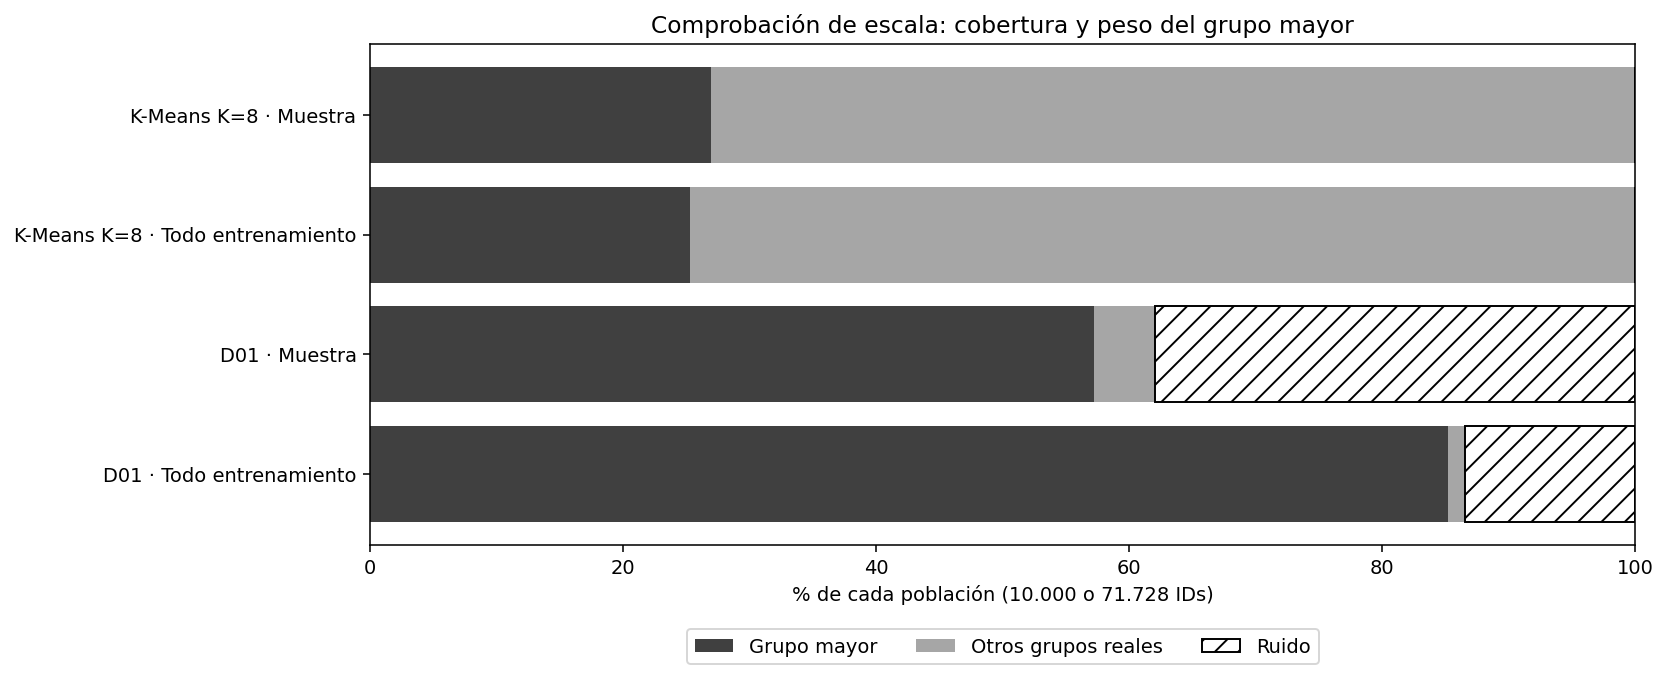

In [88]:
# Los nombres del ajuste completo se basan en sus propias medias, no en números de la muestra.
nombres_k8_completo_u3 = {
    0: "Energético, de tempo menor que el otro perfil energético",
    1: "Acústico e instrumental, poca energía y volumen",
    2: "Más bailable y de mayor valencia",
    3: "Energético y de tempo más rápido",
    4: "Voz hablada muy marcada: revisar contenido",
    5: "Más instrumental, energía media-alta",
    6: "Más indicios de interpretación en vivo",
    7: "Más acústico, menor energía",
}
lectura_k8_completo_u3 = resumen_grupos_completo_u3["K-Means K=8"].copy()
lectura_k8_completo_u3["Perfil relativo"] = pd.Series(nombres_k8_completo_u3)
modelo_k8_entrenamiento_u3 = modelos_agrupamiento_completo_u3["K-Means K=8"]
preparador_k8_entrenamiento_u3 = preparador_audio_completo_u3
filas_calidad_correspondencia_u3 = []
for origen, destino in correspondencia_k8_escala_u3.items():
    fila = cruce_k8_muestra_completo_u3.loc[origen]
    filas_calidad_correspondencia_u3.append({"Grupo muestra": origen, "Pareja global grupo completo": destino,
        "% del origen en esa pareja": fila.loc[destino] / fila.sum() * 100,
        "Destino más frecuente del origen": int(fila.idxmax()),
        "% del origen en destino más frecuente": fila.max() / fila.sum() * 100})
calidad_correspondencia_k8_escala_u3 = pd.DataFrame(filas_calidad_correspondencia_u3)
display(lectura_k8_completo_u3.round(3))
display(calidad_correspondencia_k8_escala_u3.round(2))

import matplotlib.pyplot as plt
fig_pesos_escala_u3, eje_pesos_escala_u3 = plt.subplots(figsize=(12, 5))
comp = comparacion_escalas_cluster_u3.copy()
comp["Etiqueta"] = comp["Modelo"] + " · " + comp["Población"]
mayor = comp["Cobertura (%)"] * comp["Grupo mayor (% asignados)"] / 100
otros = comp["Cobertura (%)"] - mayor
ruido = comp["Ruido (%)"]
eje_pesos_escala_u3.barh(comp["Etiqueta"], mayor, color="0.25", label="Grupo mayor")
eje_pesos_escala_u3.barh(comp["Etiqueta"], otros, left=mayor, color="0.65", label="Otros grupos reales")
eje_pesos_escala_u3.barh(comp["Etiqueta"], ruido, left=mayor + otros, color="white", edgecolor="black", hatch="//", label="Ruido")
eje_pesos_escala_u3.invert_yaxis()
eje_pesos_escala_u3.set(xlim=(0, 100), xlabel="% de cada población (10.000 o 71.728 IDs)", title="Comprobación de escala: cobertura y peso del grupo mayor")
eje_pesos_escala_u3.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
fig_pesos_escala_u3.tight_layout()
display(fig_pesos_escala_u3)
plt.close(fig_pesos_escala_u3)

### 31.2. Lectura de los resultados ejecutados

**Preparación:** se conservaron los 71.728 IDs y nueve variables de entrenamiento, sin IDs de test. Se imputaron 136 tempos, frente a 16 en la muestra. La mediana de tempo pasó de 122,0175 a 122,021 BPM. Ese cambio es pequeño, pero también cambiaron las medias y escalas de las otras variables y la cantidad de datos. No atribuimos todos los cambios de grupos a la mediana ni a una sola causa.

**K-Means K=8:** produce ocho grupos de 824 a 18.117 IDs. El mayor representa 25,26% de entrenamiento, frente a 26,96% en la muestra. Silhouette en el nuevo panel es aproximadamente 0,18505, frente a 0,18755 en el panel de muestra; Davies–Bouldin es 1,38468 frente a 1,37869. Son cifras globales parecidas sobre poblaciones y paneles diferentes, **no evidencia de que las canciones conservaran grupo**.

La inercia completa es 284.971,80, equivalente a 3,97295 por ID. La suma no se compara directamente con la inercia de 10.000 canciones; la escala y población también cambiaron. No se usa ese número para declarar una mejora predictiva.

### 31.3. K=8 mantiene cantidad, pero cambia parte de sus perfiles

El ARI entre ambos ajustes en los 10.000 IDs comunes fue **0,65562**. No es porcentaje de canciones correctas; indica que la partición no se conserva tan bien como sugería mirar únicamente las métricas globales.

El grupo bailable de mayor voz hablada de la muestra (grupo 2) se reparte: 57,33% pasa al grupo completo 2, 20,52% al 3 y el resto a otros destinos. El grupo bailable de menor voz hablada de muestra (grupo 3) pasa en 80,56% al mismo grupo completo 2. Por tanto, **la separación de esos dos perfiles vocales, que motivó preferir ocho en la muestra, no se reproduce de igual forma** en el ajuste completo.

En cambio, el perfil energético de muestra (grupo 5) se distribuye principalmente entre los grupos completos 0 y 3: 48,48% y 50,21% de sus IDs. Estos perfiles completos tienen tempo medio **108,72 y 163,54 BPM** y energía media **0,753 y 0,814**. Ahora los ocho grupos distinguen mejor esos contrastes de tempo, pero ya no representan exactamente los ocho perfiles originales.

Algunos perfiles se conservan con mayor claridad: 98,00% del grupo acústico/instrumental de muestra va al completo 1; 96,70% del instrumental de energía media-alta al 5; 95,10% del de indicios de vivo al 6, y 100% del de voz hablada muy marcada al 4. Son porcentajes de cada origen, no del destino ni de exactitud del modelo.

**Cuidado con el emparejamiento automático:** la correspondencia uno a uno global asocia muestra 2 con completo 3 para maximizar el solapamiento total, aunque solo 20,52% de sus IDs llegue ahí. Su destino más frecuente es el completo 2, que recibe también gran parte del otro perfil bailable. Por eso la diferencia de medias de esa pareja **no se interpreta como evolución del mismo grupo musical**. La tabla de calidad de correspondencia muestra expresamente estas limitaciones.

Los nuevos nombres del código se asignan según los perfiles completos. `modelo_k8_entrenamiento_u3` y `preparador_k8_entrenamiento_u3` identifican los objetos nuevos para uso posterior; los modelos, nombres, ejemplos y playlist de la muestra se conservan como resultados de esa población. No se deben mezclar sus etiquetas al crear sugerencias futuras con el ajuste completo.

En una comparación geométrica adicional de las mismas 10.000 canciones bajo la escala completa, silhouette es 0,18731 para las etiquetas aprendidas en muestra y 0,17363 para las del ajuste completo; Davies–Bouldin es 1,38389 y 1,40696. Es un diagnóstico condicionado a canciones que ambos usaron, no una prueba de que el modelo de muestra generalice mejor ni motivo para volver a optimizar con test.

### 31.4. DBSCAN D01: más densidad no produjo una organización mejor para playlists

D01 conservó **eps≈0,81674 y min_samples=5** y sí se ajustó a los 71.728 registros. Obtiene **95 grupos reales**, 62,053 IDs asignados y 9,675 de ruido. La cobertura aumenta de **62,07% a 86,51%**, pero su grupo mayor reúne **61.114 IDs**, el 85,20% de todo entrenamiento y **98,49% de los asignados**, frente a 92,25% de asignados en la muestra.

Muchos grupos pequeños no equivalen a 95 playlists útiles. La estructura dominante es aún más general. Silhouette del panel completo sin ruido es −0,27308 y Davies–Bouldin 0,96125; no elegimos el ajuste solo porque un índice baje o la cobertura aumente.

En los 10.000 IDs comunes, 2.391 registros antes considerados ruido pasan a asignados y 1.402 continúan como ruido. No hubo paso de asignado a ruido en esos IDs. Entre los 6.207 asignados en ambos, ARI es **0,07216**, por lo que las relaciones de agrupamiento cambian mucho. Puede ocurrir al aumentar la densidad y aparecer conexiones entre zonas; también cambió la escala, así que no se atribuye el cambio únicamente al tamaño.

En esos 6.207 IDs y la misma escala completa, silhouette pasa de −0,23858 con etiquetas de muestra a 0,35332 con las completas, pero **solo quedan cuatro grupos efectivos** en esa cohorte frente a 37 etiquetas de muestra. No contradice la silhouette negativa del panel completo: son poblaciones y particiones evaluadas diferentes. Tampoco demuestra utilidad para playlists si casi todo queda absorbido en un grupo.

### 31.5. Qué NO se ejecutó: D14 y D15 completos

El conteo de vecindarios completos da:

- **D01:** 4.693.436 relaciones, unos 35,81 MiB solo de índices. Pasó el límite operativo y se ajustó.
- **D14:** 179.913.550 relaciones, unos 1.372,63 MiB (1,34 GiB) solo de índices.
- **D15:** 327.588.978 relaciones, unos 2.499,31 MiB (2,44 GiB) solo de índices.

D14 y D15 superan el límite de 512 MiB antes de contar otros objetos y temporales de DBSCAN. **No se ajustaron sobre todo entrenamiento**. No se inventan etiquetas, silhouette, cobertura o grupos para esos dos casos; su conteo de vecinos no permite deducirlos. Se mantienen sus resultados anteriores de muestra, identificados como tales.

Esto es una limitación de la implementación y recursos usados, no una prueba de calidad o imposibilidad matemática. No se cambiaron sus radios, número de registros o algoritmo por otro modelo para presentar un resultado como equivalente. Una implementación de memoria reducida requeriría otro bloque de trabajo y comprobaciones de equivalencia, fuera de esta ejecución.

### 31.6. Conclusión y alcance

La comprobación **sí se completó con K=8 y D01 en todo entrenamiento**, con D14/D15 documentados como no ajustados por recursos. K=8 sigue ofreciendo varios perfiles con peso sustancial; D01 aumenta cobertura a costa de una concentración todavía mayor. Para playlists generales, K=8 continúa como alternativa provisional frente a este DBSCAN completo, sin afirmar que se comprobaron todos los candidatos completos.

Sin embargo, **no quedó confirmado que K=8 reproduzca los ocho perfiles de la muestra**. El ARI 0,65562 y la mezcla de los perfiles bailables obligan a reformular su explicación: el ajuste completo distingue principalmente dos perfiles energéticos por tempo, junto a los otros contrastes descritos. El cierre del agrupamiento deberá describir ese alcance y revisar la utilidad de los nuevos perfiles y ejemplos; no se reutilizará sin cambios el argumento de separar voz hablada moderada que sustentó la muestra.

No se reabrió una búsqueda de K o radios ni se garantizó estabilidad futura. Esta es una comprobación interna de escala y sensibilidad, no validación con canciones nuevas, usuarios o un test ciego. Popularidad y artista no entraron en los ajustes. Los CSV, la clasificación y los resultados previos permanecen sin cambios.

**Pendiente:** revisar representantes del ajuste completo y cerrar criterios/conclusiones de agrupamiento con estos resultados y limitaciones. No hace falta presentar una falsa confirmación para cerrar: también es válido documentar qué cambió y qué no se pudo ejecutar.

Referencia de implementación del conteo sin listas de vecinos: [BallTree, documentación de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.BallTree.html).


<a id="cierre"></a>
## 32. Cierre de criterios y conclusiones de agrupamiento

### 32.1. Representantes del ajuste completo

Antes del cierre revisamos dos ejemplos por grupo del **K=8 aprendido con los 71.728 IDs**, con su propia preparación. No se reutilizan etiquetas de la muestra ni se copian sus nombres por número. Se seleccionan registros cercanos al centro completo, sin repetir claves o vectores exactos de las nueve características imputadas. Esto describe centros, no calidad musical, popularidad o satisfacción de oyentes.

In [89]:
import numpy as np
import pandas as pd

modelo_cierre_k8_u3 = modelos_agrupamiento_completo_u3["K-Means K=8"]
etiquetas_cierre_k8_u3 = etiquetas_agrupamiento_completo_u3["K-Means K=8"]
distancias_cierre_k8_u3 = pd.Series(
    np.linalg.norm(X_audio_completo_escalado_u3.to_numpy() - modelo_cierre_k8_u3.cluster_centers_[etiquetas_cierre_k8_u3.to_numpy(dtype=int)], axis=1),
    index=X_audio_completo_escalado_u3.index,
)
ids_representantes_completo_u3 = []
claves_ya_completo_u3, audios_ya_completo_u3 = set(), set()
for grupo in range(8):
    candidatas = pd.DataFrame({"Distancia al centro completo": distancias_cierre_k8_u3,
        "Grupo": etiquetas_cierre_k8_u3, "Clave": g_audio_completo_u3})
    candidatas["ID Spotify"] = candidatas.index.astype(str)
    candidatas = candidatas.loc[candidatas["Grupo"].eq(grupo)].sort_values(["Distancia al centro completo", "ID Spotify"], kind="stable")
    elegidas = 0
    for id_cancion, fila in candidatas.iterrows():
        audio = tuple(X_audio_completo_imputado_u3.loc[id_cancion].to_numpy())
        if fila["Clave"] in claves_ya_completo_u3 or audio in audios_ya_completo_u3:
            continue
        ids_representantes_completo_u3.append(id_cancion)
        claves_ya_completo_u3.add(fila["Clave"])
        audios_ya_completo_u3.add(audio)
        elegidas += 1
        if elegidas == 2:
            break
    if elegidas != 2:
        raise ValueError("Faltan ejemplos distintos en un grupo completo.")
representantes_k8_completo_u3 = pd.DataFrame({
    "Grupo": etiquetas_cierre_k8_u3.loc[ids_representantes_completo_u3],
    "Clave": g_audio_completo_u3.loc[ids_representantes_completo_u3],
    "Distancia al centro completo": distancias_cierre_k8_u3.loc[ids_representantes_completo_u3],
})
partes_cierre_u3 = representantes_k8_completo_u3["Clave"].str.partition(" || ")
if not partes_cierre_u3[1].eq(" || ").all():
    raise ValueError("No se pueden recuperar los nombres normalizados.")
representantes_k8_completo_u3["Artista normalizado"] = partes_cierre_u3[0]
representantes_k8_completo_u3["Título normalizado"] = partes_cierre_u3[2]
representantes_k8_completo_u3["Perfil completo"] = representantes_k8_completo_u3["Grupo"].map(nombres_k8_completo_u3)
representantes_k8_completo_u3["Tempo imputado"] = X_audio_completo_u3.loc[ids_representantes_completo_u3, "tempo"].isna()
representantes_k8_completo_u3["Enlace Spotify"] = "https://open.spotify.com/track/" + representantes_k8_completo_u3.index.astype(str)
if len(representantes_k8_completo_u3) != 16 or not representantes_k8_completo_u3["Clave"].is_unique:
    raise ValueError("La selección final no conserva 16 claves distintas.")
display(representantes_k8_completo_u3[["Grupo", "Perfil completo", "Artista normalizado", "Título normalizado", "Distancia al centro completo", "Tempo imputado", "Enlace Spotify"]].round(5))
display(X_audio_completo_imputado_u3.loc[ids_representantes_completo_u3].round(4))

,Grupo,Perfil completo,Artista normalizado,Título normalizado,Distancia al centro completo,Tempo imputado,Enlace Spotify
track_id,,,,,,,
0d1Eoa1zAXUKdAGOmglJYD,0,"Energético, de tempo menor que el otro perfil energético",hogland;charlie south,holy,0.37927,False,https://open.spotify.com/track/0d1Eoa1zAXUKdAGOmglJYD
02q48eRgkja20qgxTKdXk4,0,"Energético, de tempo menor que el otro perfil energético",kim petras,close your eyes,0.41403,False,https://open.spotify.com/track/02q48eRgkja20qgxTKdXk4
14DLzsFYQOK3195eshJ3Aw,1,"Acústico e instrumental, poca energía y volumen",philharmonia orchestra;charles dutoit,"danse macabre, op. 40",0.55023,False,https://open.spotify.com/track/14DLzsFYQOK3195eshJ3Aw
5JaEvKVQbXVxqq2S6a1CVj,1,"Acústico e instrumental, poca energía y volumen",fazıl say;jamal aliyev,"hayat ağacı süiti, op. 100: iii. ece",0.68528,False,https://open.spotify.com/track/5JaEvKVQbXVxqq2S6a1CVj
4CrvuZnTyzReLCcXRMETLK,2,Más bailable y de mayor valencia,manuel carrasco,yo quiero vivir,0.41236,False,https://open.spotify.com/track/4CrvuZnTyzReLCcXRMETLK
3yuNP4BLrPpwsJHLYIJ1lj,2,Más bailable y de mayor valencia,mc kevin;mc bruninho da praia;mc dena;mc magal;logri;aires 085;kawe;mc ig;mariah denaro;mc don juan;dj oreia,set do adão,0.42395,False,https://open.spotify.com/track/3yuNP4BLrPpwsJHLYIJ1lj
1V6gIisPpYqgFeWbMLI0bA,3,Energético y de tempo más rápido,demi lovato,heart attack,0.50036,False,https://open.spotify.com/track/1V6gIisPpYqgFeWbMLI0bA
4xG1egDLS0WxscEhf7eSL1,3,Energético y de tempo más rápido,masn,crush,0.54113,False,https://open.spotify.com/track/4xG1egDLS0WxscEhf7eSL1
36RDt4tcwMGggg0GqIs7YZ,4,Voz hablada muy marcada: revisar contenido,chad daniels,"rock, paper, scissors, jesus",0.76319,False,https://open.spotify.com/track/36RDt4tcwMGggg0GqIs7YZ


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
track_id,,,,,,,,,
0d1Eoa1zAXUKdAGOmglJYD,0.528,0.807,-5.199,0.0548,0.0606,0.0000,0.177,0.3770,107.028
02q48eRgkja20qgxTKdXk4,0.548,0.728,-5.678,0.0507,0.0104,0.0001,0.146,0.3370,105.961
14DLzsFYQOK3195eshJ3Aw,0.334,0.187,-20.906,0.0415,0.8840,0.7970,0.105,0.0836,112.135
5JaEvKVQbXVxqq2S6a1CVj,0.291,0.109,-20.775,0.0430,0.9860,0.8840,0.120,0.2290,108.154
4CrvuZnTyzReLCcXRMETLK,0.690,0.733,-6.194,0.1050,0.1430,0.0000,0.147,0.7040,117.969
3yuNP4BLrPpwsJHLYIJ1lj,0.744,0.679,-6.387,0.0822,0.3090,0.0000,0.114,0.7650,113.948
1V6gIisPpYqgFeWbMLI0bA,0.504,0.785,-4.802,0.1040,0.0738,0.0000,0.239,0.5020,173.968
4xG1egDLS0WxscEhf7eSL1,0.497,0.836,-6.410,0.0962,0.0518,0.0000,0.192,0.5420,173.940
36RDt4tcwMGggg0GqIs7YZ,0.590,0.771,-9.295,0.9140,0.7840,0.0000,0.660,0.4330,100.952


El código recupera modelo y etiquetas completos y calcula distancia euclídea a su centro sobre la escala completa. Cada grupo se ordena por distancia e ID como desempate. Los conjuntos omiten versiones o audio exacto ya seleccionados; se exige conseguir dos ejemplos por grupo. La clave se usa para identificar, no para medir cercanía. La segunda tabla contiene las características de los mismos IDs en el mismo orden.

La selección es central con restricciones, no necesariamente las dos distancias mínimas absolutas; visitar grupos en orden puede omitir una clave ya usada en otro. No se escuchó el audio. Los ejemplos y nombres completos sustituyen a los de la muestra solo cuando se utilice este ajuste: los resultados anteriores siguen siendo válidos como evidencia de la muestra y no se mezclan sus etiquetas.

In [90]:
criterios_cierre_agrupamiento_u3 = pd.DataFrame([
    ["Población y versiones", "Solo entrenamiento; claves completas al muestrear", "71.728 IDs, 64.965 claves; sin IDs de test", "Control comprobado"],
    ["Preparación", "Sin faltantes/infinitos, escala aprendida solo en entrenamiento", "136 tempos imputados; nueve columnas verificadas", "Control comprobado"],
    ["Variedad de perfiles", "Varios perfiles interpretables para explorar playlists", "K=8 completo: 824–18.117 IDs por grupo; perfiles y ejemplos propios", "Evidencia descriptiva favorable; sin validación por oyentes"],
    ["Separación", "Silhouette y Davies–Bouldin; sin meta universal", "K=8 completo: silhouette 0,18505; DB 1,38468", "Separación limitada; no se declara aprobación por un umbral inventado"],
    ["Estabilidad", "Examinar semillas, submuestras y cambio de escala", "ARI inicializaciones 0,99343 en muestra; submuestras 0,85479; muestra→completo 0,65562", "Limitación: perfiles no invariantes al cambiar datos"],
    ["Cobertura y ruido", "Informar ambos y el dominio del grupo mayor", "K=8: 100% por diseño, mayor 25,26%; D01 completo: cobertura 86,51%, mayor 98,49% asignados", "Se elige K=8 para organización general; DBSCAN no seleccionado"],
    ["DBSCAN a escala", "No inventar resultados no calculados", "D01 completo ejecutado; D14/D15 omitidos por límite de memoria", "Evaluación parcial explícita de los casos completos"],
    ["Utilidad de playlists", "Escucha y preferencias de oyentes", "No hay prueba con usuarios; selección por audio y ejemplos", "No demostrada; fuera del alcance de esta evaluación"],
], columns=["Criterio", "Regla o propósito", "Evidencia final", "Conclusión"])
display(criterios_cierre_agrupamiento_u3)
comparacion_cierre_supervisado_u3 = comparacion_cierre_clasificacion_u3[[
    "Modelo", "Precisión", "Recall", "F1", "Average Precision", "ROC-AUC", "FP", "FN", "KPI simultáneos"
]].copy()
display(comparacion_cierre_supervisado_u3.round(6))

,Criterio,Regla o propósito,Evidencia final,Conclusión
0,Población y versiones,Solo entrenamiento; claves completas al muestrear,"71.728 IDs, 64.965 claves; sin IDs de test",Control comprobado
1,Preparación,"Sin faltantes/infinitos, escala aprendida solo en entrenamiento",136 tempos imputados; nueve columnas verificadas,Control comprobado
2,Variedad de perfiles,Varios perfiles interpretables para explorar playlists,K=8 completo: 824–18.117 IDs por grupo; perfiles y ejemplos propios,Evidencia descriptiva favorable; sin validación por oyentes
3,Separación,Silhouette y Davies–Bouldin; sin meta universal,"K=8 completo: silhouette 0,18505; DB 1,38468",Separación limitada; no se declara aprobación por un umbral inventado
4,Estabilidad,"Examinar semillas, submuestras y cambio de escala","ARI inicializaciones 0,99343 en muestra; submuestras 0,85479; muestra→completo 0,65562",Limitación: perfiles no invariantes al cambiar datos
5,Cobertura y ruido,Informar ambos y el dominio del grupo mayor,"K=8: 100% por diseño, mayor 25,26%; D01 completo: cobertura 86,51%, mayor 98,49% asignados",Se elige K=8 para organización general; DBSCAN no seleccionado
6,DBSCAN a escala,No inventar resultados no calculados,D01 completo ejecutado; D14/D15 omitidos por límite de memoria,Evaluación parcial explícita de los casos completos
7,Utilidad de playlists,Escucha y preferencias de oyentes,No hay prueba con usuarios; selección por audio y ejemplos,No demostrada; fuera del alcance de esta evaluación


,Modelo,Precisión,Recall,F1,Average Precision,ROC-AUC,FP,FN,KPI simultáneos
0,Random Forest,0.503838,0.651317,0.568163,0.590255,0.906953,5042,2741,Cumple
1,LightGBM,0.496429,0.663147,0.567803,0.601028,0.910703,5288,2648,Cumple
2,XGBoost,0.487494,0.681847,0.568519,0.605341,0.910567,5635,2501,Cumple


### 32.2. Cómo se cierra sin inventar KPI

La tabla separa controles obligatorios de datos de criterios comparativos y de utilidad no demostrada. Los controles se sostienen en comprobaciones ejecutadas antes; las métricas se identifican con población y procedimiento. No existe una meta universal de silhouette o Davies–Bouldin que permita afirmar «playlist aprobada». Tampoco asignar todo a algún grupo valida su calidad.

**Conclusión de agrupamiento:** K-Means de ocho grupos es el procedimiento elegido para organizar descriptivamente el entrenamiento y explorar candidatos a playlists. La elección se apoya en variedad de perfiles y pesos sustanciales, no en superar todos los índices. DBSCAN puede describir densidad, ruido y nichos, pero los parámetros probados producen una agrupación muy dominante o demasiado ruido para nuestra organización general.

La ampliación a todo entrenamiento no confirmó exactamente los perfiles de la muestra. El contraste de voz hablada moderada se mezcla y aparecen dos perfiles energéticos con tempo diferente. Los nuevos nombres y representantes se documentan según el ajuste completo. **La decisión se cierra como elección exploratoria con limitaciones, no como una garantía de estabilidad o de satisfacción de usuarios.** No es necesario ocultar ese cambio ni prometer nuevos experimentos para presentar un cierre honesto.

D01 sí se ejecutó completo. D14/D15 no se ejecutaron a esa escala por recursos y no reciben métricas completas inventadas. Este límite pertenece al informe y a la defensa. No equivale a probar que todas las variantes posibles de DBSCAN serían inadecuadas.

## 33. Conclusiones generales de la Unidad 3

### 33.1. Respuesta al objetivo de clasificación

Se compararon XGBoost, Random Forest y LightGBM como **clasificadores supervisados** para identificar popularidad ≥60. GridSearchCV y RandomizedSearchCV se evaluaron mediante tres rondas externas agrupadas y cinco pliegues internos. El artista se codificó dentro de cada ajuste, con exclusión cruzada de las propias versiones para los registros usados al aprender. Popularidad y los identificadores no fueron predictores.

Con cortes elegidos internamente, los tres ensambles cumplen precisión ≥30% y recall ≥60%, globalmente y en cada ronda externa. La elección de desarrollo es XGBoost con artista: precisión 48,75%, recall 68,18%, F1 0,56852, AP 0,60534 y ROC-AUC 0,91057. Random Forest tiene mayor precisión y menos falsas alarmas; no se presenta XGBoost como ganador universal por diferencias mínimas de F1.

La interpretación concreta de XGBoost es 5.360 populares detectadas, 2.501 omitidas y 5.635 negativas señaladas por error. Elegirlo frente a Random Forest recupera 240 populares adicionales con 593 falsas alarmas adicionales. Los costos económicos o de experiencia de usuario no fueron medidos.

Artista y géneros son los bloques de mayor dependencia según permutación, no causas demostradas de popularidad. El recall de XGBoost cae de 71,70% con algún artista conocido a 35,84% cuando ninguno aparece en el desarrollo correspondiente. El cumplimiento global no oculta esa limitación.

La elección fija de XGBoost se realizó después de revisar resultados externos: es una decisión de desarrollo y no otra confirmación independiente. La regla interna conjunta eligió XGBoost en dos rondas y LightGBM en otra; es un procedimiento distinto. No se entrega como clasificador final desplegado ni se inventa un único umbral a partir de los cortes 0,30/0,30/0,25. No se ha entrenado aquí un clasificador final con todo entrenamiento y un corte global de producción.

### 33.2. Respuesta al objetivo no supervisado

K-Means y DBSCAN se estudiaron solo con nueve características de audio, sin clase, popularidad, artista o géneros como entradas. La búsqueda utilizó una muestra agrupada de 10.000 IDs; K=3–10 se examinó con tres semillas y DBSCAN con quince pares de parámetros. Se analizaron tamaños, separación, perfiles, ejemplos y estabilidad.

K=8 se seleccionó para explorar varias playlists generales, con las limitaciones del cierre anterior. El ajuste completo conserva ocho grupos, pero no todos los perfiles originales. La comprobación de escala y los modelos completos se distinguen de los ejemplos y playlist construidos en la muestra. La propuesta sigue siendo exploratoria, no recomendación personalizada validada.

### 33.3. Qué aporta la comparación de validaciones

Cinco pliegues agrupados mantienen versiones juntas y permiten búsquedas de costo manejable. Leave-P-Out agrupado se implementó de manera acotada, con diez claves y P=2: 45 ajustes frente a cinco, sobre los mismos 15 IDs. Cada ID se evaluó nueve veces en Leave-P-Out; no son nueve canciones nuevas ni pruebas independientes.

La demostración fue pequeña e intencional, con prevalencia distinta y rondas de una sola clase; no se usó para elegir el mejor rendimiento del catálogo. Se conserva el protocolo principal por diseño y viabilidad, no por escoger la puntuación más favorable. Leave-P-Out exhaustivo con dos claves de las 64.965 requeriría 2.110.193.130 ajustes por configuración.

### 33.4. Alcance, ética y generalización

Mantener juntas las versiones reduce una fuga concreta; no demuestra separación entre artistas, independencia temporal ni detección perfecta de todas las grabaciones relacionadas. Las versiones con distintos IDs pueden aumentar el peso de una canción. La clave normalizada es una aproximación. El catálogo puede reflejar sesgos de exposición y cobertura; popularidad no es calidad musical.

No se utilizó test para decisiones de esta unidad. Además, ese test ya fue observado en la unidad 2: no se podría describir una consulta posterior como prueba completamente nueva. Las métricas presentadas son de validación agrupada de entrenamiento o de agrupamiento exploratorio, identificadas según corresponda. No se prometen resultados futuros, probabilidades calibradas o satisfacción de oyentes.

### 33.5. Cierre y continuidad fuera de esta entrega

La unidad deja comparaciones justificadas, KPI supervisados calculados, criterios de agrupamiento documentados y limitaciones explícitas. Se entregan cuaderno, informe técnico, guía explicativa y presentación. Los modelos no supervisados completos ejecutados pueden reutilizarse con su propio preparador y sus nombres de perfil; no se mezclan con las etiquetas de la muestra.

Para una aplicación posterior haría falta validar con datos verdaderamente nuevos o temporales, revisar artistas desconocidos, probar recomendaciones con oyentes y medir costos de errores. Un clasificador de producción requeriría ajustar su procedimiento completo y un corte global sin usar un test ya examinado. Son pasos posteriores de aplicación, no resultados que se hayan ejecutado o metas declaradas cumplidas en esta entrega.